# PopQA-TP Research Notebook: Phase 1 + Phase 2 + Phase 3
**Project:** Paraphrase Robustness of Confidence and Abstention in Open-Weight Large Language Models for Factual Question Answering

This notebook combines the three completed coding phases and runs top to bottom:

- **Part A (Phase 1):** load and validate the research-ready dataset (3,000 questions, 1 original + 5 paraphrases + 1 gold answer each).
- **Part B (Phase 2):** load `Qwen/Qwen2.5-7B-Instruct` (4-bit) and test it on **ONE** question, returning a parsed JSON answer + confidence (0-100).
- **Part C (Phase 3):** run the same model on **all 3,000 x 6 = 18,000** question formulations in batches, with checkpoint/resume, and save the raw results to a CSV.

**Not done here:** any research metric (accuracy, consistency, calibration, ECE, Brier, abstention, coverage, risk, statistical tests), other models, plots, dataset resampling or modification, fine-tuning/LoRA/RAG, or any external API.

**Before running:** Runtime -> Change runtime type -> **T4 GPU** (needed for Parts B and C).

## 0. Install packages
Only what is needed. `torch` and `pandas` are already preinstalled in Colab.

In [ ]:
!pip install -q -U transformers accelerate bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 66.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 15.2 MB/s eta 0:00:00


## 0.1 Configuration, imports and seed
All settings for both phases live in this one cell.

**Google Drive (recommended):** with `USE_GOOGLE_DRIVE = True` the notebook mounts your Drive, reads the dataset from `MyDrive/Research3/data/` and saves results to `MyDrive/Research3/results/`. Google shows a permission pop-up because mounting Drive is the only way Colab can read or write Drive files. Upload the dataset CSV to that Drive folder **once** and you never need to upload it again. Set `USE_GOOGLE_DRIVE = False` to work only in the temporary Colab folder.

In [ ]:
import json
import os

import pandas as pd
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, set_seed

# ---------------- CONFIGURATION ----------------
USE_GOOGLE_DRIVE = True  # mount Drive once: dataset is read from Drive, results are saved to Drive
DRIVE_ROOT = "/content/drive/MyDrive/Research3"  # project folder in your Google Drive
DATA_FILE = "Research3_PopQA_TP_3000_research_ready.csv"

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")  # Google asks for permission here, this is how Colab reads/writes Drive files
    DATA_PATH = f"{DRIVE_ROOT}/data/{DATA_FILE}"  # <-- put the CSV here once, no more uploading
else:
    DATA_PATH = DATA_FILE  # current Colab folder (upload the CSV each new session)
SEED = 42  # reproducibility constant (no sampling is performed anywhere)

# Phase 1: expected dataset structure
EXPECTED_ROWS = 3000
ID_COL = "question_id"
ORIGINAL_COL = "original_question"
PARAPHRASE_COLS = [f"paraphrase_{i}" for i in range(1, 6)]
GOLD_COL = "gold_answer"
TEXT_COLS = [ORIGINAL_COL] + PARAPHRASE_COLS + [GOLD_COL]
EXPECTED_COLS = {ID_COL, *TEXT_COLS}

# Phase 2: model settings
MODEL_NAME = "Qwen/Qwen2.5-7B-Instruct"
MAX_NEW_TOKENS = 100  # the JSON answer is short; 100 tokens is plenty

# Seeds python, numpy and torch. Generation is greedy (do_sample=False) anyway.
set_seed(SEED)


def section(title: str) -> None:
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}")

Mounted at /content/drive


## 0.2 Check that the dataset file exists
With Drive, this cell only confirms the CSV is in `MyDrive/Research3/data/`. If it is missing it tells you where to put it. Without Drive, it opens the upload dialog.

In [ ]:
if os.path.exists(DATA_PATH):
    print(f"Found file: {DATA_PATH}")
elif USE_GOOGLE_DRIVE:
    raise FileNotFoundError(
        f"{DATA_PATH} not found. Upload the CSV once to this Google Drive folder "
        f"(create the folders if needed): {DRIVE_ROOT}/data/  - then run this cell again."
    )
else:
    from google.colab import files
    uploaded = files.upload()  # select the CSV; it is saved in the current Colab folder
    print("Uploaded:", list(uploaded.keys()))

Found file: /content/drive/MyDrive/Research3/data/Research3_PopQA_TP_3000_research_ready.csv


# Part A: Phase 1 - Data loading and validation
Read-only checks. The dataset is **not** modified, resampled or normalized.

## A1. Load the CSV and check the structure
- `dtype=str`: no type conversion, IDs and text stay exactly as written.
- `keep_default_na=False`: literal text such as "NA", "None" or "null" is not turned into a missing value.
- `na_values=[""]`: only truly empty cells count as missing.

In [ ]:
df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False, na_values=[""])

section("1. BASIC STRUCTURE")
print(f"File:                {DATA_PATH}")
print(f"Random seed:         {SEED} (no sampling performed)")
print(f"Rows:                {len(df)}")
print(f"Unique question IDs: {df[ID_COL].nunique() if ID_COL in df.columns else 'N/A'}")
print(f"Column names:        {list(df.columns)}")

assert set(df.columns) == EXPECTED_COLS, (
    f"Column mismatch. Missing: {EXPECTED_COLS - set(df.columns)}, "
    f"Unexpected: {set(df.columns) - EXPECTED_COLS}"
)
assert len(df.columns) == len(EXPECTED_COLS), "Duplicate column names detected."
assert len(df) == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS} rows, found {len(df)}."


1. BASIC STRUCTURE
File:                /content/drive/MyDrive/Research3/data/Research3_PopQA_TP_3000_research_ready.csv
Random seed:         42 (no sampling performed)
Rows:                3000
Unique question IDs: 3000
Column names:        ['question_id', 'original_question', 'gold_answer', 'paraphrase_1', 'paraphrase_2', 'paraphrase_3', 'paraphrase_4', 'paraphrase_5']


## A2. Missing values
Any missing value makes the assertion fail.

In [ ]:
section("2. MISSING VALUES PER COLUMN")
missing = df.isna().sum()
print(missing.to_string())
assert missing.sum() == 0, "Dataset contains missing values."


2. MISSING VALUES PER COLUMN
question_id          0
original_question    0
gold_answer          0
paraphrase_1         0
paraphrase_2         0
paraphrase_3         0
paraphrase_4         0
paraphrase_5         0


## A3. Empty and whitespace-only values
Leading/trailing whitespace is only reported, **never trimmed**.

In [ ]:
section("3. EMPTY OR WHITESPACE-ONLY VALUES PER COLUMN")
blank = {c: int((df[c].str.strip() == "").sum()) for c in df.columns}
print(pd.Series(blank).to_string())
assert sum(blank.values()) == 0, "Dataset contains empty or whitespace-only values."

padded = {c: int((df[c] != df[c].str.strip()).sum()) for c in df.columns}
print(f"\nValues with leading/trailing whitespace (info only, left unchanged): {sum(padded.values())}")


3. EMPTY OR WHITESPACE-ONLY VALUES PER COLUMN
question_id          0
original_question    0
gold_answer          0
paraphrase_1         0
paraphrase_2         0
paraphrase_3         0
paraphrase_4         0
paraphrase_5         0

Values with leading/trailing whitespace (info only, left unchanged): 0


## A4. Duplicates
Checks that `question_id` is unique and that no complete row is duplicated.

In [ ]:
section("4. DUPLICATES")
dup_id_rows = int(df[ID_COL].duplicated(keep=False).sum())
dup_full_rows = int(df.duplicated(keep=False).sum())
print(f"Rows sharing a question_id:  {dup_id_rows}")
print(f"Duplicate complete rows:     {dup_full_rows}")
assert df[ID_COL].is_unique, "question_id values are not unique."
assert dup_full_rows == 0, "Duplicate complete rows found."
assert df[ID_COL].nunique() == EXPECTED_ROWS, "Unique question_id count is wrong."


4. DUPLICATES
Rows sharing a question_id:  0
Duplicate complete rows:     0


## A5. Per-question completeness
Every row must have **1 original + 5 paraphrases + 1 gold answer**. `gold_answer` is parsed as a JSON list only to validate it; the stored text is not replaced.

In [ ]:
section("5. PER-QUESTION COMPLETENESS")
assert len(PARAPHRASE_COLS) == 5
per_row_questions = df[[ORIGINAL_COL] + PARAPHRASE_COLS].notna().sum(axis=1)
per_row_gold = df[GOLD_COL].notna().sum(axis=0)
assert (per_row_questions == 6).all(), "Some rows lack 1 original + 5 paraphrases."
assert per_row_gold == len(df), "Some rows lack a gold answer."
print("Every row has 1 original question + 5 paraphrases + 1 gold answer: OK")


def _parse_gold(s: str):
    try:
        v = json.loads(s)
    except json.JSONDecodeError:
        return None
    return v if isinstance(v, list) else None


parsed = df[GOLD_COL].map(_parse_gold)
bad_gold = int(parsed.isna().sum())
n_aliases = parsed.dropna().map(len)
print(f"gold_answer parses as a list in all rows: {bad_gold == 0}")
assert bad_gold == 0, f"{bad_gold} gold_answer values are not valid JSON lists."
assert (n_aliases >= 1).all(), "Some gold_answer lists are empty."
assert parsed.map(lambda l: all(isinstance(a, str) and a.strip() for a in l)).all(), \
    "Some gold_answer lists contain empty/non-string entries."


def _row_has_repeat(row) -> bool:
    texts = [row[c] for c in [ORIGINAL_COL] + PARAPHRASE_COLS]
    return len(set(texts)) < len(texts)


rows_with_repeats = int(df.apply(_row_has_repeat, axis=1).sum())
print(f"Rows where original/paraphrases repeat exactly (info only): {rows_with_repeats}")


5. PER-QUESTION COMPLETENESS
Every row has 1 original question + 5 paraphrases + 1 gold answer: OK
gold_answer parses as a list in all rows: True
Rows where original/paraphrases repeat exactly (info only): 179


## A6. Dataset summary

In [ ]:
section("6. DATASET SUMMARY")
total_prompts = len(df) * 6
print(f"Questions:                       {len(df)}")
print(f"Prompt variants per question:    6 (1 original + 5 paraphrases)")
print(f"Total question prompts:          {total_prompts}")
print(f"Gold answers per question:       min={n_aliases.min()}, max={n_aliases.max()}, mean={n_aliases.mean():.2f}")
lengths = df[[ORIGINAL_COL] + PARAPHRASE_COLS].apply(lambda s: s.str.split().str.len())
print("Question length in words (all 6 variants pooled): "
      f"min={lengths.min().min()}, max={lengths.max().max()}, mean={lengths.stack().mean():.1f}")

section("PHASE 1: ALL VALIDATION CHECKS PASSED")


6. DATASET SUMMARY
Questions:                       3000
Prompt variants per question:    6 (1 original + 5 paraphrases)
Total question prompts:          18000
Gold answers per question:       min=1, max=39, mean=3.64
Question length in words (all 6 variants pooled): min=3, max=16, mean=6.5

PHASE 1: ALL VALIDATION CHECKS PASSED


# Part B: Phase 2 - Model loading and single-question inference
Technical validation only: one model, one question, one JSON answer.

## B1. Check the GPU
4-bit loading with `bitsandbytes` needs a CUDA GPU, so we stop with a clear message if none is found. (Part A above does not need a GPU.)

In [ ]:
if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU detected. In Colab: Runtime -> Change runtime type -> T4 GPU, "
        "then restart the runtime and run all cells again."
    )

props = torch.cuda.get_device_properties(0)
print(f"GPU: {props.name} | VRAM: {props.total_memory / 1024**3:.1f} GB")

GPU: Tesla T4 | VRAM: 14.6 GB


## B2. Select the first valid question (no sampling, no modification)
Uses the `df` already loaded and validated in Part A. The first row with a non-empty `original_question` is used as-is. The gold answer is **not** used in this phase.

In [ ]:
valid = df[df[ORIGINAL_COL].notna() & (df[ORIGINAL_COL].str.strip() != "")]
assert len(valid) > 0, "No valid question found in the dataset."

first_row = valid.iloc[0]
QUESTION_ID = first_row[ID_COL]
QUESTION = first_row[ORIGINAL_COL]  # preserved exactly, not modified

print(f"Selected question_id={QUESTION_ID}: {QUESTION}")

Selected question_id=5921335: Who is the author of The Demon?


## B3. Load the model (4-bit NF4) and tokenizer
Why 4-bit: Qwen2.5-7B in fp16 needs about 15 GB for weights alone, which does not fit a free Colab T4 (about 15 GB VRAM) once activations are included. 4-bit NF4 quantization brings the weights to roughly 5-6 GB. Compute is done in float16 because the T4 has no native bfloat16 support.

The first run downloads about 15 GB of weights, so it can take several minutes.

In [ ]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    dtype=torch.float16,   # non-quantized layers in fp16 (saves VRAM)
    device_map="auto",     # puts the model on the GPU
)
model.eval()

print("Model loaded successfully.")
print(f"Device: {model.device}")
print(f"GPU memory used: {torch.cuda.memory_allocated() / 1024**3:.1f} GB")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Model loaded successfully.
Device: cuda:0
GPU memory used: 5.2 GB


## B4. Prompt, parser and single-inference function
- `build_prompt`: asks for a direct answer + confidence 0-100 as JSON only (no abstention option yet).
- `parse_model_output`: finds the first `{` and decodes one JSON object, so a markdown fence or trailing text does not break it. It then **validates** `answer` and `confidence`. It never invents or guesses values: if anything is wrong it raises a `ValueError`.
- `run_single_inference`: prompt -> chat template -> tokenize -> greedy generation -> decode only the new tokens -> parse. On a parsing failure it prints the raw output and the error, then re-raises (nothing is hidden).

In [ ]:
def build_prompt(question: str) -> str:
    return (
        "You are answering a factual question.\n\n"
        f"Question:\n{question}\n\n"
        "Return ONLY valid JSON in exactly this format:\n\n"
        "{\n"
        '  "answer": "your answer",\n'
        '  "confidence": <a number from 0 to 100>\n'
        "}\n\n"
        "The confidence score should represent how confident you are that your answer "
        "is factually correct (0 = certainly wrong, 100 = certainly correct).\n"
        "Give a short, direct answer. Do not include explanations or any text outside the JSON."
    )


def parse_model_output(raw_output: str):
    """Parse and validate the model output. Returns (answer, confidence) or raises ValueError."""
    start = raw_output.find("{")
    if start == -1:
        raise ValueError("No JSON object found in the model output.")
    try:
        # raw_decode reads ONE JSON object starting at the first '{' and ignores trailing text
        obj, _ = json.JSONDecoder().raw_decode(raw_output[start:])
    except json.JSONDecodeError as err:
        raise ValueError(f"Invalid JSON: {err}") from err

    if not isinstance(obj, dict):
        raise ValueError("Parsed JSON is not an object.")
    for key in ("answer", "confidence"):
        if key not in obj:
            raise ValueError(f"Missing key: '{key}'.")

    answer = obj["answer"]
    if not isinstance(answer, str) or not answer.strip():
        raise ValueError(f"'answer' must be a non-empty string, got: {answer!r}")

    conf = obj["confidence"]
    if isinstance(conf, bool) or not isinstance(conf, (int, float, str)):
        raise ValueError(f"'confidence' must be numeric, got: {conf!r}")
    try:
        conf = float(conf)  # accepts 85, 85.5 and the string "85"; rejects e.g. "85%" or "high"
    except ValueError as err:
        raise ValueError(f"'confidence' is not numeric: {obj['confidence']!r}") from err
    if not (0.0 <= conf <= 100.0):  # also rejects NaN
        raise ValueError(f"'confidence' must be between 0 and 100, got: {conf}")

    return answer.strip(), conf


def run_single_inference(question: str) -> dict:
    # 1. construct the prompt and apply the model's chat template
    messages = [{"role": "user", "content": build_prompt(question)}]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    # 2. tokenize and move to the model's device
    inputs = tokenizer(text, return_tensors="pt").to(model.device)

    # 3. deterministic (greedy) generation
    with torch.no_grad():
        output_ids = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)

    # 4. decode ONLY the newly generated tokens (not the prompt)
    new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
    raw_output = tokenizer.decode(new_tokens, skip_special_tokens=True)

    # 5. parse + validate; never hide a failure
    try:
        answer, confidence = parse_model_output(raw_output)
    except ValueError as err:
        print("JSON PARSING FAILED")
        print("Raw model output:\n", raw_output)
        print("Parsing error:", err)
        raise

    return {
        "question": question,
        "answer": answer,
        "confidence": confidence,
        "raw_output": raw_output,
    }

## B5. Run the single-inference test

In [ ]:
result = run_single_inference(QUESTION)

print("Inference completed successfully.")
print("JSON parsing successful.")
assert 0.0 <= result["confidence"] <= 100.0
print("Confidence range valid.\n")

print(f"Model name:   {MODEL_NAME}")
print(f"Device:       {model.device}")
print(f"Question ID:  {QUESTION_ID}")
print(f"Question:     {result['question']}")
print(f"Answer:       {result['answer']}")
print(f"Confidence:   {result['confidence']}")
print(f"Raw output:   {result['raw_output']}")
print(f"Parsed dict:  {result}")

print("\nPhase 2 single-inference test passed.")

Inference completed successfully.
JSON parsing successful.
Confidence range valid.

Model name:   Qwen/Qwen2.5-7B-Instruct
Device:       cuda:0
Question ID:  5921335
Question:     Who is the author of The Demon?
Answer:       The Demon does not have a known author as it is a term used to describe a concept rather than a specific work.
Confidence:   85.0
Raw output:   {
  "answer": "The Demon does not have a known author as it is a term used to describe a concept rather than a specific work.",
  "confidence": 85
}
Parsed dict:  {'question': 'Who is the author of The Demon?', 'answer': 'The Demon does not have a known author as it is a term used to describe a concept rather than a specific work.', 'confidence': 85.0, 'raw_output': '{\n  "answer": "The Demon does not have a known author as it is a term used to describe a concept rather than a specific work.",\n  "confidence": 85\n}'}

Phase 2 single-inference test passed.


# Part C: Phase 3 - Batch inference on the full dataset
`dataset -> model -> answer + confidence -> saved inference results`

This part **reuses** the `df`, `model`, `tokenizer`, `build_prompt` and `parse_model_output` from Parts A and B (run those cells first). The model is loaded once and is not reloaded.

No metrics are computed here. Failed examples are never dropped: they are saved with a `status` of `parse_error` or `inference_error`.

## C1. Phase 3 configuration
- `BATCH_SIZE`: the main speed setting. Larger batches use the GPU much more efficiently. Start with 64. If there are no out-of-memory messages, try 96 or 128 (check `!nvidia-smi` to see free memory). **If memory runs out, the code automatically halves the batch size and continues**, so a too-large value only costs a little time.
- `CHECKPOINT_EVERY_BATCHES`: save to disk every N batches (with larger batches, a smaller N is enough).
- `RETRY_INFERENCE_ERRORS`: when resuming, re-run rows whose status is `inference_error` (usually a transient problem such as out-of-memory). `parse_error` rows are kept, because greedy decoding would just produce the same output again.
- Results are saved to Drive (`MyDrive/Research3/results/`) when `USE_GOOGLE_DRIVE = True`, so they survive a runtime reset.
- Batched generation with a decoder-only model needs **left padding**, so `tokenizer.padding_side` is set to `"left"` (single-question inference is not affected).

In [ ]:
import gc
import time

import transformers
from tqdm.auto import tqdm

# ---------------- PHASE 3 CONFIGURATION ----------------
BATCH_SIZE = 64                 # main speed setting; try 96 / 128 if memory allows (auto-halves on out-of-memory)
CHECKPOINT_EVERY_BATCHES = 5    # save results to disk every N batches
RETRY_INFERENCE_ERRORS = True   # on resume, re-run rows with status "inference_error"

OUTPUT_PATH = "phase3_qwen25_7b_inference.csv"  # used when USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    OUTPUT_PATH = f"{DRIVE_ROOT}/results/phase3_qwen25_7b_inference.csv"
os.makedirs(os.path.dirname(OUTPUT_PATH) or ".", exist_ok=True)
CONFIG_PATH = OUTPUT_PATH.replace(".csv", "_run_config.json")

EXPECTED_INPUTS = EXPECTED_ROWS * 6  # 3,000 questions x 6 formulations = 18,000

# variant name -> column of the research-ready CSV that holds the question text
VARIANT_TO_COLUMN = {"original": ORIGINAL_COL, **{f"paraphrase_{i}": f"paraphrase_{i}" for i in range(1, 6)}}

RESULT_COLUMNS = [
    "question_id", "variant", "question", "gold_answer", "model_name",
    "answer", "confidence", "raw_output", "status", "error_message", "batch_size",
]
ALLOWED_STATUS = {"success", "parse_error", "inference_error"}

# Batched generation with a decoder-only model needs LEFT padding.
tokenizer.padding_side = "left"

print(f"Output file: {OUTPUT_PATH}")
print(f"Batch size:  {BATCH_SIZE} | Checkpoint every {CHECKPOINT_EVERY_BATCHES} batches")

Output file: /content/drive/MyDrive/Research3/results/phase3_qwen25_7b_inference.csv
Batch size:  64 | Checkpoint every 5 batches


## C2. Build the 18,000 inference rows (wide -> long)
Each of the 3,000 rows becomes 6 rows: `original`, `paraphrase_1` ... `paraphrase_5`. This is only a restructuring: question text and gold answers are copied exactly as they appear in the CSV (no strip, lowercase, rewrite or sampling).

In [ ]:
inference_rows = [
    {
        "question_id": row[ID_COL],
        "variant": variant,
        "question": row[column],        # exact text, not modified
        "gold_answer": row[GOLD_COL],   # exact text, not modified (not used by the model)
    }
    for row in df.to_dict("records")
    for variant, column in VARIANT_TO_COLUMN.items()
]

all_pairs = {(r["question_id"], r["variant"]) for r in inference_rows}
assert len(inference_rows) == EXPECTED_INPUTS, f"Expected {EXPECTED_INPUTS} rows, got {len(inference_rows)}."
assert len(all_pairs) == EXPECTED_INPUTS, "Duplicate (question_id, variant) pairs in the inference rows."
assert len({r["question_id"] for r in inference_rows}) == EXPECTED_ROWS

print(f"Inference rows: {len(inference_rows)} = {EXPECTED_ROWS} questions x {len(VARIANT_TO_COLUMN)} variants")
print("Example row:", inference_rows[0])

Inference rows: 18000 = 3000 questions x 6 variants
Example row: {'question_id': '5921335', 'variant': 'original', 'question': 'Who is the author of The Demon?', 'gold_answer': '["Hubert Selby Jr."]'}


## C3. Batch-inference helpers
- `generate_raw_outputs(questions)`: builds the **same prompt** as Phase 2 for each question, applies the chat template, tokenizes the whole batch with padding, runs **greedy** generation (`do_sample=False`, same `max_new_tokens`) under `torch.inference_mode()`, and decodes only the new tokens. Tensors are deleted before returning, and only plain Python strings leave the function.
- `process_batch(items)`: runs one batch. If it fails (most likely CUDA out-of-memory), GPU memory is freed and the batch is **split in half and retried** (again and again if needed, down to a single example), so one bad batch does not slow the run down. An example that still fails alone is saved as `inference_error`. Parsing uses the Phase 2 `parse_model_output`; a bad output becomes `parse_error` and **no answer or confidence is invented** (both stay empty).
- `save_results(rows)`: writes the whole CSV to a temporary file and then replaces the real file, so a disconnect in the middle of a save cannot leave a half-written results file.

In [ ]:
def clear_gpu():
    gc.collect()
    torch.cuda.empty_cache()


def generate_raw_outputs(questions):
    """Run the model on a list of questions and return a list of raw output strings."""
    texts = [
        tokenizer.apply_chat_template(
            [{"role": "user", "content": build_prompt(q)}],  # same prompt as Phase 2
            tokenize=False,
            add_generation_prompt=True,
        )
        for q in questions
    ]
    inputs = tokenizer(texts, return_tensors="pt", padding=True).to(model.device)
    with torch.inference_mode():
        output_ids = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
    prompt_len = inputs["input_ids"].shape[1]  # with left padding every prompt ends at the same position
    raw_outputs = tokenizer.batch_decode(output_ids[:, prompt_len:], skip_special_tokens=True)
    del inputs, output_ids  # do not keep tensors around
    return raw_outputs


def make_result_row(item, raw_output, error_message, used_batch_size):
    row = {
        "question_id": item["question_id"],
        "variant": item["variant"],
        "question": item["question"],
        "gold_answer": item["gold_answer"],
        "model_name": MODEL_NAME,
        "answer": None,          # stays None unless parsing succeeds
        "confidence": None,      # stays None unless parsing succeeds
        "raw_output": raw_output,
        "status": None,
        "error_message": None,
        "batch_size": used_batch_size,
    }
    if error_message is not None:
        row.update(status="inference_error", error_message=error_message)
        return row
    try:
        answer, confidence = parse_model_output(raw_output)  # Phase 2 parser + validation
        row.update(answer=answer, confidence=confidence, status="success")
    except ValueError as err:
        row.update(status="parse_error", error_message=str(err))
    return row


def is_oom(err):
    return "out of memory" in str(err).lower()


def process_batch(batch_items):
    """Returns (rows, oom_happened). On failure the batch is split in halves and retried."""
    questions = [item["question"] for item in batch_items]
    try:
        raw_outputs = generate_raw_outputs(questions)
    except Exception as err:
        clear_gpu()
        if len(batch_items) == 1:  # cannot split any further: save as inference_error
            row = make_result_row(batch_items[0], None, f"{type(err).__name__}: {str(err)[:300]}", 1)
            return [row], is_oom(err)
        mid = len(batch_items) // 2
        rows_a, oom_a = process_batch(batch_items[:mid])
        rows_b, oom_b = process_batch(batch_items[mid:])
        return rows_a + rows_b, is_oom(err) or oom_a or oom_b
    rows = [make_result_row(item, raw, None, len(batch_items)) for item, raw in zip(batch_items, raw_outputs)]
    return rows, False


def save_results(rows):
    """Atomically rewrite the whole results CSV."""
    tmp_path = OUTPUT_PATH + ".tmp"
    pd.DataFrame(rows, columns=RESULT_COLUMNS).to_csv(tmp_path, index=False)
    os.replace(tmp_path, OUTPUT_PATH)


def summarize(results_df):
    counts = results_df["status"].value_counts()
    n = len(results_df)
    print(f"Expected inputs:        {EXPECTED_INPUTS}")
    print(f"Rows saved:             {n} ({100 * n / EXPECTED_INPUTS:.1f}% completed)")
    print(f"Completed successfully: {int(counts.get('success', 0))}")
    print(f"Parse errors:           {int(counts.get('parse_error', 0))}")
    print(f"Inference errors:       {int(counts.get('inference_error', 0))}")

## C4. Resume check and run configuration
If the output file already exists, the previous results are loaded and every completed `(question_id, variant)` pair is skipped, so nothing is duplicated. The code stops with a clear message if the existing file looks wrong (different columns, a different model, duplicate pairs, or pairs that are not in this dataset).

The settings needed to reproduce the run (model, seed, batch size, `max_new_tokens`, quantization, library versions, prompt template) are saved next to the results as a small JSON file.

In [ ]:
results = []  # normal Python dicts, nothing is kept on the GPU
if os.path.exists(OUTPUT_PATH):
    previous = pd.read_csv(OUTPUT_PATH, dtype=str, keep_default_na=False, na_values=[""])
    assert list(previous.columns) == RESULT_COLUMNS, "Existing results file has different columns."
    assert (previous["model_name"] == MODEL_NAME).all(), "Existing results file was made with a different model."
    assert not previous.duplicated(["question_id", "variant"]).any(), "Existing results file has duplicate pairs."
    if RETRY_INFERENCE_ERRORS:
        n_retry = int((previous["status"] == "inference_error").sum())
        previous = previous[previous["status"] != "inference_error"]
        print(f"Will re-run {n_retry} earlier inference_error rows.")
    results = previous.to_dict("records")
    print(f"Resuming: loaded {len(results)} previously completed rows from {OUTPUT_PATH}")
else:
    print("No existing results file: starting from scratch.")

done_pairs = {(r["question_id"], r["variant"]) for r in results}
assert done_pairs <= all_pairs, "Existing results contain pairs that are not in the dataset."
pending = [item for item in inference_rows if (item["question_id"], item["variant"]) not in done_pairs]
print(f"Already completed: {len(done_pairs)} | Remaining: {len(pending)} | Total: {EXPECTED_INPUTS}")

run_config = {
    "model_name": MODEL_NAME,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "max_new_tokens": MAX_NEW_TOKENS,
    "do_sample": False,
    "padding_side": "left",
    "model_dtype": "float16",
    "quantization": {
        "load_in_4bit": True,
        "bnb_4bit_quant_type": "nf4",
        "bnb_4bit_compute_dtype": "float16",
        "bnb_4bit_use_double_quant": True,
    },
    "expected_inputs": EXPECTED_INPUTS,
    "transformers_version": transformers.__version__,
    "torch_version": torch.__version__,
    "gpu": torch.cuda.get_device_name(0),
    "prompt_template": build_prompt("{question}"),
}
with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(run_config, f, indent=2)
print(f"Run configuration saved to {CONFIG_PATH}")

Will re-run 0 earlier inference_error rows.
Resuming: loaded 4488 previously completed rows from /content/drive/MyDrive/Research3/results/phase3_qwen25_7b_inference.csv
Already completed: 4488 | Remaining: 13512 | Total: 18000
Run configuration saved to /content/drive/MyDrive/Research3/results/phase3_qwen25_7b_inference_run_config.json


## C5. Run batch inference
Processes the remaining rows in dataset order (no sampling) in batches of `BATCH_SIZE`. If an out-of-memory error happens, the batch size is halved automatically for the rest of the session. Progress is saved every `CHECKPOINT_EVERY_BATCHES` batches, and again in a `finally` block, so progress is also saved if you **stop the cell manually** or it crashes.

To resume after a disconnect: run Parts A and B again (data + model), then C1, C2, C3, C4 and this cell. Already completed rows are skipped. You can also change `BATCH_SIZE` in C1 between sessions.

The progress bar shows examples (not batches) and an estimated time left.

In [ ]:
bs = BATCH_SIZE
pos = 0
batches_done = 0
start_time = time.time()
bar = tqdm(total=len(pending), desc="Examples")
try:
    while pos < len(pending):
        batch_items = pending[pos:pos + bs]
        rows, oom = process_batch(batch_items)
        results.extend(rows)
        pos += len(batch_items)
        batches_done += 1
        bar.update(len(batch_items))
        if oom and bs > 1:
            bs = max(1, bs // 2)
            bar.write(f"[auto] out-of-memory seen: batch size reduced to {bs} for the rest of this session")
        if batches_done % CHECKPOINT_EVERY_BATCHES == 0:
            save_results(results)
            clear_gpu()
            bar.write(f"[checkpoint] saved {len(results)}/{EXPECTED_INPUTS} rows")
finally:
    # always save progress, even if the cell is interrupted or crashes
    if results:
        save_results(results)
        print(f"Saved {len(results)}/{EXPECTED_INPUTS} rows to {OUTPUT_PATH}")
    clear_gpu()

print(f"Elapsed this session: {(time.time() - start_time) / 60:.1f} minutes")
if bs != BATCH_SIZE:
    print(f"Note: batch size was reduced from {BATCH_SIZE} to {bs}. Set BATCH_SIZE = {bs} in C1 next time.")

Examples:   0%|          | 0/13512 [00:00<?, ?it/s]

[checkpoint] saved 4808/18000 rows
[checkpoint] saved 5128/18000 rows
[checkpoint] saved 5448/18000 rows
[checkpoint] saved 5768/18000 rows
[checkpoint] saved 6088/18000 rows
[checkpoint] saved 6408/18000 rows
[checkpoint] saved 6728/18000 rows
[checkpoint] saved 7048/18000 rows
[checkpoint] saved 7368/18000 rows
[checkpoint] saved 7688/18000 rows
[checkpoint] saved 8008/18000 rows
[checkpoint] saved 8328/18000 rows
[checkpoint] saved 8648/18000 rows
[checkpoint] saved 8968/18000 rows
[checkpoint] saved 9288/18000 rows
[checkpoint] saved 9608/18000 rows
[checkpoint] saved 9928/18000 rows
[checkpoint] saved 10248/18000 rows
[checkpoint] saved 10568/18000 rows
[checkpoint] saved 10888/18000 rows
[checkpoint] saved 11208/18000 rows
[checkpoint] saved 11528/18000 rows
[checkpoint] saved 11848/18000 rows
[checkpoint] saved 12168/18000 rows
[checkpoint] saved 12488/18000 rows
[checkpoint] saved 12808/18000 rows
[checkpoint] saved 13128/18000 rows
[checkpoint] saved 13448/18000 rows
[checkpoi

## C6. Progress summary
Counts only (no research metrics): how many rows are saved and how many were successful, parse errors or inference errors.

In [ ]:
saved = pd.read_csv(OUTPUT_PATH, dtype=str, keep_default_na=False, na_values=[""])
summarize(saved)

Expected inputs:        18000
Rows saved:             18000 (100.0% completed)
Completed successfully: 17972
Parse errors:           28
Inference errors:       0


## C7. Final validation
Reloads the saved CSV from disk and checks it. Failed examples are **kept and reported**, never deleted to reach 18,000. If the run is not finished yet, this cell stops with a message; run C4 and C5 again to resume.

In [ ]:
final = pd.read_csv(OUTPUT_PATH, dtype=str, keep_default_na=False, na_values=[""])

section("PHASE 3: FINAL VALIDATION")
assert len(final) == EXPECTED_INPUTS, (
    f"Run is not finished: {len(final)}/{EXPECTED_INPUTS} rows saved. Re-run C4 and C5 to resume."
)
assert not final.duplicated(["question_id", "variant"]).any(), "Duplicate (question_id, variant) pairs."
n_pairs = len(final[["question_id", "variant"]].drop_duplicates())
assert n_pairs == EXPECTED_INPUTS, f"Unique (question_id, variant) pairs: {n_pairs}, expected {EXPECTED_INPUTS}."
assert final["question_id"].nunique() == EXPECTED_ROWS, "Unexpected number of unique question IDs."
assert (final.groupby("question_id")["variant"].nunique() == 6).all(), "Some questions do not have exactly 6 variants."
assert set(final["variant"]) == set(VARIANT_TO_COLUMN), "Unexpected variant names."
assert set(final["status"]) <= ALLOWED_STATUS, "Unexpected status values."
assert (final["model_name"] == MODEL_NAME).all(), "Unexpected model name."

# every successful result has an answer and a confidence between 0 and 100
ok = final[final["status"] == "success"]
assert ok["answer"].notna().all() and (ok["answer"].str.strip() != "").all(), "A successful row has no answer."
conf = pd.to_numeric(ok["confidence"], errors="coerce")
assert conf.notna().all() and conf.between(0, 100).all(), "A successful row has an invalid confidence."

# failed rows must not contain an invented answer or confidence
failed = final[final["status"] != "success"]
assert failed["answer"].isna().all() and failed["confidence"].isna().all(), "A failed row has an answer/confidence."

# question text and gold answers are exactly the ones in the research-ready CSV
merged = pd.DataFrame(inference_rows).merge(
    final, on=["question_id", "variant"], suffixes=("_in", "_out"), validate="one_to_one"
)
assert (merged["question_in"] == merged["question_out"]).all(), "Saved question text differs from the dataset."
assert (merged["gold_answer_in"] == merged["gold_answer_out"]).all(), "Saved gold answers differ from the dataset."
print("All structural checks passed (rows, pairs, variants, statuses, confidence range, text preservation).\n")

counts = final["status"].value_counts()
print(f"Expected inputs: {EXPECTED_INPUTS}")
print(f"Completed successfully: {int(counts.get('success', 0))}")
print(f"Parse errors: {int(counts.get('parse_error', 0))}")
print(f"Inference errors: {int(counts.get('inference_error', 0))}")
print(f"Unique question IDs: {final['question_id'].nunique()}")
print(f"Unique (question_id, variant) pairs: {n_pairs}")

if len(failed) > 0:
    print(f"\nWARNING: {len(failed)} rows did not succeed (kept in the file, not deleted). First few:")
    print(failed[["question_id", "variant", "status", "error_message"]].head(10).to_string(index=False))
    if (failed["status"] == "inference_error").any():
        print("\nTip: re-run C4 and C5 to retry the inference_error rows (RETRY_INFERENCE_ERRORS=True).")

print("\nPhase 3 batch inference completed.")


PHASE 3: FINAL VALIDATION
All structural checks passed (rows, pairs, variants, statuses, confidence range, text preservation).

Expected inputs: 18000
Completed successfully: 17972
Parse errors: 28
Inference errors: 0
Unique question IDs: 3000
Unique (question_id, variant) pairs: 18000

question_id      variant      status                                                          error_message
    4329405 paraphrase_5 parse_error      Invalid JSON: Expecting ',' delimiter: line 2 column 19 (char 20)
    3197360 paraphrase_2 parse_error                           'answer' must be a non-empty string, got: ''
    1572384 paraphrase_1 parse_error                           'answer' must be a non-empty string, got: ''
    1572384 paraphrase_2 parse_error                           'answer' must be a non-empty string, got: ''
     529887 paraphrase_4 parse_error Invalid JSON: Invalid control character at: line 2 column 26 (char 27)
     271893 paraphrase_2 parse_error                           

## Notes and limitations
- **Phase 3 only collects raw responses.** No accuracy, consistency, calibration, ECE, Brier score, abstention, coverage, risk or statistical test is computed here.
- **Batching and numerics:** left-padded batches in float16 can change a few outputs slightly compared with one-at-a-time inference. For strict reproducibility keep the same `BATCH_SIZE` for the whole run. The batch size used for each row is saved in the `batch_size` column.
- **Greedy decoding** is deterministic up to tiny GPU floating-point differences. Qwen's default `generation_config` still applies `repetition_penalty=1.05`, and `temperature`/`top_p`/`top_k` are ignored with `do_sample=False`. A harmless warning about this may appear.
- **Confidence is self-reported text**, not a calibrated probability. Whether it is calibrated is a research question for later phases.
- **Strict parser:** an `answer` returned as a bare JSON number (for example `1990` instead of `"1990"`) becomes a `parse_error`. The raw output is kept, so you can decide in a later phase how to treat these.
- **Rows with repeated text:** 179 questions have exact repeats among the original question and its paraphrases (reported in A5, left unchanged). All 6 formulations are still run for them, as required.
- **Free Colab limits:** sessions can disconnect, run out of GPU memory, or hit usage limits. Saving to Google Drive plus checkpoint/resume is the protection against this.
- **Next phases:** they only need the saved results CSV (and the dataset CSV), not the model or GPU. Put each later phase in its own notebook that loads the CSV from Drive, so this long inference notebook never has to be re-run.
- If `dtype=` raises an unexpected keyword error in B3, use `torch_dtype=` instead.
- Stop here: no Phase 4.

# Phase 4: Factual Accuracy, Answer Consistency and Answer Flips

This phase analyses the saved Phase 3 results only. **No model is loaded and no inference is run.** The raw Phase 3 CSV is read but never modified.

It answers:
1. How accurate is the model on the factual questions?
2. Does the model give the same answer across paraphrases?
3. How often does the answer change when only the wording changes?
4. Does a paraphrase turn a correct answer into a wrong one (or a wrong answer into a correct one)?

**Not done here:** confidence analysis (Phase 5), abstention (Phase 6), and any statistical significance test.

All cells are quick (vectorised pandas on 18,000 rows) and need no GPU.

In [151]:
import os, shutil
from google.colab import drive

def has_any_file(root):
    for _, _, files in os.walk(root):
        if files:
            return True
    return False

if os.path.isdir("/content/drive") and not os.path.ismount("/content/drive"):
    if has_any_file("/content/drive"):
        raise RuntimeError("/content/drive is not mounted but contains files. Nothing was deleted - send me this message.")
    shutil.rmtree("/content/drive")   # only empty fake folders were here
    print("Removed empty fake folders from /content/drive.")

if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")     # permission popup ashbe: Allow din

print("Drive mounted:", os.path.ismount("/content/drive"))
EXPECTED = "/content/drive/MyDrive/Research3/results/phase3_qwen25_7b_inference.csv"
print("CSV found at expected path:", os.path.exists(EXPECTED))
!find /content/drive/MyDrive -maxdepth 6 -name "phase3_qwen25_7b_inference*" 2>/dev/null

Drive mounted: True
CSV found at expected path: True
/content/drive/MyDrive/Research3/results/phase3_qwen25_7b_inference_run_config.json
/content/drive/MyDrive/Research3/results/phase3_qwen25_7b_inference.csv


In [152]:
import json
import os
import re
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd

# ---------------- PHASE 4 CONFIGURATION ----------------
RESULTS_PATH = "/content/drive/MyDrive/Research3/results/phase3_qwen25_7b_inference.csv"

# Safety guard: never create folders under /content/drive unless Drive is really mounted
if RESULTS_PATH.startswith("/content/drive") and not os.path.ismount("/content/drive"):
    raise RuntimeError("Google Drive is not mounted. Run drive.mount('/content/drive') first.")
assert os.path.exists(RESULTS_PATH), f"Phase 3 file not found: {RESULTS_PATH}"

# Output folders live next to the Phase 3 "results" folder (project structure: results/, figures/, tables/)
_parent = os.path.dirname(os.path.abspath(RESULTS_PATH))
BASE_DIR = os.path.dirname(_parent) if os.path.basename(_parent) == "results" else _parent
RESULTS_DIR = f"{BASE_DIR}/results"
FIGURES_DIR = f"{BASE_DIR}/figures"
TABLES_DIR = f"{BASE_DIR}/tables"
for folder in (RESULTS_DIR, FIGURES_DIR, TABLES_DIR):
    os.makedirs(folder, exist_ok=True)

EXPECTED_ROWS_P4 = 18000  # 3,000 questions x 6 variants
VARIANTS = ["original"] + [f"paraphrase_{i}" for i in range(1, 6)]
PARAPHRASES = VARIANTS[1:]
TRANSITIONS = ["correct → correct", "correct → incorrect", "incorrect → correct", "incorrect → incorrect"]

saved_files = []  # every file written by this phase


def save_table(table, filename):
    path = f"{RESULTS_DIR}/{filename}"
    table.to_csv(path, index=False)
    saved_files.append(path)
    print(f"Saved: {path}")


print(f"Reading raw Phase 3 results from: {RESULTS_PATH}")
print(f"Phase 4 outputs go to: {RESULTS_DIR} | {FIGURES_DIR} | {TABLES_DIR}")

Reading raw Phase 3 results from: /content/drive/MyDrive/Research3/results/phase3_qwen25_7b_inference.csv
Phase 4 outputs go to: /content/drive/MyDrive/Research3/results | /content/drive/MyDrive/Research3/figures | /content/drive/MyDrive/Research3/tables


## 4.1 Load and validate the Phase 3 results
The CSV is read as raw text (`dtype=str`, same settings as before). The cell checks the structure (18,000 rows, unique `(question_id, variant)` pairs, 6 variants per question, allowed statuses) and parses `gold_answer`, which is a **JSON list of acceptable answers**. Failed rows (`status != "success"`) are kept in `res`; they are simply excluded from every correctness calculation below.

In [153]:
res = pd.read_csv(RESULTS_PATH, dtype=str, keep_default_na=False, na_values=[""])  # read-only

required = {"question_id", "variant", "question", "gold_answer", "model_name", "answer", "status", "error_message"}
assert required <= set(res.columns), f"Missing columns: {required - set(res.columns)}"
assert len(res) == EXPECTED_ROWS_P4, f"Expected {EXPECTED_ROWS_P4} rows, found {len(res)}."
assert not res.duplicated(["question_id", "variant"]).any(), "Duplicate (question_id, variant) pairs."
assert set(res["variant"]) == set(VARIANTS), "Unexpected variant names."
assert (res.groupby("question_id")["variant"].nunique() == 6).all(), "Some questions do not have exactly 6 variants."
assert res["model_name"].nunique() == 1, "More than one model name in the results file."
assert set(res["status"]) <= {"success", "parse_error", "inference_error"}, "Unexpected status values."
assert res.loc[res["status"] == "success", "answer"].notna().all(), "A successful row has no answer."

MODEL_NAME_P4 = res["model_name"].iloc[0]
status_counts = res["status"].value_counts()
n_success = int(status_counts.get("success", 0))
n_parse_errors = int(status_counts.get("parse_error", 0))
n_inference_errors = int(status_counts.get("inference_error", 0))


def parse_gold(raw):
    """gold_answer is a JSON list of acceptable answers. Returns the list, or None if malformed."""
    try:
        value = json.loads(raw)
    except (json.JSONDecodeError, TypeError):
        return None
    ok_list = isinstance(value, list) and len(value) > 0 and all(isinstance(a, str) for a in value)
    return value if ok_list else None


res["gold_list"] = res["gold_answer"].map(parse_gold)
assert res["gold_list"].notna().all(), "Some gold_answer values are not valid, non-empty JSON lists."

print(f"Model:               {MODEL_NAME_P4}")
print(f"Rows:                {len(res)} ({res['question_id'].nunique()} questions x 6 variants)")
print(f"Successful:          {n_success}")
print(f"Parse errors:        {n_parse_errors}  (kept, excluded from correctness)")
print(f"Inference errors:    {n_inference_errors}  (kept, excluded from correctness)")
print(f"Gold answers/question: min={res['gold_list'].map(len).min()}, max={res['gold_list'].map(len).max()}")

Model:               Qwen/Qwen2.5-7B-Instruct
Rows:                18000 (3000 questions x 6 variants)
Successful:          17972
Parse errors:        28  (kept, excluded from correctness)
Inference errors:    0  (kept, excluded from correctness)
Gold answers/question: min=1, max=39


## 4.2 Answer normalization and the correctness rule
Everything here is deterministic. There is no LLM judge, no embeddings, no fuzzy matching and no external API. The original model answer is kept untouched in the `answer` column; normalized versions go into new columns.

**Normalization (`normalize_answer`)**
1. Unicode canonical composition (NFC), so the same accented letter written in two ways is equal.
2. Curly quotes are changed to straight quotes.
3. Lowercase.
4. Repeated whitespace becomes one space.
5. Whitespace, periods, commas, semicolons, colons, exclamation and question marks, and quotes are stripped from the **start and end only**. Punctuation inside the text (for example in `Jr.` or `Saint-Denis`) is not touched, and accents are **not** removed.

The same function is applied to the model answer and to every gold alias.

**Correctness rule (exact, normalized)**
1. **exact:** the normalized answer equals the normalized form of any gold alias, so the answer is correct.
2. **wrapper:** otherwise, if the answer starts with one of a few fixed phrases (`the answer is`, `answer is`, `answer:`, `it is`, `it's`, `this is`, `that is`), that one phrase is removed and the rest is compared with the gold aliases again.
3. Otherwise the answer is **incorrect**. Nothing is guessed: containment, partial overlap and similarity are never used.

`match_type` records which step matched (`exact`, `wrapper` or `none`), so the effect of step 2 is visible.

**Answer identity for consistency and flips:** two answers count as "the same" when their `canonical_answer` is equal, which is the normalized answer with the wrapper phrase removed (if there is one).

In [154]:
WRAPPER_PREFIXES = ("the answer is", "answer is", "answer:", "it is", "it's", "this is", "that is")
EDGE_CHARS = " \t\n\r.,;:!?\"'`‘’“”"  # stripped from the start/end of a string only

NORMALIZATION_RULE = (
    "NFC unicode normalization; curly quotes to straight quotes; lowercase; collapse repeated whitespace; "
    "strip whitespace, . , ; : ! ? \" ' ` and quotes from the start and end only; "
    "inner punctuation and accents are kept."
)
MATCHING_RULE = (
    "Correct if the normalized answer equals the normalized form of any gold alias (exact). "
    "Otherwise, if the answer starts with one fixed wrapper phrase (" + ", ".join(WRAPPER_PREFIXES) + "), "
    "remove that phrase and compare again (wrapper). Otherwise incorrect. No fuzzy, partial or semantic matching."
)


def normalize_answer(text):
    s = unicodedata.normalize("NFC", str(text))
    s = s.replace("‘", "'").replace("’", "'").replace("“", '"').replace("”", '"')
    s = re.sub(r"\s+", " ", s.lower())
    return s.strip(EDGE_CHARS)


def strip_wrapper(norm):
    """Remove ONE leading wrapper phrase from an already normalized answer (if the rest is not empty)."""
    for prefix in WRAPPER_PREFIXES:
        if norm.startswith(prefix + " "):
            rest = norm[len(prefix) + 1:].strip(EDGE_CHARS)
            if rest:
                return rest
    return norm


def match_answer(answer, gold_norms):
    """Returns (is_correct, match_type, canonical_answer)."""
    norm = normalize_answer(answer)
    canonical = strip_wrapper(norm)
    if norm and norm in gold_norms:
        return True, "exact", canonical
    if canonical != norm and canonical in gold_norms:
        return True, "wrapper", canonical
    return False, "none", canonical


# quick self-check of the rule (these must all hold)
assert match_answer("Paris", {"paris"})[:2] == (True, "exact")
assert match_answer("  PARIS. ", {"paris"})[:2] == (True, "exact")
assert match_answer("The answer is Paris.", {"paris"})[:2] == (True, "wrapper")
assert match_answer("It's a Wonderful Life", {"it's a wonderful life"})[:2] == (True, "exact")  # exact is tried first
assert match_answer("Paris, France", {"paris"})[0] is False   # no partial matching
assert match_answer("C", {"c++"})[0] is False                 # '+' is never stripped
print("Normalization/matching self-check passed.")

Normalization/matching self-check passed.


## 4.3 Apply the correctness rule
Only rows with `status == "success"` are judged. Failed rows get no correctness value (they are neither correct nor incorrect).

In [155]:
res["gold_norms"] = res["gold_list"].map(lambda lst: frozenset(n for n in map(normalize_answer, lst) if n))

is_success = (res["status"] == "success").to_numpy()
match_results = [
    match_answer(a, g) if s else (None, None, None)
    for a, g, s in zip(res["answer"], res["gold_norms"], is_success)
]
res["is_correct"] = pd.array([m[0] for m in match_results], dtype="boolean")  # <NA> for failed rows
res["match_type"] = [m[1] for m in match_results]
res["canonical_answer"] = [m[2] for m in match_results]

vdf = res[is_success].copy()                 # valid (successful) responses only
vdf["correct"] = vdf["is_correct"].astype(bool)

n_valid = len(vdf)
n_correct = int(vdf["correct"].sum())
overall_accuracy = n_correct / n_valid
match_counts = vdf["match_type"].value_counts()

print(f"Valid responses:   {n_valid}")
print(f"Correct:           {n_correct}")
print(f"Incorrect:         {n_valid - n_correct}")
print(f"Overall accuracy:  {overall_accuracy:.4f} ({100 * overall_accuracy:.2f}%)")
print(f"Matched by rule:   exact={int(match_counts.get('exact', 0))}, wrapper={int(match_counts.get('wrapper', 0))}, "
      f"none (incorrect)={int(match_counts.get('none', 0))}")
print(f"Excluded failed rows: {len(res) - n_valid}")

Valid responses:   17972
Correct:           2219
Incorrect:         15753
Overall accuracy:  0.1235 (12.35%)
Matched by rule:   exact=2219, wrapper=0, none (incorrect)=15753
Excluded failed rows: 28


## 4.4 Diagnostic only: how strict is the exact-match rule?
Exact matching is deliberately conservative, so answers like "Australian politician" (gold: "politician") count as incorrect. This cell only **counts** incorrect answers that contain a gold alias as a whole phrase. It changes nothing: `is_correct` stays as defined above. Treat the number as an upper bound on how much accuracy strict matching may be under-counting (some of these hits can be wrong, for example "not Paris"). If you later want a looser rule, that is a research decision to make explicitly.

In [156]:
def contains_gold_phrase(answer_norm, gold_norms):
    padded = f" {answer_norm} "
    return any(f" {g} " in padded for g in gold_norms)


wrong = vdf[~vdf["correct"]]
contains_flag = [contains_gold_phrase(normalize_answer(a), g) for a, g in zip(wrong["answer"], wrong["gold_norms"])]
n_contains = int(sum(contains_flag))
print(f"Incorrect answers that contain a gold alias as a whole phrase: {n_contains} of {len(wrong)} "
      f"({100 * n_contains / max(len(wrong), 1):.1f}% of incorrect). NOT counted as correct.")
for _, r in wrong[contains_flag].head(5).iterrows():
    print(f"  - {r['variant']} | answer: {r['answer']!r} | gold: {r['gold_list'][:3]}")

Incorrect answers that contain a gold alias as a whole phrase: 488 of 15753 (3.1% of incorrect). NOT counted as correct.
  - paraphrase_2 | answer: 'Nottingham Forest F.C. is colored in red and white.' | gold: ['red', 'red color']
  - paraphrase_3 | answer: 'red and white' | gold: ['red', 'red color']
  - paraphrase_3 | answer: 'He belongs to the Shia Islam denomination.' | gold: ['Islam', 'Islamic religion', 'Mohammedanism']
  - paraphrase_2 | answer: 'Spumoni Gardens is located in Brooklyn, New York, United States.' | gold: ['United States of America', 'the United States of America', 'America']
  - paraphrase_2 | answer: 'Kehl is a town in Baden-Württemberg, Germany.' | gold: ['Germany', 'FRG', 'BRD']


## 4.4b Evaluator audit: rules (DIAGNOSTIC ONLY)
This section extends 4.4. It does **not** change the strict evaluator. `is_correct`, `correct`, `match_type` and `canonical_answer` stay exactly as computed in 4.3, and the strict accuracy remains the **PRIMARY** result. No LLM judge, no embeddings, no semantic similarity, no fuzzy matching.

Every **strict-incorrect successful response** gets exactly one diagnostic category (first matching rule wins). Matching is done on word tokens of `canonical_answer`, so "red" is never found inside "credit".

| Order | Category | Rule |
|---|---|---|
| 1 | `possible_negation` | a gold alias is found as a whole phrase and one of `not, no, never, isn't, wasn't, doesn't, didn't, cannot, can't, none` is within 3 tokens before/after it (negation words inside the alias itself are ignored) |
| 2 | `gold_alias_at_start` | alias is the first part of the answer, more text follows |
| 3 | `gold_alias_at_end` | alias is the last part of the answer, more text before it |
| 4 | `gold_alias_contained` | alias is a whole phrase in the middle, or the answer equals the alias except for punctuation (e.g. `St. Louis` vs `St Louis`) |
| 5 | `verbose_answer` | no whole-phrase match, answer has 6 or more word tokens |
| 6 | `entity_or_partial_overlap` | no whole-phrase match, shorter answer, but shares at least one non-stopword token with a gold alias |
| 7 | `clearly_wrong` | no meaningful overlap |

`label_review_needed = yes` for categories 2-6. `no` for `possible_negation`, `clearly_wrong`, strict-correct rows. Failed rows get `n/a`.

`review_priority` (high / medium / low) is an extra diagnostic column showing how plausible an under-count is (alias coverage of the answer, overlap ratio, very short aliases, verbose with no overlap = low). It never changes any label.

`confidence` in the audit files is the model's own confidence from Phase 3.

**The hypothetical upper bound = (strict correct + all review candidates) / valid responses. It is NOT corrected accuracy — theoretical upper bound only.**

In [157]:
import hashlib

import numpy as np

# ---------------- AUDIT CONFIGURATION (diagnostic only) ----------------
AUDIT_SEED = 42
SAMPLE_SIZE = 100
VERBOSE_MIN_TOKENS = 6   # answers with at least this many word tokens count as "verbose"
NEG_WINDOW = 3           # a negation word within this many tokens of the matched alias counts as "near"

NEGATION_WORDS = frozenset({"not", "no", "never", "isn't", "wasn't", "doesn't", "didn't", "cannot", "can't", "none"})
OVERLAP_STOPWORDS = frozenset({"the", "a", "an", "of", "and", "in", "on", "at", "to", "for", "de", "la", "le", "el",
                               "von", "van", "du", "des", "is", "was", "it"})

CATEGORY_ORDER = ["gold_alias_contained", "gold_alias_at_start", "gold_alias_at_end", "possible_negation",
                  "verbose_answer", "entity_or_partial_overlap", "clearly_wrong"]
REVIEW_CATEGORIES = frozenset({"gold_alias_contained", "gold_alias_at_start", "gold_alias_at_end",
                               "verbose_answer", "entity_or_partial_overlap"})   # possible_negation / clearly_wrong -> "no"
CONTAINS_ALIAS_CATEGORIES = ["gold_alias_contained", "gold_alias_at_start", "gold_alias_at_end", "possible_negation"]

_TOKEN_RE = re.compile(r"[^\W_]+(?:'[^\W_]+)*")   # word tokens; apostrophes inside a word are kept (isn't, can't)


def tokenize(text):
    return _TOKEN_RE.findall(text)


def classify_incorrect(answer, canonical, gold_norms):
    """DIAGNOSTIC ONLY. Classifies one strict-incorrect answer. Never decides correctness.
    Deterministic string rules only: whole-token-phrase search, token overlap, token count."""
    toks = tokenize(canonical)             # canonical = normalized answer with the fixed wrapper phrase removed
    n = len(toks)
    aliases = [(g, tokenize(g)) for g in sorted(gold_norms)]   # sorted -> deterministic tie-breaking
    aliases = [(g, gt) for g, gt in aliases if gt]

    # ---- whole-phrase matches of a gold alias inside the answer (token-aligned, no substrings of words) ----
    matches = []
    for g, gt in aliases:
        k = len(gt)
        for i in range(n - k + 1):
            if toks[i:i + k] == gt:
                matches.append((g, i, i + k))

    out = {"category": None, "matched_alias": "", "overlap_alias": "", "overlap_tokens": "",
           "priority": "low", "n_tokens": n}

    if matches:
        matches.sort(key=lambda m: (-(m[2] - m[1]), m[1], m[0]))     # longest span, then earliest, then alias
        negated = [m for m in matches
                   if any(t in NEGATION_WORDS for t in toks[max(0, m[1] - NEG_WINDOW):m[1]] + toks[m[2]:m[2] + NEG_WINDOW])]
        if negated:
            alias, s, e = negated[0]
            out.update(category="possible_negation", matched_alias=alias, priority="low")
            return out
        alias, s, e = matches[0]
        if s == 0 and e < n:
            cat = "gold_alias_at_start"
        elif e == n and s > 0:
            cat = "gold_alias_at_end"
        else:
            cat = "gold_alias_contained"       # middle of the answer, or only punctuation differs from the alias
        cov = (e - s) / n
        prio = "high" if cov >= 0.5 else "medium" if cov >= 0.25 else "low"
        if len("".join(toks[s:e])) <= 2:        # 1-2 character aliases match by accident too easily
            prio = "low"
        out.update(category=cat, matched_alias=alias, priority=prio)
        return out

    # ---- no whole-phrase match: look at token overlap (stopwords ignored) ----
    ans_set = set(toks)
    best = None   # (ratio, n_overlap, alias, overlap_tokens)
    for g, gt in aliases:
        gset = {t for t in gt if t not in OVERLAP_STOPWORDS}
        if not gset:
            continue
        ov = gset & ans_set
        if ov:
            cand = (len(ov) / len(gset), len(ov), g, sorted(ov))
            if best is None or (cand[0], cand[1]) > (best[0], best[1]):
                best = cand
    if best is not None:
        out.update(overlap_alias=best[2], overlap_tokens=" ".join(best[3]))

    if n >= VERBOSE_MIN_TOKENS:
        out.update(category="verbose_answer", priority="medium" if best else "low")
    elif best is not None:
        out.update(category="entity_or_partial_overlap", priority="medium" if best[0] >= 0.5 else "low")
    else:
        out.update(category="clearly_wrong", priority="low")
    return out


# ---- self-check of the audit rules (no data needed) ----
def _t(ans, gold):
    g = frozenset(normalize_answer(x) for x in gold)
    return classify_incorrect(ans, strip_wrapper(normalize_answer(ans)), g)

assert _t("Red and white", ["red"])["category"] == "gold_alias_at_start"
assert _t("The white and red", ["red"])["category"] == "gold_alias_at_end"
assert _t("The big red car", ["red"])["category"] == "gold_alias_contained"
assert _t("Paris, France", ["Paris"])["category"] == "gold_alias_at_start"
assert _t("St. Louis", ["St Louis"])["category"] == "gold_alias_contained"       # only punctuation differs
assert _t("Not Paris", ["Paris"])["category"] == "possible_negation"
assert _t("It isn't Paris, it is Lyon", ["Paris"])["category"] == "possible_negation"
assert _t("No Country for Old Men (2007)", ["No Country for Old Men"])["category"] == "gold_alias_at_start"  # negation word inside alias is ignored
assert _t("John Smith", ["John Doe"])["category"] == "entity_or_partial_overlap"
assert _t("Banana", ["Paris"])["category"] == "clearly_wrong"
assert _t("He was born in a small village near the coast", ["Paris"])["category"] == "verbose_answer"
print("Audit rule self-check passed.")

Audit rule self-check passed.


## 4.4c Run the audit on the strict-incorrect responses
Before anything is computed, this cell takes snapshots (SHA-256 and modification time of the raw Phase 3 CSV, plus copies of `is_correct` and `correct`). The next cell compares against them. Only new columns (`diagnostic_category`, `matched_gold_alias`, `label_review_needed`) are added to `res` and `vdf`. Nothing is relabelled.

In [158]:
# ---- snapshots taken BEFORE the audit, used by the assertions later ----
assert "confidence" in res.columns, "Phase 3 'confidence' column not found."
RAW_SHA256_BEFORE = hashlib.sha256(open(RESULTS_PATH, "rb").read()).hexdigest()
RAW_MTIME_BEFORE = os.path.getmtime(RESULTS_PATH)
IS_CORRECT_BEFORE = res["is_correct"].copy()
CORRECT_BEFORE = vdf["correct"].copy()
N_ROWS_BEFORE, N_VALID_BEFORE, N_CORRECT_BEFORE = len(res), n_valid, n_correct

# ---- classify every strict-incorrect successful response ----
wrong = vdf[~vdf["correct"]]
records = [classify_incorrect(a, c, g) for a, c, g in zip(wrong["answer"], wrong["canonical_answer"], wrong["gold_norms"])]

audit = pd.DataFrame({
    "question_id": wrong["question_id"].to_numpy(),
    "variant": wrong["variant"].to_numpy(),
    "question": wrong["question"].to_numpy(),
    "answer": wrong["answer"].to_numpy(),
    "gold_list": [json.dumps(g, ensure_ascii=False) for g in wrong["gold_list"]],
    "strict_correct": False,
    "match_type": wrong["match_type"].to_numpy(),
    "canonical_answer": wrong["canonical_answer"].to_numpy(),
    "diagnostic_category": [r["category"] for r in records],
    "matched_gold_alias": [r["matched_alias"] for r in records],
    "label_review_needed": ["yes" if r["category"] in REVIEW_CATEGORIES else "no" for r in records],
    "confidence": wrong["confidence"].to_numpy(),            # the model's own confidence from Phase 3 (raw)
    "review_priority": [r["priority"] for r in records],     # high/medium/low = how plausible an under-count is (diagnostic)
    "best_overlap_alias": [r["overlap_alias"] for r in records],
    "overlap_tokens": [r["overlap_tokens"] for r in records],
    "answer_token_count": [r["n_tokens"] for r in records],
}, index=wrong.index)

# ---- add the diagnostic columns to res / vdf (is_correct and correct are NOT touched) ----
for df_ in (res, vdf):
    df_["diagnostic_category"] = ""
    df_["matched_gold_alias"] = ""
    df_["label_review_needed"] = np.where(df_["status"] == "success", "no", "n/a")   # correct rows: no; failed rows: n/a
    for col in ("diagnostic_category", "matched_gold_alias", "label_review_needed"):
        df_.loc[audit.index, col] = audit[col]

print(f"Audited strict-incorrect successful responses: {len(audit)}")
print(audit["diagnostic_category"].value_counts().reindex(CATEGORY_ORDER, fill_value=0).to_string())

Audited strict-incorrect successful responses: 15753
diagnostic_category
gold_alias_contained           139
gold_alias_at_start            128
gold_alias_at_end              250
possible_negation               17
verbose_answer                2700
entity_or_partial_overlap      762
clearly_wrong                11757


## 4.4d Audit outputs, assertions and printed report
Saves four new files in `results/`: `phase4_evaluator_audit.csv`, `phase4_evaluator_audit_summary.csv`, `phase4_primary_vs_candidate.csv` and `phase4_manual_review_sample.csv` (up to 100 review candidates, stratified across categories, seed 42; empty `manual_label` column for the human reviewer).

Assertions check that the raw Phase 3 file is unchanged (row count 18,000, 17,972 successful, same SHA-256 and modification time) and that `is_correct` / `correct` are identical to before (2,219 correct, accuracy about 0.1235).

**Any "hypothetical upper bound" printed or saved here is NOT corrected accuracy — theoretical upper bound only.**

In [159]:
# ---------------- numbers ----------------
n_incorrect = n_valid - n_correct
strict_accuracy = n_correct / n_valid

review_mask = audit["label_review_needed"] == "yes"
n_contains_alias = int(audit["diagnostic_category"].isin(CONTAINS_ALIAS_CATEGORIES).sum())
n_negation = int((audit["diagnostic_category"] == "possible_negation").sum())
n_review = int(review_mask.sum())
n_review_not_low = int((review_mask & (audit["review_priority"] != "low")).sum())
upper_bound = (n_correct + n_review) / n_valid                    # THEORETICAL ONLY
upper_bound_not_low = (n_correct + n_review_not_low) / n_valid    # THEORETICAL ONLY
UPPER_BOUND_LABEL = "NOT corrected accuracy — theoretical upper bound only."

# ---------------- summary tables ----------------
cat_counts = audit["diagnostic_category"].value_counts().reindex(CATEGORY_ORDER, fill_value=0)
cat_review = audit[review_mask]["diagnostic_category"].value_counts().reindex(CATEGORY_ORDER, fill_value=0)
audit_summary = pd.DataFrame({
    "diagnostic_category": CATEGORY_ORDER,
    "count": cat_counts.to_numpy(),
    "percentage_of_incorrect": (100 * cat_counts / n_incorrect).round(2).to_numpy(),
    "label_review_needed_count": cat_review.to_numpy(),
})

primary_vs_candidate = pd.DataFrame([
    ("PRIMARY", "valid_responses", n_valid, "", "successful responses judged by the strict rule"),
    ("PRIMARY", "strict_correct_count", n_correct, "", "strict normalized exact match (unchanged)"),
    ("PRIMARY", "strict_incorrect_count", n_incorrect, "", "strict normalized exact match (unchanged)"),
    ("PRIMARY", "strict_accuracy", round(strict_accuracy, 6), round(100 * strict_accuracy, 2), "PRIMARY RESULT = strict_correct_count / valid_responses"),
    ("DIAGNOSTIC ONLY", "incorrect_containing_gold_alias", n_contains_alias, round(100 * n_contains_alias / n_incorrect, 2),
     "contained + at_start + at_end + possible_negation; percent = % of strict-incorrect; NOT counted as correct"),
    ("DIAGNOSTIC ONLY", "of_which_possible_negation", n_negation, round(100 * n_negation / n_incorrect, 2),
     "contain a gold alias near a negation word; label_review_needed = no"),
    ("DIAGNOSTIC ONLY", "review_candidates_flagged_for_manual_review", n_review, round(100 * n_review / n_incorrect, 2),
     "label_review_needed = yes; percent = % of strict-incorrect"),
    ("DIAGNOSTIC ONLY", "review_candidates_excluding_low_priority", n_review_not_low, round(100 * n_review_not_low / n_incorrect, 2),
     "label_review_needed = yes and review_priority is high or medium"),
    ("DIAGNOSTIC ONLY", "hypothetical_upper_bound_accuracy", round(upper_bound, 6), round(100 * upper_bound, 2),
     f"{UPPER_BOUND_LABEL} = (strict_correct + all review candidates) / valid_responses"),
    ("DIAGNOSTIC ONLY", "hypothetical_upper_bound_accuracy_excluding_low_priority", round(upper_bound_not_low, 6), round(100 * upper_bound_not_low, 2),
     f"{UPPER_BOUND_LABEL} = (strict_correct + high/medium-priority review candidates) / valid_responses"),
], columns=["section", "metric", "value", "percent", "note"])
primary_vs_candidate["value"] = primary_vs_candidate["value"].astype(object)   # keep counts as integers in the CSV

# ---------------- manual-review sample (up to 100, stratified, seed 42) ----------------
candidates = audit[review_mask]
sizes = candidates["diagnostic_category"].value_counts().to_dict()
quota, remaining = {}, min(SAMPLE_SIZE, len(candidates))
order_small_first = sorted(sizes, key=lambda c: (sizes[c], CATEGORY_ORDER.index(c)))
for i, c in enumerate(order_small_first):
    take = min(sizes[c], remaining // (len(order_small_first) - i))   # equal share, small categories give back unused quota
    quota[c] = take
    remaining -= take
parts = [candidates[candidates["diagnostic_category"] == c].sample(n=q, random_state=AUDIT_SEED)
         for c, q in quota.items() if q > 0]
review_sample = pd.concat(parts)
review_sample["_cat"] = review_sample["diagnostic_category"].map(CATEGORY_ORDER.index)
review_sample = review_sample.sort_values(["_cat"], kind="stable")
review_sample = review_sample[["question_id", "variant", "question", "answer", "gold_list",
                               "diagnostic_category", "matched_gold_alias", "confidence"]].reset_index(drop=True)
review_sample["manual_label"] = ""     # empty column for the human reviewer; nothing is filled automatically

# ---------------- assertions BEFORE saving ----------------
assert N_ROWS_BEFORE == len(res) == 18000, "Phase 3 row count changed."
assert n_valid == N_VALID_BEFORE == 17972, "Number of successful responses changed."
assert n_correct == N_CORRECT_BEFORE == 2219, "Strict correct count changed."
assert abs(strict_accuracy - 0.1235) < 1e-4, "Strict accuracy is no longer ~0.1235."
same_na = (res["is_correct"].isna() == IS_CORRECT_BEFORE.isna()).all()
same_val = (res["is_correct"].fillna(False).astype(bool) == IS_CORRECT_BEFORE.fillna(False).astype(bool)).all()
assert same_na and same_val, "is_correct was changed by the audit."
assert (vdf["correct"] == CORRECT_BEFORE).all() and int(vdf["correct"].sum()) == 2219, "correct was changed by the audit."
assert len(audit) == n_incorrect == int(cat_counts.sum()), "Audit rows do not match the strict-incorrect count."
assert set(audit["diagnostic_category"]) <= set(CATEGORY_ORDER)
assert n_review <= n_incorrect and n_contains_alias <= n_incorrect
assert not audit.loc[audit["diagnostic_category"] == "possible_negation", "label_review_needed"].eq("yes").any()
assert len(review_sample) <= SAMPLE_SIZE and (review_sample["diagnostic_category"].isin(REVIEW_CATEGORIES)).all()

# ---------------- save (new files only; the raw Phase 3 CSV is never a target) ----------------
AUDIT_FILES = ["phase4_evaluator_audit.csv", "phase4_evaluator_audit_summary.csv",
               "phase4_primary_vs_candidate.csv", "phase4_manual_review_sample.csv"]
for fn in AUDIT_FILES:
    assert os.path.abspath(f"{RESULTS_DIR}/{fn}") != os.path.abspath(RESULTS_PATH), "Output path equals the raw Phase 3 file."

audit_cols = ["question_id", "variant", "question", "answer", "gold_list", "strict_correct", "match_type",
              "canonical_answer", "diagnostic_category", "matched_gold_alias", "label_review_needed", "confidence",
              "review_priority", "best_overlap_alias", "overlap_tokens", "answer_token_count"]
save_table(audit[audit_cols], "phase4_evaluator_audit.csv")
save_table(audit_summary, "phase4_evaluator_audit_summary.csv")
save_table(primary_vs_candidate, "phase4_primary_vs_candidate.csv")
save_table(review_sample, "phase4_manual_review_sample.csv")

# ---------------- assertions AFTER saving: raw Phase 3 file untouched ----------------
assert hashlib.sha256(open(RESULTS_PATH, "rb").read()).hexdigest() == RAW_SHA256_BEFORE, "Raw Phase 3 CSV changed!"
assert os.path.getmtime(RESULTS_PATH) == RAW_MTIME_BEFORE, "Raw Phase 3 CSV was overwritten!"
_raw_check = pd.read_csv(RESULTS_PATH, dtype=str, keep_default_na=False, na_values=[""])
assert len(_raw_check) == 18000 and int((_raw_check["status"] == "success").sum()) == 17972, "Raw Phase 3 CSV content changed."
del _raw_check

# ---------------- printed report ----------------
print("=" * 40)
print("PHASE 4 EVALUATOR AUDIT")
print("=" * 40)
print("\nPRIMARY STRICT METRIC")
print(f"Valid responses: {n_valid}")
print(f"Correct: {n_correct}")
print(f"Incorrect: {n_incorrect}")
print(f"Strict accuracy: {100 * strict_accuracy:.2f}%")
print("\nDIAGNOSTIC ONLY")
print(f"Gold-alias-containing incorrect: {n_contains_alias}")
print(f"Review candidates: {n_review}")
print(f"Hypothetical upper-bound accuracy: {100 * upper_bound:.2f}%")
print("IMPORTANT: this is NOT corrected accuracy.")
print(f"(Tighter bound, high/medium-priority candidates only: {n_review_not_low} candidates -> {100 * upper_bound_not_low:.2f}%; also NOT corrected accuracy.)")
print("\nDiagnostic category table (strict-incorrect responses only):")
print(audit_summary.to_string(index=False))
print(f"{'TOTAL':<28}{int(cat_counts.sum()):>7}   {100.0:>6.2f}   {n_review:>6}")
print(f"\nManual-review sample: {len(review_sample)} rows (seed {AUDIT_SEED}), per category: "
      f"{review_sample['diagnostic_category'].value_counts().reindex(CATEGORY_ORDER).dropna().astype(int).to_dict()}")
print("\nPhase 4 evaluator audit completed. Phase 3 untouched. Primary strict labels preserved.")

Saved: /content/drive/MyDrive/Research3/results/phase4_evaluator_audit.csv
Saved: /content/drive/MyDrive/Research3/results/phase4_evaluator_audit_summary.csv
Saved: /content/drive/MyDrive/Research3/results/phase4_primary_vs_candidate.csv
Saved: /content/drive/MyDrive/Research3/results/phase4_manual_review_sample.csv
PHASE 4 EVALUATOR AUDIT

PRIMARY STRICT METRIC
Valid responses: 17972
Correct: 2219
Incorrect: 15753
Strict accuracy: 12.35%

DIAGNOSTIC ONLY
Gold-alias-containing incorrect: 534
Review candidates: 3979
Hypothetical upper-bound accuracy: 34.49%
IMPORTANT: this is NOT corrected accuracy.
(Tighter bound, high/medium-priority candidates only: 1009 candidates -> 17.96%; also NOT corrected accuracy.)

Diagnostic category table (strict-incorrect responses only):
      diagnostic_category  count  percentage_of_incorrect  label_review_needed_count
     gold_alias_contained    139                     0.88                        139
      gold_alias_at_start    128                   

## 4.5 Accuracy per variant
For each variant: valid responses, correct, incorrect, accuracy (`correct / valid`) and parse errors. Failed rows are not in the denominator. The last row is the overall result.

In [160]:
variant_stats = vdf.groupby("variant").agg(valid=("correct", "size"), correct=("correct", "sum"))
variant_stats = variant_stats.reindex(VARIANTS)
variant_stats["incorrect"] = variant_stats["valid"] - variant_stats["correct"]
variant_stats["accuracy"] = variant_stats["correct"] / variant_stats["valid"]
variant_stats["parse_errors"] = (
    res[res["status"] == "parse_error"].groupby("variant").size().reindex(VARIANTS, fill_value=0)
)
variant_table = variant_stats.reset_index()[["variant", "valid", "correct", "incorrect", "accuracy", "parse_errors"]]
variant_table[["valid", "correct", "incorrect", "parse_errors"]] = variant_table[
    ["valid", "correct", "incorrect", "parse_errors"]
].astype(int)

overall_row = {
    "variant": "overall", "valid": n_valid, "correct": n_correct, "incorrect": n_valid - n_correct,
    "accuracy": overall_accuracy, "parse_errors": n_parse_errors,
}
variant_table = pd.concat([variant_table, pd.DataFrame([overall_row])], ignore_index=True)

print(variant_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
save_table(variant_table, "phase4_variant_accuracy.csv")

     variant  valid  correct  incorrect  accuracy  parse_errors
    original   2994      415       2579    0.1386             6
paraphrase_1   2995      362       2633    0.1209             5
paraphrase_2   2989      339       2650    0.1134            11
paraphrase_3   2999      381       2618    0.1270             1
paraphrase_4   2998      343       2655    0.1144             2
paraphrase_5   2997      379       2618    0.1265             3
     overall  17972     2219      15753    0.1235            28
Saved: /content/drive/MyDrive/Research3/results/phase4_variant_accuracy.csv


## 4.6 Question-level consistency and robustness
One row per question (3,000 rows) built from its **valid** variants only.

- **Fully consistent:** all valid variants have the same `canonical_answer`. This is only defined for questions with at least 2 valid variants; questions with fewer are left out of the consistency rate and counted separately. The same numbers are also reported for questions with all six variants valid.
- `num_valid_variants`, `num_correct_variants`, `num_incorrect_variants` and `accuracy_across_variants = correct / valid`.
- For questions with all six valid: `all_correct`, `all_incorrect` or `mixed`. No robustness score is computed.

In [161]:
all_ids = res["question_id"].drop_duplicates().tolist()  # dataset order
ans_wide = vdf.pivot(index="question_id", columns="variant", values="canonical_answer").reindex(index=all_ids, columns=VARIANTS)
cor_wide = vdf.pivot(index="question_id", columns="variant", values="correct").reindex(index=all_ids, columns=VARIANTS).astype(float)

qtab = pd.DataFrame(index=pd.Index(all_ids, name="question_id"))
qtab["num_valid_variants"] = ans_wide.notna().sum(axis=1)
qtab["num_correct_variants"] = cor_wide.sum(axis=1).astype(int)
qtab["num_incorrect_variants"] = qtab["num_valid_variants"] - qtab["num_correct_variants"]
qtab["accuracy_across_variants"] = qtab["num_correct_variants"] / qtab["num_valid_variants"].where(qtab["num_valid_variants"] > 0)
qtab["num_distinct_answers"] = ans_wide.nunique(axis=1)
qtab["fully_consistent"] = (qtab["num_distinct_answers"] == 1).where(qtab["num_valid_variants"] >= 2).astype("boolean")
qtab["all_six_valid"] = qtab["num_valid_variants"] == 6

qtab["correctness_pattern"] = "not_all_six_valid"
six = qtab["all_six_valid"]
qtab.loc[six & (qtab["num_correct_variants"] == 6), "correctness_pattern"] = "all_correct"
qtab.loc[six & (qtab["num_correct_variants"] == 0), "correctness_pattern"] = "all_incorrect"
qtab.loc[six & qtab["num_correct_variants"].between(1, 5), "correctness_pattern"] = "mixed"

# ---- consistency summary ----
scope2 = qtab[qtab["num_valid_variants"] >= 2]
n_scope2 = len(scope2)
n_consistent = int(scope2["fully_consistent"].sum())
n_inconsistent = n_scope2 - n_consistent
consistency_rate = n_consistent / n_scope2

scope6 = qtab[qtab["all_six_valid"]]
n_scope6 = len(scope6)
n_consistent6 = int(scope6["fully_consistent"].sum())

print(f"Questions: {len(qtab)} | with >=2 valid variants: {n_scope2} | with all six valid: {n_scope6}")
print(f"Questions left out of consistency (fewer than 2 valid variants): {len(qtab) - n_scope2}\n")
print("Answer consistency (>=2 valid variants):")
print(f"  Fully consistent:   {n_consistent}")
print(f"  Inconsistent:       {n_inconsistent}")
print(f"  Consistency rate:   {consistency_rate:.4f} ({100 * consistency_rate:.2f}%)")
print("Answer consistency (all six variants valid):")
print(f"  Fully consistent:   {n_consistent6} of {n_scope6} ({100 * n_consistent6 / n_scope6:.2f}%)\n")

pattern_counts = scope6["correctness_pattern"].value_counts().reindex(["all_correct", "all_incorrect", "mixed"], fill_value=0)
print(f"Correctness pattern, questions with all six valid (n={n_scope6}):")
for name, cnt in pattern_counts.items():
    print(f"  {name:14s} {int(cnt):5d}  ({100 * cnt / n_scope6:.2f}%)")

save_table(qtab.reset_index(), "phase4_paraphrase_consistency.csv")

Questions: 3000 | with >=2 valid variants: 3000 | with all six valid: 2975
Questions left out of consistency (fewer than 2 valid variants): 0

Answer consistency (>=2 valid variants):
  Fully consistent:   161
  Inconsistent:       2839
  Consistency rate:   0.0537 (5.37%)
Answer consistency (all six variants valid):
  Fully consistent:   161 of 2975 (5.41%)

Correctness pattern, questions with all six valid (n=2975):
  all_correct      135  (4.54%)
  all_incorrect   2412  (81.08%)
  mixed            428  (14.39%)
Saved: /content/drive/MyDrive/Research3/results/phase4_paraphrase_consistency.csv


## 4.7 Answer flips and correctness transitions (original vs each paraphrase)
Each paraphrase is compared with the **original** answer of the same question. A comparison is valid only if both responses are successful, so a failed parse is never counted as a flip.

- **Answer flip:** the `canonical_answer` differs from the original's.
- **Transition:** `original correctness → paraphrase correctness`.
- `answer_flip_rate = flips / valid comparisons`.

A flip does not always change correctness (for example two different wrong answers, or two different accepted aliases). The table therefore also counts flips that keep the same correctness.

In [162]:
orig_v = vdf[vdf["variant"] == "original"].set_index("question_id")[["canonical_answer", "correct"]]
parts = []
for v in PARAPHRASES:
    para_v = vdf[vdf["variant"] == v].set_index("question_id")[["canonical_answer", "correct"]]
    pair = orig_v.join(para_v, how="inner", lsuffix="_orig", rsuffix="_para")
    pair["variant"] = v
    parts.append(pair.reset_index())
pairs_df = pd.concat(parts, ignore_index=True)

pairs_df["flip"] = pairs_df["canonical_answer_orig"] != pairs_df["canonical_answer_para"]
label = {True: "correct", False: "incorrect"}
pairs_df["transition"] = pairs_df["correct_orig"].map(label) + " → " + pairs_df["correct_para"].map(label)

# deterministic order: dataset order, then variant order (used for the examples below)
q_order = {qid: i for i, qid in enumerate(all_ids)}
pairs_df = pairs_df.assign(_q=pairs_df["question_id"].map(q_order), _v=pairs_df["variant"].map(VARIANTS.index))
pairs_df = pairs_df.sort_values(["_q", "_v"]).drop(columns=["_q", "_v"]).reset_index(drop=True)


def flip_row(name, d):
    return {
        "variant": name,
        "valid_comparisons": len(d),
        "answer_flips": int(d["flip"].sum()),
        "answer_flip_rate": d["flip"].mean() if len(d) else float("nan"),
        "orig_correct_to_para_incorrect": int((d["transition"] == TRANSITIONS[1]).sum()),
        "orig_incorrect_to_para_correct": int((d["transition"] == TRANSITIONS[2]).sum()),
        "flips_with_same_correctness": int((d["flip"] & (d["correct_orig"] == d["correct_para"])).sum()),
    }


flip_table = pd.DataFrame(
    [flip_row(v, pairs_df[pairs_df["variant"] == v]) for v in PARAPHRASES] + [flip_row("all_paraphrases", pairs_df)]
)

rows = []
for scope, d in [("all_paraphrases", pairs_df)] + [(v, pairs_df[pairs_df["variant"] == v]) for v in PARAPHRASES]:
    cnt = d["transition"].value_counts()
    for t in TRANSITIONS:
        c = int(cnt.get(t, 0))
        rows.append({"scope": scope, "transition": t, "count": c, "percentage": 100 * c / len(d) if len(d) else float("nan")})
transition_table = pd.DataFrame(rows)

overall_flip = flip_table.iloc[-1]
overall_transitions = transition_table[transition_table["scope"] == "all_paraphrases"]

print("Correctness transitions (all original-paraphrase comparisons):")
print(overall_transitions[["transition", "count", "percentage"]].to_string(index=False, float_format=lambda x: f"{x:.2f}"))
print("\nPer-paraphrase flip analysis:")
print(flip_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

save_table(flip_table, "phase4_paraphrase_flip_rates.csv")
save_table(transition_table, "phase4_correctness_transitions.csv")

Correctness transitions (all original-paraphrase comparisons):
           transition  count  percentage
    correct → correct   1565       10.47
  correct → incorrect    510        3.41
  incorrect → correct    239        1.60
incorrect → incorrect  12636       84.52

Per-paraphrase flip analysis:
        variant  valid_comparisons  answer_flips  answer_flip_rate  orig_correct_to_para_incorrect  orig_incorrect_to_para_correct  flips_with_same_correctness
   paraphrase_1               2989          2107            0.7049                             101                              48                         1958
   paraphrase_2               2983          2185            0.7325                             139                              63                         1983
   paraphrase_3               2993          1949            0.6512                              78                              44                         1827
   paraphrase_4               2993          2242            0

## 4.8 Qualitative examples
The first three examples (in dataset order, no random choice) of: correct → incorrect, incorrect → correct, and an answer flip where correctness did not change. Examples are printed exactly as saved; the only commentary is whether the normalized answers differ and whether correctness changed.

In [163]:
row_lookup = vdf.set_index(["question_id", "variant"])


def show_examples(title, selection, n=3):
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}")
    if len(selection) == 0:
        print("No examples found.")
        return
    for k, (_, r) in enumerate(selection.head(n).iterrows(), start=1):
        o = row_lookup.loc[(r["question_id"], "original")]
        p = row_lookup.loc[(r["question_id"], r["variant"])]
        gold = o["gold_list"]
        gold_txt = ", ".join(repr(a) for a in gold[:5]) + (f" (+{len(gold) - 5} more)" if len(gold) > 5 else "")
        print(f"\nExample {k} (question_id {r['question_id']}, {r['variant']})")
        print(f"Original:           {o['question']}")
        print(f"Original answer:    {o['answer']}")
        print(f"Paraphrase:         {p['question']}")
        print(f"Paraphrase answer:  {p['answer']}")
        print(f"Gold:               {gold_txt}")
        print(f"Normalized answers differ: {'yes' if r['flip'] else 'no'} | correctness: {r['transition']}")


show_examples("1. correct → incorrect", pairs_df[pairs_df["transition"] == TRANSITIONS[1]])
show_examples("2. incorrect → correct", pairs_df[pairs_df["transition"] == TRANSITIONS[2]])
show_examples("3. answer flip WITHOUT a correctness change",
              pairs_df[pairs_df["flip"] & (pairs_df["correct_orig"] == pairs_df["correct_para"])])


1. correct → incorrect

Example 1 (question_id 2925025, paraphrase_3)
Original:           What is the religion of Alƒ´ ibn Abƒ´ ·π¨ƒÅlib?
Original answer:    Islam
Paraphrase:         What religious denomination does Alƒ´ ibn Abƒ´ ·π¨ƒÅlib belong to?
Paraphrase answer:  He belongs to the Shia Islam denomination.
Gold:               'Islam', 'Islamic religion', 'Mohammedanism', 'Muslim religion', 'al-‚ÄôislƒÅm' (+1 more)
Normalized answers differ: yes | correctness: correct → incorrect

Example 2 (question_id 816457, paraphrase_2)
Original:           In what country is Kehl?
Original answer:    Germany
Paraphrase:         Where is Kehl?
Paraphrase answer:  Kehl is a town in Baden-Württemberg, Germany.
Gold:               'Germany', 'FRG', 'BRD', 'Bundesrepublik Deutschland', 'Federal Republic of Germany' (+5 more)
Normalized answers differ: yes | correctness: correct → incorrect

Example 3 (question_id 5247805, paraphrase_4)
Original:           What is the capital of occupation of Japa

## 4.9 Plots
Three simple matplotlib bar charts, saved to `figures/`: accuracy by variant, answer flip rate by paraphrase, and correctness transition counts. Bars start at zero.

Saved: /content/drive/MyDrive/Research3/figures/phase4_accuracy_by_variant.png


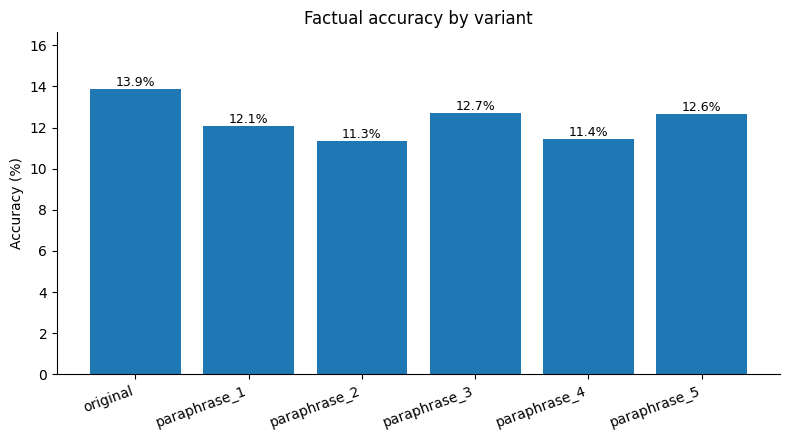

Saved: /content/drive/MyDrive/Research3/figures/phase4_answer_flip_rate.png


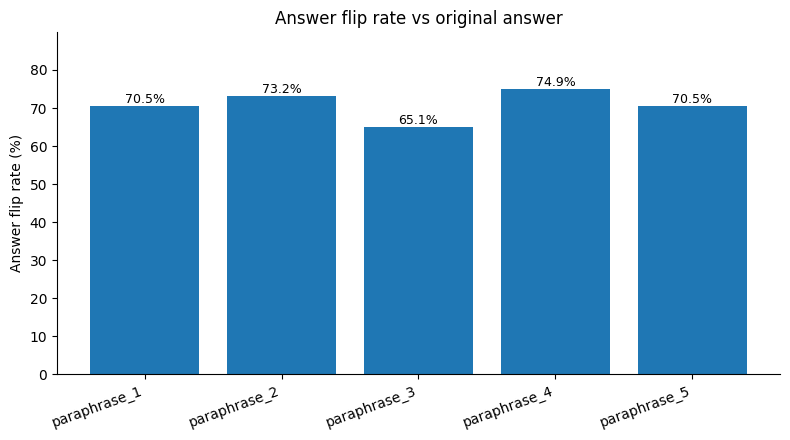

Saved: /content/drive/MyDrive/Research3/figures/phase4_correctness_transitions.png


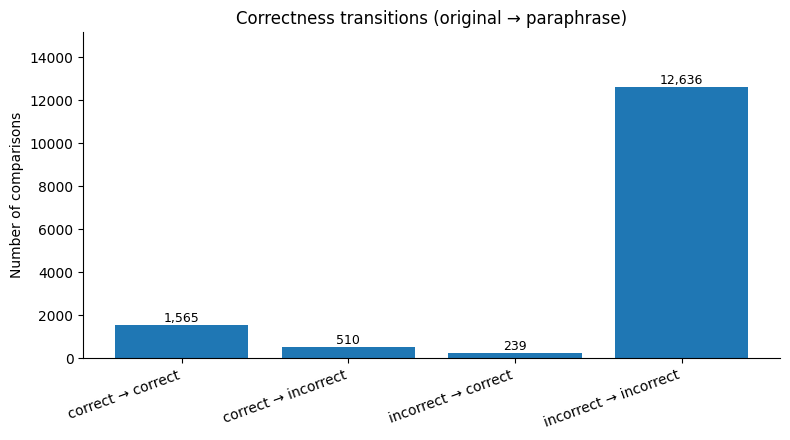

In [164]:
def bar_plot(labels, values, title, ylabel, filename, fmt):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(labels, values)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(values) * 1.2 if max(values) > 0 else 1)
    for b, v in zip(bars, values):
        ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom", fontsize=9)
    plt.xticks(rotation=20, ha="right")
    fig.tight_layout()
    path = f"{FIGURES_DIR}/{filename}"
    fig.savefig(path, dpi=150)
    saved_files.append(path)
    print(f"Saved: {path}")
    plt.show()


per_variant = variant_table[variant_table["variant"] != "overall"]
bar_plot(per_variant["variant"], 100 * per_variant["accuracy"],
         "Factual accuracy by variant", "Accuracy (%)", "phase4_accuracy_by_variant.png", "{:.1f}%")

per_para = flip_table[flip_table["variant"] != "all_paraphrases"]
bar_plot(per_para["variant"], 100 * per_para["answer_flip_rate"],
         "Answer flip rate vs original answer", "Answer flip rate (%)", "phase4_answer_flip_rate.png", "{:.1f}%")

bar_plot(overall_transitions["transition"], overall_transitions["count"],
         "Correctness transitions (original → paraphrase)", "Number of comparisons",
         "phase4_correctness_transitions.png", "{:,.0f}")

## 4.10 Reproducibility record and final summary
Saves a small JSON file with the model, dataset size, counts, the normalization rule and the correctness rule, then prints the Phase 4 summary and the list of generated files.

In [165]:
c_to_i = overall_transitions.set_index("transition").loc[TRANSITIONS[1]]
i_to_c = overall_transitions.set_index("transition").loc[TRANSITIONS[2]]

phase4_record = {
    "model_name": MODEL_NAME_P4,
    "dataset_questions": len(all_ids),
    "expected_inference_rows": EXPECTED_ROWS_P4,
    "successful_responses": n_success,
    "parse_errors": n_parse_errors,
    "inference_errors": n_inference_errors,
    "normalization_rule": NORMALIZATION_RULE,
    "correctness_matching_rule": MATCHING_RULE,
    "answer_identity_for_consistency_and_flips": "canonical_answer = normalized answer with one leading wrapper phrase removed",
    "consistency_definition": "all valid variants have the same canonical_answer; questions with fewer than 2 valid variants are excluded",
    "overall_accuracy": overall_accuracy,
    "consistency": {"questions_counted": n_scope2, "fully_consistent": n_consistent,
                    "inconsistent": n_inconsistent, "rate": consistency_rate},
    "overall_answer_flip_rate": float(overall_flip["answer_flip_rate"]),
    "valid_original_paraphrase_comparisons": int(overall_flip["valid_comparisons"]),
    "correct_to_incorrect": int(c_to_i["count"]),
    "incorrect_to_correct": int(i_to_c["count"]),
}
record_path = f"{RESULTS_DIR}/phase4_run_summary.json"
with open(record_path, "w", encoding="utf-8") as f:
    json.dump(phase4_record, f, indent=2, ensure_ascii=False)
saved_files.append(record_path)

print("=" * 40)
print("PHASE 4 SUMMARY")
print("=" * 40)
print(f"\nModel: {MODEL_NAME_P4}")
print(f"\nExpected inference rows: {EXPECTED_ROWS_P4}")
print(f"Successful responses: {n_success}")
print(f"Parse errors: {n_parse_errors}")
print(f"\nOverall accuracy: {overall_accuracy:.4f} ({100 * overall_accuracy:.2f}%)")
print(f"\nFully consistent questions: {n_consistent}")
print(f"Inconsistent questions: {n_inconsistent}")
print(f"Answer consistency rate: {consistency_rate:.4f} ({100 * consistency_rate:.2f}%)")
print(f"\nOverall original→paraphrase answer flip rate: {overall_flip['answer_flip_rate']:.4f} "
      f"({100 * overall_flip['answer_flip_rate']:.2f}%) over {int(overall_flip['valid_comparisons'])} comparisons")
print(f"\nCorrect → Incorrect: {int(c_to_i['count'])} ({c_to_i['percentage']:.2f}%)")
print(f"Incorrect → Correct: {int(i_to_c['count'])} ({i_to_c['percentage']:.2f}%)")
print("\nGenerated files:")
for path in saved_files:
    print(f"  {path}")
print("\nPhase 4 analysis completed.")

PHASE 4 SUMMARY

Model: Qwen/Qwen2.5-7B-Instruct

Expected inference rows: 18000
Successful responses: 17972
Parse errors: 28

Overall accuracy: 0.1235 (12.35%)

Fully consistent questions: 161
Inconsistent questions: 2839
Answer consistency rate: 0.0537 (5.37%)

Overall original→paraphrase answer flip rate: 0.7086 (70.86%) over 14950 comparisons

Correct → Incorrect: 510 (3.41%)
Incorrect → Correct: 239 (1.60%)

Generated files:
  /content/drive/MyDrive/Research3/results/phase4_evaluator_audit.csv
  /content/drive/MyDrive/Research3/results/phase4_evaluator_audit_summary.csv
  /content/drive/MyDrive/Research3/results/phase4_primary_vs_candidate.csv
  /content/drive/MyDrive/Research3/results/phase4_manual_review_sample.csv
  /content/drive/MyDrive/Research3/results/phase4_variant_accuracy.csv
  /content/drive/MyDrive/Research3/results/phase4_paraphrase_consistency.csv
  /content/drive/MyDrive/Research3/results/phase4_paraphrase_flip_rates.csv
  /content/drive/MyDrive/Research3/results/p

# Phase 5: Confidence Analysis, Calibration and Paraphrase Confidence Stability

This phase analyses the saved Phase 3 outputs only. **No model is loaded, no inference is run, no Phase 3/Phase 4 file is modified.**

It reuses the Phase 4 objects already in memory (`res`, `vdf`, `qtab`), so the correctness labels are exactly the Phase 4 labels.

**Interpretation rule:** `confidence` is a *self-reported* number from 0 to 100. We do not assume it is a true probability or that the model "knows its uncertainty". We only test empirically whether it behaves like a useful reliability signal.

Not in this phase: abstention, coverage, selective risk, risk-coverage curves, significance tests, LLM judge, embeddings.

In [166]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------- PHASE 5 CONFIGURATION ----------------
# The Phase 3 CSV path is the RESULTS_PATH set in the Phase 4 config cell (change it there if needed).
# Correctness labels come from the Phase 4 objects already in memory.
_needed = ["res", "vdf", "qtab", "all_ids", "VARIANTS", "PARAPHRASES", "MODEL_NAME_P4",
           "n_success", "overall_accuracy", "RESULTS_PATH", "RESULTS_DIR", "FIGURES_DIR"]
_missing_names = [n for n in _needed if n not in globals()]
if _missing_names:
    raise RuntimeError(f"Run the Phase 4 cells first. Missing: {_missing_names}")
assert "confidence" in res.columns and "correct" in vdf.columns, "Phase 4 objects look incomplete."

MIN_VALID_FOR_STABILITY = 2          # a question needs >= 2 valid confidence values for range/std
RANGE_THRESHOLDS = (10, 20, 30)      # analysis thresholds only, NOT a claim that these are "large"
N_EXAMPLES = 2

BIN_LABELS = ["0–9", "10–19", "20–29", "30–39", "40–49", "50–59", "60–69", "70–79", "80–89", "90–100"]
BIN_DEFINITION = (
    "10 bins on the 0-100 confidence scale: [0,10), [10,20), ..., [80,90), [90,100]. "
    "bin_index = min(floor(confidence/10), 9). Labels: " + ", ".join(BIN_LABELS) + ". "
    "Non-integer confidences (e.g. 9.5) fall into the bin of their floor (0–9)."
)

assert RESULTS_PATH.endswith("phase3_qwen25_7b_inference.csv") or True  # path only used by Phase 4 loader
p5_files = []  # every file written by Phase 5 (all names start with 'phase5_', nothing is overwritten)


def conf_bin_index(c):
    return np.minimum(np.floor(np.asarray(c, dtype=float) / 10).astype(int), 9)


def p5_save_table(table, filename):
    path = f"{RESULTS_DIR}/{filename}"
    table.to_csv(path, index=False)
    p5_files.append(path)
    print(f"Saved: {path}")


def p5_save_fig(fig, filename):
    path = f"{FIGURES_DIR}/{filename}"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    p5_files.append(path)
    print(f"Saved: {path}")


def p5_header(title):
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}")


print(f"Phase 5 reads the Phase 3 results via Phase 4 objects (source file: {RESULTS_PATH})")
print(f"Tables -> {RESULTS_DIR} | Figures -> {FIGURES_DIR}")

Phase 5 reads the Phase 3 results via Phase 4 objects (source file: /content/drive/MyDrive/Research3/results/phase3_qwen25_7b_inference.csv)
Tables -> /content/drive/MyDrive/Research3/results | Figures -> /content/drive/MyDrive/Research3/figures


## 5.1 Convert confidence safely to numeric and report problems

`confidence` is read as text (`dtype=str`). It is converted with `pd.to_numeric(errors="coerce")` and checked against `0 <= confidence <= 100`.

- **Missing:** the cell is empty (this is what Phase 3 stores for failed rows).
- **Invalid:** not numeric, NaN/inf, or outside 0–100.

Missing/invalid values are **excluded** from all confidence metrics. They are never replaced by 0 and never clipped.

In [167]:
raw_conf = res["confidence"]
conf_num = pd.to_numeric(raw_conf, errors="coerce")

is_missing = raw_conf.isna()
is_nonnumeric = raw_conf.notna() & conf_num.isna()                 # text that is not a number (or "nan")
is_out_of_range = conf_num.notna() & ~conf_num.between(0, 100)     # includes +/-inf
is_valid_conf = conf_num.between(0, 100)                           # False for NaN

conf_series = conf_num.where(is_valid_conf)                        # NaN for missing/invalid, nothing clipped

p5_header("CONFIDENCE VALIDATION (all 18,000 Phase 3 rows)")
print(f"Total rows:                       {len(res)}")
print(f"Valid confidence (0-100):         {int(is_valid_conf.sum())}")
print(f"Missing confidence:               {int(is_missing.sum())}")
print(f"Invalid: non-numeric:             {int(is_nonnumeric.sum())}")
print(f"Invalid: outside 0-100 / inf:     {int(is_out_of_range.sum())}")
print("\nStatus of rows with missing confidence:")
print(res.loc[is_missing, "status"].value_counts().to_string())
print(f"\nRows with valid confidence but status != success: {int((is_valid_conf & (res['status'] != 'success')).sum())}")

# analysis table: Phase 4 valid responses (they carry the Phase 4 correctness label) with valid confidence
cdf = vdf.copy()
cdf["conf"] = conf_series.loc[cdf.index]
n_success_missing_conf = int(cdf["conf"].isna().sum())
cdf = cdf[cdf["conf"].notna()].copy()
cdf["correct"] = cdf["correct"].astype(bool)
cdf["p"] = cdf["conf"] / 100.0
cdf["y"] = cdf["correct"].astype(int)
cdf["bin_idx"] = conf_bin_index(cdf["conf"])

n_conf_valid = len(cdf)
n_conf_missing = int(is_missing.sum())
n_conf_invalid = int(is_nonnumeric.sum() + is_out_of_range.sum())
acc_conf_set = float(cdf["y"].mean())

print(f"\nSuccessful responses dropped because of missing/invalid confidence: {n_success_missing_conf}")
print(f"Responses used for confidence analysis: {n_conf_valid}")
print(f"Accuracy on this set: {acc_conf_set:.4f} (Phase 4 overall accuracy: {overall_accuracy:.4f})")

# ---- basic summary table ----
c_conf = cdf.loc[cdf["correct"], "conf"]
i_conf = cdf.loc[~cdf["correct"], "conf"]
basic = pd.DataFrame(
    [
        ("valid_confidence_values", n_conf_valid),
        ("missing_confidence", n_conf_missing),
        ("invalid_confidence", n_conf_invalid),
        ("min", cdf["conf"].min()),
        ("max", cdf["conf"].max()),
        ("mean", cdf["conf"].mean()),
        ("median", cdf["conf"].median()),
        ("std (sample, ddof=1)", cdf["conf"].std()),
        ("mean_confidence_correct", c_conf.mean()),
        ("mean_confidence_incorrect", i_conf.mean()),
        ("median_confidence_correct", c_conf.median()),
        ("median_confidence_incorrect", i_conf.median()),
    ],
    columns=["metric", "value"],
)
p5_header("BASIC CONFIDENCE SUMMARY")
print(basic.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


CONFIDENCE VALIDATION (all 18,000 Phase 3 rows)
Total rows:                       18000
Valid confidence (0-100):         17972
Missing confidence:               28
Invalid: non-numeric:             0
Invalid: outside 0-100 / inf:     0

Status of rows with missing confidence:
status
parse_error    28

Rows with valid confidence but status != success: 0

Successful responses dropped because of missing/invalid confidence: 0
Responses used for confidence analysis: 17972
Accuracy on this set: 0.1235 (Phase 4 overall accuracy: 0.1235)

BASIC CONFIDENCE SUMMARY
                     metric      value
    valid_confidence_values 17972.0000
         missing_confidence    28.0000
         invalid_confidence     0.0000
                        min     0.0000
                        max   100.0000
                       mean    90.8555
                     median    95.0000
       std (sample, ddof=1)    13.6999
    mean_confidence_correct    98.0261
  mean_confidence_incorrect    89.8454
  media

## 5.2 Confidence by variant

For each of the 6 variants: valid confidence count, mean/median/std, and mean confidence on correct vs incorrect answers. Standard deviation is the sample standard deviation (ddof=1).

In [168]:
g = cdf.groupby("variant")["conf"]
by_variant = pd.DataFrame({
    "valid_conf_count": g.size(),
    "mean_confidence": g.mean(),
    "median_confidence": g.median(),
    "std_confidence": g.std(),
}).reindex(VARIANTS)
by_variant["mean_conf_correct"] = cdf[cdf["correct"]].groupby("variant")["conf"].mean().reindex(VARIANTS)
by_variant["mean_conf_incorrect"] = cdf[~cdf["correct"]].groupby("variant")["conf"].mean().reindex(VARIANTS)
by_variant["valid_conf_count"] = by_variant["valid_conf_count"].fillna(0).astype(int)
by_variant = by_variant.rename_axis("variant").reset_index()

p5_header("CONFIDENCE BY VARIANT")
print(by_variant.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
p5_save_table(by_variant, "phase5_confidence_by_variant.csv")


CONFIDENCE BY VARIANT
     variant  valid_conf_count  mean_confidence  median_confidence  std_confidence  mean_conf_correct  mean_conf_incorrect
    original              2994           90.620             95.000          15.131             97.807               89.463
paraphrase_1              2995           91.491             95.000          14.410             98.232               90.564
paraphrase_2              2989           89.997             95.000          13.316             97.434               89.045
paraphrase_3              2999           90.243             95.000          15.945             98.097               89.100
paraphrase_4              2998           92.528             95.000          10.108             98.251               91.789
paraphrase_5              2997           90.252             95.000          12.304             98.325               89.083
Saved: /content/drive/MyDrive/Research3/results/phase5_confidence_by_variant.csv


## 5.3 Correct vs incorrect confidence

Confidence distribution summary for correct and incorrect responses (Plot 1 shows each group as % of its own responses, so the groups can be compared even though their sizes differ).


CORRECT vs INCORRECT CONFIDENCE
    group  count   mean  median    std    min     max
  correct   2219 98.026 100.000  3.454 85.000 100.000
incorrect  15753 89.845  95.000 14.289  0.000 100.000
Saved: /content/drive/MyDrive/Research3/results/phase5_confidence_correct_vs_incorrect.csv
Saved: /content/drive/MyDrive/Research3/figures/phase5_confidence_correct_vs_incorrect.png


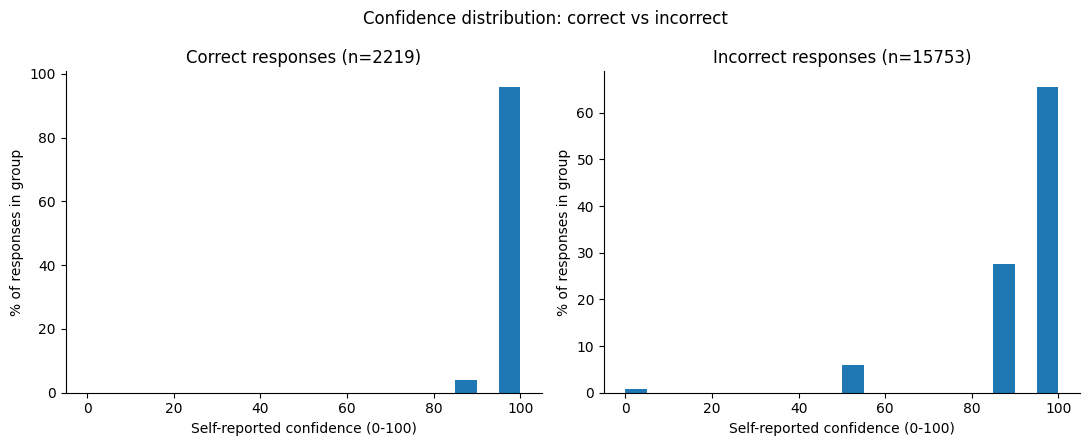

In [169]:
rows = []
for name, d in [("correct", c_conf), ("incorrect", i_conf)]:
    rows.append({
        "group": name, "count": len(d), "mean": d.mean(), "median": d.median(),
        "std": d.std(), "min": d.min(), "max": d.max(),
    })
cvi = pd.DataFrame(rows)

p5_header("CORRECT vs INCORRECT CONFIDENCE")
print(cvi.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
p5_save_table(cvi, "phase5_confidence_correct_vs_incorrect.csv")

# ---- Plot 1 ----
edges = np.arange(0, 105, 5)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)
for ax, (name, d) in zip(axes, [("Correct", c_conf), ("Incorrect", i_conf)]):
    if len(d) > 0:
        ax.hist(d, bins=edges, weights=np.full(len(d), 100.0 / len(d)))
    ax.set_title(f"{name} responses (n={len(d)})")
    ax.set_xlabel("Self-reported confidence (0-100)")
    ax.set_ylabel("% of responses in group")
fig.suptitle("Confidence distribution: correct vs incorrect")
fig.tight_layout()
p5_save_fig(fig, "phase5_confidence_correct_vs_incorrect.png")
plt.show()

## 5.4 Confidence bins: accuracy within each bin

Responses are split into the 10 confidence bins defined above. The key quantity is **accuracy within each confidence bin**: does higher stated confidence correspond to higher factual accuracy?


CONFIDENCE BINS
   bin  responses  accuracy  mean_confidence  num_correct  num_incorrect
   0–9        134    0.0000           0.0000            0            134
 10–19          0       NaN              NaN            0              0
 20–29          0       NaN              NaN            0              0
 30–39          0       NaN              NaN            0              0
 40–49          0       NaN              NaN            0              0
 50–59        940    0.0000          50.0000            0            940
 60–69          1    0.0000          60.0000            0              1
 70–79          0       NaN              NaN            0              0
 80–89       4430    0.0199          84.9989           88           4342
90–100      12467    0.1709          96.9961         2131          10336
Saved: /content/drive/MyDrive/Research3/results/phase5_confidence_bins.csv
Saved: /content/drive/MyDrive/Research3/figures/phase5_confidence_bin_accuracy.png


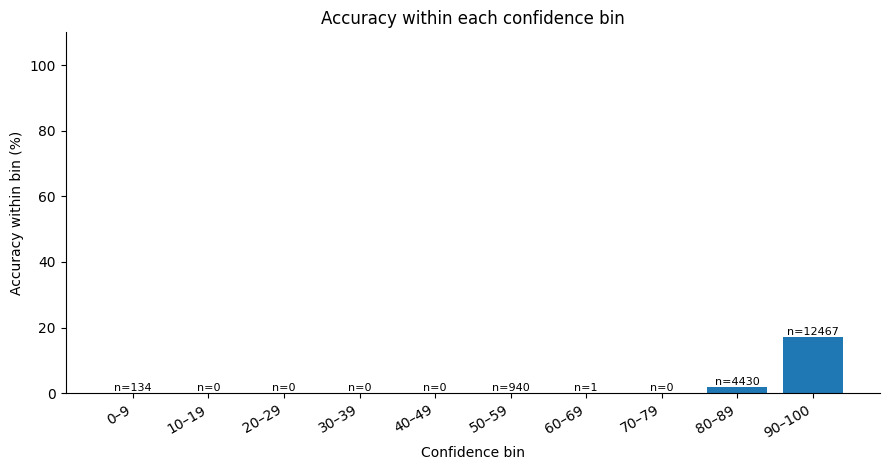

In [170]:
rows = []
for i, label in enumerate(BIN_LABELS):
    d = cdf[cdf["bin_idx"] == i]
    n = len(d)
    nc = int(d["correct"].sum())
    rows.append({
        "bin": label,
        "responses": n,
        "accuracy": nc / n if n else np.nan,
        "mean_confidence": d["conf"].mean() if n else np.nan,   # 0-100 scale
        "num_correct": nc,
        "num_incorrect": n - nc,
    })
bins_tbl = pd.DataFrame(rows)
assert bins_tbl["responses"].sum() == n_conf_valid, "Every valid response must fall in exactly one bin."

p5_header("CONFIDENCE BINS")
print(bins_tbl.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
p5_save_table(bins_tbl, "phase5_confidence_bins.csv")

# ---- Plot 2 ----
fig, ax = plt.subplots(figsize=(9, 4.8))
heights = 100 * bins_tbl["accuracy"].fillna(0)
bars = ax.bar(bins_tbl["bin"], heights)
for b, h, n in zip(bars, heights, bins_tbl["responses"]):
    ax.annotate(f"n={n}", (b.get_x() + b.get_width() / 2, h), ha="center", va="bottom", fontsize=8)
ax.set_xlabel("Confidence bin")
ax.set_ylabel("Accuracy within bin (%)")
ax.set_title("Accuracy within each confidence bin")
ax.set_ylim(0, 110)
plt.xticks(rotation=30, ha="right")
fig.tight_layout()
p5_save_fig(fig, "phase5_confidence_bin_accuracy.png")
plt.show()

## 5.5 Calibration: ECE, Brier score and reliability diagram

`confidence_probability = confidence / 100`, `y = 1` if correct else `0`.

- **ECE** = sum over bins of `bin_fraction * |bin_accuracy - bin_mean_confidence|` (10 bins from above, empty bins contribute 0).
- **Brier score** = mean of `(probability - y)^2` (lower is better).

Both are implemented directly with pandas/numpy. They measure how closely the *self-reported* number matches observed accuracy; they do not show that the number is a true probability.


CALIBRATION
   bin  count  mean_confidence  empirical_accuracy  absolute_gap  bin_fraction
   0–9    134           0.0000              0.0000        0.0000        0.0075
 10–19      0              NaN                 NaN           NaN        0.0000
 20–29      0              NaN                 NaN           NaN        0.0000
 30–39      0              NaN                 NaN           NaN        0.0000
 40–49      0              NaN                 NaN           NaN        0.0000
 50–59    940           0.5000              0.0000        0.5000        0.0523
 60–69      1           0.6000              0.0000        0.6000        0.0001
 70–79      0              NaN                 NaN           NaN        0.0000
 80–89   4430           0.8500              0.0199        0.8301        0.2465
90–100  12467           0.9700              0.1709        0.7990        0.6937

ECE (10 bins):  0.7851
Brier score:    0.7256  (lower is better)
Saved: /content/drive/MyDrive/Research3/results/phas

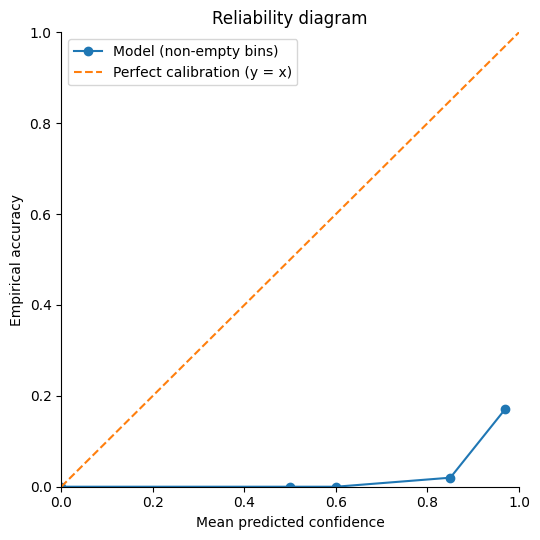

In [171]:
N = len(cdf)
calib = pd.DataFrame({
    "bin": bins_tbl["bin"],
    "count": bins_tbl["responses"],
    "mean_confidence": bins_tbl["mean_confidence"] / 100.0,   # probability scale (0-1)
    "empirical_accuracy": bins_tbl["accuracy"],
})
calib["absolute_gap"] = (calib["empirical_accuracy"] - calib["mean_confidence"]).abs()
calib["bin_fraction"] = calib["count"] / N

ECE = float((calib["bin_fraction"] * calib["absolute_gap"]).fillna(0).sum())
BRIER = float(((cdf["p"] - cdf["y"]) ** 2).mean())

p5_header("CALIBRATION")
print(calib.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nECE (10 bins):  {ECE:.4f}")
print(f"Brier score:    {BRIER:.4f}  (lower is better)")
p5_save_table(calib, "phase5_calibration_bins.csv")

# ---- Plot 3: reliability diagram ----
ne = calib[calib["count"] > 0]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(ne["mean_confidence"], ne["empirical_accuracy"], marker="o", label="Model (non-empty bins)")
ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration (y = x)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean predicted confidence")
ax.set_ylabel("Empirical accuracy")
ax.set_title("Reliability diagram")
ax.legend()
fig.tight_layout()
p5_save_fig(fig, "phase5_reliability_diagram.png")
plt.show()

## 5.6 Confidence stability across paraphrases (per question)

For every question, confidence is compared across the 6 variants.

- Stats (`mean`, `std`, `min`, `max`, `range`) are computed only when the question has **at least 2 valid confidence values**; otherwise they are left empty.
- `confidence_range = max_confidence - min_confidence`.
- `confidence_shift_from_original = paraphrase_confidence - original_confidence`, per paraphrase (empty if either value is missing).
- Correctness columns come from the Phase 4 labels (`num_valid_variants`, `num_correct_variants`, `correctness_rate`).

The per-question table (with the raw confidences and shifts) is saved as `phase5_paraphrase_confidence_stability.csv`. A per-paraphrase summary of the shifts is saved as `phase5_confidence_shift_by_paraphrase.csv`.

In [172]:
conf_wide = (
    cdf.pivot(index="question_id", columns="variant", values="conf")
    .reindex(index=all_ids, columns=VARIANTS)
)

qstab = pd.DataFrame(index=pd.Index(all_ids, name="question_id"))
qstab["n_valid_conf"] = conf_wide.notna().sum(axis=1).astype(int)
enough = qstab["n_valid_conf"] >= MIN_VALID_FOR_STABILITY
qstab["mean_confidence"] = conf_wide.mean(axis=1).where(enough)
qstab["std_confidence"] = conf_wide.std(axis=1, ddof=1).where(enough)
qstab["min_confidence"] = conf_wide.min(axis=1).where(enough)
qstab["max_confidence"] = conf_wide.max(axis=1).where(enough)
qstab["confidence_range"] = qstab["max_confidence"] - qstab["min_confidence"]

for v in VARIANTS:
    qstab[f"conf_{v}"] = conf_wide[v]
for v in PARAPHRASES:
    qstab[f"confidence_shift_{v}"] = conf_wide[v] - conf_wide["original"]

# ---- correctness columns (Phase 4 labels, restricted to variants with valid confidence) ----
cg = cdf.groupby("question_id")["correct"].agg(["size", "sum"]).reindex(all_ids).fillna(0)
qstab["num_valid_variants"] = cg["size"].astype(int).to_numpy()
qstab["num_correct_variants"] = cg["sum"].astype(int).to_numpy()
qstab["correctness_rate"] = (
    qstab["num_correct_variants"] / qstab["num_valid_variants"].where(qstab["num_valid_variants"] > 0)
)

qstab["correctness_group"] = "fewer_than_2_valid"
ok2 = qstab["num_valid_variants"] >= 2
qstab.loc[ok2 & (qstab["num_correct_variants"] == qstab["num_valid_variants"]), "correctness_group"] = "all_correct"
qstab.loc[ok2 & (qstab["num_correct_variants"] == 0), "correctness_group"] = "all_incorrect"
qstab.loc[ok2 & (qstab["num_correct_variants"] > 0)
          & (qstab["num_correct_variants"] < qstab["num_valid_variants"]), "correctness_group"] = "mixed"

# answer consistency flag taken from Phase 4 (qtab)
qstab["fully_consistent_answer"] = qtab["fully_consistent"].reindex(all_ids).fillna(False).astype(bool).to_numpy()

# sanity check against Phase 4's own per-question counts
q4 = qtab.reindex(all_ids)
same_valid = bool((qstab["num_valid_variants"].to_numpy() == q4["num_valid_variants"].to_numpy()).all())
same_correct = bool((qstab["num_correct_variants"].to_numpy() == q4["num_correct_variants"].to_numpy()).all())
print(f"Matches Phase 4 per-question counts -> valid variants: {same_valid} | correct variants: {same_correct}")

n_with_range = int(qstab["confidence_range"].notna().sum())
print(f"Questions: {len(qstab)} | with >= {MIN_VALID_FOR_STABILITY} valid confidence values: {n_with_range}")

p5_save_table(qstab.reset_index(), "phase5_paraphrase_confidence_stability.csv")

# ---- shift by paraphrase (summary per paraphrase) ----
def shift_row(name, s):
    s = s.dropna()
    return {
        "variant": name, "valid_pairs": len(s),
        "mean_shift": s.mean(), "median_shift": s.median(), "std_shift": s.std(),
        "mean_abs_shift": s.abs().mean(),
        "pct_increased": 100 * (s > 0).mean() if len(s) else np.nan,
        "pct_decreased": 100 * (s < 0).mean() if len(s) else np.nan,
        "pct_unchanged": 100 * (s == 0).mean() if len(s) else np.nan,
    }

shift_rows = [shift_row(v, qstab[f"confidence_shift_{v}"]) for v in PARAPHRASES]
pooled = pd.concat([qstab[f"confidence_shift_{v}"] for v in PARAPHRASES], ignore_index=True)
shift_rows.append(shift_row("all_paraphrases", pooled))
shift_tbl = pd.DataFrame(shift_rows)

p5_header("CONFIDENCE SHIFT FROM ORIGINAL (paraphrase - original)")
print(shift_tbl.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
p5_save_table(shift_tbl, "phase5_confidence_shift_by_paraphrase.csv")

Matches Phase 4 per-question counts -> valid variants: True | correct variants: True
Questions: 3000 | with >= 2 valid confidence values: 3000
Saved: /content/drive/MyDrive/Research3/results/phase5_paraphrase_confidence_stability.csv

CONFIDENCE SHIFT FROM ORIGINAL (paraphrase - original)
        variant  valid_pairs  mean_shift  median_shift  std_shift  mean_abs_shift  pct_increased  pct_decreased  pct_unchanged
   paraphrase_1         2989       0.895         0.000     16.427           7.272         27.066         16.628         56.306
   paraphrase_2         2983      -0.660         0.000     15.984           7.378         17.566         25.411         57.023
   paraphrase_3         2993      -0.383         0.000     17.278           7.225         18.109         22.820         59.071
   paraphrase_4         2993       1.924         0.000     15.846           7.077         23.655         20.882         55.463
   paraphrase_5         2992      -0.366         0.000     15.873          

## 5.7 Confidence stability summary + Plots 4 and 5

Statistics of `confidence_range` over questions with at least 2 valid confidence values.

The thresholds 10, 20 and 30 points are **analysis thresholds chosen for reporting**. They are not a claim that these ranges are "small" or "large".


CONFIDENCE RANGE ACROSS PARAPHRASES (per question)
Questions included:                3000
Mean confidence range:             17.688
Median confidence range:           10.000
Std of confidence range:           21.058
Questions with range >= 10 points:  65.47%  (threshold used for analysis)
Questions with range >= 20 points:  20.20%  (threshold used for analysis)
Questions with range >= 30 points:  20.17%  (threshold used for analysis)
Saved: /content/drive/MyDrive/Research3/figures/phase5_confidence_range.png


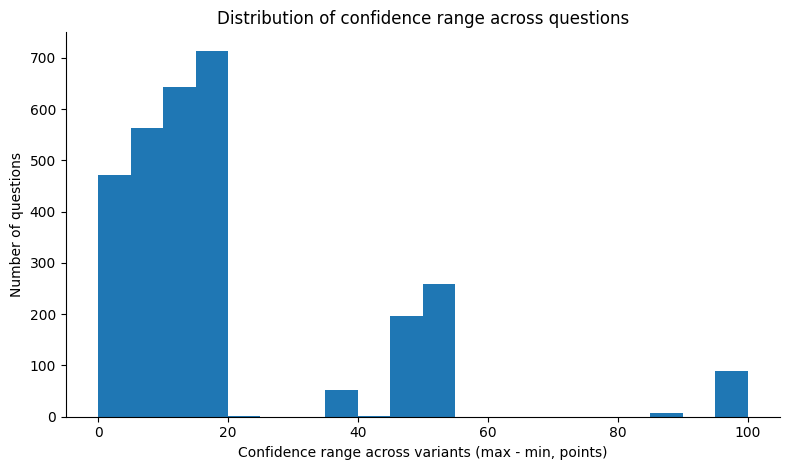

Saved: /content/drive/MyDrive/Research3/figures/phase5_confidence_shift_by_paraphrase.png


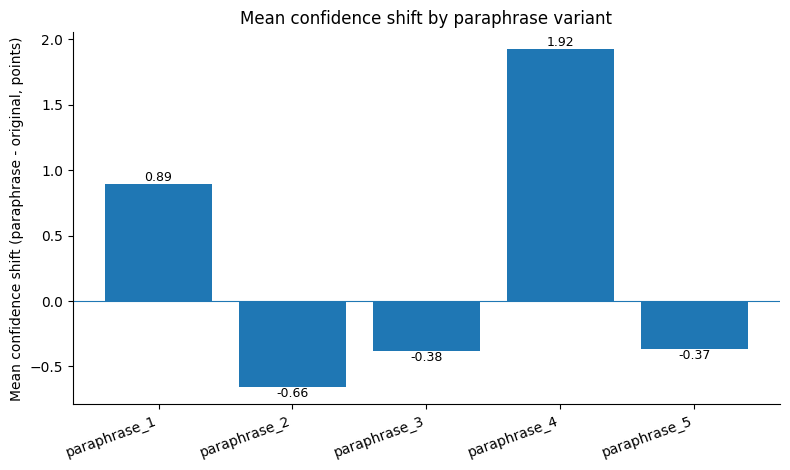

In [173]:
rng = qstab["confidence_range"].dropna()
range_stats = {
    "n_questions": len(rng),
    "mean": float(rng.mean()),
    "median": float(rng.median()),
    "std": float(rng.std()),
}
range_pct = {t: float(100 * (rng >= t).mean()) for t in RANGE_THRESHOLDS}

p5_header("CONFIDENCE RANGE ACROSS PARAPHRASES (per question)")
print(f"Questions included:                {range_stats['n_questions']}")
print(f"Mean confidence range:             {range_stats['mean']:.3f}")
print(f"Median confidence range:           {range_stats['median']:.3f}")
print(f"Std of confidence range:           {range_stats['std']:.3f}")
for t in RANGE_THRESHOLDS:
    print(f"Questions with range >= {t:2d} points:  {range_pct[t]:.2f}%  (threshold used for analysis)")

# ---- Plot 4 ----
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(rng, bins=np.arange(0, 105, 5))
ax.set_xlabel("Confidence range across variants (max - min, points)")
ax.set_ylabel("Number of questions")
ax.set_title("Distribution of confidence range across questions")
fig.tight_layout()
p5_save_fig(fig, "phase5_confidence_range.png")
plt.show()

# ---- Plot 5 ----
sp = shift_tbl[shift_tbl["variant"] != "all_paraphrases"]
fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.bar(sp["variant"], sp["mean_shift"])
for b, v in zip(bars, sp["mean_shift"]):
    ax.annotate(f"{v:.2f}", (b.get_x() + b.get_width() / 2, v), ha="center",
                va="bottom" if v >= 0 else "top", fontsize=9)
ax.axhline(0, linewidth=0.8)
ax.set_ylabel("Mean confidence shift (paraphrase - original, points)")
ax.set_title("Mean confidence shift by paraphrase variant")
plt.xticks(rotation=20, ha="right")
fig.tight_layout()
p5_save_fig(fig, "phase5_confidence_shift_by_paraphrase.png")
plt.show()

## 5.8 Correctness stability vs confidence stability (descriptive only)

Questions are grouped by correctness across their valid variants (only questions with at least 2 valid variants, so a confidence range exists):

- **all_correct:** every valid variant is correct
- **all_incorrect:** every valid variant is incorrect
- **mixed:** at least one correct and one incorrect

Only descriptive statistics are reported. No significance tests in this phase.

In [174]:
grp = (
    qstab[qstab["confidence_range"].notna()]
    .groupby("correctness_group")["confidence_range"]
    .agg(n_questions="size", mean_confidence_range="mean",
         median_confidence_range="median", std_confidence_range="std")
    .reindex(["all_correct", "all_incorrect", "mixed"])
    .reset_index()
)
grp["n_questions"] = grp["n_questions"].fillna(0).astype(int)

p5_header("CONFIDENCE RANGE BY CORRECTNESS GROUP")
print(grp.to_string(index=False, float_format=lambda x: f"{x:.3f}"))


CONFIDENCE RANGE BY CORRECTNESS GROUP
correctness_group  n_questions  mean_confidence_range  median_confidence_range  std_confidence_range
      all_correct          135                  1.296                    0.000                 2.283
    all_incorrect         2437                 20.351                   15.000                22.167
            mixed          428                  7.699                    5.000                 9.164


## 5.9 Automatically selected examples

Deterministic rules, no manual choice (ties are broken by dataset order, then variant order):

- **A:** largest confidence range among questions with the same correctness in all valid variants **and** a fully consistent answer. Shows the lowest- and highest-confidence variant.
- **B:** largest confidence range among questions with mixed correctness. Shows the lowest- and highest-confidence variant.
- **C:** highest-confidence **incorrect** responses.

In [175]:
cl = cdf.set_index(["question_id", "variant"])
q_pos = {qid: i for i, qid in enumerate(all_ids)}
v_pos = {v: i for i, v in enumerate(VARIANTS)}


def show_row(qid, variant, tag=""):
    r = cl.loc[(qid, variant)]
    gold = r["gold_list"]
    gold_txt = ", ".join(repr(a) for a in gold[:3]) + (f" (+{len(gold) - 3} more)" if len(gold) > 3 else "")
    print(f"  {tag}question_id: {qid} | variant: {variant}")
    print(f"    question:    {r['question']}")
    print(f"    answer:      {r['answer']}")
    print(f"    confidence:  {r['conf']:g}")
    print(f"    correctness: {'correct' if r['correct'] else 'incorrect'} (gold: {gold_txt})")


def show_range_examples(title, cand):
    p5_header(title)
    cand = cand[cand["confidence_range"] > 0].sort_values("confidence_range", ascending=False, kind="stable")
    if len(cand) == 0:
        print("No examples found.")
        return
    for k, (qid, r) in enumerate(cand.head(N_EXAMPLES).iterrows(), start=1):
        row_conf = conf_wide.loc[qid]
        v_lo, v_hi = row_conf.idxmin(), row_conf.idxmax()
        print(f"\nExample {k}: confidence range = {r['confidence_range']:g} | "
              f"correct variants = {r['num_correct_variants']}/{r['num_valid_variants']}")
        show_row(qid, v_lo, "[lowest confidence] ")
        show_row(qid, v_hi, "[highest confidence] ")


same_corr = qstab["correctness_group"].isin(["all_correct", "all_incorrect"])
show_range_examples("EXAMPLE A: large confidence change, same answer and same correctness",
                    qstab[same_corr & qstab["fully_consistent_answer"]])
show_range_examples("EXAMPLE B: large confidence change with correctness change",
                    qstab[qstab["correctness_group"] == "mixed"])

p5_header("EXAMPLE C: very high confidence but incorrect answer")
inc = cdf[~cdf["correct"]].copy()
inc["_q"] = inc["question_id"].map(q_pos)
inc["_v"] = inc["variant"].map(v_pos)
inc = inc.sort_values(["conf", "_q", "_v"], ascending=[False, True, True])
if len(inc) == 0:
    print("No incorrect responses.")
for k, (_, r) in enumerate(inc.head(N_EXAMPLES).iterrows(), start=1):
    print(f"\nExample {k}:")
    show_row(r["question_id"], r["variant"])


EXAMPLE A: large confidence change, same answer and same correctness

Example 1: confidence range = 15 | correct variants = 0/6
  [lowest confidence] question_id: 2078635 | variant: paraphrase_5
    question:    Who was in charge of production of As You Like It?
    answer:      William Shakespeare
    confidence:  85
    correctness: incorrect (gold: 'Paul Czinner')
  [highest confidence] question_id: 2078635 | variant: paraphrase_1
    question:    Who produced As You Like It?
    answer:      William Shakespeare
    confidence:  100
    correctness: incorrect (gold: 'Paul Czinner')

Example 2: confidence range = 10 | correct variants = 0/6
  [lowest confidence] question_id: 1014403 | variant: original
    question:    Who is the mother of Emmanuel Th√©odose de La Tour d'Auvergne?
    answer:      Marie de Bourbon
    confidence:  85
    correctness: incorrect (gold: 'Marie Anne Mancini', 'Marie-Anne Mancini')
  [highest confidence] question_id: 1014403 | variant: paraphrase_2
    q

## 5.10 Reproducibility record and final summary

Saves `phase5_run_summary.json` (counts, accuracy, confidence statistics, ECE, Brier score, range statistics, thresholds and the exact bin definition) and prints the Phase 5 summary and all generated file paths.

In [176]:
def _f(x):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else float(x)


mean_conf = float(cdf["conf"].mean())
mean_conf_c = float(c_conf.mean()) if len(c_conf) else None
mean_conf_i = float(i_conf.mean()) if len(i_conf) else None

phase5_record = {
    "model_name": MODEL_NAME_P4,
    "phase3_results_path": RESULTS_PATH,
    "num_questions": len(all_ids),
    "num_successful_model_responses": int(n_success),
    "num_valid_confidence_values": int(n_conf_valid),
    "num_invalid_or_missing_confidence_values": int(len(res) - n_conf_valid),
    "num_missing_confidence": n_conf_missing,
    "num_invalid_confidence": n_conf_invalid,
    "overall_accuracy": float(acc_conf_set),
    "phase4_overall_accuracy": float(overall_accuracy),
    "mean_confidence": mean_conf,
    "mean_confidence_correct": _f(mean_conf_c),
    "mean_confidence_incorrect": _f(mean_conf_i),
    "ece": ECE,
    "brier_score": BRIER,
    "mean_confidence_range": range_stats["mean"],
    "median_confidence_range": range_stats["median"],
    "std_confidence_range": range_stats["std"],
    "num_questions_with_confidence_range": range_stats["n_questions"],
    "confidence_range_thresholds": list(RANGE_THRESHOLDS),
    "pct_questions_range_at_least": {str(t): range_pct[t] for t in RANGE_THRESHOLDS},
    "confidence_range_by_correctness_group": {
        r["correctness_group"]: {
            "n_questions": int(r["n_questions"]),
            "mean": _f(r["mean_confidence_range"]),
            "median": _f(r["median_confidence_range"]),
        }
        for _, r in grp.iterrows()
    },
    "min_valid_confidence_values_for_stability": MIN_VALID_FOR_STABILITY,
    "calibration_bin_definition": BIN_DEFINITION,
    "calibration_bin_labels": BIN_LABELS,
    "std_definition": "sample standard deviation (ddof=1)",
    "correctness_definition": "Phase 4 is_correct (normalized exact match / wrapper match against gold aliases)",
    "note": "Confidence is a self-reported 0-100 number; it is evaluated empirically, not assumed to be a true probability.",
}

p5_json_path = f"{RESULTS_DIR}/phase5_run_summary.json"
with open(p5_json_path, "w", encoding="utf-8") as f:
    json.dump(phase5_record, f, indent=2, ensure_ascii=False)
p5_files.append(p5_json_path)
print(f"Saved: {p5_json_path}")

print("\n" + "=" * 40)
print("PHASE 5 SUMMARY")
print("=" * 40)
print(f"\nModel: {MODEL_NAME_P4}\n")
print(f"Valid confidence values: {n_conf_valid}")
print(f"Invalid/missing confidence: {len(res) - n_conf_valid}\n")
print(f"Overall accuracy: {acc_conf_set:.4f} ({100 * acc_conf_set:.2f}%)\n")
print(f"Mean confidence: {mean_conf:.2f}")
print(f"Mean confidence (correct): {mean_conf_c:.2f}")
print(f"Mean confidence (incorrect): {mean_conf_i:.2f}\n")
print(f"ECE: {ECE:.4f}")
print(f"Brier score: {BRIER:.4f}\n")
print(f"Mean confidence range across paraphrases: {range_stats['mean']:.2f}")
print(f"Median confidence range: {range_stats['median']:.2f}\n")
for t in RANGE_THRESHOLDS:
    print(f"Questions with confidence range >={t}: {range_pct[t]:.2f}%")
print("\nPhase 5 confidence analysis completed.")

print("\nGenerated files:")
for p in p5_files:
    print(" ", p)

Saved: /content/drive/MyDrive/Research3/results/phase5_run_summary.json

PHASE 5 SUMMARY

Model: Qwen/Qwen2.5-7B-Instruct

Valid confidence values: 17972
Invalid/missing confidence: 28

Overall accuracy: 0.1235 (12.35%)

Mean confidence: 90.86
Mean confidence (correct): 98.03
Mean confidence (incorrect): 89.85

ECE: 0.7851
Brier score: 0.7256

Mean confidence range across paraphrases: 17.69
Median confidence range: 10.00

Questions with confidence range >=10: 65.47%
Questions with confidence range >=20: 20.20%
Questions with confidence range >=30: 20.17%

Phase 5 confidence analysis completed.

Generated files:
  /content/drive/MyDrive/Research3/results/phase5_confidence_by_variant.csv
  /content/drive/MyDrive/Research3/results/phase5_confidence_correct_vs_incorrect.csv
  /content/drive/MyDrive/Research3/figures/phase5_confidence_correct_vs_incorrect.png
  /content/drive/MyDrive/Research3/results/phase5_confidence_bins.csv
  /content/drive/MyDrive/Research3/figures/phase5_confidence_bi

## 5.11 Phase 5 supplement: inputs, assertions and reproducibility checks
Adds the remaining Phase 5 analyses without changing any existing Phase 4/5 object. Strict Phase 4 correctness stays the PRIMARY label. The audit-adjusted ~16.60% estimate is a **sensitivity estimate only**; it is recorded as a labelled row in the summary file and is never used in any calculation. No inference, no LLM judge, no fuzzy or semantic matching.

Checks: 18,000 rows, 3,000 questions, 6 variants each, no duplicate `question_id + variant`, confidence within 0-100, strict labels recomputed from the raw answers and identical to Phase 4, SHA-256 of the raw Phase 3 CSV unchanged.

In [177]:
import hashlib

from scipy import stats as sps

# ---------------- PHASE 5 SUPPLEMENT: CONFIGURATION ----------------
# Uses the Phase 4 / Phase 5 objects already in memory. No model, no inference, no relabelling.
# New objects use the prefix p5x_ / P5X_ so nothing needed by later phases is overwritten.
_needed = ["res", "vdf", "qtab", "pairs_df", "all_ids", "VARIANTS", "PARAPHRASES", "cdf", "conf_wide", "qstab",
           "calib", "bins_tbl", "ECE", "BRIER", "c_conf", "i_conf", "p5_save_table", "p5_save_fig", "p5_header",
           "p5_files", "RESULTS_PATH", "RESULTS_DIR", "FIGURES_DIR", "match_answer", "n_valid", "n_correct",
           "overall_accuracy"]
_missing = [n for n in _needed if n not in globals()]
if _missing:
    raise RuntimeError(f"Run the Phase 4 cells and the existing Phase 5 cells (5.1-5.10) first. Missing: {_missing}")

P5X_SEED = 42                      # used only for the high-confidence-error example sample
P5X_EXPECTED = {"rows": 18000, "questions": 3000, "variants": 6, "valid": 17972, "correct": 2219}
CONF_THRESHOLDS = (50, 60, 70, 80, 90)
HCE_EXAMPLES_PER_BAND = 100        # up to 100 examples from [80,90) and up to 100 from [90,100]
STAB_GROUP_EDGES = (10, 30)        # analysis groups only: stable <10, moderate 10-<30, large >=30 points
AUDIT_SENSITIVITY_NOTE = ("Approximate value reported from the manual audit (~16.60%). SENSITIVITY ESTIMATE ONLY: "
                          "not measured in Phase 5, not used in any calculation, does not replace strict accuracy.")

P5X_START = len(p5_files)          # files written by this supplement start here
p5x_summary = []                   # rows of phase5_confidence_summary.csv
p5x_tests = []                     # rows of phase5_statistical_tests.csv
p5x_q_pos = {q: i for i, q in enumerate(all_ids)}
p5x_v_pos = {v: i for i, v in enumerate(VARIANTS)}


def p5x_add(section, metric, value, note=""):
    p5x_summary.append({"section": section, "metric": metric, "value": value, "note": note})


# ---- raw Phase 3 file fingerprint (checked again at the end) ----
P5X_SHA_BEFORE = hashlib.sha256(open(RESULTS_PATH, "rb").read()).hexdigest()
P5X_MTIME_BEFORE = os.path.getmtime(RESULTS_PATH)

# ---------------- assertions on the inputs ----------------
assert len(res) == P5X_EXPECTED["rows"], "Raw Phase 3 row count changed."
assert res["question_id"].nunique() == len(all_ids) == P5X_EXPECTED["questions"], "Expected 3,000 unique questions."
assert (res.groupby("question_id")["variant"].nunique() == P5X_EXPECTED["variants"]).all(), "Each question must have 6 variants."
assert not res.duplicated(["question_id", "variant"]).any(), "Duplicate question_id + variant in raw results."
assert not cdf.duplicated(["question_id", "variant"]).any(), "Duplicate question_id + variant in the confidence table."
assert (cdf.groupby("question_id").size() <= 6).all(), "More than 6 valid responses for a question."
assert cdf["conf"].between(0, 100).all(), "Confidence outside 0-100 in the analysis table."
assert n_valid == P5X_EXPECTED["valid"] and n_correct == P5X_EXPECTED["correct"], "Phase 4 counts changed."
assert abs(overall_accuracy - 0.1235) < 1e-4, "Strict accuracy is no longer ~0.1235."

# correctness labels unchanged: recompute the strict Phase 4 rule from the raw answers and compare
_recomputed = pd.Series([match_answer(a, g)[0] for a, g in zip(vdf["answer"], vdf["gold_norms"])], index=vdf.index)
assert (_recomputed == vdf["correct"]).all(), "Phase 4 strict labels differ from a fresh recomputation."
assert (cdf["correct"] == vdf.loc[cdf.index, "correct"]).all(), "Confidence table labels differ from Phase 4 labels."
if "CORRECT_BEFORE" in globals():      # snapshot taken by the Phase 4 evaluator audit, when it was run
    assert (vdf["correct"] == CORRECT_BEFORE).all(), "Phase 4 labels changed after the evaluator audit."

# ---- original-vs-paraphrase pairs that also have valid confidence on both sides ----
_conf_long = cdf.set_index(["question_id", "variant"])["conf"]
pp = pairs_df.copy()
pp["conf_orig"] = conf_wide["original"].reindex(pp["question_id"]).to_numpy()
pp["conf_para"] = _conf_long.reindex(pd.MultiIndex.from_arrays([pp["question_id"], pp["variant"]])).to_numpy()
pp = pp[pp["conf_orig"].notna() & pp["conf_para"].notna()].copy()
pp["delta"] = pp["conf_para"] - pp["conf_orig"]            # positive = paraphrase more confident than original
pp["abs_delta"] = pp["delta"].abs()
pp["correct_changed"] = pp["correct_orig"] != pp["correct_para"]

p5_header("PHASE 5 SUPPLEMENT: INPUTS AND CHECKS")
print(f"Raw Phase 3 file (read-only):       {os.path.basename(RESULTS_PATH)}")
print(f"Rows:                               {len(res)}")
print(f"Valid (successful) responses:       {n_valid}")
print(f"Responses with valid confidence:    {len(cdf)}")
print(f"Questions:                          {len(all_ids)}")
print(f"Variants per question:              {len(VARIANTS)}")
print(f"Original-paraphrase pairs used:     {len(pp)}")
print(f"Random seed (example sampling):     {P5X_SEED}")
print(f"Strict accuracy (PRIMARY):          {n_correct}/{n_valid} = {100 * overall_accuracy:.2f}%")
print("All input assertions passed.")


PHASE 5 SUPPLEMENT: INPUTS AND CHECKS
Raw Phase 3 file (read-only):       phase3_qwen25_7b_inference.csv
Rows:                               18000
Valid (successful) responses:       17972
Responses with valid confidence:    17972
Questions:                          3000
Variants per question:              6
Original-paraphrase pairs used:     14950
Random seed (example sampling):     42
Strict accuracy (PRIMARY):          2219/17972 = 12.35%
All input assertions passed.


## 5.12 A-C: confidence distribution, confidence vs correctness, high-confidence errors
Confidence statistics (overall, original vs pooled paraphrases), the share of strict-incorrect answers at confidence >= 50/60/70/80/90, and the count of incorrect answers with confidence >= 80 and >= 90 (as % of incorrect and of all valid responses). `phase5_high_confidence_errors.csv` holds a random sample (seed 42) of up to 100 strict-incorrect examples from each band, 80-89 and 90-100. All of them are strict-incorrect; nothing is relabelled.


A. CONFIDENCE DISTRIBUTION (0-100 self-reported scale)
                           n   mean  median  std (ddof=1)   min     max
all_responses      17972.000 90.855  95.000        13.700 0.000 100.000
original            2994.000 90.620  95.000        15.131 0.000 100.000
paraphrases_pooled 14978.000 90.903  95.000        13.396 0.000 100.000

Most common confidence value: 95 (41.68% of responses)
Top 5 confidence values: 95 (41.7%), 100 (27.7%), 85 (24.6%), 50 (5.2%), 0 (0.7%)
Saved: /content/drive/MyDrive/Research3/figures/phase5_confidence_distribution.png


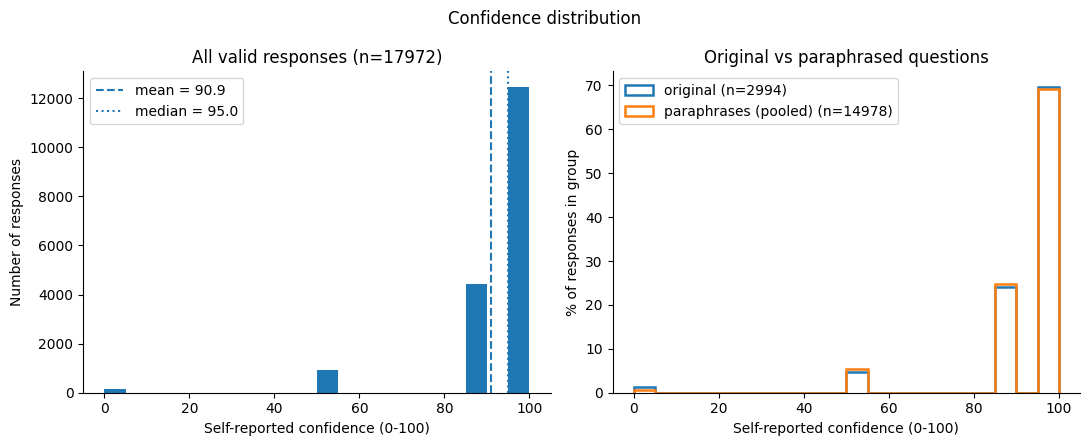


B. CONFIDENCE VS STRICT CORRECTNESS (Phase 4 labels)
Correct responses:   n=2219  mean=98.026  median=100.000
Incorrect responses: n=15753  mean=89.845  median=95.000
Mean difference (correct - incorrect):   8.181 points
Median difference (correct - incorrect): 5.000 points

Share of responses at or above each confidence threshold:
 confidence_threshold  incorrect_with_conf_ge_T  pct_of_incorrect  correct_with_conf_ge_T  pct_of_correct
                   50                     15619             99.15                    2219          100.00
                   60                     14679             93.18                    2219          100.00
                   70                     14678             93.18                    2219          100.00
                   80                     14678             93.18                    2219          100.00
                   90                     10336             65.61                    2131           96.03

C. HIGH-CONFIDENCE WRONG ANS

In [178]:
# ======================= A. Confidence distribution =======================
conf_all = cdf["conf"]
conf_orig_s = cdf.loc[cdf["variant"] == "original", "conf"]
conf_para_s = cdf.loc[cdf["variant"] != "original", "conf"]


def desc(s):
    return {"n": len(s), "mean": s.mean(), "median": s.median(), "std (ddof=1)": s.std(), "min": s.min(), "max": s.max()}


dist_tbl = pd.DataFrame({"all_responses": desc(conf_all), "original": desc(conf_orig_s),
                         "paraphrases_pooled": desc(conf_para_s)}).T
p5_header("A. CONFIDENCE DISTRIBUTION (0-100 self-reported scale)")
print(dist_tbl.to_string(float_format=lambda x: f"{x:.3f}"))

vc = conf_all.value_counts()
mode_val, mode_share = float(vc.index[0]), float(100 * vc.iloc[0] / len(conf_all))
print(f"\nMost common confidence value: {mode_val:g} ({mode_share:.2f}% of responses)")
print("Top 5 confidence values: " + ", ".join(f"{k:g} ({100 * v / len(conf_all):.1f}%)" for k, v in vc.head(5).items()))

for grp_name, row in dist_tbl.iterrows():
    for m, val in row.items():
        p5x_add("CONFIDENCE (measured)", f"{grp_name}: {m}", float(val),
                "self-reported confidence on a 0-100 scale; sample std")
p5x_add("CONFIDENCE (measured)", "most_common_confidence_value", mode_val, "mode of all responses")
p5x_add("CONFIDENCE (measured)", "share_at_most_common_value_pct", mode_share, "percent of responses at the mode")

# ---- figure: confidence distribution ----
edges = np.arange(0, 105, 5)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(conf_all, bins=edges)
axes[0].axvline(conf_all.mean(), linestyle="--", label=f"mean = {conf_all.mean():.1f}")
axes[0].axvline(conf_all.median(), linestyle=":", label=f"median = {conf_all.median():.1f}")
axes[0].set_xlabel("Self-reported confidence (0-100)")
axes[0].set_ylabel("Number of responses")
axes[0].set_title(f"All valid responses (n={len(conf_all)})")
axes[0].legend()
for name, s in [("original", conf_orig_s), ("paraphrases (pooled)", conf_para_s)]:
    axes[1].hist(s, bins=edges, weights=np.full(len(s), 100.0 / len(s)), histtype="step", linewidth=1.8, label=f"{name} (n={len(s)})")
axes[1].set_xlabel("Self-reported confidence (0-100)")
axes[1].set_ylabel("% of responses in group")
axes[1].set_title("Original vs paraphrased questions")
axes[1].legend()
fig.suptitle("Confidence distribution")
fig.tight_layout()
p5_save_fig(fig, "phase5_confidence_distribution.png")
plt.show()

# ======================= B. Confidence vs correctness =======================
p5_header("B. CONFIDENCE VS STRICT CORRECTNESS (Phase 4 labels)")
mc, mi = float(c_conf.mean()), float(i_conf.mean())
medc, medi = float(c_conf.median()), float(i_conf.median())
print(f"Correct responses:   n={len(c_conf)}  mean={mc:.3f}  median={medc:.3f}")
print(f"Incorrect responses: n={len(i_conf)}  mean={mi:.3f}  median={medi:.3f}")
print(f"Mean difference (correct - incorrect):   {mc - mi:.3f} points")
print(f"Median difference (correct - incorrect): {medc - medi:.3f} points")
for k, v in [("mean_confidence_correct", mc), ("mean_confidence_incorrect", mi), ("median_confidence_correct", medc),
             ("median_confidence_incorrect", medi), ("mean_difference_correct_minus_incorrect", mc - mi),
             ("median_difference_correct_minus_incorrect", medc - medi)]:
    p5x_add("CONFIDENCE vs CORRECTNESS (measured)", k, v, "points on 0-100 scale; strict Phase 4 labels")

n_inc, n_cor = len(i_conf), len(c_conf)
thr_rows = []
for T in CONF_THRESHOLDS:
    ni, nc = int((i_conf >= T).sum()), int((c_conf >= T).sum())
    thr_rows.append({"confidence_threshold": T, "incorrect_with_conf_ge_T": ni, "pct_of_incorrect": 100 * ni / n_inc,
                     "correct_with_conf_ge_T": nc, "pct_of_correct": 100 * nc / n_cor})
    p5x_add("INCORRECT ANSWERS BY CONFIDENCE (measured)", f"pct_incorrect_with_confidence_ge_{T}", 100 * ni / n_inc,
            f"{ni} of {n_inc} incorrect responses")
thr_tbl5 = pd.DataFrame(thr_rows)
print("\nShare of responses at or above each confidence threshold:")
print(thr_tbl5.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

# ======================= C. High-confidence wrong answers =======================
p5_header("C. HIGH-CONFIDENCE WRONG ANSWERS")
hce_rows = []
for T in (80, 90):
    ni = int((i_conf >= T).sum())
    hce_rows.append({"threshold": T, "n_incorrect": ni, "pct_of_all_incorrect": 100 * ni / n_inc,
                     "pct_of_all_valid_responses": 100 * ni / len(cdf)})
    p5x_add("HIGH-CONFIDENCE ERRORS (measured)", f"incorrect_with_confidence_ge_{T}", ni, "count")
    p5x_add("HIGH-CONFIDENCE ERRORS (measured)", f"pct_of_all_incorrect_conf_ge_{T}", 100 * ni / n_inc, "percent of strict-incorrect responses")
    p5x_add("HIGH-CONFIDENCE ERRORS (measured)", f"pct_of_all_valid_conf_ge_{T}", 100 * ni / len(cdf), "percent of all valid responses")
print(pd.DataFrame(hce_rows).to_string(index=False, float_format=lambda x: f"{x:.2f}"))

inc_hi = cdf[(~cdf["correct"]) & (cdf["conf"] >= 80)].copy()
inc_hi["confidence_band"] = np.where(inc_hi["conf"] >= 90, "90-100", "80-89")
inc_hi["_q"] = inc_hi["question_id"].map(p5x_q_pos)
inc_hi["_v"] = inc_hi["variant"].map(p5x_v_pos)
parts = [d.sample(n=min(len(d), HCE_EXAMPLES_PER_BAND), random_state=P5X_SEED)
         for _, d in inc_hi.groupby("confidence_band")]
hce = pd.concat(parts).sort_values(["conf", "_q", "_v"], ascending=[False, True, True], kind="stable")
hce_out = pd.DataFrame({
    "question_id": hce["question_id"].to_numpy(), "variant": hce["variant"].to_numpy(),
    "question": hce["question"].to_numpy(), "answer": hce["answer"].to_numpy(),
    "gold_list": [json.dumps(g, ensure_ascii=False) for g in hce["gold_list"]],
    "confidence": hce["conf"].to_numpy(), "confidence_band": hce["confidence_band"].to_numpy(),
    "strict_correct": False, "match_type": hce["match_type"].to_numpy(),
})
for extra in ("diagnostic_category", "label_review_needed"):     # Phase 4 evaluator audit columns, if the audit was run
    if extra in hce.columns:
        hce_out[extra + "_diagnostic_only"] = hce[extra].to_numpy()
p5_save_table(hce_out, "phase5_high_confidence_errors.csv")
print(f"Saved {len(hce_out)} examples (up to {HCE_EXAMPLES_PER_BAND} per confidence band, seed {P5X_SEED}); "
      f"population: {int((inc_hi['confidence_band'] == '80-89').sum())} in 80-89, {int((inc_hi['confidence_band'] == '90-100').sum())} in 90-100.")
print("These examples are all strict-incorrect. Audit columns (if present) are diagnostic only and relabel nothing.")
p5x_add("HIGH-CONFIDENCE ERRORS (measured)", "example_rows_saved", len(hce_out),
        f"random sample (seed {P5X_SEED}) from strict-incorrect responses with confidence >= 80, up to {HCE_EXAMPLES_PER_BAND} per band")

## 5.13 D-G: calibration plot, confidence by variant, question-level stability, instability vs answer changes
- **D:** the 10-bin calibration table from 5.5 (`phase5_calibration_bins.csv`) is verified (ECE and Brier recomputed independently) and plotted with the y = x reference.
- **E:** `phase5_variant_confidence.csv`: mean, median and std per variant, plus the shift from the original.
- **F:** `phase5_question_confidence_stability.csv`: per question, `confidence_range` (max - min), `confidence_std` (sample std over the variants) and `mean_abs_dev_from_original`, with percentiles.
- **G:** descriptive comparison of stable / moderate / large confidence-range questions against answer flips and correctness flips, and of confidence shifts for pairs where the answer stayed, changed, or changed correctness. The 10 and 30 point cut-offs are analysis groups only. **These are associations, not causal claims.**


D. CALIBRATION (confidence/100 used as a probability-like score)
Bins: [0,10), [10,20), ..., [80,90), [90,100]; ECE = sum(bin_fraction * |accuracy - mean_confidence|)
   bin  count  mean_confidence  empirical_accuracy  absolute_gap  bin_fraction
   0–9    134           0.0000              0.0000        0.0000        0.0075
 10–19      0              NaN                 NaN           NaN        0.0000
 20–29      0              NaN                 NaN           NaN        0.0000
 30–39      0              NaN                 NaN           NaN        0.0000
 40–49      0              NaN                 NaN           NaN        0.0000
 50–59    940           0.5000              0.0000        0.5000        0.0523
 60–69      1           0.6000              0.0000        0.6000        0.0001
 70–79      0              NaN                 NaN           NaN        0.0000
 80–89   4430           0.8500              0.0199        0.8301        0.2465
90–100  12467           0.9700            

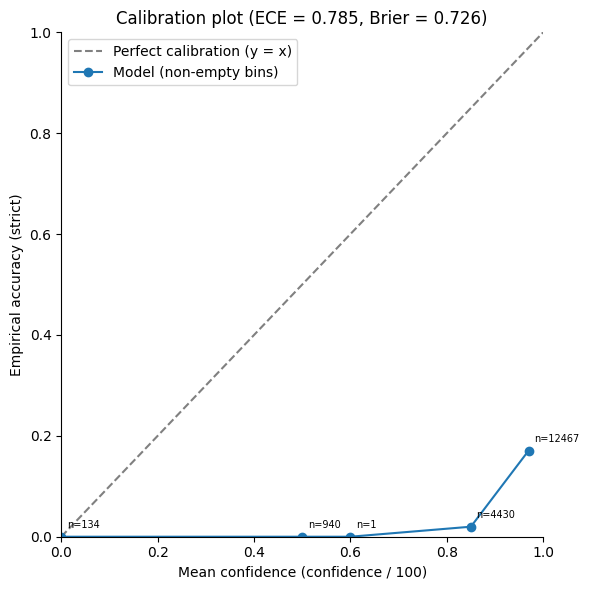


E. CONFIDENCE BY VARIANT
        variant  n_valid_conf  mean_confidence  median_confidence  std_confidence  min_confidence  max_confidence  accuracy_strict  mean_conf_correct  mean_conf_incorrect  n_pairs_with_original  mean_shift_from_original  median_shift_from_original  mean_abs_shift_from_original
       original          2994           90.620             95.000          15.131           0.000         100.000            0.139             97.807               89.463                    NaN                       NaN                         NaN                           NaN
   paraphrase_1          2995           91.491             95.000          14.410           0.000         100.000            0.121             98.232               90.564               2989.000                     0.895                       0.000                         7.272
   paraphrase_2          2989           89.997             95.000          13.316           0.000         100.000            0.113          

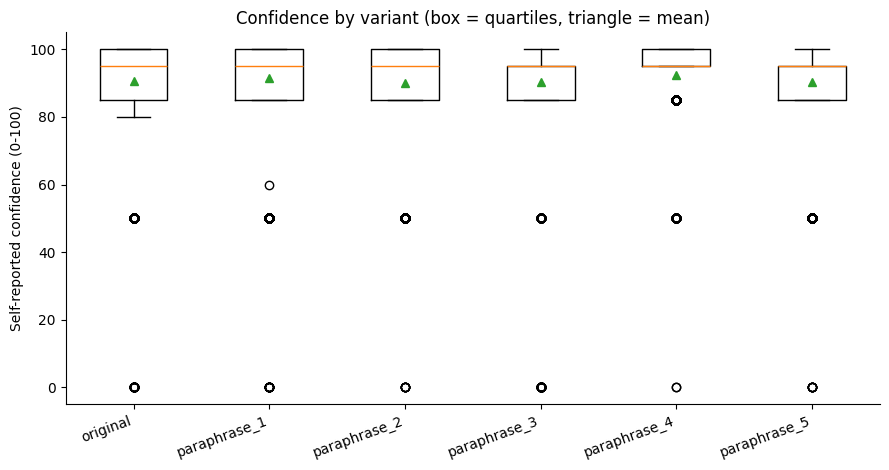


F. QUESTION-LEVEL CONFIDENCE STABILITY
Saved: /content/drive/MyDrive/Research3/results/phase5_question_confidence_stability.csv
                    measure  n_questions   mean  median    std   min   p10   p25    p75    p90    p95     max
 confidence_range (max-min)         3000 17.688  10.000 21.058 0.000 0.000 5.000 15.000 50.000 50.000 100.000
confidence_std (6 variants)         3000  7.536   5.164  8.749 0.000 0.000 2.582  6.831 19.748 23.875  53.890
 mean_abs_dev_from_original         2994  7.263   4.000 11.081 0.000 0.000 2.000  8.000 17.000 28.000  96.000
Questions with confidence range > 0: 84.27%
Questions with confidence range >= 10: 65.47%
Questions with confidence range >= 20: 20.20%
Questions with confidence range >= 30: 20.17%
Saved: /content/drive/MyDrive/Research3/figures/phase5_confidence_stability_distribution.png


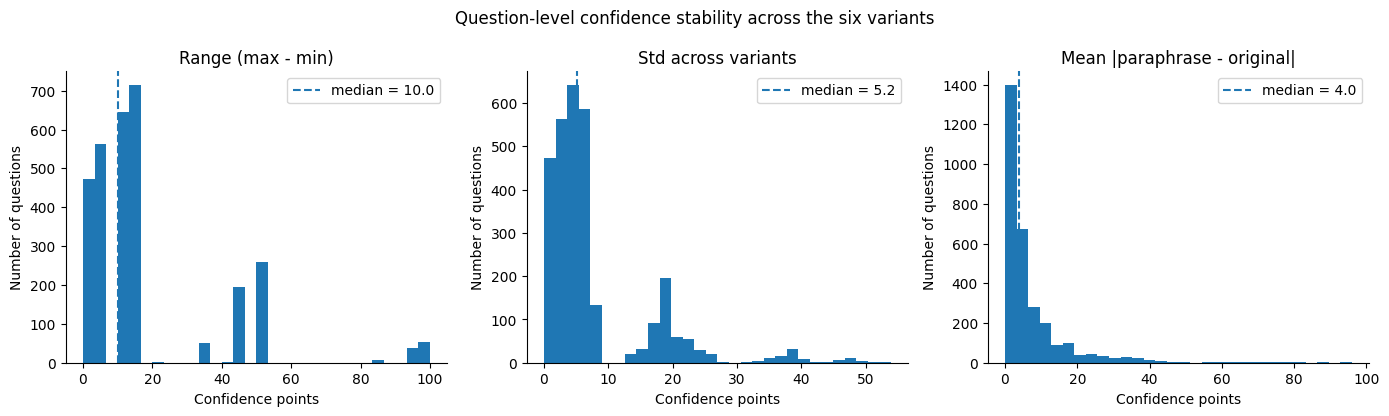


G. CONFIDENCE INSTABILITY vs ANSWER AND CORRECTNESS CHANGES (associations only, no causal claim)
Questions with at least 2 valid confidences and at least 1 valid original-paraphrase pair: 2994
            stability_group  n_questions  mean_confidence_range  mean_answer_flip_rate  pct_with_any_answer_flip  mean_correctness_flip_rate  pct_with_any_correctness_flip  mean_distinct_answers
        stable (range < 10)         1036                  2.722                  0.496                    85.039                       0.075                         24.614                  3.129
moderate (10 <= range < 30)         1355                 12.638                  0.794                    99.557                       0.049                         12.030                  4.581
        large (range >= 30)          603                 54.685                  0.884                   100.000                       0.008                          1.658                  5.109
              all question

In [179]:
# ======================= D. Calibration =======================
# The calibration table (10 equal-width bins, counts, mean confidence, empirical accuracy, absolute gap) was saved in 5.5
# as phase5_calibration_bins.csv. It is verified and reused here, not recomputed under another definition.
assert os.path.exists(f"{RESULTS_DIR}/phase5_calibration_bins.csv"), "Run cell 5.5 first."
_b = np.minimum(np.floor(cdf["conf"].to_numpy() / 10).astype(int), 9)
_ece = 0.0
for k in range(10):
    m = _b == k
    if m.any():
        _ece += m.mean() * abs(cdf["y"].to_numpy()[m].mean() - cdf["p"].to_numpy()[m].mean())
assert abs(_ece - ECE) < 1e-12, "Independent ECE recomputation does not match 5.5."
assert abs(float(((cdf["conf"] / 100 - cdf["y"]) ** 2).mean()) - BRIER) < 1e-12, "Brier mismatch."

acc_c = float(cdf["y"].mean())
mean_p = float(cdf["p"].mean())
brier_const = acc_c * (1 - acc_c)
p5_header("D. CALIBRATION (confidence/100 used as a probability-like score)")
print("Bins: [0,10), [10,20), ..., [80,90), [90,100]; ECE = sum(bin_fraction * |accuracy - mean_confidence|)")
print(calib.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nECE (10 equal-width bins): {ECE:.4f}")
print(f"Brier score:               {BRIER:.4f}  (lower is better)")
print(f"Reference Brier of a constant forecast equal to overall accuracy: {brier_const:.4f}")
print(f"Mean stated probability {mean_p:.4f} vs observed accuracy {acc_c:.4f} (difference {mean_p - acc_c:+.4f})")
for k, v, nt in [("ece_10_equal_width_bins", ECE, "documented binning; self-reported confidence/100"),
                 ("brier_score", BRIER, "mean (confidence/100 - correct)^2; lower is better"),
                 ("brier_reference_constant_forecast", brier_const, "Brier of always forecasting the overall accuracy (reference only)"),
                 ("mean_stated_probability", mean_p, "mean confidence/100"),
                 ("observed_accuracy_on_confidence_set", acc_c, "strict accuracy on responses with valid confidence"),
                 ("mean_confidence_minus_accuracy", mean_p - acc_c, "positive = stated confidence higher than observed accuracy")]:
    p5x_add("CALIBRATION (measured)", k, float(v), nt)

ne = calib[calib["count"] > 0]
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration (y = x)")
ax.plot(ne["mean_confidence"], ne["empirical_accuracy"], marker="o", label="Model (non-empty bins)")
for _, r in ne.iterrows():
    ax.annotate(f"n={int(r['count'])}", (r["mean_confidence"], r["empirical_accuracy"]), textcoords="offset points",
                xytext=(4, 6), fontsize=7)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean confidence (confidence / 100)")
ax.set_ylabel("Empirical accuracy (strict)")
ax.set_title(f"Calibration plot (ECE = {ECE:.3f}, Brier = {BRIER:.3f})")
ax.legend(loc="upper left")
fig.tight_layout()
p5_save_fig(fig, "phase5_calibration_plot.png")
plt.show()

# ======================= E. Confidence by variant =======================
p5_header("E. CONFIDENCE BY VARIANT")
rows = []
for v in VARIANTS:
    d = cdf[cdf["variant"] == v]
    r = {"variant": v, "n_valid_conf": len(d), "mean_confidence": d["conf"].mean(), "median_confidence": d["conf"].median(),
         "std_confidence": d["conf"].std(), "min_confidence": d["conf"].min(), "max_confidence": d["conf"].max(),
         "accuracy_strict": d["correct"].mean(),
         "mean_conf_correct": d.loc[d["correct"], "conf"].mean(), "mean_conf_incorrect": d.loc[~d["correct"], "conf"].mean()}
    if v != "original":
        sh = pp.loc[pp["variant"] == v, "delta"]
        r.update(n_pairs_with_original=len(sh), mean_shift_from_original=sh.mean(), median_shift_from_original=sh.median(),
                 mean_abs_shift_from_original=sh.abs().mean())
    rows.append(r)
d = cdf[cdf["variant"] != "original"]
rows.append({"variant": "all_paraphrases", "n_valid_conf": len(d), "mean_confidence": d["conf"].mean(),
             "median_confidence": d["conf"].median(), "std_confidence": d["conf"].std(), "min_confidence": d["conf"].min(),
             "max_confidence": d["conf"].max(), "accuracy_strict": d["correct"].mean(),
             "mean_conf_correct": d.loc[d["correct"], "conf"].mean(), "mean_conf_incorrect": d.loc[~d["correct"], "conf"].mean(),
             "n_pairs_with_original": len(pp), "mean_shift_from_original": pp["delta"].mean(),
             "median_shift_from_original": pp["delta"].median(), "mean_abs_shift_from_original": pp["abs_delta"].mean()})
variant_conf = pd.DataFrame(rows)
print(variant_conf.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
p5_save_table(variant_conf, "phase5_variant_confidence.csv")
allp = variant_conf[variant_conf["variant"] == "all_paraphrases"].iloc[0]
p5x_add("ORIGINAL vs PARAPHRASE (measured)", "mean_shift_paraphrase_minus_original", float(allp["mean_shift_from_original"]), "points; positive = paraphrase more confident")
p5x_add("ORIGINAL vs PARAPHRASE (measured)", "median_shift_paraphrase_minus_original", float(allp["median_shift_from_original"]), "points")
p5x_add("ORIGINAL vs PARAPHRASE (measured)", "mean_abs_shift_from_original", float(allp["mean_abs_shift_from_original"]), "points; mean |paraphrase - original| over all pairs")
p5x_add("ORIGINAL vs PARAPHRASE (measured)", "pairs_used", int(allp["n_pairs_with_original"]), "pairs with valid confidence on both sides")

fig, ax = plt.subplots(figsize=(9, 4.8))
data = [cdf.loc[cdf["variant"] == v, "conf"].to_numpy() for v in VARIANTS]
ax.boxplot(data, showmeans=True)
ax.set_xticklabels(VARIANTS, rotation=20, ha="right")
ax.set_ylabel("Self-reported confidence (0-100)")
ax.set_title("Confidence by variant (box = quartiles, triangle = mean)")
fig.tight_layout()
p5_save_fig(fig, "phase5_confidence_by_variant.png")
plt.show()

# ======================= F. Question-level confidence stability =======================
p5_header("F. QUESTION-LEVEL CONFIDENCE STABILITY")
qs = pd.DataFrame(index=pd.Index(all_ids, name="question_id"))
for v in VARIANTS:
    qs[f"conf_{v}"] = conf_wide[v]
qs["n_valid_conf"] = conf_wide.notna().sum(axis=1).astype(int)
ok2 = qs["n_valid_conf"] >= 2
qs["mean_confidence"] = conf_wide.mean(axis=1).where(ok2)
qs["confidence_range"] = (conf_wide.max(axis=1) - conf_wide.min(axis=1)).where(ok2)           # max - min over the variants
qs["confidence_std"] = conf_wide.std(axis=1, ddof=1).where(ok2)                              # sample std over the variants
dev = conf_wide[PARAPHRASES].sub(conf_wide["original"], axis=0).abs()
qs["n_pairs_with_original"] = dev.notna().sum(axis=1).astype(int)
qs["mean_abs_dev_from_original"] = dev.mean(axis=1).where(qs["n_pairs_with_original"] >= 1)  # mean |paraphrase - original|

gp = pp.groupby("question_id")
qs["n_valid_pairs"] = gp.size().reindex(all_ids).fillna(0).astype(int).to_numpy()
qs["answer_flips"] = gp["flip"].sum().reindex(all_ids).fillna(0).astype(int).to_numpy()
qs["correctness_flips"] = gp["correct_changed"].sum().reindex(all_ids).fillna(0).astype(int).to_numpy()
den = qs["n_valid_pairs"].where(qs["n_valid_pairs"] > 0)
qs["answer_flip_rate"] = qs["answer_flips"] / den
qs["correctness_flip_rate"] = qs["correctness_flips"] / den
qs["num_distinct_answers"] = qtab["num_distinct_answers"].reindex(all_ids).to_numpy()
qs["num_correct_variants"] = qstab["num_correct_variants"].reindex(all_ids).to_numpy()

lo, hi = STAB_GROUP_EDGES
qs["stability_group"] = np.select(
    [qs["confidence_range"].isna(), qs["confidence_range"] < lo, qs["confidence_range"] < hi],
    ["n/a (<2 valid confidences)", f"stable (range < {lo})", f"moderate ({lo} <= range < {hi})"],
    default=f"large (range >= {hi})")
p5_save_table(qs.reset_index(), "phase5_question_confidence_stability.csv")

PCTS = [10, 25, 75, 90, 95]
stab_rows = []
for col, label in [("confidence_range", "confidence_range (max-min)"), ("confidence_std", "confidence_std (6 variants)"),
                   ("mean_abs_dev_from_original", "mean_abs_dev_from_original")]:
    s = qs[col].dropna()
    r = {"measure": label, "n_questions": len(s), "mean": s.mean(), "median": s.median(), "std": s.std(), "min": s.min()}
    r.update({f"p{p}": np.percentile(s, p) for p in PCTS})
    r["max"] = s.max()
    stab_rows.append(r)
    for k, val in r.items():
        if k not in ("measure", "n_questions"):
            p5x_add("QUESTION-LEVEL STABILITY (measured)", f"{label}: {k}", float(val), "points on the 0-100 scale; computed over questions")
    p5x_add("QUESTION-LEVEL STABILITY (measured)", f"{label}: n_questions", int(r["n_questions"]), "")
stab_stats = pd.DataFrame(stab_rows)
print(stab_stats.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
rg = qs["confidence_range"].dropna()
for t in (0, 10, 20, 30):
    share = float(100 * (rg > 0).mean()) if t == 0 else float(100 * (rg >= t).mean())
    print(f"Questions with confidence range {'> 0' if t == 0 else '>= ' + str(t)}: {share:.2f}%")
    p5x_add("QUESTION-LEVEL STABILITY (measured)", f"pct_questions_range_{'gt_0' if t == 0 else 'ge_' + str(t)}", share, "analysis threshold, not a claim of 'large'")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (col, ttl) in zip(axes, [("confidence_range", "Range (max - min)"), ("confidence_std", "Std across variants"),
                                  ("mean_abs_dev_from_original", "Mean |paraphrase - original|")]):
    s = qs[col].dropna()
    ax.hist(s, bins=30)
    ax.axvline(s.median(), linestyle="--", label=f"median = {s.median():.1f}")
    ax.set_title(ttl)
    ax.set_xlabel("Confidence points")
    ax.set_ylabel("Number of questions")
    ax.legend()
fig.suptitle("Question-level confidence stability across the six variants")
fig.tight_layout()
p5_save_fig(fig, "phase5_confidence_stability_distribution.png")
plt.show()

# ======================= G. Confidence instability vs answer / correctness changes (descriptive) =======================
p5_header("G. CONFIDENCE INSTABILITY vs ANSWER AND CORRECTNESS CHANGES (associations only, no causal claim)")
gq = qs[qs["confidence_range"].notna() & (qs["n_valid_pairs"] > 0)].copy()
GROUP_ORDER = [f"stable (range < {lo})", f"moderate ({lo} <= range < {hi})", f"large (range >= {hi})"]
g_rows = []
for name, d in [(g, gq[gq["stability_group"] == g]) for g in GROUP_ORDER] + [("all questions", gq)]:
    g_rows.append({"stability_group": name, "n_questions": len(d),
                   "mean_confidence_range": d["confidence_range"].mean() if len(d) else np.nan,
                   "mean_answer_flip_rate": d["answer_flip_rate"].mean() if len(d) else np.nan,
                   "pct_with_any_answer_flip": 100 * (d["answer_flips"] > 0).mean() if len(d) else np.nan,
                   "mean_correctness_flip_rate": d["correctness_flip_rate"].mean() if len(d) else np.nan,
                   "pct_with_any_correctness_flip": 100 * (d["correctness_flips"] > 0).mean() if len(d) else np.nan,
                   "mean_distinct_answers": d["num_distinct_answers"].mean() if len(d) else np.nan})
inst_tbl = pd.DataFrame(g_rows)
print(f"Questions with at least 2 valid confidences and at least 1 valid original-paraphrase pair: {len(gq)}")
print(inst_tbl.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
p5_save_table(inst_tbl, "phase5_instability_vs_flips.csv")

pp["change_type"] = np.select([~pp["flip"], pp["flip"] & ~pp["correct_changed"]],
                              ["same answer", "answer changed, same correctness"], default="correctness changed")
CT_ORDER = ["same answer", "answer changed, same correctness", "correctness changed"]
c_rows = []
for name, d in [(c, pp[pp["change_type"] == c]) for c in CT_ORDER] + [("all pairs", pp)]:
    c_rows.append({"original_vs_paraphrase": name, "n_pairs": len(d),
                   "mean_abs_confidence_shift": d["abs_delta"].mean() if len(d) else np.nan,
                   "median_abs_confidence_shift": d["abs_delta"].median() if len(d) else np.nan,
                   "mean_signed_shift": d["delta"].mean() if len(d) else np.nan,
                   "pct_pairs_with_any_shift": 100 * (d["delta"] != 0).mean() if len(d) else np.nan})
shift_by_change = pd.DataFrame(c_rows)
print("\nConfidence shift (paraphrase - original) by what happened to the answer:")
print(shift_by_change.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
p5_save_table(shift_by_change, "phase5_confidence_shift_by_change_type.csv")

## 5.14 H-J: statistical tests, summary file, final validation and Phase 5 report
Each test answers one stated question (`phase5_statistical_tests.csv`):
- **H1:** is confidence on each paraphrase different from the original? Wilcoxon signed-rank on paired differences, rank-biserial effect size, Holm correction over the 5 paraphrases.
- **H2:** do strict-correct responses have higher confidence than incorrect ones? Mann-Whitney U with AUROC and point-biserial r.
- **H3 / H4:** is a larger confidence range associated with more answer flips / correctness flips? Spearman rho (question level).
- **H5:** is the confidence shift larger when the answer changed? Mann-Whitney U with AUROC.

Responses from the same question are not independent, so p-values are descriptive. All results are associations, not causal claims. `phase5_confidence_summary.csv` separates **measured** results from the one **sensitivity** row (audit-adjusted ~16.60%), which is never used in any calculation. At the end the raw Phase 3 CSV is re-hashed and the strict labels re-checked.

In [180]:
# ======================= H. Statistical analysis =======================
# Every test answers one stated question. p-values are descriptive: responses from the same question are not independent.
CAVEAT_DEP = "observations from the same question are not independent; treat p-values as descriptive"


def holm_adjust(pvals):
    p = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    m = len(p)
    adj = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adj[idx] = min(1.0, running)
    return adj


def add_test(**kw):
    base = {"test_id": None, "family": None, "research_question": None, "test": None, "n": None, "statistic": np.nan,
            "p_value": np.nan, "p_holm": np.nan, "effect_size_name": None, "effect_size": np.nan,
            "effect_size_2_name": None, "effect_size_2": np.nan, "descriptive": None, "caveat": None}
    base.update(kw)
    p5x_tests.append(base)


# ---- H1: paired original vs paraphrase confidence (Wilcoxon signed-rank, Holm over the 5 paraphrases) ----
wil_idx = []
for k, v in enumerate(PARAPHRASES, start=1):
    d = pp.loc[pp["variant"] == v, "delta"].to_numpy()
    nz = d[d != 0]
    if len(nz) == 0:
        add_test(test_id=f"H1.{k}", family="H1 paired confidence (Holm over 5)", test="Wilcoxon signed-rank (two-sided)",
                 research_question=f"Is confidence on {v} different from the original?", n=len(d),
                 descriptive="all differences are zero", caveat=CAVEAT_DEP)
        continue
    w = sps.wilcoxon(d, zero_method="wilcox", alternative="two-sided")
    ranks = sps.rankdata(np.abs(nz))
    r_rb = float((ranks[nz > 0].sum() - ranks[nz < 0].sum()) / ranks.sum())     # matched-pairs rank-biserial correlation
    add_test(test_id=f"H1.{k}", family="H1 paired confidence (Holm over 5)", test="Wilcoxon signed-rank (two-sided)",
             research_question=f"Is confidence on {v} different from the original question's confidence?",
             n=len(d), statistic=float(w.statistic), p_value=float(w.pvalue),
             effect_size_name="rank-biserial r (paraphrase - original; + = paraphrase higher)", effect_size=r_rb,
             effect_size_2_name="median paired difference (points)", effect_size_2=float(np.median(d)),
             descriptive=f"mean diff {d.mean():+.3f}; {100 * (d == 0).mean():.1f}% zero differences (dropped by the test)",
             caveat="zero differences dropped (Wilcoxon method); " + CAVEAT_DEP)
    wil_idx.append(len(p5x_tests) - 1)
if wil_idx:
    adj = holm_adjust([p5x_tests[i]["p_value"] for i in wil_idx])
    for i, a in zip(wil_idx, adj):
        p5x_tests[i]["p_holm"] = float(a)

# ---- H2: confidence of correct vs incorrect responses (Mann-Whitney U, AUROC, point-biserial) ----
xc, xi = c_conf.to_numpy(), i_conf.to_numpy()
mw = sps.mannwhitneyu(xc, xi, alternative="two-sided")
auroc = float(mw.statistic / (len(xc) * len(xi)))
pb = float(np.corrcoef(cdf["conf"].to_numpy(), cdf["y"].to_numpy())[0, 1])
add_test(test_id="H2", family="H2 confidence vs correctness", test="Mann-Whitney U (two-sided)",
         research_question="Do strict-correct responses have higher confidence than strict-incorrect responses?",
         n=len(xc) + len(xi), statistic=float(mw.statistic), p_value=float(mw.pvalue),
         effect_size_name="AUROC = P(conf_correct > conf_incorrect) + 0.5 P(tie)", effect_size=auroc,
         effect_size_2_name="point-biserial r (confidence, correct)", effect_size_2=pb,
         descriptive=f"mean {xc.mean():.2f} vs {xi.mean():.2f}; median {np.median(xc):.1f} vs {np.median(xi):.1f}; Cliff's delta {2 * auroc - 1:.3f}",
         caveat=CAVEAT_DEP + "; AUROC 0.5 = confidence does not separate correct from incorrect")

# ---- H3 / H4: question-level association of confidence instability with answer / correctness changes ----
for tid, col, text in [("H3", "answer_flip_rate", "answer flips (original vs paraphrase)"),
                       ("H4", "correctness_flip_rate", "correctness flips (original vs paraphrase)")]:
    sub = gq[["confidence_range", col]].dropna()
    if sub[col].nunique() > 1 and sub["confidence_range"].nunique() > 1:
        rho, p = sps.spearmanr(sub["confidence_range"], sub[col])
        rho, p = float(rho), float(p)
    else:
        rho, p = np.nan, np.nan
    add_test(test_id=tid, family="H3-H4 instability association", test="Spearman rank correlation",
             research_question=f"Is a larger confidence range across variants associated with a higher rate of {text}?",
             n=len(sub), statistic=rho, p_value=p, effect_size_name="Spearman rho", effect_size=rho,
             descriptive="questions with at least 2 valid confidences and 1 valid pair",
             caveat="association only, not causal; ties are common in both variables")

# ---- H5: pair-level shift size when the answer changes vs does not ----
a_flip = pp.loc[pp["flip"], "abs_delta"].to_numpy()
a_same = pp.loc[~pp["flip"], "abs_delta"].to_numpy()
if len(a_flip) > 0 and len(a_same) > 0:
    mw2 = sps.mannwhitneyu(a_flip, a_same, alternative="two-sided")
    auc2 = float(mw2.statistic / (len(a_flip) * len(a_same)))
    add_test(test_id="H5", family="H5 shift vs answer change", test="Mann-Whitney U (two-sided)",
             research_question="Is the absolute confidence shift larger for pairs where the answer changed than where it stayed the same?",
             n=len(a_flip) + len(a_same), statistic=float(mw2.statistic), p_value=float(mw2.pvalue),
             effect_size_name="AUROC = P(|shift| larger when answer changed) + 0.5 P(tie)", effect_size=auc2,
             effect_size_2_name="Cliff's delta", effect_size_2=2 * auc2 - 1,
             descriptive=f"median |shift| {np.median(a_flip):.1f} (changed, n={len(a_flip)}) vs {np.median(a_same):.1f} (same, n={len(a_same)})",
             caveat=CAVEAT_DEP + "; association only, not causal")

tests_df = pd.DataFrame(p5x_tests)
p5_header("H. STATISTICAL TESTS")
show_cols = ["test_id", "test", "n", "statistic", "p_value", "p_holm", "effect_size_name", "effect_size", "descriptive"]
print(tests_df[show_cols].to_string(index=False, float_format=lambda x: f"{x:.4g}"))
p5_save_table(tests_df, "phase5_statistical_tests.csv")

# ======================= I. Summary file =======================
p5x_add("PRIMARY (measured)", "valid_responses", n_valid, "successful responses")
p5x_add("PRIMARY (measured)", "strict_correct", n_correct, "Phase 4 strict normalized exact match (unchanged)")
p5x_add("PRIMARY (measured)", "strict_incorrect", n_valid - n_correct, "")
p5x_add("PRIMARY (measured)", "strict_accuracy", overall_accuracy, "PRIMARY factual correctness result")
p5x_add("PRIMARY (measured)", "responses_with_valid_confidence", len(cdf), "")
p5x_add("SENSITIVITY (not measured here)", "audit_adjusted_accuracy_approx", 0.1660, AUDIT_SENSITIVITY_NOTE)
summary_df = pd.DataFrame(p5x_summary)
summary_df = pd.concat([summary_df[summary_df["section"].str.startswith("PRIMARY")],
                        summary_df[~summary_df["section"].str.startswith("PRIMARY")]], ignore_index=True)
p5_save_table(summary_df, "phase5_confidence_summary.csv")

# ======================= J. Final validation =======================
assert hashlib.sha256(open(RESULTS_PATH, "rb").read()).hexdigest() == P5X_SHA_BEFORE, "Raw Phase 3 CSV changed!"
assert os.path.getmtime(RESULTS_PATH) == P5X_MTIME_BEFORE, "Raw Phase 3 CSV was overwritten!"
assert int(vdf["correct"].sum()) == P5X_EXPECTED["correct"] and len(vdf) == P5X_EXPECTED["valid"], "Strict labels changed."
assert (cdf["correct"] == vdf.loc[cdf.index, "correct"]).all()
for _p in p5_files[P5X_START:]:
    assert os.path.abspath(_p) != os.path.abspath(RESULTS_PATH)
    assert os.path.exists(_p), f"Missing output: {_p}"

# ======================= Final printed report =======================
print("\n" + "=" * 60)
print("PHASE 5 REPORT: CONFIDENCE ANALYSIS AND CALIBRATION")
print("=" * 60)
print(f"\nModel: {MODEL_NAME_P4} | questions: {len(all_ids)} | variants: {len(VARIANTS)} | valid responses: {n_valid} | with valid confidence: {len(cdf)}")
print("\n[MEASURED] PRIMARY STRICT RESULT")
print(f"  Strict accuracy: {n_correct}/{n_valid} = {100 * overall_accuracy:.2f}%")
print("\n[MEASURED] CONFIDENCE STATISTICS (0-100)")
print(f"  mean {conf_all.mean():.2f} | median {conf_all.median():.2f} | std {conf_all.std():.2f} | min {conf_all.min():g} | max {conf_all.max():g}")
print(f"  original mean {conf_orig_s.mean():.2f} | paraphrases mean {conf_para_s.mean():.2f}")
print("\n[MEASURED] CORRECT vs INCORRECT")
print(f"  correct   mean {mc:.2f} | median {medc:.2f}")
print(f"  incorrect mean {mi:.2f} | median {medi:.2f}")
print(f"  mean difference {mc - mi:.2f} points | AUROC {auroc:.3f}")
print("  Incorrect answers with confidence >= T: " + ", ".join(f">={r['confidence_threshold']}: {r['pct_of_incorrect']:.1f}%" for r in thr_rows))
print("\n[MEASURED] HIGH-CONFIDENCE ERRORS")
for r in hce_rows:
    print(f"  conf >= {r['threshold']}: {r['n_incorrect']} incorrect = {r['pct_of_all_incorrect']:.2f}% of incorrect, {r['pct_of_all_valid_responses']:.2f}% of valid responses")
print("\n[MEASURED] CALIBRATION")
print(f"  ECE (10 equal-width bins): {ECE:.4f} | Brier: {BRIER:.4f} (constant-forecast reference {brier_const:.4f})")
print(f"  mean stated probability {mean_p:.4f} vs accuracy {acc_c:.4f}")
print("\n[MEASURED] CONFIDENCE STABILITY (question level)")
for _, r in stab_stats.iterrows():
    print(f"  {r['measure']}: mean {r['mean']:.2f} | median {r['median']:.2f} | std {r['std']:.2f} | p90 {r['p90']:.2f} (n={int(r['n_questions'])})")
print("\n[MEASURED] ORIGINAL vs PARAPHRASE CONFIDENCE")
print(f"  mean shift (paraphrase - original): {allp['mean_shift_from_original']:+.3f} | mean absolute shift: {allp['mean_abs_shift_from_original']:.3f} ({int(allp['n_pairs_with_original'])} pairs)")
print("\n[ASSOCIATIONS, NOT CAUSAL] TEST RESULTS")
for _, r in tests_df.iterrows():
    ph = "" if pd.isna(r["p_holm"]) else f" | p_holm = {r['p_holm']:.4g}"
    print(f"  {r['test_id']:5s} {r['test']}: p = {r['p_value']:.4g}{ph} | {r['effect_size_name']} = {r['effect_size']:.3f}")
print("\n[SENSITIVITY ONLY, NOT MEASURED HERE]")
print("  Audit-adjusted accuracy ~16.60% is a sensitivity estimate. It was not used in any calculation above and does not replace the strict 12.35%.")
print("\nSaved by this supplement:")
for _p in p5_files[P5X_START:]:
    print("  ", _p)
print("\nPhase 5 confidence analysis completed and validated. Phase 6 not started.")


H. STATISTICAL TESTS
test_id                             test     n  statistic    p_value    p_holm                                               effect_size_name  effect_size                                                    descriptive
   H1.1 Wilcoxon signed-rank (two-sided)  2989  3.617e+05  1.501e-06 3.527e-06 rank-biserial r (paraphrase - original; + = paraphrase higher)       0.1523 mean diff +0.895; 56.3% zero differences (dropped by the test)
   H1.2 Wilcoxon signed-rank (two-sided)  2983  3.443e+05  3.639e-07 1.455e-06 rank-biserial r (paraphrase - original; + = paraphrase higher)      -0.1626 mean diff -0.660; 57.0% zero differences (dropped by the test)
   H1.3 Wilcoxon signed-rank (two-sided)  2993  3.608e+05     0.2327    0.2327 rank-biserial r (paraphrase - original; + = paraphrase higher)     -0.03897 mean diff -0.383; 59.1% zero differences (dropped by the test)
   H1.4 Wilcoxon signed-rank (two-sided)  2993  3.674e+05  2.841e-08 1.421e-07 rank-biserial r (paraphrase

# Phase 6: Confidence-Conditioned Abstention, Coverage, Selective Risk and Abstention Stability

This phase analyses the saved Phase 3 outputs only (via the Phase 4/5 objects in memory). **No model is loaded, no inference is run, no Phase 3/4/5 file is modified, and no new correctness label is created.** Correctness is exactly the Phase 4 `is_correct` label.

**Important:** the model was never asked to abstain in Phase 3. What we study here is **post-hoc, confidence-conditioned (threshold-based) abstention** applied to the model's *self-reported* confidence:

`confidence >= T  ->  answer`, `confidence < T  ->  abstain`

Thresholds: 0 (baseline, no abstention), 50, 60, 70, 80, 90.

- **Coverage** = answered / valid
- **Selective accuracy** = correct among answered / answered
- **Selective risk** = incorrect among answered / answered = 1 - selective accuracy

We do not assume that a higher threshold lowers risk, and we do not treat confidence as a true probability. Whether it helps is tested empirically. This phase is descriptive: no significance tests.

In [181]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------- PHASE 6 CONFIGURATION ----------------
# The Phase 3 CSV path is RESULTS_PATH from the Phase 4 config cell (change it there if needed).
THRESHOLDS = [50, 60, 70, 80, 90]
ALL_THRESHOLDS = [0] + THRESHOLDS     # 0 = baseline (every valid response is answered)
N_EXAMPLES = 5

_needed = ["res", "cdf", "conf_wide", "all_ids", "VARIANTS", "PARAPHRASES", "MODEL_NAME_P4",
           "RESULTS_PATH", "RESULTS_DIR", "FIGURES_DIR", "is_missing", "is_nonnumeric",
           "is_out_of_range", "n_parse_errors", "n_inference_errors", "q_pos", "v_pos", "acc_conf_set"]
_missing_names = [n for n in _needed if n not in globals()]
if _missing_names:
    raise RuntimeError(f"Run the Phase 4 and Phase 5 cells first. Missing: {_missing_names}")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)
p6_files = []   # every file written by Phase 6 (all names start with 'phase6_', nothing is overwritten)


def p6_save_table(table, filename):
    path = f"{RESULTS_DIR}/{filename}"
    table.to_csv(path, index=False)
    p6_files.append(path)
    print(f"Saved: {path}")


def p6_save_fig(fig, filename):
    path = f"{FIGURES_DIR}/{filename}"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    p6_files.append(path)
    print(f"Saved: {path}")


def p6_header(title):
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}")


print(f"Phase 6 uses Phase 4 correctness labels (source file: {RESULTS_PATH})")
print(f"Thresholds: {ALL_THRESHOLDS} | Tables -> {RESULTS_DIR} | Figures -> {FIGURES_DIR}")

Phase 6 uses Phase 4 correctness labels (source file: /content/drive/MyDrive/Research3/results/phase3_qwen25_7b_inference.csv)
Thresholds: [0, 50, 60, 70, 80, 90] | Tables -> /content/drive/MyDrive/Research3/results | Figures -> /content/drive/MyDrive/Research3/figures


## 6.1 Valid rows and exclusions

A row is used only if `status == "success"` **and** its confidence is a valid number in [0, 100]. Excluded rows are counted by reason (parse error, inference error, missing confidence, invalid confidence). Invalid/missing confidence is never turned into 0.

In [182]:
succ = res["status"] == "success"
succ_missing_conf = int((succ & is_missing).sum())
succ_invalid_conf = int((succ & (is_nonnumeric | is_out_of_range)).sum())

vd = cdf[["question_id", "variant", "question", "answer", "gold_answer", "conf", "correct"]].copy()
n_valid = len(vd)
n_excluded = len(res) - n_valid

p6_header("VALID ROWS AND EXCLUSIONS")
print(f"Total Phase 3 rows:                          {len(res)}")
print(f"Valid responses used in Phase 6:             {n_valid}")
print(f"Excluded - parse errors:                     {n_parse_errors}")
print(f"Excluded - inference errors:                 {n_inference_errors}")
print(f"Excluded - success but missing confidence:   {succ_missing_conf}")
print(f"Excluded - success but invalid confidence:   {succ_invalid_conf}")
print(f"Total excluded (invalid/failed):             {n_excluded}")
assert n_valid + n_parse_errors + n_inference_errors + succ_missing_conf + succ_invalid_conf == len(res), \
    "Exclusion counts do not add up to the total number of rows."
assert abs(vd["correct"].mean() - acc_conf_set) < 1e-12, "Accuracy differs from Phase 5."
print(f"\nBaseline accuracy (matches Phase 5): {vd['correct'].mean():.4f}")


VALID ROWS AND EXCLUSIONS
Total Phase 3 rows:                          18000
Valid responses used in Phase 6:             17972
Excluded - parse errors:                     28
Excluded - inference errors:                 0
Excluded - success but missing confidence:   0
Excluded - success but invalid confidence:   0
Total excluded (invalid/failed):             28

Baseline accuracy (matches Phase 5): 0.1235


## 6.2 Threshold analysis (baseline T=0 plus 50/60/70/80/90)

For each threshold: answered, abstained, coverage, abstention rate, correct/incorrect among answered, selective accuracy and selective risk. Risk is computed over **answered** responses only, never over abstained ones.

In [183]:
def selective_stats(d, T):
    n_v = len(d)
    ans = d[d["conf"] >= T]
    n_ans = len(ans)
    n_cor = int(ans["correct"].sum())
    n_inc = n_ans - n_cor
    return {
        "threshold": T,
        "total_valid": n_v,
        "answered": n_ans,
        "abstained": n_v - n_ans,
        "coverage": n_ans / n_v if n_v else np.nan,
        "abstention_rate": (n_v - n_ans) / n_v if n_v else np.nan,
        "correct_answered": n_cor,
        "incorrect_answered": n_inc,
        "selective_accuracy": n_cor / n_ans if n_ans else np.nan,
        "selective_risk": n_inc / n_ans if n_ans else np.nan,
    }


thr_tbl = pd.DataFrame([selective_stats(vd, T) for T in ALL_THRESHOLDS])
assert thr_tbl.loc[thr_tbl["threshold"] == 0, "answered"].iloc[0] == n_valid, "Baseline must answer every valid row."

baseline = thr_tbl[thr_tbl["threshold"] == 0].iloc[0]
p6_header("THRESHOLD RESULTS")
print(thr_tbl.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
p6_save_table(thr_tbl, "phase6_threshold_results.csv")

p6_header("THRESHOLD SUMMARY TABLE")
print(f"{'Threshold':>9} | {'Valid':>6} | {'Answered':>8} | {'Abstained':>9} | {'Coverage':>8} | "
      f"{'Abstention':>10} | {'Sel. Acc':>8} | {'Sel. Risk':>9}")
print("-" * 92)
for _, r in thr_tbl.iterrows():
    print(f"{int(r['threshold']):>9} | {int(r['total_valid']):>6} | {int(r['answered']):>8} | {int(r['abstained']):>9} | "
          f"{r['coverage']:>8.4f} | {r['abstention_rate']:>10.4f} | {r['selective_accuracy']:>8.4f} | {r['selective_risk']:>9.4f}")


THRESHOLD RESULTS
 threshold  total_valid  answered  abstained  coverage  abstention_rate  correct_answered  incorrect_answered  selective_accuracy  selective_risk
         0        17972     17972          0    1.0000           0.0000              2219               15753              0.1235          0.8765
        50        17972     17838        134    0.9925           0.0075              2219               15619              0.1244          0.8756
        60        17972     16898       1074    0.9402           0.0598              2219               14679              0.1313          0.8687
        70        17972     16897       1075    0.9402           0.0598              2219               14678              0.1313          0.8687
        80        17972     16897       1075    0.9402           0.0598              2219               14678              0.1313          0.8687
        90        17972     12467       5505    0.6937           0.3063              2131               1

## 6.3 Risk-coverage and accuracy-coverage curves

Each point is one threshold (0, 50, 60, 70, 80, 90) and is labelled with its threshold. Only these six operating points exist, so the lines just connect them in threshold order.

Saved: /content/drive/MyDrive/Research3/figures/phase6_risk_coverage_curve.png


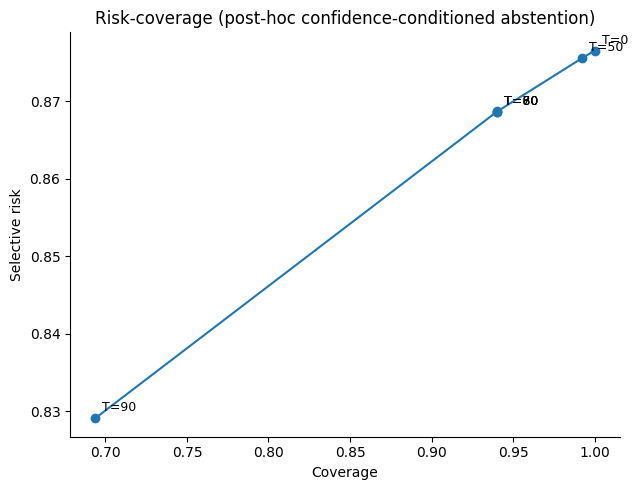

Saved: /content/drive/MyDrive/Research3/figures/phase6_accuracy_coverage_curve.png


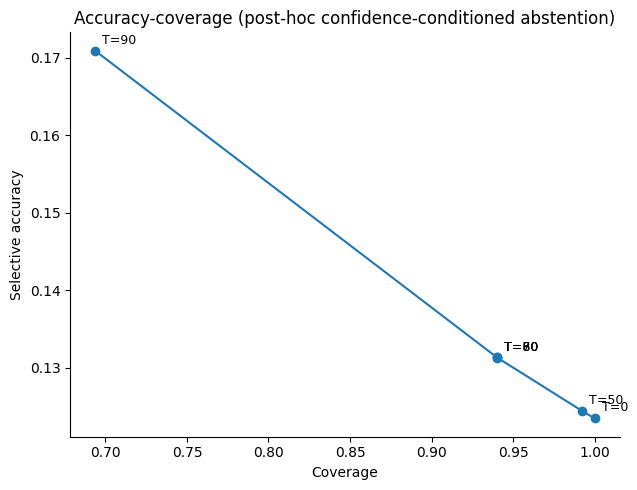

Saved: /content/drive/MyDrive/Research3/figures/phase6_abstention_rate_by_threshold.png


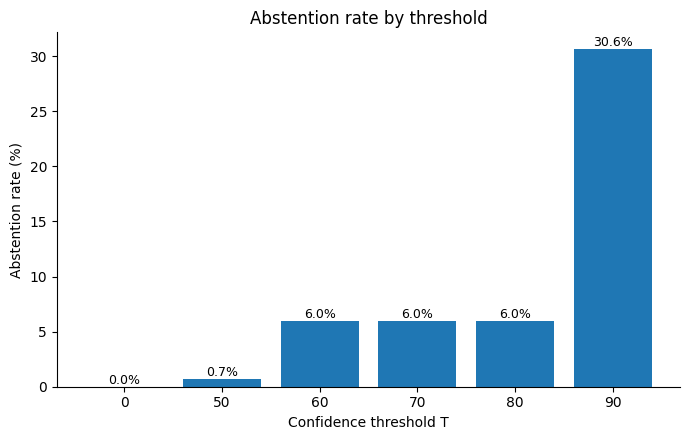

Saved: /content/drive/MyDrive/Research3/figures/phase6_selective_risk_by_threshold.png


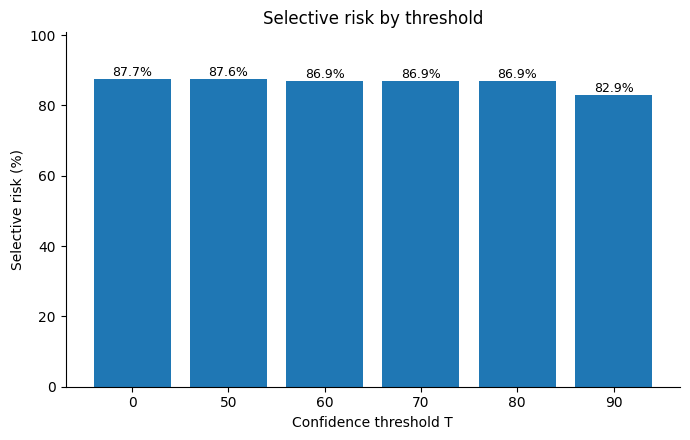

In [184]:
plot_tbl = thr_tbl.dropna(subset=["selective_risk"])

# ---- Plot 1: risk-coverage ----
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(plot_tbl["coverage"], plot_tbl["selective_risk"], marker="o")
for _, r in plot_tbl.iterrows():
    ax.annotate(f"T={int(r['threshold'])}", (r["coverage"], r["selective_risk"]),
                textcoords="offset points", xytext=(5, 5), fontsize=9)
ax.set_xlabel("Coverage")
ax.set_ylabel("Selective risk")
ax.set_title("Risk-coverage (post-hoc confidence-conditioned abstention)")
fig.tight_layout()
p6_save_fig(fig, "phase6_risk_coverage_curve.png")
plt.show()

# ---- Plot 2: accuracy-coverage ----
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(plot_tbl["coverage"], plot_tbl["selective_accuracy"], marker="o")
for _, r in plot_tbl.iterrows():
    ax.annotate(f"T={int(r['threshold'])}", (r["coverage"], r["selective_accuracy"]),
                textcoords="offset points", xytext=(5, 5), fontsize=9)
ax.set_xlabel("Coverage")
ax.set_ylabel("Selective accuracy")
ax.set_title("Accuracy-coverage (post-hoc confidence-conditioned abstention)")
fig.tight_layout()
p6_save_fig(fig, "phase6_accuracy_coverage_curve.png")
plt.show()

# ---- Plot 3: abstention rate by threshold ----
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar([str(t) for t in thr_tbl["threshold"]], 100 * thr_tbl["abstention_rate"])
for b, v in zip(bars, 100 * thr_tbl["abstention_rate"]):
    ax.annotate(f"{v:.1f}%", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Confidence threshold T")
ax.set_ylabel("Abstention rate (%)")
ax.set_title("Abstention rate by threshold")
fig.tight_layout()
p6_save_fig(fig, "phase6_abstention_rate_by_threshold.png")
plt.show()

# ---- Plot 5: selective risk by threshold ----
fig, ax = plt.subplots(figsize=(7, 4.5))
risk_vals = 100 * thr_tbl["selective_risk"].fillna(0)
bars = ax.bar([str(t) for t in thr_tbl["threshold"]], risk_vals)
for b, v in zip(bars, risk_vals):
    ax.annotate(f"{v:.1f}%", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Confidence threshold T")
ax.set_ylabel("Selective risk (%)")
ax.set_title("Selective risk by threshold")
ax.set_ylim(0, max(risk_vals.max() * 1.15, 1))
fig.tight_layout()
p6_save_fig(fig, "phase6_selective_risk_by_threshold.png")
plt.show()

## 6.4 Risk and coverage per variant

The same threshold statistics, computed separately for `original` and `paraphrase_1` ... `paraphrase_5`, to see whether coverage/risk behaviour depends on the wording.

In [185]:
vt_rows = []
for v in VARIANTS:
    dv = vd[vd["variant"] == v]
    for T in ALL_THRESHOLDS:
        r = selective_stats(dv, T)
        r["variant"] = v
        vt_rows.append(r)
vt_tbl = pd.DataFrame(vt_rows)[["variant", "threshold", "total_valid", "answered", "abstained", "coverage",
                                "abstention_rate", "correct_answered", "incorrect_answered",
                                "selective_accuracy", "selective_risk"]]
vt_tbl = vt_tbl.rename(columns={"total_valid": "valid_responses"})

p6_header("VARIANT x THRESHOLD RESULTS")
print(vt_tbl[["variant", "threshold", "valid_responses", "answered", "coverage",
              "selective_accuracy", "selective_risk"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))
p6_save_table(vt_tbl, "phase6_variant_threshold_results.csv")


VARIANT x THRESHOLD RESULTS
     variant  threshold  valid_responses  answered  coverage  selective_accuracy  selective_risk
    original          0             2994      2994    1.0000              0.1386          0.8614
    original         50             2994      2954    0.9866              0.1405          0.8595
    original         60             2994      2812    0.9392              0.1476          0.8524
    original         70             2994      2812    0.9392              0.1476          0.8524
    original         80             2994      2812    0.9392              0.1476          0.8524
    original         90             2994      2088    0.6974              0.1897          0.8103
paraphrase_1          0             2995      2995    1.0000              0.1209          0.8791
paraphrase_1         50             2995      2975    0.9933              0.1217          0.8783
paraphrase_1         60             2995      2781    0.9285              0.1302          0.8698
p

## 6.5 Per-variant answer/abstain decisions

`conf_wide` (Phase 5: one row per question, one column per variant, valid confidence only) is turned into a decision table for every threshold:
`answer` if confidence >= T, `abstain` if confidence < T, empty if confidence is missing/invalid. Missing values are never counted as abstain.

In [186]:
def decisions(conf_df, T):
    out = pd.DataFrame(index=conf_df.index)
    for v in conf_df.columns:
        s = conf_df[v]
        out[v] = np.where(s.isna(), None, np.where(s >= T, "answer", "abstain"))
    return out


dec_by_T = {T: decisions(conf_wide, T) for T in THRESHOLDS}

# quick consistency check with the long-format answered counts from 6.2
for T in THRESHOLDS:
    n_ans_wide = int((dec_by_T[T] == "answer").to_numpy().sum())
    assert n_ans_wide == int(thr_tbl.loc[thr_tbl["threshold"] == T, "answered"].iloc[0]), f"Mismatch at T={T}"
print("Decision tables built; answered counts match the threshold table.")

# example: first question, threshold 80
_ex_q = all_ids[0]
print(f"\nExample decisions for question_id {_ex_q} at T=80:")
print(dec_by_T[80].loc[_ex_q].to_string())

Decision tables built; answered counts match the threshold table.

Example decisions for question_id 5921335 at T=80:
original        answer
paraphrase_1    answer
paraphrase_2    answer
paraphrase_3    answer
paraphrase_4    answer
paraphrase_5    answer


## 6.6 Abstention flip rate (original vs each paraphrase)

For every threshold and paraphrase, the paraphrase decision is compared with the **original** decision of the same question. A pair counts only if both confidences are valid. A flip is `answer -> abstain` or `abstain -> answer`. Missing/invalid confidence is never a flip.

`abstention_flip_rate = flips / valid_pairs`. The row `all_paraphrases` pools the five paraphrases.


ABSTENTION FLIP RATES (paraphrase vs original)
 threshold         variant  valid_pairs  decision_flips  abstention_flip_rate  answer_to_abstain  abstain_to_answer
        50    paraphrase_1         2989              46                0.0154                 13                 33
        50    paraphrase_2         2983              43                0.0144                  5                 38
        50    paraphrase_3         2993              62                0.0207                 40                 22
        50    paraphrase_4         2993              42                0.0140                  2                 40
        50    paraphrase_5         2992              43                0.0144                  5                 38
        50 all_paraphrases        14950             236                0.0158                 65                171
        60    paraphrase_1         2989             242                0.0810                136                106
        60    paraphrase

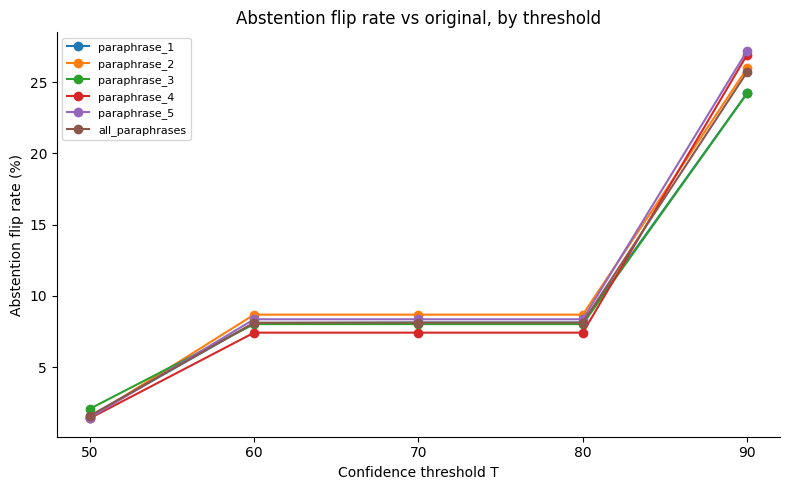

In [187]:
flip_rows = []
for T in THRESHOLDS:
    dec = dec_by_T[T]
    tot = {"pairs": 0, "a2b": 0, "b2a": 0}
    for v in PARAPHRASES:
        ok = dec["original"].notna() & dec[v].notna()
        o, p = dec.loc[ok, "original"], dec.loc[ok, v]
        a2b = int(((o == "answer") & (p == "abstain")).sum())
        b2a = int(((o == "abstain") & (p == "answer")).sum())
        n = int(ok.sum())
        flip_rows.append({
            "threshold": T, "variant": v, "valid_pairs": n, "decision_flips": a2b + b2a,
            "abstention_flip_rate": (a2b + b2a) / n if n else np.nan,
            "answer_to_abstain": a2b, "abstain_to_answer": b2a,
        })
        tot["pairs"] += n; tot["a2b"] += a2b; tot["b2a"] += b2a
    flip_rows.append({
        "threshold": T, "variant": "all_paraphrases", "valid_pairs": tot["pairs"],
        "decision_flips": tot["a2b"] + tot["b2a"],
        "abstention_flip_rate": (tot["a2b"] + tot["b2a"]) / tot["pairs"] if tot["pairs"] else np.nan,
        "answer_to_abstain": tot["a2b"], "abstain_to_answer": tot["b2a"],
    })
flip_tbl = pd.DataFrame(flip_rows)

p6_header("ABSTENTION FLIP RATES (paraphrase vs original)")
print(flip_tbl.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
p6_save_table(flip_tbl, "phase6_abstention_flip_rates.csv")

# ---- Plot 4: abstention flip rate by threshold ----
fig, ax = plt.subplots(figsize=(8, 5))
for v in PARAPHRASES + ["all_paraphrases"]:
    d = flip_tbl[flip_tbl["variant"] == v]
    ax.plot(d["threshold"], 100 * d["abstention_flip_rate"], marker="o", label=v)
ax.set_xlabel("Confidence threshold T")
ax.set_ylabel("Abstention flip rate (%)")
ax.set_title("Abstention flip rate vs original, by threshold")
ax.set_xticks(THRESHOLDS)
ax.legend(fontsize=8)
fig.tight_layout()
p6_save_fig(fig, "phase6_abstention_flip_rate.png")
plt.show()

## 6.7 Question-level decision stability

For each question and threshold:

`decision_consistency = max(num_answer_decisions, num_abstain_decisions) / num_valid_variants`

(e.g. 6 answers -> 1.0, 5 answer + 1 abstain -> 5/6, 3 + 3 -> 0.5).

Groups: `all_answer`, `all_abstain`, `mixed`. The saved CSV keeps one row per question and threshold **with the decision of every variant** (`decision_original`, `decision_paraphrase_1`, ...) and a compact pattern string in `VARIANTS` order (`A` = answer, `-` = abstain, `?` = missing/invalid), so qualitative analysis stays possible.

Proportions and mean/median consistency are reported over questions with **at least 2 valid variants** (a decision-stability measure needs at least two decisions).

In [188]:
SYMBOL = {"answer": "A", "abstain": "-"}
stab_parts = []
for T in THRESHOLDS:
    dec = dec_by_T[T]
    t = pd.DataFrame(index=dec.index)
    t["threshold"] = T
    t["num_valid_variants"] = dec.notna().sum(axis=1).astype(int)
    t["num_answer_decisions"] = (dec == "answer").sum(axis=1).astype(int)
    t["num_abstain_decisions"] = (dec == "abstain").sum(axis=1).astype(int)
    t["decision_consistency"] = (
        np.maximum(t["num_answer_decisions"], t["num_abstain_decisions"])
        / t["num_valid_variants"].where(t["num_valid_variants"] > 0)
    )
    nv = t["num_valid_variants"]
    t["decision_group"] = np.select(
        [nv < 2, t["num_answer_decisions"] == nv, t["num_abstain_decisions"] == nv],
        ["fewer_than_2_valid", "all_answer", "all_abstain"],
        default="mixed",
    )
    for v in VARIANTS:
        t[f"decision_{v}"] = dec[v]
    t["decision_pattern"] = dec.apply(
        lambda row: "".join(SYMBOL.get(row[v], "?") if isinstance(row[v], str) else "?" for v in VARIANTS), axis=1
    )
    stab_parts.append(t)

stab_tbl = pd.concat(stab_parts).rename_axis("question_id").reset_index()
assert len(stab_tbl) == len(all_ids) * len(THRESHOLDS)

stab_summary = []
for T in THRESHOLDS:
    s = stab_tbl[(stab_tbl["threshold"] == T) & (stab_tbl["num_valid_variants"] >= 2)]
    n = len(s)
    stab_summary.append({
        "threshold": T,
        "questions_with_2plus_valid": n,
        "pct_all_answer": 100 * (s["decision_group"] == "all_answer").mean(),
        "pct_all_abstain": 100 * (s["decision_group"] == "all_abstain").mean(),
        "pct_mixed": 100 * (s["decision_group"] == "mixed").mean(),
        "mean_decision_consistency": s["decision_consistency"].mean(),
        "median_decision_consistency": s["decision_consistency"].median(),
    })
stab_summary = pd.DataFrame(stab_summary)

p6_header("QUESTION-LEVEL DECISION STABILITY (questions with >= 2 valid variants)")
print(stab_summary.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
p6_save_table(stab_tbl, "phase6_question_level_decision_stability.csv")

print("\nExample decision patterns (A = answer, - = abstain, ? = missing), threshold 80, first 5 mixed questions:")
print(stab_tbl[(stab_tbl["threshold"] == 80) & (stab_tbl["decision_group"] == "mixed")]
      [["question_id", "decision_pattern", "decision_consistency"]].head(5).to_string(index=False))


QUESTION-LEVEL DECISION STABILITY (questions with >= 2 valid variants)
 threshold  questions_with_2plus_valid  pct_all_answer  pct_all_abstain  pct_mixed  mean_decision_consistency  median_decision_consistency
        50                        3000          96.733            0.000      3.267                      0.993                        1.000
        60                        3000          79.833            0.033     20.133                      0.947                        1.000
        70                        3000          79.800            0.033     20.167                      0.947                        1.000
        80                        3000          79.800            0.033     20.167                      0.947                        1.000
        90                        3000          33.600            2.933     63.467                      0.818                        0.833
Saved: /content/drive/MyDrive/Research3/results/phase6_question_level_decision_stability.csv



## 6.8 Confidence decision vs correctness

For every threshold, among valid responses: `correct + answer`, `correct + abstain`, `incorrect + answer`, `incorrect + abstain`. The two percentage columns show what share of all correct / all incorrect responses is removed (abstained) by the threshold, i.e. whether the threshold mainly removes incorrect answers, correct answers, or both.

In [189]:
n_correct_all = int(vd["correct"].sum())
n_incorrect_all = n_valid - n_correct_all

dc_rows = []
for T in ALL_THRESHOLDS:
    ans = vd["conf"] >= T
    cor = vd["correct"]
    ca, cb = int((cor & ans).sum()), int((cor & ~ans).sum())
    ia, ib = int((~cor & ans).sum()), int((~cor & ~ans).sum())
    dc_rows.append({
        "threshold": T,
        "correct_answer": ca, "correct_abstain": cb,
        "incorrect_answer": ia, "incorrect_abstain": ib,
        "total_valid": ca + cb + ia + ib,
        "pct_of_correct_abstained": 100 * cb / n_correct_all if n_correct_all else np.nan,
        "pct_of_incorrect_abstained": 100 * ib / n_incorrect_all if n_incorrect_all else np.nan,
    })
dc_tbl = pd.DataFrame(dc_rows)
assert (dc_tbl["total_valid"] == n_valid).all()

p6_header("CONFIDENCE DECISION x CORRECTNESS")
print(dc_tbl.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
p6_save_table(dc_tbl, "phase6_confidence_decision_correctness.csv")


CONFIDENCE DECISION x CORRECTNESS
 threshold  correct_answer  correct_abstain  incorrect_answer  incorrect_abstain  total_valid  pct_of_correct_abstained  pct_of_incorrect_abstained
         0            2219                0             15753                  0        17972                      0.00                        0.00
        50            2219                0             15619                134        17972                      0.00                        0.85
        60            2219                0             14679               1074        17972                      0.00                        6.82
        70            2219                0             14678               1075        17972                      0.00                        6.82
        80            2219                0             14678               1075        17972                      0.00                        6.82
        90            2131               88             10336               5

## 6.9 High-confidence wrong answers and low-confidence correct answers

- **High-confidence wrong:** incorrect responses with `confidence >= T`.
- **Low-confidence correct:** correct responses with `confidence < T` (correct answers that abstention would remove).

The CSVs are row-level lists with one boolean flag column per threshold. Order is deterministic: high-confidence wrong sorted by confidence (high to low), low-confidence correct sorted by confidence (low to high); ties are broken by dataset order, then variant order. Printed examples follow the same order; no manual selection.

In [190]:
def add_order(d):
    d = d.copy()
    d["_q"] = d["question_id"].map(q_pos)
    d["_v"] = d["variant"].map(v_pos)
    return d


# ---- high-confidence wrong ----
wrong = add_order(vd[~vd["correct"]])
hcw = wrong[wrong["conf"] >= min(THRESHOLDS)].sort_values(["conf", "_q", "_v"], ascending=[False, True, True])
for T in THRESHOLDS:
    hcw[f"conf_ge_{T}"] = hcw["conf"] >= T
hcw_out = hcw.drop(columns=["_q", "_v"]).rename(columns={"conf": "confidence"})
hcw_out["correctness"] = "incorrect"
hcw_out = hcw_out[["question_id", "variant", "question", "answer", "confidence", "gold_answer", "correctness"]
                  + [f"conf_ge_{T}" for T in THRESHOLDS]]

# ---- low-confidence correct ----
right = add_order(vd[vd["correct"]])
lcc = right[right["conf"] < max(THRESHOLDS)].sort_values(["conf", "_q", "_v"], ascending=[True, True, True])
for T in THRESHOLDS:
    lcc[f"conf_lt_{T}"] = lcc["conf"] < T
lcc_out = lcc.drop(columns=["_q", "_v"]).rename(columns={"conf": "confidence"})
lcc_out["correctness"] = "correct"
lcc_out = lcc_out[["question_id", "variant", "question", "answer", "confidence", "gold_answer", "correctness"]
                  + [f"conf_lt_{T}" for T in THRESHOLDS]]

hcw_counts, lcc_counts = {}, {}
rows = []
for T in THRESHOLDS:
    hc = int((wrong["conf"] >= T).sum())
    lc = int((right["conf"] < T).sum())
    hcw_counts[T], lcc_counts[T] = hc, lc
    rows.append({
        "threshold": T,
        "high_conf_incorrect_count": hc,
        "pct_of_all_incorrect_valid": 100 * hc / n_incorrect_all if n_incorrect_all else np.nan,
        "low_conf_correct_count": lc,
        "pct_of_all_correct_valid": 100 * lc / n_correct_all if n_correct_all else np.nan,
    })
hl_tbl = pd.DataFrame(rows)

p6_header("HIGH-CONFIDENCE WRONG / LOW-CONFIDENCE CORRECT (counts)")
print(f"All incorrect valid responses: {n_incorrect_all} | all correct valid responses: {n_correct_all}\n")
print(hl_tbl.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

p6_save_table(hcw_out, "phase6_high_confidence_wrong.csv")
p6_save_table(lcc_out, "phase6_low_confidence_correct.csv")


def print_examples(title, d):
    p6_header(title)
    for k, (_, r) in enumerate(d.head(N_EXAMPLES).iterrows(), start=1):
        print(f"\nExample {k}:")
        print(f"  question_id: {r['question_id']} | variant: {r['variant']}")
        print(f"  question:    {r['question']}")
        print(f"  answer:      {r['answer']}")
        print(f"  confidence:  {r['confidence']:g}")
        print(f"  gold:        {r['gold_answer']}")
        print(f"  correctness: {r['correctness']}")


print_examples("HIGHEST-CONFIDENCE INCORRECT RESPONSES (they satisfy confidence >= T for every T up to their confidence)", hcw_out)
print_examples("LOWEST-CONFIDENCE CORRECT RESPONSES (they would be abstained at every T above their confidence)", lcc_out)


HIGH-CONFIDENCE WRONG / LOW-CONFIDENCE CORRECT (counts)
All incorrect valid responses: 15753 | all correct valid responses: 2219

 threshold  high_conf_incorrect_count  pct_of_all_incorrect_valid  low_conf_correct_count  pct_of_all_correct_valid
        50                      15619                       99.15                       0                      0.00
        60                      14679                       93.18                       0                      0.00
        70                      14678                       93.18                       0                      0.00
        80                      14678                       93.18                       0                      0.00
        90                      10336                       65.61                      88                      3.97
Saved: /content/drive/MyDrive/Research3/results/phase6_high_confidence_wrong.csv
Saved: /content/drive/MyDrive/Research3/results/phase6_low_confidence_correct.csv

HIGHEST-C

## 6.10 Reproducibility record and final summary

Saves `phase6_run_summary.json` (model, counts, thresholds, baseline, per-threshold coverage / abstention / selective accuracy / risk, flip rates and decision consistency) and prints the Phase 6 summary and all generated file paths.

In [191]:
def _f(x):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else float(x)


thr_idx = thr_tbl.set_index("threshold")
flip_all = flip_tbl[flip_tbl["variant"] == "all_paraphrases"].set_index("threshold")
stab_idx = stab_summary.set_index("threshold")

phase6_record = {
    "model_name": MODEL_NAME_P4,
    "phase3_results_path": RESULTS_PATH,
    "analysis_type": "post-hoc confidence-conditioned (threshold-based) abstention; the model was not asked to abstain",
    "decision_rule": "answer if confidence >= T, abstain if confidence < T",
    "num_unique_questions": len(all_ids),
    "num_valid_responses": int(n_valid),
    "num_invalid_or_failed_responses": int(n_excluded),
    "exclusions": {
        "parse_errors": int(n_parse_errors),
        "inference_errors": int(n_inference_errors),
        "success_but_missing_confidence": succ_missing_conf,
        "success_but_invalid_confidence": succ_invalid_conf,
    },
    "thresholds": ALL_THRESHOLDS,
    "baseline_accuracy": _f(baseline["selective_accuracy"]),
    "baseline_risk": _f(baseline["selective_risk"]),
    "coverage": {str(T): _f(thr_idx.loc[T, "coverage"]) for T in ALL_THRESHOLDS},
    "abstention_rate": {str(T): _f(thr_idx.loc[T, "abstention_rate"]) for T in ALL_THRESHOLDS},
    "selective_accuracy": {str(T): _f(thr_idx.loc[T, "selective_accuracy"]) for T in ALL_THRESHOLDS},
    "selective_risk": {str(T): _f(thr_idx.loc[T, "selective_risk"]) for T in ALL_THRESHOLDS},
    "overall_abstention_flip_rate": {str(T): _f(flip_all.loc[T, "abstention_flip_rate"]) for T in THRESHOLDS},
    "question_level_decision_consistency": {
        str(T): {
            "questions_with_2plus_valid": int(stab_idx.loc[T, "questions_with_2plus_valid"]),
            "mean": _f(stab_idx.loc[T, "mean_decision_consistency"]),
            "median": _f(stab_idx.loc[T, "median_decision_consistency"]),
            "pct_all_answer": _f(stab_idx.loc[T, "pct_all_answer"]),
            "pct_all_abstain": _f(stab_idx.loc[T, "pct_all_abstain"]),
            "pct_mixed": _f(stab_idx.loc[T, "pct_mixed"]),
        }
        for T in THRESHOLDS
    },
    "high_confidence_incorrect_count": {str(T): hcw_counts[T] for T in THRESHOLDS},
    "low_confidence_correct_count": {str(T): lcc_counts[T] for T in THRESHOLDS},
    "correctness_definition": "Phase 4 is_correct (unchanged); possible strictness of this rule is audited separately",
    "note": "Confidence is a self-reported 0-100 number, not assumed to be a true probability. Descriptive analysis only, no significance tests.",
}

p6_json_path = f"{RESULTS_DIR}/phase6_run_summary.json"
with open(p6_json_path, "w", encoding="utf-8") as f:
    json.dump(phase6_record, f, indent=2, ensure_ascii=False)
p6_files.append(p6_json_path)
print(f"Saved: {p6_json_path}")

print("\n" + "=" * 40)
print("PHASE 6 SUMMARY")
print("=" * 40)
print(f"\nModel: {MODEL_NAME_P4}\n")
print(f"Valid responses: {n_valid}")
print(f"Invalid/failed responses: {n_excluded}\n")
print(f"Baseline accuracy: {baseline['selective_accuracy']:.4f}")
print(f"Baseline risk: {baseline['selective_risk']:.4f}")

print("\n" + "-" * 40)
print("THRESHOLD RESULTS")
print("-" * 40)
for T in ALL_THRESHOLDS:
    r = thr_idx.loc[T]
    print(f"\nThreshold: {T}")
    print(f"Coverage: {r['coverage']:.4f}")
    print(f"Abstention rate: {r['abstention_rate']:.4f}")
    print(f"Selective accuracy: {r['selective_accuracy']:.4f}")
    print(f"Selective risk: {r['selective_risk']:.4f}")

print("\n" + "-" * 40)
print("PARAPHRASE STABILITY")
print("-" * 40)
for T in THRESHOLDS:
    print(f"\nThreshold: {T}")
    print(f"Abstention flip rate: {flip_all.loc[T, 'abstention_flip_rate']:.4f}")
    print(f"Decision consistency: mean {stab_idx.loc[T, 'mean_decision_consistency']:.4f} | "
          f"median {stab_idx.loc[T, 'median_decision_consistency']:.4f}")

print("\n" + "-" * 40)
print(f"\nHigh-confidence incorrect answers at threshold 90: {hcw_counts[90]}")
print(f"Low-confidence correct answers at threshold 90: {lcc_counts[90]}")
print("\nPhase 6 confidence-conditioned abstention analysis completed.")

print("\nGenerated files:")
for p in p6_files:
    print(" ", p)

Saved: /content/drive/MyDrive/Research3/results/phase6_run_summary.json

PHASE 6 SUMMARY

Model: Qwen/Qwen2.5-7B-Instruct

Valid responses: 17972
Invalid/failed responses: 28

Baseline accuracy: 0.1235
Baseline risk: 0.8765

----------------------------------------
THRESHOLD RESULTS
----------------------------------------

Threshold: 0
Coverage: 1.0000
Abstention rate: 0.0000
Selective accuracy: 0.1235
Selective risk: 0.8765

Threshold: 50
Coverage: 0.9925
Abstention rate: 0.0075
Selective accuracy: 0.1244
Selective risk: 0.8756

Threshold: 60
Coverage: 0.9402
Abstention rate: 0.0598
Selective accuracy: 0.1313
Selective risk: 0.8687

Threshold: 70
Coverage: 0.9402
Abstention rate: 0.0598
Selective accuracy: 0.1313
Selective risk: 0.8687

Threshold: 80
Coverage: 0.9402
Abstention rate: 0.0598
Selective accuracy: 0.1313
Selective risk: 0.8687

Threshold: 90
Coverage: 0.6937
Abstention rate: 0.3063
Selective accuracy: 0.1709
Selective risk: 0.8291

---------------------------------------

## 6.A Phase 6 (spec implementation): validation
Post-hoc **confidence-conditioned abstention**: the model was never asked to abstain. Rule: `confidence >= T -> ANSWER`, `confidence < T -> ABSTAIN` (confidence == T answers), thresholds 50, 60, 70, 80, 90 plus a T=0 no-abstention baseline.

Uses only the Phase 4 strict `correct` label and the self-reported confidence. No model, no inference, no new labels, no 16.60% sensitivity estimate. SHA-256 and modification time of the raw Phase 3 CSV and of every `phase4_*` / `phase5_*` output are recorded now and re-checked at the end. All new files start with `phase6_`.

In [192]:
import glob
import hashlib
import shutil

# ---------------- PHASE 6 (spec) CONFIGURATION ----------------
# Reads only objects that already exist in memory from Phase 4 / Phase 5. No model, no inference, no relabelling.
# New objects use the prefix p6x_ / P6X_ so no existing variable is overwritten.
P6X_THRESHOLDS = [50, 60, 70, 80, 90]
P6X_ALL_T = [0] + P6X_THRESHOLDS          # 0 = no-abstention baseline
P6X_EXPECTED = {"rows": 18000, "questions": 3000, "variants": 6, "valid": 17972, "valid_conf": 17972, "correct": 2219}
MEANINGFUL_RISK_REDUCTION_PP = 1.0        # analysis criterion for 6.12 only (percentage points of selective risk vs baseline)

_needed = ["res", "vdf", "cdf", "all_ids", "VARIANTS", "PARAPHRASES", "MODEL_NAME_P4", "RESULTS_PATH",
           "RESULTS_DIR", "FIGURES_DIR", "match_answer", "n_valid", "n_correct", "overall_accuracy"]
_missing = [n for n in _needed if n not in globals()]
if _missing:
    raise RuntimeError(f"Run the Phase 4 cells and Phase 5 cells 5.0-5.1 (config + confidence conversion) first. Missing: {_missing}")

p6x_files = []                            # every file written by this Phase 6 implementation


def p6x_header(title):
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}")


def p6x_save_table(table, filename):
    assert filename.startswith("phase6_"), "Phase 6 files must start with 'phase6_'."
    path = f"{RESULTS_DIR}/{filename}"
    table.to_csv(path, index=False)
    p6x_files.append(path)
    print(f"Saved: {path}")


def p6x_save_fig(fig, filename):
    assert filename.startswith("phase6_"), "Phase 6 files must start with 'phase6_'."
    path = f"{FIGURES_DIR}/{filename}"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    p6x_files.append(path)
    print(f"Saved: {path}")


def p6x_sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


# ---- fingerprints taken BEFORE anything is written ----
P6X_RAW_SHA = p6x_sha(RESULTS_PATH)
P6X_RAW_MTIME = os.path.getmtime(RESULTS_PATH)
P6X_PROTECTED = {}
for _folder in {RESULTS_DIR, FIGURES_DIR}:
    for _p in glob.glob(f"{_folder}/phase4_*") + glob.glob(f"{_folder}/phase5_*"):
        P6X_PROTECTED[_p] = (p6x_sha(_p), os.path.getmtime(_p))
P6X_STRICT_BEFORE = (int(vdf["correct"].sum()), len(vdf))

# ---------------- 6.1 input and reproducibility checks ----------------
_phase5_required = ["phase5_run_summary.json", "phase5_calibration_bins.csv", "phase5_confidence_bins.csv",
                    "phase5_paraphrase_confidence_stability.csv", "phase5_confidence_by_variant.csv"]
_missing_p5 = [f for f in _phase5_required if not os.path.exists(f"{RESULTS_DIR}/{f}")]
assert not _missing_p5, f"Phase 5 outputs not found: {_missing_p5}"
_phase5_optional = [f for f in ("phase5_statistical_tests.csv", "phase5_confidence_summary.csv")
                    if os.path.exists(f"{RESULTS_DIR}/{f}")]

assert len(res) == P6X_EXPECTED["rows"], "Raw Phase 3 row count changed."
assert res["question_id"].nunique() == len(all_ids) == P6X_EXPECTED["questions"], "Expected 3,000 unique questions."
assert (res.groupby("question_id")["variant"].nunique() == P6X_EXPECTED["variants"]).all(), "Each question needs 6 variants."
assert not res.duplicated(["question_id", "variant"]).any(), "Duplicate question_id + variant."
# one row per question, one column per variant (NaN = no valid confidence); identical to the Phase 5 conf_wide when it exists
P6_CONF_WIDE = cdf.pivot(index="question_id", columns="variant", values="conf").reindex(index=all_ids, columns=VARIANTS)
if "conf_wide" in globals():
    assert P6_CONF_WIDE.equals(conf_wide), "Rebuilt confidence matrix differs from the Phase 5 conf_wide."
assert n_valid == len(vdf) == P6X_EXPECTED["valid"], "Number of valid responses changed."
assert len(cdf) == P6X_EXPECTED["valid_conf"], "Number of valid confidence values is not 17,972."
assert cdf["conf"].between(0, 100).all(), "Confidence outside 0-100."
assert not cdf.duplicated(["question_id", "variant"]).any()
assert int(P6_CONF_WIDE.notna().sum().sum()) == len(cdf), "Confidence matrix does not match the confidence table."
assert n_correct == int(vdf["correct"].sum()) == P6X_EXPECTED["correct"], "Strict correct count changed."
_recomputed = pd.Series([match_answer(a, g)[0] for a, g in zip(vdf["answer"], vdf["gold_norms"])], index=vdf.index)
assert (_recomputed == vdf["correct"]).all(), "Strict labels differ from a fresh recomputation of the Phase 4 rule."
assert (cdf["correct"] == vdf.loc[cdf.index, "correct"]).all(), "Confidence table labels differ from Phase 4."
if "CORRECT_BEFORE" in globals():
    assert (vdf["correct"] == CORRECT_BEFORE).all(), "Phase 4 labels changed after the evaluator audit."

# analysis arrays: only the Phase 4 label and the self-reported confidence are used
p6d = cdf[["question_id", "variant", "conf", "correct"]].reset_index(drop=True)
P6_CONF = p6d["conf"].to_numpy(dtype=float)
P6_COR = p6d["correct"].to_numpy(dtype=bool)
P6_N, P6_NCOR = len(P6_CONF), int(P6_COR.sum())
P6_NINC = P6_N - P6_NCOR
assert P6_CONF.min() >= 0, "Baseline threshold 0 would not answer every response."

p6x_header("6.1 VALIDATION REPORT")
print(f"Raw Phase 3 file (read-only):        {os.path.basename(RESULTS_PATH)}  sha256={P6X_RAW_SHA[:16]}...")
print(f"Rows:                                {len(res)} (expected {P6X_EXPECTED['rows']})")
print(f"Unique questions / variants:         {len(all_ids)} / {len(VARIANTS)}")
print(f"Valid responses:                     {n_valid}")
print(f"Valid confidence values:             {len(cdf)}")
print(f"Strict correct / incorrect:          {n_correct} / {n_valid - n_correct}  (accuracy {100 * overall_accuracy:.2f}%)")
print(f"Phase 5 required outputs present:    {len(_phase5_required)}/{len(_phase5_required)} | optional present: {_phase5_optional or 'none'}")
print(f"Phase 4/5 files fingerprinted:       {len(P6X_PROTECTED)}")
print("Decision rule: confidence >= T -> ANSWER; confidence < T -> ABSTAIN (confidence == T answers).")
print("All validation assertions passed. No data was repaired.")


6.1 VALIDATION REPORT
Raw Phase 3 file (read-only):        phase3_qwen25_7b_inference.csv  sha256=eb1401630b5a7d5e...
Rows:                                18000 (expected 18000)
Unique questions / variants:         3000 / 6
Valid responses:                     17972
Valid confidence values:             17972
Strict correct / incorrect:          2219 / 15753  (accuracy 12.35%)
Phase 5 required outputs present:    5/5 | optional present: ['phase5_statistical_tests.csv', 'phase5_confidence_summary.csv']
Phase 4/5 files fingerprinted:       35
Decision rule: confidence >= T -> ANSWER; confidence < T -> ABSTAIN (confidence == T answers).
All validation assertions passed. No data was repaired.


## 6.B Threshold metrics, correctness-aware abstention, risk-coverage curve
- `phase6_threshold_metrics.csv`: T=0 baseline plus 50-90: answered, abstained, coverage, abstention rate, correct/incorrect answered, selective accuracy and risk, plus `accuracy_gain_vs_baseline` and `risk_reduction_vs_baseline`. The T=0 row must equal the strict Phase 4 result (2219 / 17972).
- `phase6_abstention_correctness.csv`: correct/incorrect among answered and among abstained, `correct_abstention_rate = correct_abstained / total_correct`, `incorrect_abstention_rate = incorrect_abstained / total_incorrect`. Zero denominators give NaN.
- `phase6_risk_coverage.csv`: responses sorted by confidence (descending). Tied confidences cannot be separated, so one point is computed per **distinct** confidence value (answered set = all responses with confidence >= that value). No interpolation. Every threshold operating point lies exactly on this curve.

In [193]:
def p6x_div(a, b):
    return a / b if b else np.nan


# ---------------- 6.2-6.5 threshold metrics (T = 0 baseline, then 50..90) ----------------
rows = []
for T in P6X_ALL_T:
    ans = P6_CONF >= T                                   # confidence == T answers
    n_ans = int(ans.sum())
    ca = int((P6_COR & ans).sum())
    ia = n_ans - ca
    rows.append({"threshold": T, "total_valid": P6_N, "answered": n_ans, "abstained": P6_N - n_ans,
                 "coverage": n_ans / P6_N, "abstention_rate": (P6_N - n_ans) / P6_N,
                 "correct_answered": ca, "incorrect_answered": ia,
                 "selective_accuracy": p6x_div(ca, n_ans), "selective_risk": p6x_div(ia, n_ans)})
thr_metrics = pd.DataFrame(rows)
_base = thr_metrics.iloc[0]
thr_metrics["accuracy_gain_vs_baseline"] = thr_metrics["selective_accuracy"] - _base["selective_accuracy"]
thr_metrics["risk_reduction_vs_baseline"] = _base["selective_risk"] - thr_metrics["selective_risk"]   # positive = lower risk

# checks
assert _base["threshold"] == 0 and _base["answered"] == P6_N and _base["coverage"] == 1.0 and _base["abstention_rate"] == 0.0
assert _base["correct_answered"] == n_correct == 2219 and _base["total_valid"] == n_valid == 17972, "Baseline is not 2219/17972."
assert abs(_base["selective_accuracy"] - overall_accuracy) < 1e-15, "Baseline accuracy differs from Phase 4."
assert np.allclose(thr_metrics["coverage"] + thr_metrics["abstention_rate"], 1.0), "coverage + abstention != 1"
_a = thr_metrics[thr_metrics["answered"] > 0]
assert np.allclose(_a["selective_accuracy"] + _a["selective_risk"], 1.0), "selective accuracy + risk != 1"
assert (thr_metrics["answered"] + thr_metrics["abstained"] == P6_N).all()
assert (thr_metrics["correct_answered"] + thr_metrics["incorrect_answered"] == thr_metrics["answered"]).all()

# cross-check against the existing (already saved) Phase 6 threshold table, if present
_old_path = f"{RESULTS_DIR}/phase6_threshold_results.csv"
if os.path.exists(_old_path):
    _old = pd.read_csv(_old_path).set_index("threshold")
    for T in P6X_ALL_T:
        for col in ("answered", "abstained", "correct_answered", "incorrect_answered"):
            assert int(_old.loc[T, col]) == int(thr_metrics.set_index("threshold").loc[T, col]), f"Mismatch vs saved Phase 6 table: T={T}, {col}"
    print("Cross-check: threshold counts reproduce the saved phase6_threshold_results.csv exactly.")

p6x_header("6.3-6.5 THRESHOLD METRICS (T=0 is the no-abstention baseline)")
print(thr_metrics.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
p6x_save_table(thr_metrics, "phase6_threshold_metrics.csv")

# ---------------- 6.8 correctness-aware abstention analysis ----------------
rows = []
for T in P6X_ALL_T:
    ans = P6_CONF >= T
    ca, cb = int((P6_COR & ans).sum()), int((P6_COR & ~ans).sum())
    ia, ib = int((~P6_COR & ans).sum()), int((~P6_COR & ~ans).sum())
    assert ca + cb + ia + ib == P6_N
    rows.append({"threshold": T, "total_correct": P6_NCOR, "total_incorrect": P6_NINC,
                 "correct_answered": ca, "incorrect_answered": ia, "correct_abstained": cb, "incorrect_abstained": ib,
                 "correct_abstention_rate": p6x_div(cb, P6_NCOR),          # correct_abstained / total_correct
                 "incorrect_abstention_rate": p6x_div(ib, P6_NINC),        # incorrect_abstained / total_incorrect
                 "accuracy_among_answered": p6x_div(ca, ca + ia),
                 "accuracy_among_abstained": p6x_div(cb, cb + ib),
                 "share_of_abstained_that_are_incorrect": p6x_div(ib, cb + ib),
                 "share_of_all_valid_that_are_incorrect": P6_NINC / P6_N})
corr_tbl = pd.DataFrame(rows)

_old_path = f"{RESULTS_DIR}/phase6_confidence_decision_correctness.csv"
if os.path.exists(_old_path):
    _old = pd.read_csv(_old_path).set_index("threshold")
    for T in P6X_ALL_T:
        r = corr_tbl.set_index("threshold").loc[T]
        assert (int(_old.loc[T, "correct_abstain"]), int(_old.loc[T, "incorrect_abstain"])) == (int(r["correct_abstained"]), int(r["incorrect_abstained"]))
    print("Cross-check: correctness counts reproduce the saved phase6_confidence_decision_correctness.csv exactly.")

p6x_header("6.8 CORRECTNESS-AWARE ABSTENTION")
print(corr_tbl[["threshold", "correct_answered", "incorrect_answered", "correct_abstained", "incorrect_abstained",
                "correct_abstention_rate", "incorrect_abstention_rate", "accuracy_among_answered",
                "accuracy_among_abstained"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))
p6x_save_table(corr_tbl, "phase6_abstention_correctness.csv")

# ---------------- 6.9 risk-coverage curve ----------------
# Responses are ordered by confidence (descending). Tied confidences cannot be separated, so a point is computed for each
# DISTINCT confidence value c: the answered set is every response with confidence >= c. No interpolation.
g = (pd.DataFrame({"confidence_cutoff": P6_CONF, "cor": P6_COR})
     .groupby("confidence_cutoff").agg(n=("cor", "size"), c=("cor", "sum"))
     .sort_index(ascending=False))
rc = pd.DataFrame({"confidence_cutoff": g.index.to_numpy(), "answered": g["n"].cumsum().to_numpy(),
                   "correct_answered": g["c"].cumsum().to_numpy()})
rc["incorrect_answered"] = rc["answered"] - rc["correct_answered"]
rc["coverage"] = rc["answered"] / P6_N
rc["selective_accuracy"] = rc["correct_answered"] / rc["answered"]
rc["selective_risk"] = rc["incorrect_answered"] / rc["answered"]

_op = {T: (float(P6_CONF[P6_CONF >= T].min()) if (P6_CONF >= T).any() else np.nan) for T in P6X_THRESHOLDS}
rc["operating_thresholds"] = [", ".join(str(T) for T in P6X_THRESHOLDS if _op[T] == c) for c in rc["confidence_cutoff"]]
rc["is_no_abstention_baseline"] = rc["coverage"] == 1.0

assert rc["coverage"].is_monotonic_increasing and rc["coverage"].iloc[-1] == 1.0
assert rc["answered"].iloc[-1] == P6_N and rc["correct_answered"].iloc[-1] == n_correct, "Last point must be the baseline."
assert abs(rc["selective_risk"].iloc[-1] - _base["selective_risk"]) < 1e-15
_tm = thr_metrics.set_index("threshold")
for T in P6X_THRESHOLDS:       # every threshold operating point lies exactly on the curve
    if not np.isnan(_op[T]):
        _r = rc[rc["confidence_cutoff"] == _op[T]].iloc[0]
        assert int(_r["answered"]) == int(_tm.loc[T, "answered"]) and int(_r["correct_answered"]) == int(_tm.loc[T, "correct_answered"])

p6x_header("6.9 RISK-COVERAGE CURVE (one point per distinct confidence value)")
print(f"Distinct confidence values: {len(rc)}")
print(rc.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
p6x_save_table(rc, "phase6_risk_coverage.csv")

Cross-check: threshold counts reproduce the saved phase6_threshold_results.csv exactly.

6.3-6.5 THRESHOLD METRICS (T=0 is the no-abstention baseline)
 threshold  total_valid  answered  abstained  coverage  abstention_rate  correct_answered  incorrect_answered  selective_accuracy  selective_risk  accuracy_gain_vs_baseline  risk_reduction_vs_baseline
         0        17972     17972          0    1.0000           0.0000              2219               15753              0.1235          0.8765                     0.0000                      0.0000
        50        17972     17838        134    0.9925           0.0075              2219               15619              0.1244          0.8756                     0.0009                      0.0009
        60        17972     16898       1074    0.9402           0.0598              2219               14679              0.1313          0.8687                     0.0078                      0.0078
        70        17972     16897       1075 

## 6.C Abstention stability across the six variants + figures
For each threshold and question, over its **valid** variants: number answered / abstained, answer and abstention decision rates. `abstention_flip = 1` if the valid variants do not all share the same decision (questions with fewer than 2 valid variants cannot flip and are excluded from the rate).

These are **within-question differences across variants, not temporal transitions**. Every flip question contains both an answer and an abstain decision. To make direction informative, flips are also split (a) by which decision is the majority (answer / abstain / 3-3 tie) and (b) relative to the original variant (original answered while some paraphrase abstained, or the reverse).

Files: `phase6_abstention_stability.csv` (one row per threshold), `phase6_question_abstention_decisions.csv` (per question and threshold), `phase6_risk_coverage.png`, `phase6_threshold_comparison.png`, `phase6_abstention_flip_rate.png`.

Note: an earlier Phase 6 cell saved a *pairwise original-vs-paraphrase* figure under the name `phase6_abstention_flip_rate.png`. It is copied to `phase6_abstention_flip_rate_pairwise_original_vs_paraphrase.png` before the new question-level figure is written, so nothing is lost.

Cross-check: flip counts reproduce the saved phase6_question_level_decision_stability.csv exactly.

6.6-6.7 ABSTENTION STABILITY ACROSS THE SIX VARIANTS
 threshold  questions_total  questions_evaluable_2plus_valid  stable_questions  stable_all_answer  stable_all_abstain  abstention_flip_questions  abstention_flip_rate  flips_majority_answer  flips_majority_abstain  flips_tied  flips_original_answer_some_paraphrase_abstain  flips_original_abstain_some_paraphrase_answer  flips_original_missing  mean_answer_decision_rate  mean_abstention_decision_rate
        50             3000                             3000              2902               2902                   0                         98                0.0327                     92                       2           4                                             58                                             40                       0                     0.9925                         0.0075
        60             3000                

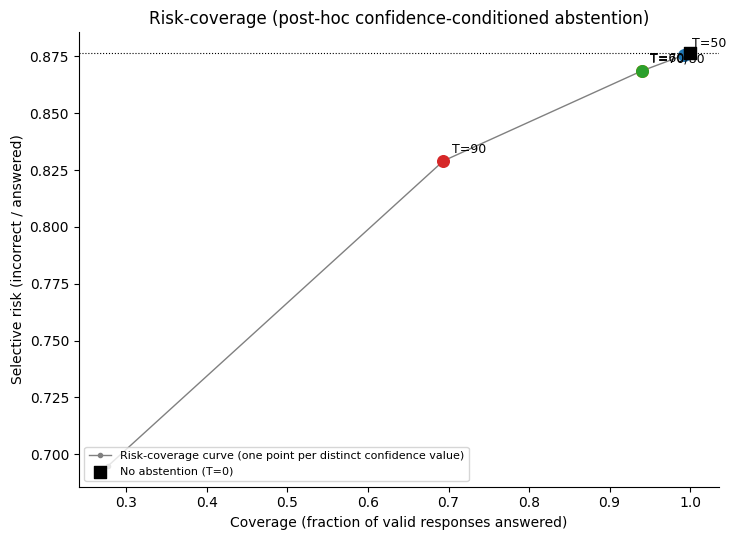

Saved: /content/drive/MyDrive/Research3/figures/phase6_threshold_comparison.png


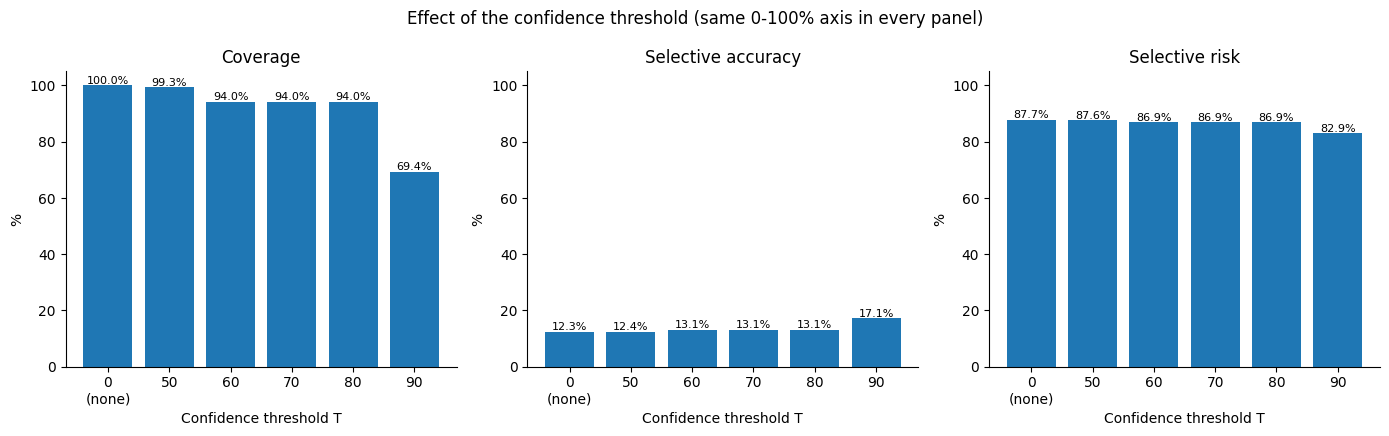

Saved: /content/drive/MyDrive/Research3/figures/phase6_abstention_flip_rate.png


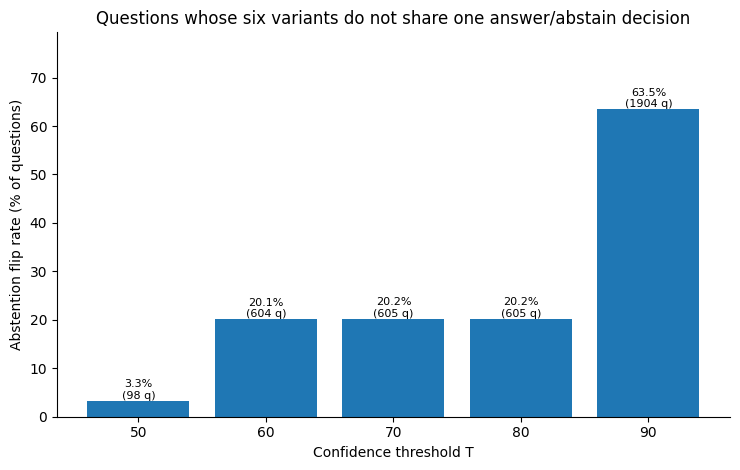

In [194]:
# ---------------- 6.6-6.7 question-level abstention stability ----------------
CW = P6_CONF_WIDE.to_numpy(dtype=float)                  # questions x 6 variants (original first), NaN = no valid confidence
VALID = ~np.isnan(CW)
NV = VALID.sum(axis=1)
assert int(VALID.sum()) == P6_N
EVAL = NV >= 2                                           # a decision change needs at least 2 valid variants
orig_valid = VALID[:, 0]
p6x_decision_frames = []
rows = []
for T in P6X_THRESHOLDS:
    ANS = VALID & (np.nan_to_num(CW, nan=-1.0) >= T)    # confidence >= T -> answer
    n_ans = ANS.sum(axis=1)
    n_abs = NV - n_ans
    flip = EVAL & (n_ans > 0) & (n_abs > 0)              # the valid variants do not all share one decision
    stable = EVAL & ~flip
    maj_ans, maj_abs, tie = flip & (n_ans > n_abs), flip & (n_abs > n_ans), flip & (n_ans == n_abs)
    o_ans, o_abs = orig_valid & ANS[:, 0], orig_valid & ~ANS[:, 0]
    para_ans_any = ANS[:, 1:].any(axis=1)
    para_abs_any = (VALID[:, 1:] & ~ANS[:, 1:]).any(axis=1)
    f_oa_pb = flip & o_ans & para_abs_any                # original answered, at least one paraphrase abstained
    f_ob_pa = flip & o_abs & para_ans_any                # original abstained, at least one paraphrase answered
    f_no_orig = flip & ~orig_valid
    assert int(f_oa_pb.sum() + f_ob_pa.sum() + f_no_orig.sum()) == int(flip.sum())
    assert int(maj_ans.sum() + maj_abs.sum() + tie.sum()) == int(flip.sum())
    assert int((stable & (n_abs == 0)).sum() + (stable & (n_ans == 0)).sum()) == int(stable.sum())
    n_eval = int(EVAL.sum())
    rows.append({
        "threshold": T, "questions_total": len(all_ids), "questions_evaluable_2plus_valid": n_eval,
        "stable_questions": int(stable.sum()), "stable_all_answer": int((stable & (n_abs == 0)).sum()),
        "stable_all_abstain": int((stable & (n_ans == 0)).sum()),
        "abstention_flip_questions": int(flip.sum()), "abstention_flip_rate": int(flip.sum()) / n_eval,
        "flips_majority_answer": int(maj_ans.sum()), "flips_majority_abstain": int(maj_abs.sum()), "flips_tied": int(tie.sum()),
        "flips_original_answer_some_paraphrase_abstain": int(f_oa_pb.sum()),
        "flips_original_abstain_some_paraphrase_answer": int(f_ob_pa.sum()),
        "flips_original_missing": int(f_no_orig.sum()),
        "mean_answer_decision_rate": float(np.mean(n_ans[EVAL] / NV[EVAL])),
        "mean_abstention_decision_rate": float(np.mean(n_abs[EVAL] / NV[EVAL])),
    })
    p6x_decision_frames.append(pd.DataFrame({
        "question_id": list(all_ids), "threshold": T, "valid_variants": NV, "answered_variants": n_ans,
        "abstained_variants": n_abs, "answer_decision_rate": np.where(NV > 0, n_ans / np.maximum(NV, 1), np.nan),
        "abstention_decision_rate": np.where(NV > 0, n_abs / np.maximum(NV, 1), np.nan),
        "abstention_flip": flip.astype(int),
        "flip_majority": np.select([maj_ans, maj_abs, tie], ["answer", "abstain", "tie"], default=""),
        "original_decision": np.select([o_ans, o_abs], ["answer", "abstain"], default="missing")}))
stab = pd.DataFrame(rows)
stab["note"] = ("within-question differences across the 6 variants (not temporal transitions); a flip question contains "
                "both an answer and an abstain decision; direction columns are measured relative to the original variant")
assert (stab["stable_questions"] + stab["abstention_flip_questions"] == stab["questions_evaluable_2plus_valid"]).all()
assert np.allclose(stab["abstention_flip_rate"], stab["abstention_flip_questions"] / stab["questions_evaluable_2plus_valid"])

# cross-check against the saved question-level table of the existing Phase 6 ("mixed" = a flip under this definition)
_old_path = f"{RESULTS_DIR}/phase6_question_level_decision_stability.csv"
if os.path.exists(_old_path):
    _o = pd.read_csv(_old_path)
    for T in P6X_THRESHOLDS:
        _s = _o[(_o["threshold"] == T) & (_o["num_valid_variants"] >= 2)]
        assert int((_s["decision_group"] == "mixed").sum()) == int(stab.set_index("threshold").loc[T, "abstention_flip_questions"]), f"Flip mismatch at T={T}"
    print("Cross-check: flip counts reproduce the saved phase6_question_level_decision_stability.csv exactly.")

p6x_header("6.6-6.7 ABSTENTION STABILITY ACROSS THE SIX VARIANTS")
print(stab.drop(columns="note").to_string(index=False, float_format=lambda x: f"{x:.4f}"))
p6x_save_table(stab, "phase6_abstention_stability.csv")
p6x_save_table(pd.concat(p6x_decision_frames, ignore_index=True), "phase6_question_abstention_decisions.csv")

# ---------------- 6.9-6.11 figures ----------------
# ---- risk-coverage ----
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot(rc["coverage"], rc["selective_risk"], marker=".", linewidth=1, color="gray",
        label="Risk-coverage curve (one point per distinct confidence value)")
ax.axhline(_base["selective_risk"], linestyle=":", color="black", linewidth=0.8)
groups = {}
for T in P6X_THRESHOLDS:
    r = _tm.loc[T]
    groups.setdefault((round(r["coverage"], 6), round(r["selective_risk"], 6)), []).append(T)
for (cov, risk), ts in groups.items():
    ax.scatter([cov], [risk], s=70, zorder=3)
    ax.annotate("T=" + "/".join(map(str, ts)), (cov, risk), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.scatter([1.0], [_base["selective_risk"]], marker="s", s=70, color="black", zorder=3, label="No abstention (T=0)")
ax.set_xlabel("Coverage (fraction of valid responses answered)")
ax.set_ylabel("Selective risk (incorrect / answered)")
ax.set_title("Risk-coverage (post-hoc confidence-conditioned abstention)")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
p6x_save_fig(fig, "phase6_risk_coverage.png")
plt.show()

# ---- threshold comparison ----
labels = ["0\n(none)"] + [str(t) for t in P6X_THRESHOLDS]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (col, ttl) in zip(axes, [("coverage", "Coverage"), ("selective_accuracy", "Selective accuracy"), ("selective_risk", "Selective risk")]):
    vals = 100 * thr_metrics[col].to_numpy()
    bars = ax.bar(labels, vals)
    for b, v in zip(bars, vals):
        ax.annotate(f"{v:.1f}%", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, 105)
    ax.set_xlabel("Confidence threshold T")
    ax.set_ylabel("%")
    ax.set_title(ttl)
fig.suptitle("Effect of the confidence threshold (same 0-100% axis in every panel)")
fig.tight_layout()
p6x_save_fig(fig, "phase6_threshold_comparison.png")
plt.show()

# ---- abstention flip rate (question level) ----
# An earlier Phase 6 cell (6.6) already saved a pairwise original-vs-paraphrase figure under this same name. It is copied
# to a backup name first, so no earlier output is lost.
_flip_png = f"{FIGURES_DIR}/phase6_abstention_flip_rate.png"
_bak_png = f"{FIGURES_DIR}/phase6_abstention_flip_rate_pairwise_original_vs_paraphrase.png"
if os.path.exists(_flip_png) and not os.path.exists(_bak_png):
    shutil.copy2(_flip_png, _bak_png)
    print(f"Backed up the earlier figure to: {_bak_png}")
fig, ax = plt.subplots(figsize=(7.5, 4.8))
vals = 100 * stab["abstention_flip_rate"].to_numpy()
bars = ax.bar([str(t) for t in stab["threshold"]], vals)
for b, v, k in zip(bars, vals, stab["abstention_flip_questions"]):
    ax.annotate(f"{v:.1f}%\n({k} q)", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, max(vals.max() * 1.25, 1))
ax.set_xlabel("Confidence threshold T")
ax.set_ylabel("Abstention flip rate (% of questions)")
ax.set_title("Questions whose six variants do not share one answer/abstain decision")
fig.tight_layout()
p6x_save_fig(fig, "phase6_abstention_flip_rate.png")
plt.show()

## 6.D Interpretation, summary file, protection checks and the Phase 6 report
Everything here is **observational / associational**. It describes how self-reported confidence relates to strict correctness; it is not evidence that the model can abstain reliably, and no causal claim is made.

- 6.12: thresholds with the lowest selective risk and highest selective accuracy (ties are all listed), and the highest coverage among thresholds that lowered selective risk by at least 1 percentage point versus the baseline. The 1-point value is an analysis criterion, not a claim that such a reduction is meaningful.
- 6.13: accuracy among answered vs among abstained responses, and the share of correct vs incorrect responses removed at each threshold.
- `phase6_summary.csv`, then final assertions: raw Phase 3 CSV (SHA-256 + modification time), strict labels (2219 / 17972) and every `phase4_*` / `phase5_*` output file unchanged.

In [195]:
# ---------------- 6.12-6.13 threshold-specific interpretation (observational) ----------------
cand = thr_metrics[thr_metrics["threshold"].isin(P6X_THRESHOLDS)].set_index("threshold")
flip_by_T = stab.set_index("threshold")["abstention_flip_rate"]
corr_by_T = corr_tbl.set_index("threshold")


def ties_at(series, best):
    return [int(t) for t in series.index if np.isclose(series.loc[t], best, rtol=0, atol=1e-12)]


min_risk = cand["selective_risk"].min()
max_acc = cand["selective_accuracy"].max()
lowest_risk_T = ties_at(cand["selective_risk"], min_risk)
highest_acc_T = ties_at(cand["selective_accuracy"], max_acc)
meaningful_T = [int(t) for t in cand.index if 100 * cand.loc[t, "risk_reduction_vs_baseline"] >= MEANINGFUL_RISK_REDUCTION_PP]
if meaningful_T:
    _best_cov = cand.loc[meaningful_T, "coverage"].max()
    best_cov_T = ties_at(cand.loc[meaningful_T, "coverage"], _best_cov)
else:
    best_cov_T = []
risk_non_increasing = bool((np.diff(cand["selective_risk"].to_numpy()) <= 1e-12).all())
acc_non_decreasing = bool((np.diff(cand["selective_accuracy"].to_numpy()) >= -1e-12).all())
identical_groups = {}
for T in P6X_THRESHOLDS:
    identical_groups.setdefault((int(cand.loc[T, "answered"]), int(cand.loc[T, "correct_answered"])), []).append(T)
identical_groups = [ts for ts in identical_groups.values() if len(ts) > 1]
base_acc, base_risk = float(_base["selective_accuracy"]), float(_base["selective_risk"])

p6x_header("6.12 COMPACT THRESHOLD TABLE")
print(f"{'Threshold':>9} | {'Coverage':>8} | {'Abstention':>10} | {'Sel. Acc':>8} | {'Sel. Risk':>9} | {'Risk change vs baseline':>23} | {'Flip rate':>9}")
print("-" * 98)
print(f"{'0 (none)':>9} | {1.0:>8.4f} | {0.0:>10.4f} | {base_acc:>8.4f} | {base_risk:>9.4f} | {0.0:>+22.2f}pp | {'n/a':>9}")
for T in P6X_THRESHOLDS:
    r = cand.loc[T]
    print(f"{T:>9} | {r['coverage']:>8.4f} | {r['abstention_rate']:>10.4f} | {r['selective_accuracy']:>8.4f} | "
          f"{r['selective_risk']:>9.4f} | {-100 * r['risk_reduction_vs_baseline']:>+22.2f}pp | {flip_by_T.loc[T]:>9.4f}")
print(f"\nThreshold(s) with the lowest selective risk:        {lowest_risk_T} (risk {min_risk:.4f})")
print(f"Threshold(s) with the highest selective accuracy:   {highest_acc_T} (accuracy {max_acc:.4f})")
if best_cov_T:
    print(f"Highest coverage among thresholds that lowered risk by >= {MEANINGFUL_RISK_REDUCTION_PP:g} percentage point(s) "
          f"(an analysis criterion, not a claim of 'meaningful'): {best_cov_T} (coverage {cand.loc[best_cov_T[0], 'coverage']:.4f})")
else:
    print(f"No threshold lowered selective risk by >= {MEANINGFUL_RISK_REDUCTION_PP:g} percentage point(s) versus the baseline.")
if identical_groups:
    print("Thresholds that produced exactly the same answered set: " + "; ".join("/".join(map(str, g)) for g in identical_groups)
          + " (they are not independent operating points).")

p6x_header("6.13 DOES HIGHER SELF-REPORTED CONFIDENCE GIVE A SAFER ANSWERED SUBSET? (observational)")
print(f"{'T':>4} | {'accuracy among answered':>23} | {'accuracy among abstained':>24} | {'correct abstained':>17} | {'incorrect abstained':>19}")
for T in P6X_THRESHOLDS:
    r = corr_by_T.loc[T]
    aa = "n/a" if np.isnan(r["accuracy_among_abstained"]) else f"{r['accuracy_among_abstained']:.4f}"
    print(f"{T:>4} | {r['accuracy_among_answered']:>23.4f} | {aa:>24} | {100 * r['correct_abstention_rate']:>16.2f}% | {100 * r['incorrect_abstention_rate']:>18.2f}%")
print(f"\nSelective risk non-increasing from T=50 to T=90: {risk_non_increasing} | selective accuracy non-decreasing: {acc_non_decreasing}")

# ---------------- 6.15 summary file ----------------
S = []


def s_add(section, metric, value, note=""):
    S.append({"section": section, "metric": metric, "value": value, "note": note})


s_add("VALIDATION", "raw_phase3_rows", len(res), "expected 18000")
s_add("VALIDATION", "unique_questions", len(all_ids), "")
s_add("VALIDATION", "variants_per_question", len(VARIANTS), "")
s_add("VALIDATION", "valid_responses", n_valid, "")
s_add("VALIDATION", "valid_confidence_values", len(cdf), "")
s_add("VALIDATION", "raw_phase3_sha256", P6X_RAW_SHA, "checked unchanged at the end")
s_add("BASELINE (strict Phase 4)", "strict_correct", n_correct, "unchanged")
s_add("BASELINE (strict Phase 4)", "strict_accuracy", base_acc, "2219/17972")
s_add("BASELINE (strict Phase 4)", "strict_risk", base_risk, "1 - accuracy")
for T in P6X_THRESHOLDS:
    r = cand.loc[T]
    c = corr_by_T.loc[T]
    for k, v, nt in [("coverage", r["coverage"], ""), ("abstention_rate", r["abstention_rate"], ""),
                     ("selective_accuracy", r["selective_accuracy"], "strict Phase 4 labels"),
                     ("selective_risk", r["selective_risk"], "strict Phase 4 labels"),
                     ("accuracy_gain_vs_baseline", r["accuracy_gain_vs_baseline"], "fraction; observational"),
                     ("risk_reduction_vs_baseline", r["risk_reduction_vs_baseline"], "fraction; positive = lower risk; observational"),
                     ("correct_abstention_rate", c["correct_abstention_rate"], "correct_abstained / total_correct"),
                     ("incorrect_abstention_rate", c["incorrect_abstention_rate"], "incorrect_abstained / total_incorrect"),
                     ("abstention_flip_rate", flip_by_T.loc[T], "questions whose valid variants do not share one decision")]:
        s_add(f"THRESHOLD {T}", k, None if pd.isna(v) else float(v), nt)
s_add("INTERPRETATION (observational)", "lowest_selective_risk_thresholds", ",".join(map(str, lowest_risk_T)), "")
s_add("INTERPRETATION (observational)", "highest_selective_accuracy_thresholds", ",".join(map(str, highest_acc_T)), "")
s_add("INTERPRETATION (observational)", "meaningful_risk_reduction_criterion_pp", MEANINGFUL_RISK_REDUCTION_PP, "analysis criterion only")
s_add("INTERPRETATION (observational)", "highest_coverage_among_criterion_thresholds", ",".join(map(str, best_cov_T)), "")
s_add("INTERPRETATION (observational)", "risk_non_increasing_50_to_90", risk_non_increasing, "")
s_add("INTERPRETATION (observational)", "thresholds_with_identical_answered_set", " | ".join("/".join(map(str, g)) for g in identical_groups), "")
p6x_save_table(pd.DataFrame(S), "phase6_summary.csv")

# ---------------- 6.14 final protection checks ----------------
assert p6x_sha(RESULTS_PATH) == P6X_RAW_SHA, "Raw Phase 3 CSV changed!"
assert os.path.getmtime(RESULTS_PATH) == P6X_RAW_MTIME, "Raw Phase 3 CSV was overwritten!"
assert (int(vdf["correct"].sum()), len(vdf)) == P6X_STRICT_BEFORE == (2219, 17972), "Strict Phase 4 labels changed!"
assert (cdf["correct"] == vdf.loc[cdf.index, "correct"]).all()
for _p, (_h, _m) in P6X_PROTECTED.items():
    assert os.path.exists(_p) and p6x_sha(_p) == _h and os.path.getmtime(_p) == _m, f"Phase 4/5 file changed: {_p}"
for _p in p6x_files:
    assert os.path.basename(_p).startswith("phase6_") and os.path.exists(_p)

# ---------------- 6.15 final report ----------------
print("\n" + "=" * 60)
print("PHASE 6 REPORT")
print("=" * 60)
print(f"Model: {MODEL_NAME_P4}")
print(f"Questions: {len(all_ids)}")
print(f"Valid responses: {n_valid}")
print(f"Baseline strict accuracy: {100 * base_acc:.2f}%  ({n_correct}/{n_valid})")
print("\nThreshold | Coverage | Abstention | Selective Accuracy | Selective Risk")
for T in P6X_THRESHOLDS:
    r = cand.loc[T]
    print(f"{T:>9} | {100 * r['coverage']:>7.2f}% | {100 * r['abstention_rate']:>9.2f}% | {100 * r['selective_accuracy']:>17.2f}% | {100 * r['selective_risk']:>13.2f}%")
print("\nAbstention Stability (share of questions whose six variants do not all get the same answer/abstain decision)")
print("Threshold | Flip Rate | Flip questions")
for T in P6X_THRESHOLDS:
    s = stab.set_index("threshold").loc[T]
    print(f"{T:>9} | {100 * s['abstention_flip_rate']:>8.2f}% | {int(s['abstention_flip_questions'])} of {int(s['questions_evaluable_2plus_valid'])}")

print("\nSummary (all findings are OBSERVATIONAL / ASSOCIATIONAL; the model was never asked to abstain):")
rr = 100 * cand["risk_reduction_vs_baseline"]
print(f"- Thresholding changed selective risk from {100 * base_risk:.2f}% (no abstention) to between "
      f"{100 * cand['selective_risk'].max():.2f}% and {100 * cand['selective_risk'].min():.2f}%; the largest reduction was {rr.max():.2f} percentage points (T={ties_at(rr, rr.max())}).")
print("- Coverage cost: coverage was " + ", ".join(f"{100 * cand.loc[T, 'coverage']:.2f}% at T={T}" for T in P6X_THRESHOLDS) + ".")
if best_cov_T:
    print(f"- Among thresholds with a risk reduction of at least {MEANINGFUL_RISK_REDUCTION_PP:g} point(s), the highest coverage was at T={best_cov_T} "
          f"({100 * cand.loc[best_cov_T[0], 'coverage']:.2f}%). The trade-off indicates that a lower risk came with fewer answered questions.")
print(f"- Safer subset? Accuracy among answered responses at T=90 was {100 * corr_by_T.loc[90, 'accuracy_among_answered']:.2f}% "
      f"versus {100 * corr_by_T.loc[90, 'accuracy_among_abstained']:.2f}% among abstained responses; "
      f"T=90 removed {100 * corr_by_T.loc[90, 'incorrect_abstention_rate']:.2f}% of incorrect and {100 * corr_by_T.loc[90, 'correct_abstention_rate']:.2f}% of correct responses. "
      f"Selective risk was non-increasing across thresholds: {risk_non_increasing}.")
print(f"- Paraphrase effect: the abstention decision changed within a question's six variants for "
      + ", ".join(f"{100 * flip_by_T.loc[T]:.1f}% (T={T})" for T in P6X_THRESHOLDS) + " of questions.")
print("- Risk stays high at every threshold; these results describe how self-reported confidence relates to strict correctness, "
      "not a reliable ability of the model to abstain.")

print("\nFiles created by Phase 6:")
for _p in p6x_files:
    print("  ", os.path.basename(_p), "<-", os.path.dirname(_p))
print("\nConfirmations (each backed by an assertion above):")
print("  - Phase 3 raw CSV not modified (SHA-256 and modification time unchanged)")
print(f"  - Phase 4 strict labels not modified ({int(vdf['correct'].sum())}/{len(vdf)} correct, recomputed from raw answers)")
print(f"  - {len(P6X_PROTECTED)} Phase 4/5 output files not modified (SHA-256 and modification time unchanged)")
print("  - No model was loaded and no inference was run")
print("\nPhase 6 completed.")


6.12 COMPACT THRESHOLD TABLE
Threshold | Coverage | Abstention | Sel. Acc | Sel. Risk | Risk change vs baseline | Flip rate
--------------------------------------------------------------------------------------------------
 0 (none) |   1.0000 |     0.0000 |   0.1235 |    0.8765 |                  +0.00pp |       n/a
       50 |   0.9925 |     0.0075 |   0.1244 |    0.8756 |                  -0.09pp |    0.0327
       60 |   0.9402 |     0.0598 |   0.1313 |    0.8687 |                  -0.78pp |    0.2013
       70 |   0.9402 |     0.0598 |   0.1313 |    0.8687 |                  -0.79pp |    0.2017
       80 |   0.9402 |     0.0598 |   0.1313 |    0.8687 |                  -0.79pp |    0.2017
       90 |   0.6937 |     0.3063 |   0.1709 |    0.8291 |                  -4.75pp |    0.6347

Threshold(s) with the lowest selective risk:        [90] (risk 0.8291)
Threshold(s) with the highest selective accuracy:   [90] (accuracy 0.1709)
Highest coverage among thresholds that lowered risk b

# Phase 7: Statistical Analysis and Robustness Analysis

This phase analyses the saved results only. **No model is loaded, no inference is run, the raw Phase 3 file and the Phase 4 correctness labels are not changed, and no new correctness definition is introduced.**

Statistical rules used throughout:

- The 18,000 responses are **not** independent (6 wordings per question). Paired tests use the question-level pairing; the bootstrap resamples `question_id`, not rows.
- Two-sided tests, alpha = 0.05. The 5 paired confidence tests are corrected with the **Holm** procedure.
- Every test reports sample size and an effect size. Statistical significance is not practical significance, and no result here implies causation.
- Confidence is a self-reported number. We test whether it behaves like a reliability signal; we do not assume it is a probability.

Effect sizes (all documented in the output tables):

- **Paired rank-biserial correlation** `r = (W+ - W-) / (W+ + W-)` over non-zero paired differences (rank sums of positive / negative differences). Positive means the second condition is higher.
- **Independent-groups rank-biserial correlation** `r = 2*U1/(n1*n2) - 1`. Positive means group 1 tends to be higher.
- **Epsilon-squared** for Kruskal-Wallis: `H*(n+1)/(n^2-1)`.

In [196]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# ---------------- PHASE 7 CONFIGURATION ----------------
P7_RESULTS_DIR = RESULTS_DIR   # same results folder as Phases 4-6 (override here if needed)
P7_FIGURES_DIR = FIGURES_DIR
ALPHA = 0.05
N_BOOTSTRAP = 2000
P7_SEED = 42
SANITY_SAMPLE_SIZE = 100
MAIN_THRESHOLDS = [50, 60, 70, 80, 90]
FINE_THRESHOLDS = list(range(0, 101, 5))

_needed = ["res", "cdf", "vd", "conf_wide", "qstab", "all_ids", "VARIANTS", "PARAPHRASES", "MODEL_NAME_P4",
           "RESULTS_PATH", "RESULTS_DIR", "FIGURES_DIR", "n_valid", "acc_conf_set", "ECE", "BRIER",
           "thr_tbl", "flip_tbl", "stab_summary", "vt_tbl", "by_variant", "shift_tbl", "selective_stats",
           "q_pos", "v_pos", "normalize_answer", "contains_gold_phrase"]
_missing_names = [n for n in _needed if n not in globals()]
if _missing_names:
    raise RuntimeError(f"Run the Phase 4, 5 and 6 cells first. Missing: {_missing_names}")

os.makedirs(P7_RESULTS_DIR, exist_ok=True)
os.makedirs(P7_FIGURES_DIR, exist_ok=True)
p7_files = []
tests_log = []   # every inferential test performed in Phase 7 (nothing hidden)


def p7_save_table(table, filename):
    path = f"{P7_RESULTS_DIR}/{filename}"
    table.to_csv(path, index=False)
    p7_files.append(path)
    print(f"Saved: {path}")


def p7_save_fig(fig, filename):
    path = f"{P7_FIGURES_DIR}/{filename}"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    p7_files.append(path)
    print(f"Saved: {path}")


def p7_header(title):
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}")


def holm_adjust(pvals):
    """Holm step-down adjusted p-values (family-wise error control)."""
    p = np.asarray(pvals, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adj = np.empty(m)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(running, 1.0)
    return adj


def wilcoxon_two_sided(d):
    """Two-sided Wilcoxon signed-rank on paired differences d (zero differences dropped, normal approximation)."""
    try:
        w = stats.wilcoxon(d, zero_method="wilcox", alternative="two-sided", method="approx")
    except TypeError:  # older SciPy
        w = stats.wilcoxon(d, zero_method="wilcox", alternative="two-sided", mode="approx")
    return float(w.statistic), float(w.pvalue)


def rank_biserial_paired(d):
    """Returns (r, W_plus, W_minus). r = (W+ - W-)/(W+ + W-) over non-zero differences."""
    nz = d[d != 0]
    if len(nz) == 0:
        return np.nan, np.nan, np.nan
    r = stats.rankdata(np.abs(nz))
    wp, wn = r[nz > 0].sum(), r[nz < 0].sum()
    return float((wp - wn) / (wp + wn)), float(wp), float(wn)


def mannwhitney(x, y):
    """Two-sided Mann-Whitney U (asymptotic, tie-corrected). U1 is for sample x."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n1, n2 = len(x), len(y)
    ranks = stats.rankdata(np.concatenate([x, y]))
    u1 = ranks[:n1].sum() - n1 * (n1 + 1) / 2
    p = stats.mannwhitneyu(x, y, alternative="two-sided", method="asymptotic").pvalue
    return {"U": float(u1), "p": float(p), "rbc": float(2 * u1 / (n1 * n2) - 1),
            "cles": float(u1 / (n1 * n2)), "n1": n1, "n2": n2}


def log_test(test_name, comparison, n, statistic, raw_p, es_name, es, corrected_p=np.nan, correction="none", note=""):
    p_used = corrected_p if not pd.isna(corrected_p) else raw_p
    tests_log.append({
        "test_name": test_name, "comparison": comparison, "n": n, "statistic": statistic,
        "raw_p_value": raw_p, "corrected_p_value": corrected_p, "correction": correction,
        "effect_size_name": es_name, "effect_size": es, "alpha": ALPHA,
        "significant": bool(p_used < ALPHA) if not pd.isna(p_used) else False, "note": note,
    })


def fmt_p(p):
    return "nan" if pd.isna(p) else f"{p:.3e}"


print(f"Results dir: {P7_RESULTS_DIR} | Figures dir: {P7_FIGURES_DIR}")
print(f"alpha={ALPHA} | bootstrap iterations={N_BOOTSTRAP} | seed={P7_SEED}")

Results dir: /content/drive/MyDrive/Research3/results | Figures dir: /content/drive/MyDrive/Research3/figures
alpha=0.05 | bootstrap iterations=2000 | seed=42


## 7.0 Load saved Phase 3-6 files and cross-check

The listed Phase 3-6 files are read (read-only) and the key columns are compared with the in-memory tables used by this phase. If anything differs, the cell stops, so Phase 7 can never silently use numbers different from the saved outputs.

In [197]:
P7_INPUT_FILES = [
    "phase4_paraphrase_consistency.csv", "phase4_correctness_transitions.csv", "phase4_variant_accuracy.csv",
    "phase5_paraphrase_confidence_stability.csv", "phase5_confidence_shift_by_paraphrase.csv",
    "phase6_threshold_results.csv", "phase6_abstention_flip_rates.csv",
    "phase6_question_level_decision_stability.csv", "phase6_confidence_decision_correctness.csv",
]

p7_header("INPUT FILES")
print(f"Phase 3 raw results: {RESULTS_PATH} -> {'found' if os.path.exists(RESULTS_PATH) else 'MISSING'} (never modified)")
loaded = {}
for fn in P7_INPUT_FILES:
    path = f"{P7_RESULTS_DIR}/{fn}"
    if os.path.exists(path):
        loaded[fn] = pd.read_csv(path, dtype={"question_id": str})
        print(f"  found: {fn} ({len(loaded[fn])} rows)")
    else:
        loaded[fn] = None
        print(f"  MISSING: {path}")

problems = []

t6 = loaded["phase6_threshold_results.csv"]
if t6 is not None:
    cols = ["coverage", "selective_accuracy", "selective_risk"]
    a = t6.set_index("threshold")[cols].sort_index()
    b = thr_tbl.set_index("threshold")[cols].sort_index()
    if not (list(a.index) == list(b.index) and np.allclose(a.to_numpy(), b.to_numpy(), equal_nan=True)):
        problems.append("phase6_threshold_results.csv differs from the in-memory threshold table")

t5 = loaded["phase5_paraphrase_confidence_stability.csv"]
if t5 is not None:
    s5 = t5.set_index("question_id")["confidence_range"].reindex(all_ids).to_numpy()
    if not np.allclose(s5, qstab["confidence_range"].to_numpy(), equal_nan=True):
        problems.append("phase5_paraphrase_confidence_stability.csv differs from in-memory confidence ranges")

t4 = loaded["phase4_variant_accuracy.csv"]
if t4 is not None:
    a4 = t4.set_index("variant").loc[VARIANTS, "accuracy"].to_numpy()
    b4 = vt_tbl[vt_tbl["threshold"] == 0].set_index("variant").loc[VARIANTS, "selective_accuracy"].to_numpy()
    if not np.allclose(a4, b4):
        problems.append("phase4_variant_accuracy.csv differs from per-variant accuracy used here")

if problems:
    raise RuntimeError("Cross-check failed: " + "; ".join(problems))
print("\nCross-checks passed: saved Phase 4/5/6 files agree with the in-memory results.")


INPUT FILES
Phase 3 raw results: /content/drive/MyDrive/Research3/results/phase3_qwen25_7b_inference.csv -> found (never modified)
  found: phase4_paraphrase_consistency.csv (3000 rows)
  found: phase4_correctness_transitions.csv (24 rows)
  found: phase4_variant_accuracy.csv (7 rows)
  found: phase5_paraphrase_confidence_stability.csv (3000 rows)
  found: phase5_confidence_shift_by_paraphrase.csv (6 rows)
  found: phase6_threshold_results.csv (6 rows)
  found: phase6_abstention_flip_rates.csv (30 rows)
  found: phase6_question_level_decision_stability.csv (15000 rows)
  found: phase6_confidence_decision_correctness.csv (6 rows)

Cross-checks passed: saved Phase 4/5/6 files agree with the in-memory results.


## 7.1 Part 1: paired confidence analysis (original vs each paraphrase) + Holm correction

For each paraphrase, only questions where **both** the original and the paraphrase confidence are valid are used (paired by `question_id`). Test: two-sided **Wilcoxon signed-rank** (zero differences are dropped by the test; their number is reported as `n_zero_diff`). Normal approximation is used because of many ties.

Effect size: paired **rank-biserial correlation** (positive = paraphrase confidence higher than original). The 5 p-values are corrected with Holm.

Plot 3 shows the distribution of `paraphrase - original` confidence per paraphrase (as % of questions).


PART 1: PAIRED CONFIDENCE TESTS (Wilcoxon signed-rank, Holm-corrected)
              comparison  n_pairs  n_zero_diff  median_original_confidence  median_paraphrase_confidence  median_paired_difference  wilcoxon_statistic  raw_p_value  holm_adjusted_p_value  significant_holm_alpha_0.05  effect_size
original vs paraphrase_1     2989         1683                          95                            95                         0           3.617e+05    1.501e-06              3.527e-06                         True       0.1523
original vs paraphrase_2     2983         1701                          95                            95                         0           3.443e+05    3.639e-07              1.455e-06                         True      -0.1626
original vs paraphrase_3     2993         1768                          95                            95                         0           3.608e+05       0.2327                 0.2327                        False     -0.03897
original vs 

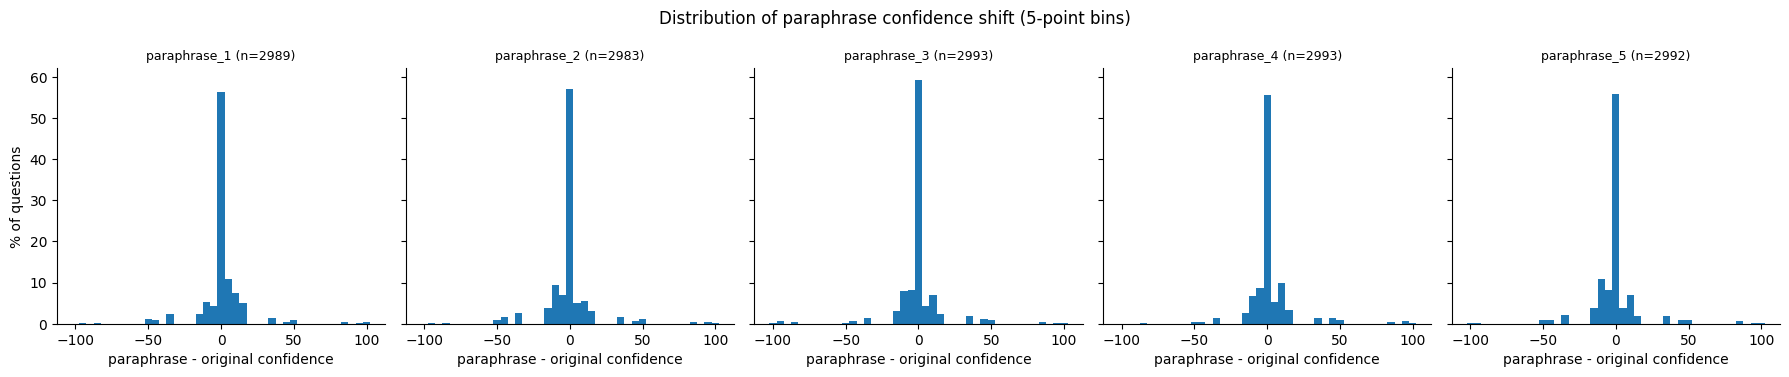

In [198]:
o_all = conf_wide["original"]
rows = []
shift_arrays = {}
for v in PARAPHRASES:
    p_all = conf_wide[v]
    ok = o_all.notna() & p_all.notna()
    o_, p_ = o_all[ok].to_numpy(), p_all[ok].to_numpy()
    d = p_ - o_
    shift_arrays[v] = d
    n_nz = int((d != 0).sum())
    if n_nz > 0:
        stat, pval = wilcoxon_two_sided(d)
        rbc, wp, wn = rank_biserial_paired(d)
    else:
        stat = pval = rbc = wp = wn = np.nan
    rows.append({
        "comparison": f"original vs {v}", "paraphrase": v, "n_pairs": int(ok.sum()),
        "n_nonzero_diff": n_nz, "n_zero_diff": int(ok.sum()) - n_nz,
        "median_original_confidence": float(np.median(o_)), "median_paraphrase_confidence": float(np.median(p_)),
        "median_paired_difference": float(np.median(d)), "mean_paired_difference": float(d.mean()),
        "wilcoxon_statistic": stat, "W_plus": wp, "W_minus": wn,
        "raw_p_value": pval,
    })
para_tests = pd.DataFrame(rows)
para_tests["holm_adjusted_p_value"] = holm_adjust(para_tests["raw_p_value"].to_numpy())
para_tests["significant_holm_alpha_0.05"] = para_tests["holm_adjusted_p_value"] < ALPHA
para_tests["effect_size_name"] = "paired rank-biserial r = (W+ - W-)/(W+ + W-); positive = paraphrase higher"
para_tests["effect_size"] = [rank_biserial_paired(shift_arrays[v])[0] for v in PARAPHRASES]
para_tests["alpha"] = ALPHA

p7_header("PART 1: PAIRED CONFIDENCE TESTS (Wilcoxon signed-rank, Holm-corrected)")
show = ["comparison", "n_pairs", "n_zero_diff", "median_original_confidence", "median_paraphrase_confidence",
        "median_paired_difference", "wilcoxon_statistic", "raw_p_value", "holm_adjusted_p_value",
        "significant_holm_alpha_0.05", "effect_size"]
print(para_tests[show].to_string(index=False, float_format=lambda x: f"{x:.4g}"))
p7_save_table(para_tests, "phase7_confidence_paraphrase_tests.csv")

for _, r in para_tests.iterrows():
    log_test("wilcoxon_signed_rank", r["comparison"] + " (confidence)", int(r["n_pairs"]), r["wilcoxon_statistic"],
             r["raw_p_value"], "paired rank-biserial r", r["effect_size"],
             corrected_p=r["holm_adjusted_p_value"], correction="Holm (family of 5)")

# ---- Plot 3: paraphrase confidence shift distribution ----
edges = np.arange(-102.5, 105, 5)
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8), sharey=True, sharex=True)
for ax, v in zip(axes, PARAPHRASES):
    d = shift_arrays[v]
    ax.hist(d, bins=edges, weights=np.full(len(d), 100.0 / len(d)))
    ax.set_title(f"{v} (n={len(d)})", fontsize=9)
    ax.set_xlabel("paraphrase - original confidence")
axes[0].set_ylabel("% of questions")
fig.suptitle("Distribution of paraphrase confidence shift (5-point bins)")
fig.tight_layout()
p7_save_fig(fig, "phase7_paraphrase_confidence_shift.png")
plt.show()

## 7.2 Part 2: confidence of correct vs incorrect responses

Phase 4 correctness labels, two-sided **Mann-Whitney U** (asymptotic, tie-corrected) on all valid responses. Effect size: rank-biserial `r = 2*U1/(n1*n2) - 1` with group 1 = correct (positive = correct answers have higher confidence), plus the common-language effect size `P(conf_correct > conf_incorrect) + 0.5*P(tie)`.

**Caveat:** this test treats the responses as independent, but 6 responses share a question. So a second, **within-question** sensitivity analysis is added: for questions that have at least one correct and one incorrect variant, the mean confidence of the correct variants is compared with the mean confidence of the incorrect variants (paired Wilcoxon, paired rank-biserial).

In [199]:
x_c = cdf.loc[cdf["correct"], "conf"].to_numpy()
x_i = cdf.loc[~cdf["correct"], "conf"].to_numpy()
mw = mannwhitney(x_c, x_i)

# within-question sensitivity
# boolean column labels are ambiguous in pandas indexing, so rename them to strings first
pq = cdf.groupby(["question_id", "correct"])["conf"].mean().unstack("correct")
pq = pq.rename(columns={True: "correct_mean_conf", False: "incorrect_mean_conf"})
if {"correct_mean_conf", "incorrect_mean_conf"} <= set(pq.columns):
    pq = pq[["correct_mean_conf", "incorrect_mean_conf"]].dropna()
    dq = (pq["correct_mean_conf"] - pq["incorrect_mean_conf"]).to_numpy()
else:
    pq = pd.DataFrame(columns=["correct_mean_conf", "incorrect_mean_conf"])
    dq = np.array([])
print(f"Questions with both correct and incorrect variants (within-question analysis): {len(dq)}")

if np.any(dq != 0):
    wq_stat, wq_p = wilcoxon_two_sided(dq)
    wq_rbc, _, _ = rank_biserial_paired(dq)
else:
    wq_stat = wq_p = wq_rbc = np.nan

ES_MW = "rank-biserial r = 2*U1/(n1*n2) - 1 (group 1 = correct; positive = correct higher)"
ES_PAIR = "paired rank-biserial r (positive = correct-variant mean confidence higher)"
cc_tbl = pd.DataFrame([
    {"analysis": "mann_whitney_u_all_responses", "n_correct": mw["n1"], "n_incorrect": mw["n2"],
     "median_confidence_correct": float(np.median(x_c)), "median_confidence_incorrect": float(np.median(x_i)),
     "statistic_name": "U (correct)", "statistic": mw["U"], "p_value": mw["p"],
     "effect_size_name": ES_MW, "effect_size": mw["rbc"], "common_language_effect_size": mw["cles"],
     "note": "responses treated as independent; see within-question row"},
    {"analysis": "wilcoxon_within_question_mixed_questions", "n_correct": len(dq), "n_incorrect": len(dq),
     "median_confidence_correct": float(pq["correct_mean_conf"].median()) if len(dq) else np.nan,
     "median_confidence_incorrect": float(pq["incorrect_mean_conf"].median()) if len(dq) else np.nan,
     "statistic_name": "Wilcoxon (min(W+,W-))", "statistic": wq_stat, "p_value": wq_p,
     "effect_size_name": ES_PAIR, "effect_size": wq_rbc, "common_language_effect_size": np.nan,
     "note": "n = questions with both correct and incorrect variants; sensitivity analysis respecting question pairing"},
])
cc_tbl["alpha"] = ALPHA
cc_tbl["significant"] = cc_tbl["p_value"] < ALPHA

p7_header("PART 2: CONFIDENCE vs CORRECTNESS")
print(cc_tbl[["analysis", "n_correct", "n_incorrect", "median_confidence_correct", "median_confidence_incorrect",
              "statistic", "p_value", "effect_size", "common_language_effect_size"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4g}"))
p7_save_table(cc_tbl, "phase7_confidence_correctness_test.csv")

log_test("mann_whitney_u", "confidence: correct vs incorrect (all responses)", mw["n1"] + mw["n2"], mw["U"], mw["p"],
         "rank-biserial r", mw["rbc"], note="responses not independent (clustered by question)")
log_test("wilcoxon_signed_rank", "within-question mean confidence: correct vs incorrect variants", len(dq), wq_stat, wq_p,
         "paired rank-biserial r", wq_rbc, note="sensitivity analysis, mixed-correctness questions only")

Questions with both correct and incorrect variants (within-question analysis): 428

PART 2: CONFIDENCE vs CORRECTNESS
                                analysis  n_correct  n_incorrect  median_confidence_correct  median_confidence_incorrect  statistic   p_value  effect_size  common_language_effect_size
            mann_whitney_u_all_responses       2219        15753                        100                           95  2.701e+07         0       0.5453                       0.7726
wilcoxon_within_question_mixed_questions        428          428                         98                           95       8777 2.952e-21       0.6238                          NaN
Saved: /content/drive/MyDrive/Research3/results/phase7_confidence_correctness_test.csv


## 7.3 Part 3: confidence range by correctness group

Groups (Phase 5 definitions, questions with at least 2 valid variants): **A** = all valid variants correct, **B** = all valid variants incorrect, **C** = mixed. The Kruskal-Wallis test compares `confidence_range` across the 3 groups (effect size epsilon-squared). If significant at alpha = 0.05, pairwise Mann-Whitney comparisons are run with Holm correction (descriptive post-hoc; rank-biserial effect size, positive = first group has the larger range).

In [200]:
GROUPS = ["all_correct", "all_incorrect", "mixed"]
GROUP_LABEL = {"all_correct": "A (all correct)", "all_incorrect": "B (all incorrect)", "mixed": "C (mixed)"}
qg = qstab[qstab["confidence_range"].notna() & qstab["correctness_group"].isin(GROUPS)]

grp_tbl = (
    qg.groupby("correctness_group")
    .agg(n_questions=("confidence_range", "size"),
         median_confidence_range=("confidence_range", "median"),
         mean_confidence_range=("confidence_range", "mean"),
         std_confidence_range=("confidence_range", "std"),
         median_num_correct_variants=("num_correct_variants", "median"))
    .reindex(GROUPS).reset_index()
)
grp_tbl.insert(1, "group_label", grp_tbl["correctness_group"].map(GROUP_LABEL))
grp_tbl["n_questions"] = grp_tbl["n_questions"].fillna(0).astype(int)

p7_header("PART 3: CONFIDENCE RANGE BY CORRECTNESS GROUP")
print(grp_tbl.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
p7_save_table(grp_tbl, "phase7_confidence_range_by_correctness_group.csv")

present = [g for g in GROUPS if (qg["correctness_group"] == g).sum() > 0]
samples = {g: qg.loc[qg["correctness_group"] == g, "confidence_range"].to_numpy() for g in present}
n_kw = sum(len(s) for s in samples.values())
H, kw_p = stats.kruskal(*samples.values())
eps2 = float(H * (n_kw + 1) / (n_kw ** 2 - 1))

test_rows = [{
    "test": "kruskal_wallis", "comparison": " vs ".join(present), "n": n_kw,
    "statistic_name": "H", "statistic": float(H), "raw_p_value": float(kw_p), "holm_adjusted_p_value": np.nan,
    "effect_size_name": "epsilon-squared = H*(n+1)/(n^2-1)", "effect_size": eps2,
    "alpha": ALPHA, "significant": bool(kw_p < ALPHA), "note": "omnibus test of confidence_range across groups",
}]
log_test("kruskal_wallis", "confidence_range across correctness groups", n_kw, float(H), float(kw_p),
         "epsilon-squared", eps2)

if kw_p < ALPHA and len(present) >= 2:
    pairs = [(present[i], present[j]) for i in range(len(present)) for j in range(i + 1, len(present))]
    pw = [mannwhitney(samples[a], samples[b]) for a, b in pairs]
    adj = holm_adjust([r["p"] for r in pw])
    for (a, b), r, ap in zip(pairs, pw, adj):
        test_rows.append({
            "test": "posthoc_mann_whitney", "comparison": f"{a} vs {b}", "n": r["n1"] + r["n2"],
            "statistic_name": "U (first group)", "statistic": r["U"], "raw_p_value": r["p"],
            "holm_adjusted_p_value": float(ap),
            "effect_size_name": "rank-biserial r (positive = first group larger range)", "effect_size": r["rbc"],
            "alpha": ALPHA, "significant": bool(ap < ALPHA), "note": f"Holm over {len(pairs)} pairwise comparisons",
        })
        log_test("posthoc_mann_whitney", f"confidence_range: {a} vs {b}", r["n1"] + r["n2"], r["U"], r["p"],
                 "rank-biserial r", r["rbc"], corrected_p=float(ap), correction=f"Holm (family of {len(pairs)})")
else:
    test_rows.append({"test": "posthoc_mann_whitney", "comparison": "not performed (omnibus not significant)",
                      "n": np.nan, "statistic_name": "", "statistic": np.nan, "raw_p_value": np.nan,
                      "holm_adjusted_p_value": np.nan, "effect_size_name": "", "effect_size": np.nan,
                      "alpha": ALPHA, "significant": False, "note": ""})

group_test = pd.DataFrame(test_rows)
p7_header("PART 3: KRUSKAL-WALLIS + POST-HOC")
print(group_test.drop(columns=["note"]).to_string(index=False, float_format=lambda x: f"{x:.4g}"))
p7_save_table(group_test, "phase7_correctness_group_test.csv")


PART 3: CONFIDENCE RANGE BY CORRECTNESS GROUP
correctness_group       group_label  n_questions  median_confidence_range  mean_confidence_range  std_confidence_range  median_num_correct_variants
      all_correct   A (all correct)          135                    0.000                  1.296                 2.283                        6.000
    all_incorrect B (all incorrect)         2437                   15.000                 20.351                22.167                        0.000
            mixed         C (mixed)          428                    5.000                  7.699                 9.164                        4.000
Saved: /content/drive/MyDrive/Research3/results/phase7_confidence_range_by_correctness_group.csv

PART 3: KRUSKAL-WALLIS + POST-HOC
                test                            comparison    n  statistic_name  statistic  raw_p_value  holm_adjusted_p_value                                      effect_size_name  effect_size  alpha  significant
      kruskal_w

## 7.4 Part 4: confidence instability vs correctness instability (Spearman)

Per question (at least 2 valid variants): `confidence_range` and `correctness_rate`.

- `correctness_instability = 1 - correctness_rate` (**as specified**). Note that this is the question's **error rate**: a question that is wrong in all 6 variants gets 1.0 even though its correctness is perfectly stable.
- Because of that, a second measure is added as a sensitivity analysis: `correctness_disagreement = 2 * min(rate, 1 - rate)`: 0 when all variants agree on correctness (all right or all wrong), 1 when split 50/50.

Spearman rank correlation, two-sided. A correlation is not evidence of causation. Plot 1 shows both measures (small deterministic jitter is added to the points only for visibility; the statistics use the raw values).


PART 4: CONFIDENCE RANGE vs CORRECTNESS INSTABILITY (Spearman)
                 measure        role  n_questions  spearman_rho    p_value  alpha  significant
 correctness_instability     primary         3000        0.3745 1.679e-100   0.05         True
correctness_disagreement sensitivity         3000       -0.2197  4.153e-34   0.05         True
Saved: /content/drive/MyDrive/Research3/results/phase7_confidence_correctness_correlation.csv
Saved: /content/drive/MyDrive/Research3/figures/phase7_confidence_vs_correctness_instability.png


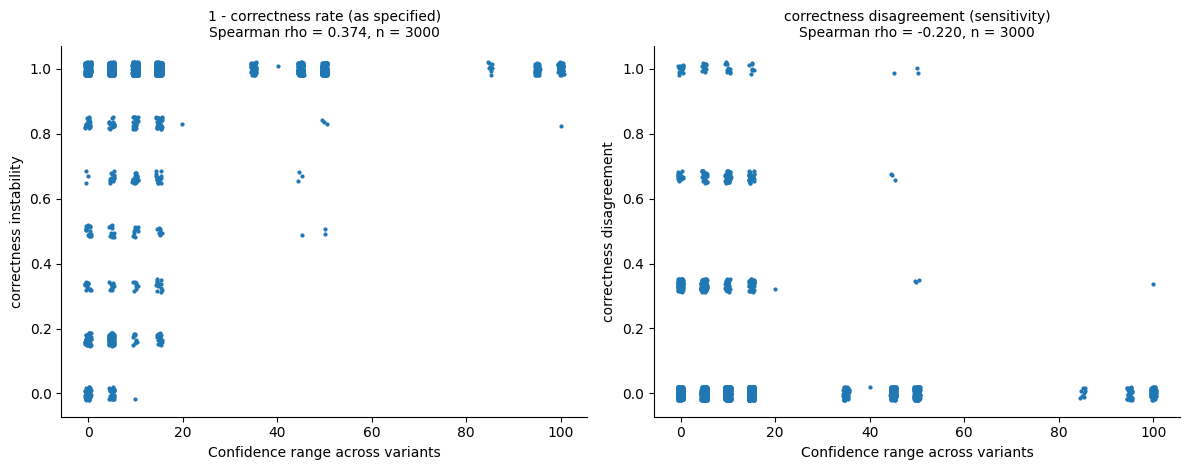

In [201]:
cq = qstab.loc[qstab["confidence_range"].notna() & qstab["correctness_rate"].notna(),
               ["confidence_range", "correctness_rate", "num_valid_variants", "num_correct_variants"]].copy()
cq["correctness_instability"] = 1 - cq["correctness_rate"]
cq["correctness_disagreement"] = 2 * np.minimum(cq["correctness_rate"], 1 - cq["correctness_rate"])

corr_rows = []
for measure, definition, tag in [
    ("correctness_instability", "1 - correctness_rate (as specified; equals the question's error rate)", "primary"),
    ("correctness_disagreement", "2*min(rate, 1-rate) (0 = variants agree on correctness, 1 = 50/50 split)", "sensitivity"),
]:
    rho, pval = stats.spearmanr(cq["confidence_range"], cq[measure])
    corr_rows.append({"measure": measure, "definition": definition, "role": tag, "n_questions": len(cq),
                      "spearman_rho": float(rho), "p_value": float(pval), "alpha": ALPHA,
                      "significant": bool(pval < ALPHA)})
    log_test("spearman_correlation", f"confidence_range vs {measure}", len(cq), float(rho), float(pval),
             "Spearman rho", float(rho), note=f"{tag}; correlation, not causation")
corr_tbl = pd.DataFrame(corr_rows)

p7_header("PART 4: CONFIDENCE RANGE vs CORRECTNESS INSTABILITY (Spearman)")
print(corr_tbl.drop(columns=["definition"]).to_string(index=False, float_format=lambda x: f"{x:.4g}"))
p7_save_table(corr_tbl, "phase7_confidence_correctness_correlation.csv")

# ---- Plot 1 ----
p7_rng = np.random.default_rng(P7_SEED)
jx = cq["confidence_range"].to_numpy() + p7_rng.uniform(-0.6, 0.6, len(cq))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
for ax, (m, title) in zip(axes, [("correctness_instability", "1 - correctness rate (as specified)"),
                                 ("correctness_disagreement", "correctness disagreement (sensitivity)")]):
    jy = cq[m].to_numpy() + p7_rng.uniform(-0.02, 0.02, len(cq))
    ax.scatter(jx, jy, s=4)
    rho_ = corr_tbl.loc[corr_tbl["measure"] == m, "spearman_rho"].iloc[0]
    ax.set_title(f"{title}\nSpearman rho = {rho_:.3f}, n = {len(cq)}", fontsize=10)
    ax.set_xlabel("Confidence range across variants")
    ax.set_ylabel(m.replace("_", " "))
fig.tight_layout()
p7_save_fig(fig, "phase7_confidence_vs_correctness_instability.png")
plt.show()

## 7.5 Part 5: descriptive comparison of thresholds 50-90 (no inference)

Thresholds are nested decisions over the same responses, so no test is run. The table gives coverage, selective risk, abstention flip rate and mean decision consistency, and then lists the threshold(s) that satisfy each **explicitly defined** criterion. Ties are reported as sets (not broken arbitrarily). None of these criteria defines an "optimal" threshold.

In [202]:
t5d = thr_tbl[thr_tbl["threshold"].isin(MAIN_THRESHOLDS)].set_index("threshold")[["coverage", "selective_risk"]].copy()
t5d["abstention_flip_rate"] = flip_tbl[flip_tbl["variant"] == "all_paraphrases"].set_index("threshold")["abstention_flip_rate"]
t5d["mean_decision_consistency"] = stab_summary.set_index("threshold")["mean_decision_consistency"]

p7_header("PART 5: THRESHOLD COMPARISON (descriptive)")
print(t5d.to_string(float_format=lambda x: f"{x:.4f}"))


def tied_argbest(series, mode):
    best = series.min() if mode == "min" else series.max()
    return [int(t) for t in series.index[np.isclose(series.to_numpy(), best, rtol=0, atol=1e-12)]], float(best)


low_risk_set, low_risk_val = tied_argbest(t5d["selective_risk"], "min")
cov_in_low = t5d.loc[low_risk_set, "coverage"]
hi_cov_set, hi_cov_val = tied_argbest(cov_in_low, "max")
low_flip_set, low_flip_val = tied_argbest(t5d["abstention_flip_rate"], "min")
hi_cons_set, hi_cons_val = tied_argbest(t5d["mean_decision_consistency"], "max")

part5 = {
    "lowest_selective_risk": {"thresholds": low_risk_set, "value": low_risk_val},
    "highest_coverage_among_lowest_risk": {"thresholds": hi_cov_set, "value": hi_cov_val},
    "lowest_abstention_flip_rate": {"thresholds": low_flip_set, "value": low_flip_val},
    "highest_mean_decision_consistency": {"thresholds": hi_cons_set, "value": hi_cons_val},
}
print("\nCriteria (thresholds 50-90 only; ties shown as sets):")
print(f"  Lowest selective risk:                         {low_risk_set} (risk = {low_risk_val:.4f})")
print(f"  Highest coverage among the lowest-risk set:    {hi_cov_set} (coverage = {hi_cov_val:.4f})")
print(f"  Lowest abstention flip rate:                   {low_flip_set} (flip rate = {low_flip_val:.4f})")
print(f"  Highest mean decision consistency:             {hi_cons_set} (consistency = {hi_cons_val:.4f})")
print("\nThese are criteria-based descriptions only; no threshold is declared optimal.")


PART 5: THRESHOLD COMPARISON (descriptive)
           coverage  selective_risk  abstention_flip_rate  mean_decision_consistency
threshold                                                                           
50           0.9925          0.8756                0.0158                     0.9929
60           0.9402          0.8687                0.0811                     0.9472
70           0.9402          0.8687                0.0812                     0.9471
80           0.9402          0.8687                0.0812                     0.9471
90           0.6937          0.8291                0.2571                     0.8180

Criteria (thresholds 50-90 only; ties shown as sets):
  Lowest selective risk:                         [90] (risk = 0.8291)
  Highest coverage among the lowest-risk set:    [90] (coverage = 0.6937)
  Lowest abstention flip rate:                   [50] (flip rate = 0.0158)
  Highest mean decision consistency:             [50] (consistency = 0.9929)

These are

## 7.6 Part 6: bootstrap confidence intervals (resampling `question_id`)

The 3,000 `question_id`s are resampled **with replacement** (the unit is the question, not the response row; all of a question's 6 responses move together). Per bootstrap sample, metrics are recomputed on the pooled responses of the resampled questions.

Metrics: overall accuracy, mean confidence, mean and median confidence range (questions with at least 2 valid values), and at threshold 90: coverage, selective accuracy, selective risk, abstention flip rate (pooled over 5 paraphrases) and mean decision consistency. Intervals are **95% percentile** intervals. `N_BOOTSTRAP = 2000`, seed 42.

The same per-question arrays are reused in Part 7. The point estimates are checked against the Phase 5/6 numbers.

In [203]:
import time

Q = len(all_ids)
conf_arr = conf_wide.to_numpy(dtype=float)                          # Q x 6, VARIANTS order, NaN = invalid/missing
valid = ~np.isnan(conf_arr)
cor_wide = cdf.pivot(index="question_id", columns="variant", values="correct").reindex(index=all_ids, columns=VARIANTS)
cor_bool = cor_wide.eq(True).to_numpy()
assert not (cor_bool & ~valid).any(), "A correct label exists where confidence is not valid."
assert (cor_wide.notna().to_numpy() == valid).all(), "Correctness and confidence validity do not line up."

nv = valid.sum(axis=1).astype(float)
n_correct_q = (cor_bool & valid).sum(axis=1).astype(float)
sum_conf_q = np.where(valid, conf_arr, 0.0).sum(axis=1)
range_q = qstab["confidence_range"].reindex(all_ids).to_numpy(dtype=float)


def thr_arrays(T):
    """Per-question arrays for threshold T (answer if confidence >= T)."""
    ans = np.where(valid, conf_arr, -1.0) >= T
    n_ans = ans.sum(axis=1)
    n_cor_ans = (ans & cor_bool).sum(axis=1)
    flips = np.zeros(Q)
    pairs = np.zeros(Q)
    for j in range(1, len(VARIANTS)):                                # VARIANTS[0] = original
        ok = valid[:, 0] & valid[:, j]
        pairs += ok
        flips += ok & (ans[:, 0] != ans[:, j])
    cons = np.where(nv >= 2, np.maximum(n_ans, nv - n_ans) / np.maximum(nv, 1), np.nan)
    return {"n_ans": n_ans.astype(float), "n_cor_ans": n_cor_ans.astype(float),
            "flips": flips, "pairs": pairs, "cons": cons}


def _div(a, b):
    return a / b if b > 0 else np.nan


def wmean(w, x):
    m = ~np.isnan(x)
    den = w[m].sum()
    return float((w[m] * x[m]).sum() / den) if den > 0 else np.nan


def wmedian(w, x):
    m = ~np.isnan(x)
    return float(np.median(np.repeat(x[m], w[m].astype(int)))) if w[m].sum() > 0 else np.nan


def all_metrics(w, a):
    tv = w @ nv
    ans_tot = w @ a["n_ans"]
    sel_acc = _div(w @ a["n_cor_ans"], ans_tot)
    return {
        "overall_accuracy": _div(w @ n_correct_q, tv),
        "mean_confidence": _div(w @ sum_conf_q, tv),
        "mean_confidence_range": wmean(w, range_q),
        "median_confidence_range": wmedian(w, range_q),
        "t90_coverage": _div(ans_tot, tv),
        "t90_selective_accuracy": sel_acc,
        "t90_selective_risk": 1 - sel_acc if not np.isnan(sel_acc) else np.nan,
        "t90_abstention_flip_rate": _div(w @ a["flips"], w @ a["pairs"]),
        "t90_mean_decision_consistency": wmean(w, a["cons"]),
    }


a90 = thr_arrays(90)
point = all_metrics(np.ones(Q), a90)

# ---- consistency checks against Phase 5 / Phase 6 ----
r90 = thr_tbl.set_index("threshold").loc[90]
f90 = flip_tbl[(flip_tbl["variant"] == "all_paraphrases") & (flip_tbl["threshold"] == 90)]["abstention_flip_rate"].iloc[0]
c90 = stab_summary.set_index("threshold").loc[90, "mean_decision_consistency"]
assert np.isclose(point["overall_accuracy"], acc_conf_set), "accuracy differs from Phase 5"
assert np.isclose(point["mean_confidence"], cdf["conf"].mean()), "mean confidence differs from Phase 5"
assert np.isclose(point["mean_confidence_range"], qstab["confidence_range"].mean()), "mean range differs from Phase 5"
assert np.isclose(point["t90_coverage"], r90["coverage"]), "T90 coverage differs from Phase 6"
assert np.isclose(point["t90_selective_risk"], r90["selective_risk"]), "T90 risk differs from Phase 6"
assert np.isclose(point["t90_abstention_flip_rate"], f90), "T90 flip rate differs from Phase 6"
assert np.isclose(point["t90_mean_decision_consistency"], c90), "T90 consistency differs from Phase 6"
print("Point estimates match Phase 5 and Phase 6.")

# ---- bootstrap over question_id ----
p7_rng = np.random.default_rng(P7_SEED)
t0 = time.time()
boot = []
for _ in range(N_BOOTSTRAP):
    idx = p7_rng.integers(0, Q, size=Q)                       # resample question indices with replacement
    w = np.bincount(idx, minlength=Q).astype(float)           # multiplicity of each question
    boot.append(all_metrics(w, a90))
boot_df = pd.DataFrame(boot)
print(f"Bootstrap done: {N_BOOTSTRAP} iterations over {Q} questions in {time.time() - t0:.1f}s")

ci_rows = []
for m in boot_df.columns:
    vals = boot_df[m].to_numpy()
    lo, hi = np.nanpercentile(vals, [2.5, 97.5])
    ci_rows.append({"metric": m, "point_estimate": point[m], "ci_lower_2.5": float(lo), "ci_upper_97.5": float(hi),
                    "bootstrap_mean": float(np.nanmean(vals)), "bootstrap_std": float(np.nanstd(vals, ddof=1)),
                    "n_bootstrap": N_BOOTSTRAP, "n_valid_bootstrap_values": int(np.sum(~np.isnan(vals))),
                    "seed": P7_SEED, "resampling_unit": "question_id", "interval": "95% percentile"})
ci_tbl = pd.DataFrame(ci_rows)

p7_header("PART 6: BOOTSTRAP 95% PERCENTILE CIs (resampling question_id)")
print(ci_tbl[["metric", "point_estimate", "ci_lower_2.5", "ci_upper_97.5"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))
p7_save_table(ci_tbl, "phase7_bootstrap_ci.csv")

Point estimates match Phase 5 and Phase 6.
Bootstrap done: 2000 iterations over 3000 questions in 0.9s

PART 6: BOOTSTRAP 95% PERCENTILE CIs (resampling question_id)
                       metric  point_estimate  ci_lower_2.5  ci_upper_97.5
             overall_accuracy          0.1235        0.1136         0.1336
              mean_confidence         90.8555       90.5465        91.1617
        mean_confidence_range         17.6883       16.9915        18.4500
      median_confidence_range         10.0000       10.0000        10.0000
                 t90_coverage          0.6937        0.6829         0.7046
       t90_selective_accuracy          0.1709        0.1572         0.1848
           t90_selective_risk          0.8291        0.8152         0.8428
     t90_abstention_flip_rate          0.2571        0.2472         0.2666
t90_mean_decision_consistency          0.8180        0.8119         0.8239
Saved: /content/drive/MyDrive/Research3/results/phase7_bootstrap_ci.csv


## 7.7 Part 7: threshold sensitivity (0 to 100, step 5)

Coverage, abstention rate, selective accuracy, selective risk, abstention flip rate (pooled over the 5 paraphrases, valid pairs only) and mean decision consistency (questions with at least 2 valid variants) for every threshold 0, 5, ..., 100. At T = 0 nothing is abstained (flip rate 0, consistency 1 by construction). If no response is answered at some T, selective accuracy/risk are left empty.

This is a robustness check only. No "best threshold" is selected.

Fine-threshold table agrees with Phase 6 at 50/60/70/80/90.

PART 7: THRESHOLD SENSITIVITY
 threshold  answered  coverage  abstention_rate  selective_accuracy  selective_risk  abstention_flip_rate  mean_decision_consistency
         0     17972    1.0000           0.0000              0.1235          0.8765                0.0000                     1.0000
         5     17838    0.9925           0.0075              0.1244          0.8756                0.0158                     0.9929
        10     17838    0.9925           0.0075              0.1244          0.8756                0.0158                     0.9929
        15     17838    0.9925           0.0075              0.1244          0.8756                0.0158                     0.9929
        20     17838    0.9925           0.0075              0.1244          0.8756                0.0158                     0.9929
        25     17838    0.9925           0.0075              0.1244          0.8756                0.0158      

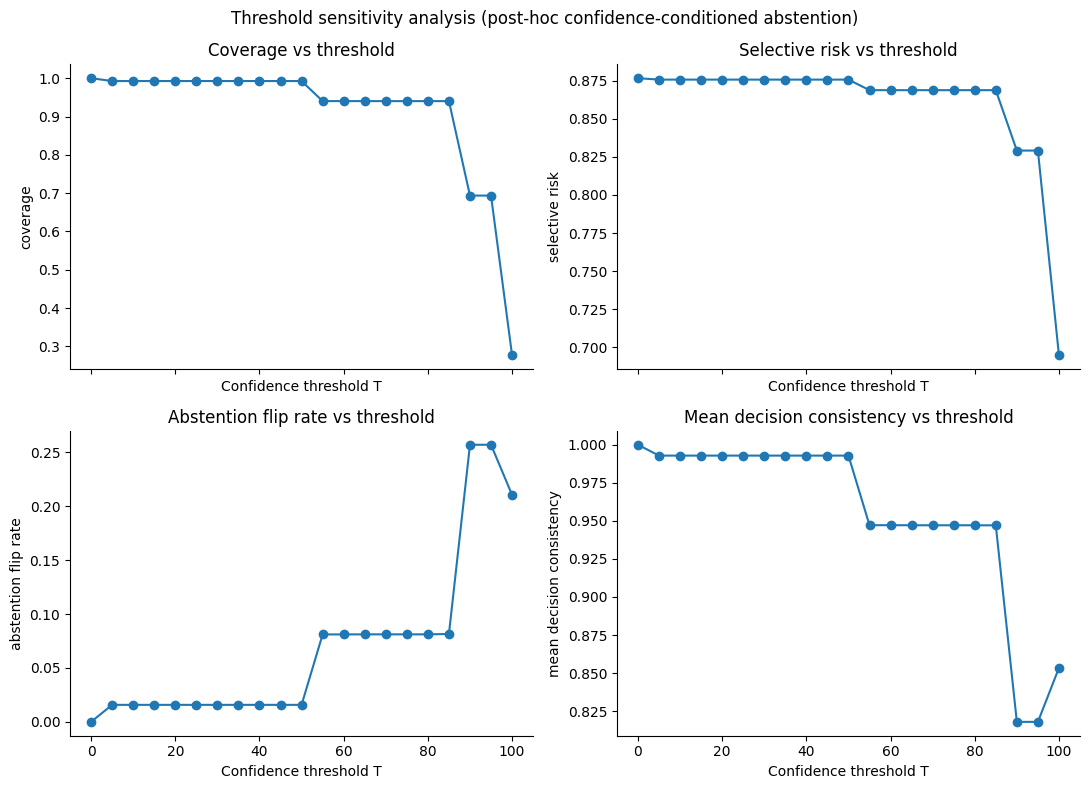

In [204]:
sens_rows = []
for T in FINE_THRESHOLDS:
    r = selective_stats(vd, T)
    a = thr_arrays(T)
    m = ~np.isnan(a["cons"])
    r["abstention_flip_rate"] = _div(a["flips"].sum(), a["pairs"].sum())
    r["valid_pairs"] = int(a["pairs"].sum())
    r["mean_decision_consistency"] = float(a["cons"][m].mean()) if m.any() else np.nan
    r["questions_with_2plus_valid"] = int(m.sum())
    sens_rows.append(r)
sens_tbl = pd.DataFrame(sens_rows)

# cross-check the main thresholds against Phase 6
for T in MAIN_THRESHOLDS:
    s = sens_tbl[sens_tbl["threshold"] == T].iloc[0]
    f_ = flip_tbl[(flip_tbl["variant"] == "all_paraphrases") & (flip_tbl["threshold"] == T)]["abstention_flip_rate"].iloc[0]
    c_ = stab_summary.set_index("threshold").loc[T, "mean_decision_consistency"]
    assert np.isclose(s["abstention_flip_rate"], f_) and np.isclose(s["mean_decision_consistency"], c_), f"Mismatch at T={T}"
print("Fine-threshold table agrees with Phase 6 at 50/60/70/80/90.")

p7_header("PART 7: THRESHOLD SENSITIVITY")
print(sens_tbl[["threshold", "answered", "coverage", "abstention_rate", "selective_accuracy", "selective_risk",
                "abstention_flip_rate", "mean_decision_consistency"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4f}"))
p7_save_table(sens_tbl, "phase7_threshold_sensitivity.csv")

# ---- Plot 2 ----
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for ax, (col, ttl) in zip(axes.ravel(), [
    ("coverage", "Coverage vs threshold"),
    ("selective_risk", "Selective risk vs threshold"),
    ("abstention_flip_rate", "Abstention flip rate vs threshold"),
    ("mean_decision_consistency", "Mean decision consistency vs threshold"),
]):
    ax.plot(sens_tbl["threshold"], sens_tbl[col], marker="o")
    ax.set_title(ttl)
    ax.set_xlabel("Confidence threshold T")
    ax.set_ylabel(col.replace("_", " "))
fig.suptitle("Threshold sensitivity analysis (post-hoc confidence-conditioned abstention)")
fig.tight_layout()
p7_save_fig(fig, "phase7_threshold_sensitivity.png")
plt.show()

## 7.8 Part 8: calibration sensitivity to binning

ECE is recomputed with 5, 10 and 20 **equal-width** bins on the 0-100 confidence scale (bin = `min(floor(confidence / width), n_bins - 1)`; last bin includes 100). ECE = sum over non-empty bins of `(bin_count / N) * |bin_accuracy - bin_mean_confidence/100|`. The Brier score does not depend on binning. The 10-bin value must equal the Phase 5 ECE.

No binning scheme is treated as universally correct; this only checks whether the calibration conclusion depends strongly on the choice.

In [205]:
conf_v = cdf["conf"].to_numpy(dtype=float)
y_v = cdf["y"].to_numpy(dtype=float)


def ece_nbins(conf, y, nbins):
    width = 100.0 / nbins
    idx = np.minimum(np.floor(conf / width).astype(int), nbins - 1)
    N_ = len(conf)
    total, nonempty = 0.0, 0
    for b in range(nbins):
        m = idx == b
        n_b = int(m.sum())
        if n_b == 0:
            continue
        nonempty += 1
        total += (n_b / N_) * abs(y[m].mean() - conf[m].mean() / 100.0)
    return float(total), nonempty


brier_now = float(((conf_v / 100.0 - y_v) ** 2).mean())
assert np.isclose(brier_now, BRIER), "Brier score differs from Phase 5"

cal_rows = []
for nb in (5, 10, 20):
    e, ne_ = ece_nbins(conf_v, y_v, nb)
    cal_rows.append({"n_bins": nb, "bin_width": 100 / nb,
                     "bin_definition": f"{nb} equal-width bins on 0-100, last bin includes 100",
                     "ece": e, "non_empty_bins": ne_, "brier_score": brier_now, "n_responses": len(conf_v)})
cal_sens = pd.DataFrame(cal_rows)
assert np.isclose(cal_sens.loc[cal_sens["n_bins"] == 10, "ece"].iloc[0], ECE), "10-bin ECE differs from Phase 5"

p7_header("PART 8: CALIBRATION SENSITIVITY")
print(cal_sens[["n_bins", "bin_width", "ece", "non_empty_bins", "brier_score", "n_responses"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4f}"))
p7_save_table(cal_sens, "phase7_calibration_sensitivity.csv")


PART 8: CALIBRATION SENSITIVITY
 n_bins  bin_width    ece  non_empty_bins  brier_score  n_responses
      5    20.0000 0.7851               4       0.7256        17972
     10    10.0000 0.7851               5       0.7256        17972
     20     5.0000 0.7851               6       0.7256        17972
Saved: /content/drive/MyDrive/Research3/results/phase7_calibration_sensitivity.csv


## 7.9 Part 9: paraphrase-level robustness summary

One row per variant (`original` is included as the reference row): valid responses, accuracy, mean/median confidence, confidence shift from the original (paraphrase - original, paired by question), and the abstention flip rate vs original at threshold 90 (plus coverage and selective risk at T = 90).

In [206]:
s0 = vt_tbl[vt_tbl["threshold"] == 0].set_index("variant")[["valid_responses", "selective_accuracy"]] \
    .rename(columns={"selective_accuracy": "accuracy"})
s90 = vt_tbl[vt_tbl["threshold"] == 90].set_index("variant")[["coverage", "selective_risk"]] \
    .rename(columns={"coverage": "coverage_T90", "selective_risk": "selective_risk_T90"})
bv = by_variant.set_index("variant")[["mean_confidence", "median_confidence", "mean_conf_correct", "mean_conf_incorrect"]]
sh = shift_tbl.set_index("variant")[["valid_pairs", "mean_shift", "median_shift", "std_shift", "mean_abs_shift"]] \
    .rename(columns={"valid_pairs": "valid_pairs_confidence_shift", "mean_shift": "mean_confidence_shift_from_original",
                     "median_shift": "median_confidence_shift_from_original", "std_shift": "std_confidence_shift",
                     "mean_abs_shift": "mean_abs_confidence_shift"})
fl = flip_tbl[flip_tbl["threshold"] == 90].set_index("variant")[["valid_pairs", "decision_flips", "abstention_flip_rate"]] \
    .rename(columns={"valid_pairs": "valid_pairs_T90", "decision_flips": "decision_flips_T90",
                     "abstention_flip_rate": "abstention_flip_rate_T90"})

para_sum = s0.join(bv).join(s90).reindex(VARIANTS)
para_sum = para_sum.join(sh).join(fl.drop(index="all_paraphrases", errors="ignore"))
para_sum["accuracy_diff_vs_original"] = para_sum["accuracy"] - para_sum.loc["original", "accuracy"]
para_sum = para_sum.rename_axis("variant").reset_index()
para_sum["valid_responses"] = para_sum["valid_responses"].astype(int)

p7_header("PART 9: PARAPHRASE-LEVEL ROBUSTNESS SUMMARY")
print(para_sum[["variant", "valid_responses", "accuracy", "accuracy_diff_vs_original", "mean_confidence",
                "mean_confidence_shift_from_original", "abstention_flip_rate_T90", "coverage_T90",
                "selective_risk_T90"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))
p7_save_table(para_sum, "phase7_paraphrase_robustness_summary.csv")


PART 9: PARAPHRASE-LEVEL ROBUSTNESS SUMMARY
     variant  valid_responses  accuracy  accuracy_diff_vs_original  mean_confidence  mean_confidence_shift_from_original  abstention_flip_rate_T90  coverage_T90  selective_risk_T90
    original             2994    0.1386                     0.0000          90.6196                                  NaN                       NaN        0.6974              0.8103
paraphrase_1             2995    0.1209                    -0.0177          91.4908                               0.8949                    0.2422        0.7429              0.8431
paraphrase_2             2989    0.1134                    -0.0252          89.9967                              -0.6604                    0.2598        0.6424              0.8359
paraphrase_3             2999    0.1270                    -0.0116          90.2434                              -0.3826                    0.2422        0.6872              0.8219
paraphrase_4             2998    0.1144           

## 7.10 Correctness sanity check (inspection only)

Because overall accuracy is only about 12%, a deterministic random sample of 100 valid responses (seed 42, drawn from the responses in dataset order) is printed with the question, the model answer, the gold aliases and the Phase 4 label. The column `answer_contains_gold_alias_phrase` is the same **diagnostic** flag as in Phase 4 cell 4.4 (an incorrect answer that contains a gold alias as a whole phrase). **No label is changed and no rule is replaced.** The purpose is only to see whether the strict exact-match rule behaves sensibly; any decision about the rule is made separately.

In [207]:
san = cdf.copy()
san["_q"] = san["question_id"].map(q_pos)
san["_v"] = san["variant"].map(v_pos)
san = san.sort_values(["_q", "_v"]).reset_index(drop=True)

n_s = min(SANITY_SAMPLE_SIZE, len(san))
p7_rng = np.random.default_rng(P7_SEED)
pick = np.sort(p7_rng.choice(len(san), size=n_s, replace=False))
samp = san.iloc[pick].copy()
samp["answer_contains_gold_alias_phrase"] = [
    contains_gold_phrase(normalize_answer(a), g) for a, g in zip(samp["answer"], samp["gold_norms"])
]
samp["phase4_label"] = np.where(samp["correct"], "correct", "incorrect")
samp["gold_aliases"] = samp["gold_list"].map(lambda l: json.dumps(l, ensure_ascii=False))

sanity_out = samp[["question_id", "variant", "question", "answer", "gold_aliases", "phase4_label",
                   "match_type", "answer_contains_gold_alias_phrase", "conf"]].rename(columns={"conf": "confidence"})
p7_save_table(sanity_out, "phase7_correctness_sanity_sample.csv")

p7_header(f"CORRECTNESS SANITY SAMPLE ({n_s} responses, seed {P7_SEED}) - inspection only")
for k, (_, r) in enumerate(samp.iterrows(), start=1):
    gold = r["gold_list"]
    gold_txt = ", ".join(repr(a) for a in gold[:5]) + (f" (+{len(gold) - 5} more)" if len(gold) > 5 else "")
    flag = " | contains gold phrase" if r["answer_contains_gold_alias_phrase"] and not r["correct"] else ""
    print(f"{k:3d}. [{r['question_id']} | {r['variant']}] {r['question']}")
    print(f"     answer: {r['answer']!r} | gold: {gold_txt} | Phase 4: {r['phase4_label']} ({r['match_type']}){flag}")

n_inc_s = int((~samp["correct"]).sum())
n_inc_contains_s = int((~samp["correct"] & samp["answer_contains_gold_alias_phrase"]).sum())
all_inc = cdf[~cdf["correct"]]
n_inc_contains_all = int(sum(contains_gold_phrase(normalize_answer(a), g) for a, g in zip(all_inc["answer"], all_inc["gold_norms"])))
print(f"\nSample: {int(samp['correct'].sum())} correct, {n_inc_s} incorrect; "
      f"{n_inc_contains_s} of the incorrect contain a gold alias as a whole phrase.")
print(f"All valid responses: {n_inc_contains_all} of {len(all_inc)} incorrect answers "
      f"({100 * n_inc_contains_all / max(len(all_inc), 1):.1f}%) contain a gold alias as a whole phrase "
      f"(diagnostic only, NOT counted as correct).")
print("Labels were NOT modified.")

Saved: /content/drive/MyDrive/Research3/results/phase7_correctness_sanity_sample.csv

CORRECTNESS SANITY SAMPLE (100 responses, seed 42) - inspection only
  1. [6055820 | paraphrase_1] What is the occupation of Tor Aulin?
     answer: 'actor' | gold: 'composer' | Phase 4: incorrect (none)
  2. [141296 | paraphrase_4] What job does Walter K√∂bel do?
     answer: 'Walter Kober is known for his work as an actor.' | gold: 'politician', 'political leader', 'political figure', 'polit.', 'pol' | Phase 4: incorrect (none)
  3. [5241280 | original] Who was the composer of I Heart Huckabees?
     answer: 'Mark Mothersbaugh' | gold: 'Jon Brion' | Phase 4: incorrect (none)
  4. [2104045 | paraphrase_3] Who is the screenwriter of The Descendants?
     answer: 'Alexander Payne' | gold: 'Nat Faxon', 'Nathaniel Faxon', 'Alexander Payne', 'Jim Rash', 'James Rash' | Phase 4: correct (exact)
  5. [3903442 | paraphrase_2] Who directed the work Desire?
     answer: "No director for 'Desire'" | gold: 'Eddie

## 7.11 Part 10: record of all inferential tests

Every inferential test run in this phase (Wilcoxon x5 with Holm, Mann-Whitney, within-question sensitivity Wilcoxon, Kruskal-Wallis, post-hoc if performed, Spearman x2) is listed, including non-significant ones. `significant` uses the corrected p-value where a correction applies, otherwise the raw p-value, at alpha = 0.05. Significance is not practical importance.

In [208]:
tests_summary = pd.DataFrame(tests_log)
p7_header("PART 10: ALL INFERENTIAL TESTS")
print(tests_summary[["test_name", "comparison", "n", "raw_p_value", "corrected_p_value", "effect_size_name",
                     "effect_size", "significant"]].to_string(
    index=False, float_format=lambda x: f"{x:.4g}", max_colwidth=60))
print(f"\nTests performed: {len(tests_summary)} | significant at alpha={ALPHA}: {int(tests_summary['significant'].sum())} "
      f"| not significant: {int((~tests_summary['significant']).sum())}")
p7_save_table(tests_summary, "phase7_statistical_tests_summary.csv")


PART 10: ALL INFERENTIAL TESTS
           test_name                                                   comparison     n  raw_p_value  corrected_p_value       effect_size_name  effect_size  significant
wilcoxon_signed_rank                        original vs paraphrase_1 (confidence)  2989    1.501e-06          3.527e-06 paired rank-biserial r       0.1523         True
wilcoxon_signed_rank                        original vs paraphrase_2 (confidence)  2983    3.639e-07          1.455e-06 paired rank-biserial r      -0.1626         True
wilcoxon_signed_rank                        original vs paraphrase_3 (confidence)  2993       0.2327             0.2327 paired rank-biserial r     -0.03897        False
wilcoxon_signed_rank                        original vs paraphrase_4 (confidence)  2993    2.841e-08          1.421e-07 paired rank-biserial r       0.1736         True
wilcoxon_signed_rank                        original vs paraphrase_5 (confidence)  2992    1.176e-06          3.527e-06 pai

## 7.12 Reproducibility record and final summary

Saves `phase7_run_summary.json` and prints the Phase 7 summary and all generated file paths.

In [209]:
def _j(x):
    if x is None:
        return None
    if isinstance(x, (np.floating, float)):
        return None if np.isnan(x) else float(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.bool_,)):
        return bool(x)
    return x


ci = ci_tbl.set_index("metric")
mw_row = cc_tbl.iloc[0]
corr_primary = corr_tbl[corr_tbl["role"] == "primary"].iloc[0]
n_sig_holm = int(para_tests["significant_holm_alpha_0.05"].sum())
r90 = thr_tbl.set_index("threshold").loc[90]
f90 = flip_tbl[(flip_tbl["variant"] == "all_paraphrases") & (flip_tbl["threshold"] == 90)]["abstention_flip_rate"].iloc[0]
c90_mean = stab_summary.set_index("threshold").loc[90, "mean_decision_consistency"]
c90_med = stab_summary.set_index("threshold").loc[90, "median_decision_consistency"]

phase7_record = {
    "model_name": MODEL_NAME_P4,
    "num_questions": len(all_ids),
    "num_valid_responses": int(n_valid),
    "alpha": ALPHA, "n_bootstrap": N_BOOTSTRAP, "seed": P7_SEED, "bootstrap_unit": "question_id",
    "sanity_sample_size": int(n_s),
    "note": "Confidence is self-reported; analysis is descriptive/inferential, no causal claims; Phase 4 correctness unchanged.",
    "confidence_vs_correctness": {k: _j(mw_row[k]) for k in
        ["n_correct", "n_incorrect", "median_confidence_correct", "median_confidence_incorrect", "statistic",
         "p_value", "effect_size", "common_language_effect_size"]},
    "within_question_sensitivity": {k: _j(cc_tbl.iloc[1][k]) for k in ["n_correct", "statistic", "p_value", "effect_size"]},
    "paraphrase_confidence_tests": para_tests[["comparison", "n_pairs", "median_paired_difference", "raw_p_value",
                                               "holm_adjusted_p_value", "significant_holm_alpha_0.05", "effect_size"]]
        .map(_j).to_dict(orient="records"),
    "num_paraphrase_tests_significant_after_holm": n_sig_holm,
    "kruskal_wallis": {"H": _j(H), "p_value": _j(kw_p), "epsilon_squared": _j(eps2), "n": int(n_kw)},
    "confidence_range_by_group": grp_tbl.map(_j).to_dict(orient="records"),
    "spearman_primary": {"measure": "correctness_instability = 1 - correctness_rate", "rho": _j(corr_primary["spearman_rho"]),
                         "p_value": _j(corr_primary["p_value"]), "n_questions": int(corr_primary["n_questions"])},
    "spearman_all": corr_tbl.map(_j).to_dict(orient="records"),
    "threshold_comparison_descriptive": part5,
    "threshold_90": {"coverage": _j(r90["coverage"]), "selective_accuracy": _j(r90["selective_accuracy"]),
                     "selective_risk": _j(r90["selective_risk"]), "abstention_flip_rate": _j(f90),
                     "mean_decision_consistency": _j(c90_mean), "median_decision_consistency": _j(c90_med)},
    "bootstrap_ci_95_percentile": {m: {"point": _j(ci.loc[m, "point_estimate"]), "lower": _j(ci.loc[m, "ci_lower_2.5"]),
                                       "upper": _j(ci.loc[m, "ci_upper_97.5"])} for m in ci.index},
    "calibration_sensitivity": cal_sens[["n_bins", "ece", "brier_score"]].map(_j).to_dict(orient="records"),
    "fine_threshold_grid": FINE_THRESHOLDS,
    "sanity_check": {"incorrect_with_gold_alias_phrase_all": n_inc_contains_all, "incorrect_valid_all": int(len(all_inc))},
    "effect_size_definitions": {
        "paired_rank_biserial": "(W+ - W-)/(W+ + W-) over non-zero paired differences",
        "independent_rank_biserial": "2*U1/(n1*n2) - 1",
        "epsilon_squared": "H*(n+1)/(n^2-1)",
    },
    "multiple_testing": "Holm correction for the 5 paraphrase Wilcoxon tests and for post-hoc pairwise tests; other tests reported separately",
}
p7_json_path = f"{P7_RESULTS_DIR}/phase7_run_summary.json"
with open(p7_json_path, "w", encoding="utf-8") as f:
    json.dump(phase7_record, f, indent=2, ensure_ascii=False)
p7_files.append(p7_json_path)
print(f"Saved: {p7_json_path}")


def ci_txt(m):
    return f"{ci.loc[m, 'point_estimate']:.4f} [{ci.loc[m, 'ci_lower_2.5']:.4f}, {ci.loc[m, 'ci_upper_97.5']:.4f}]"


print("\n" + "=" * 40)
print("PHASE 7 SUMMARY")
print("=" * 40)
print(f"\nModel: {MODEL_NAME_P4}\n")
print(f"Questions: {len(all_ids)}")
print(f"Valid responses: {n_valid}")

print("\n" + "-" * 40 + "\nCONFIDENCE vs CORRECTNESS\n" + "-" * 40)
print(f"\nMedian confidence (correct): {mw_row['median_confidence_correct']:.2f}")
print(f"Median confidence (incorrect): {mw_row['median_confidence_incorrect']:.2f}\n")
print(f"Mann–Whitney p-value: {fmt_p(mw_row['p_value'])}")
print(f"Effect size (rank-biserial r): {mw_row['effect_size']:.4f}")

print("\n" + "-" * 40 + "\nPARAPHRASE CONFIDENCE TESTS\n" + "-" * 40)
print(f"\nSignificant after Holm correction: {n_sig_holm} / {len(para_tests)}")

print("\n" + "-" * 40 + "\nCONFIDENCE RANGE\n" + "-" * 40)
print(f"\nKruskal–Wallis p-value: {fmt_p(kw_p)}")

print("\n" + "-" * 40 + "\nCONFIDENCE vs CORRECTNESS INSTABILITY\n" + "-" * 40)
print(f"\nSpearman rho: {corr_primary['spearman_rho']:.4f}")
print(f"p-value: {fmt_p(corr_primary['p_value'])}")

print("\n" + "-" * 40 + "\nTHRESHOLD 90\n" + "-" * 40)
print(f"\nCoverage: {r90['coverage']:.4f}")
print(f"Selective accuracy: {r90['selective_accuracy']:.4f}")
print(f"Selective risk: {r90['selective_risk']:.4f}")
print(f"Abstention flip rate: {f90:.4f}")
print(f"Decision consistency: mean {c90_mean:.4f} | median {c90_med:.4f}")

print("\n" + "-" * 40 + "\nBOOTSTRAP 95% CIs (point [lower, upper])\n" + "-" * 40)
print(f"\nOverall accuracy: {ci_txt('overall_accuracy')}")
print(f"Mean confidence: {ci_txt('mean_confidence')}")
print(f"Confidence range (mean): {ci_txt('mean_confidence_range')}")
print(f"Confidence range (median): {ci_txt('median_confidence_range')}")
print(f"Threshold-90 coverage: {ci_txt('t90_coverage')}")
print(f"Threshold-90 selective risk: {ci_txt('t90_selective_risk')}")
print(f"Threshold-90 abstention flip rate: {ci_txt('t90_abstention_flip_rate')}")

print("\n" + "-" * 40 + "\nCALIBRATION SENSITIVITY\n" + "-" * 40)
ce = cal_sens.set_index("n_bins")["ece"]
print(f"\nECE (5 bins): {ce[5]:.4f}")
print(f"ECE (10 bins): {ce[10]:.4f}")
print(f"ECE (20 bins): {ce[20]:.4f}")
print(f"Brier score: {brier_now:.4f}")

print("\n" + "-" * 40)
print("\nCorrectness sanity sample saved.")
print("\nPhase 7 statistical and robustness analysis completed.")

print("\nGenerated files:")
for p in p7_files:
    print(" ", p)

Saved: /content/drive/MyDrive/Research3/results/phase7_run_summary.json

PHASE 7 SUMMARY

Model: Qwen/Qwen2.5-7B-Instruct

Questions: 3000
Valid responses: 17972

----------------------------------------
CONFIDENCE vs CORRECTNESS
----------------------------------------

Median confidence (correct): 100.00
Median confidence (incorrect): 95.00

Mann–Whitney p-value: 0.000e+00
Effect size (rank-biserial r): 0.5453

----------------------------------------
PARAPHRASE CONFIDENCE TESTS
----------------------------------------

Significant after Holm correction: 4 / 5

----------------------------------------
CONFIDENCE RANGE
----------------------------------------

Kruskal–Wallis p-value: 1.663e-96

----------------------------------------
CONFIDENCE vs CORRECTNESS INSTABILITY
----------------------------------------

Spearman rho: 0.3745
p-value: 1.679e-100

----------------------------------------
THRESHOLD 90
----------------------------------------

Coverage: 0.6937
Selective accuracy:

## 7.13 Phase 7 audit fix: upstream integrity assertions and file protection
Adds only the checks requested by the Phase 7 audit. Nothing already computed in Phase 7 is changed. No model, no inference, no new correctness labels.

At the **start** of this block the SHA-256 and modification time of the raw Phase 3 CSV are recorded, together with fingerprints of every `phase4_*`, `phase5_*`, `phase6_*` file and every existing `phase7_*` file. They are compared again at the end (7.17). Earlier raw-file snapshots (taken by the Phase 4 evaluator audit or the Phase 5/6 supplements, if those cells were run) are compared too.

New files written by this block (only these three): `phase7_paired_risk_bootstrap.csv`, `phase7_threshold_summary.csv`, `phase7_final_audit.csv`.

In [210]:
import glob
import hashlib

# ---------------- PHASE 7 AUDIT FIX: setup, fingerprints and upstream integrity checks ----------------
# Reuses the Phase 4/5/6/7 objects already in memory. No model, no inference, no relabelling, no new correctness labels.
P7A_EXPECTED = {"questions": 3000, "variants": 6, "inputs": 18000, "valid": 17972, "correct": 2219}
P7A_SEED, P7A_NBOOT = 42, 2000
P7A_NEW_FILES = ["phase7_paired_risk_bootstrap.csv", "phase7_threshold_summary.csv", "phase7_final_audit.csv"]

_needed = ["res", "vdf", "cdf", "vd", "conf_wide", "qstab", "all_ids", "VARIANTS", "n_valid", "n_correct", "acc_conf_set",
           "thr_tbl", "flip_tbl", "stab_summary", "ECE", "BRIER", "cq", "corr_tbl", "conf_v", "y_v", "ece_nbins",
           "thr_arrays", "n_correct_q", "nv", "MAIN_THRESHOLDS", "P7_SEED", "N_BOOTSTRAP", "RESULTS_PATH",
           "RESULTS_DIR", "FIGURES_DIR", "calib"]
_missing = [n for n in _needed if n not in globals()]
if _missing:
    raise RuntimeError(f"Run the Phase 4-7 cells (up to cell 147) first. Missing: {_missing}")

p7a_new_written = []                       # new files written by this audit-fix block
p7a_checks = {}                            # name -> dict(expected, actual, ok, note)


def p7a_sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def p7a_check(name, expected, actual, ok, note=""):
    p7a_checks[name] = {"Check": name, "Expected": expected, "Actual": actual,
                        "Status": "PASS" if bool(ok) else "FAIL", "Note": note}


def p7a_save(table, filename):
    assert filename in P7A_NEW_FILES and filename.startswith("phase7_"), "Only the three new phase7_ files may be written here."
    path = f"{RESULTS_DIR}/{filename}"
    table.to_csv(path, index=False)
    p7a_new_written.append(path)
    print(f"Saved: {path}")


def p7a_header(title):
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}")


# ---- fingerprints taken at the START of the audit block ----
P7A_RAW_SHA, P7A_RAW_MTIME = p7a_sha(RESULTS_PATH), os.path.getmtime(RESULTS_PATH)
_dirs = {RESULTS_DIR, FIGURES_DIR} | ({TABLES_DIR} if "TABLES_DIR" in globals() else set())
P7A_FP = {"phase4": {}, "phase5": {}, "phase6": {}, "phase7_existing": {}}
for _d in _dirs:
    for _ph in ("phase4", "phase5", "phase6"):
        for _p in glob.glob(f"{_d}/{_ph}_*"):
            P7A_FP[_ph][_p] = (p7a_sha(_p), os.path.getmtime(_p))
    for _p in glob.glob(f"{_d}/phase7_*"):
        if os.path.basename(_p) not in P7A_NEW_FILES:
            P7A_FP["phase7_existing"][_p] = (p7a_sha(_p), os.path.getmtime(_p))
# earlier snapshots of the raw file (taken by the Phase 4 evaluator audit / Phase 5-6 supplements if they were run)
P7A_EARLIER = {n: globals()[n] for n in ("RAW_SHA256_BEFORE", "P5X_SHA_BEFORE", "P6X_RAW_SHA") if n in globals()}

# ---------------- upstream integrity checks (reuse existing objects; nothing is recomputed or relabelled) ----------------
_raw_rows = len(pd.read_csv(RESULTS_PATH, dtype=str, keep_default_na=False, na_values=[""]))      # read-only
_n_q = {"all_ids": len(all_ids), "raw unique": res["question_id"].nunique(), "qstab": len(qstab), "conf_wide": len(conf_wide)}
p7a_check("Questions", P7A_EXPECTED["questions"], str(_n_q), all(v == 3000 for v in _n_q.values()))

_vpq = res.groupby("question_id")["variant"].nunique()
p7a_check("Variants", P7A_EXPECTED["variants"], f"{len(VARIANTS)} variants; {int(_vpq.min())}-{int(_vpq.max())} per question",
          len(VARIANTS) == 6 and (_vpq == 6).all() and set(res["variant"]) == set(VARIANTS))
p7a_check("Inputs", P7A_EXPECTED["inputs"], f"res={len(res)}, raw csv re-read={_raw_rows}",
          len(res) == 18000 and _raw_rows == 18000)

_n_success = int((res["status"] == "success").sum())
_n_conf = int(conf_wide.notna().sum().sum())
_v = {"n_valid": int(n_valid), "vd": len(vd), "cdf": len(cdf), "conf_wide": _n_conf, "success rows": _n_success}
p7a_check("Valid responses", P7A_EXPECTED["valid"], str(_v), all(x == 17972 for x in _v.values()),
          f"excluded failed rows: {len(res) - _n_success} (28 parse errors, 0 inference errors expected)")

_c = {"cdf": int(cdf["correct"].sum()), "vd": int(vd["correct"].sum()), "vdf": int(vdf["correct"].sum()), "n_correct": int(n_correct)}
p7a_check("Strict correct", P7A_EXPECTED["correct"], str(_c), all(x == 2219 for x in _c.values()))

_acc = _c["cdf"] / len(cdf)
p7a_check("Strict accuracy", "12.35% (2219/17972)", f"{100 * _acc:.4f}% ({_c['cdf']}/{len(cdf)})",
          _acc == 2219 / 17972 and round(100 * _acc, 2) == 12.35 and np.isclose(_acc, acc_conf_set, rtol=0, atol=1e-15))

# ---- Phase 4 labels / Phase 5 confidence / Phase 6 table still agree with the expected counts and the saved files ----
_lab_ok = bool((cdf["correct"].to_numpy() == vdf.loc[cdf.index, "correct"].to_numpy()).all()
               and (vd["correct"].to_numpy() == cdf["correct"].to_numpy()).all())
if "CORRECT_BEFORE" in globals():                               # snapshot from the Phase 4 evaluator audit, when it was run
    _lab_ok = _lab_ok and bool((vdf["correct"] == CORRECT_BEFORE).all())
_p4f = f"{RESULTS_DIR}/phase4_variant_accuracy.csv"
if os.path.exists(_p4f):
    _p4 = pd.read_csv(_p4f).set_index("variant")
    _lab_ok = _lab_ok and bool(np.isclose(float(_p4.loc["overall", "accuracy"]), 2219 / 17972, rtol=0, atol=1e-4))
P7A_LABELS_OK = _lab_ok

_p5f = f"{RESULTS_DIR}/phase5_paraphrase_confidence_stability.csv"
_conf_ok = bool(cdf["conf"].between(0, 100).all() and len(cdf) == 17972 and not cdf.duplicated(["question_id", "variant"]).any())
if os.path.exists(_p5f):
    _p5 = pd.read_csv(_p5f, dtype={"question_id": str}).set_index("question_id").reindex(all_ids)
    _conf_ok = _conf_ok and len(_p5) == 3000 and bool(np.allclose(_p5["confidence_range"].to_numpy(), qstab["confidence_range"].to_numpy(), equal_nan=True))
    for _col, _tot in (("num_valid_variants", 17972), ("num_correct_variants", 2219)):
        if _col in _p5.columns:
            _conf_ok = _conf_ok and int(_p5[_col].sum()) == _tot
P7A_CONF_OK = _conf_ok

_t0 = thr_tbl.set_index("threshold").loc[0]
_p6f = f"{RESULTS_DIR}/phase6_threshold_results.csv"
_p6_ok = bool(int(_t0["answered"]) == 17972 and int(_t0["correct_answered"]) == 2219)
if os.path.exists(_p6f):
    _a = pd.read_csv(_p6f).set_index("threshold").sort_index()
    _b = thr_tbl.set_index("threshold").sort_index()
    _cols = ["answered", "abstained", "correct_answered", "incorrect_answered", "coverage", "selective_accuracy", "selective_risk"]
    _p6_ok = _p6_ok and list(_a.index) == list(_b.index) and bool(np.allclose(_a[_cols].to_numpy(float), _b[_cols].to_numpy(float), equal_nan=True))
P7A_P6_OK = _p6_ok

p7a_header("7.13 UPSTREAM INTEGRITY REPORT (start of audit block)")
print(f"Raw Phase 3 file: {os.path.basename(RESULTS_PATH)}  sha256={P7A_RAW_SHA[:16]}...  mtime={P7A_RAW_MTIME:.0f}")
print(f"Earlier raw-file snapshots found in this session: {list(P7A_EARLIER) or 'none'}")
print(f"Fingerprinted before any new write: Phase 4 files={len(P7A_FP['phase4'])}, Phase 5={len(P7A_FP['phase5'])}, "
      f"Phase 6={len(P7A_FP['phase6'])}, existing Phase 7={len(P7A_FP['phase7_existing'])}")
for k in ("Questions", "Variants", "Inputs", "Valid responses", "Strict correct", "Strict accuracy"):
    c = p7a_checks[k]
    print(f"  [{c['Status']}] {k}: expected {c['Expected']} | actual {c['Actual']}")
print(f"  [{'PASS' if P7A_LABELS_OK else 'FAIL'}] Phase 4 correctness labels consistent (cdf = vdf = vd, saved Phase 4 accuracy)")
print(f"  [{'PASS' if P7A_CONF_OK else 'FAIL'}] Phase 5 confidence data consistent (17,972 values in 0-100, saved stability file)")
print(f"  [{'PASS' if P7A_P6_OK else 'FAIL'}] Phase 6 threshold table equals the saved phase6_threshold_results.csv (T=0: 17972 answered, 2219 correct)")


7.13 UPSTREAM INTEGRITY REPORT (start of audit block)
Raw Phase 3 file: phase3_qwen25_7b_inference.csv  sha256=eb1401630b5a7d5e...  mtime=1791061168
Earlier raw-file snapshots found in this session: ['RAW_SHA256_BEFORE', 'P5X_SHA_BEFORE', 'P6X_RAW_SHA']
Fingerprinted before any new write: Phase 4 files=12, Phase 5=23, Phase 6=22, existing Phase 7=15
  [PASS] Questions: expected 3000 | actual {'all_ids': 3000, 'raw unique': 3000, 'qstab': 3000, 'conf_wide': 3000}
  [PASS] Variants: expected 6 | actual 6 variants; 6-6 per question
  [PASS] Inputs: expected 18000 | actual res=18000, raw csv re-read=18000
  [PASS] Valid responses: expected 17972 | actual {'n_valid': 17972, 'vd': 17972, 'cdf': 17972, 'conf_wide': 17972, 'success rows': 17972}
  [PASS] Strict correct: expected 2219 | actual {'cdf': 2219, 'vd': 2219, 'vdf': 2219, 'n_correct': 2219}
  [PASS] Strict accuracy: expected 12.35% (2219/17972) | actual 12.3470% (2219/17972)
  [PASS] Phase 4 correctness labels consistent (cdf = vdf =

## 7.14 Paired bootstrap: baseline (T=0) risk vs T=90 selective risk, and a concise threshold summary
**Paired bootstrap.** 2000 resamples, seed 42, resampling unit = `question_id`. Each resample keeps *all* valid variants of every sampled question and the **same** resample is used for the baseline and for T=90, so the difference `risk_reduction = baseline_risk - T90_risk` is a paired statistic. 95% percentile CI. Observed values must equal Phase 6, and (same seed and procedure) the marginal CIs must reproduce `phase7_bootstrap_ci.csv`.

This is a paired statistical sensitivity analysis on observational data. It describes how the T=90 answered subset differs from the full set; it does **not** show that thresholding causes an improvement.

**Threshold summary.** `phase7_threshold_summary.csv` copies the Phase 6 values for T = 0, 50, 60, 70, 80, 90 (nothing is re-evaluated) and verifies the formulas `coverage = answered/valid`, `abstention_rate = abstained/valid`, `selective_accuracy = correct_answered/answered`, `selective_risk = incorrect_answered/answered`.

In [211]:
# ---------------- paired-difference bootstrap: baseline (T=0) risk vs T=90 selective risk ----------------
# Unit = question_id. Every resample keeps ALL valid variants of each sampled question, and the SAME resample is used for
# the baseline and for T=90, so the difference is a paired statistic. Percentile 95% CI. Observational/statistical only.
Q_ = len(all_ids)
a90_ = thr_arrays(90)                                    # existing Phase 7 helper: per-question answered / correct-answered at T=90
tv_ = float(nv.sum())
obs_base_risk = 1 - float(n_correct_q.sum()) / tv_
obs_t90_risk = 1 - float(a90_["n_cor_ans"].sum()) / float(a90_["n_ans"].sum())
obs_reduction = obs_base_risk - obs_t90_risk

# observed values must equal Phase 6
_r = thr_tbl.set_index("threshold")
assert np.isclose(obs_base_risk, _r.loc[0, "selective_risk"]) and np.isclose(obs_t90_risk, _r.loc[90, "selective_risk"]), \
    "Observed risks differ from the Phase 6 table."
assert np.isclose(obs_base_risk, 1 - 2219 / 17972), "Baseline risk is not 1 - 2219/17972."

rng_ = np.random.default_rng(P7A_SEED)
base_b = np.empty(P7A_NBOOT)
t90_b = np.empty(P7A_NBOOT)
for b_ in range(P7A_NBOOT):
    w_ = np.bincount(rng_.integers(0, Q_, size=Q_), minlength=Q_).astype(float)   # question multiplicities
    base_b[b_] = 1 - (w_ @ n_correct_q) / (w_ @ nv)
    t90_b[b_] = 1 - (w_ @ a90_["n_cor_ans"]) / (w_ @ a90_["n_ans"])
red_b = base_b - t90_b


def ci_(x):
    lo, hi = np.percentile(x, [2.5, 97.5])
    return float(lo), float(hi)


rows_ = []
for name_, obs_, arr_ in [("baseline_risk_T0", obs_base_risk, base_b), ("selective_risk_T90", obs_t90_risk, t90_b),
                          ("risk_reduction_T0_minus_T90", obs_reduction, red_b)]:
    lo_, hi_ = ci_(arr_)
    rows_.append({"metric": name_, "observed": obs_, "ci_lower_2.5": lo_, "ci_upper_97.5": hi_,
                  "bootstrap_mean": float(arr_.mean()), "bootstrap_sd": float(arr_.std(ddof=1)),
                  "ci_excludes_0": bool(lo_ > 0 or hi_ < 0) if name_.startswith("risk_reduction") else np.nan,
                  "share_of_resamples_reduction_le_0": float((arr_ <= 0).mean()) if name_.startswith("risk_reduction") else np.nan,
                  "n_bootstrap": P7A_NBOOT, "seed": P7A_SEED, "resampling_unit": "question_id (all valid variants kept together)",
                  "interval": "95% percentile", "pairing": "same resample for T=0 and T=90",
                  "note": "paired statistical sensitivity analysis on observational data; not a causal estimate"})
paired_boot = pd.DataFrame(rows_)
red_row = paired_boot[paired_boot["metric"] == "risk_reduction_T0_minus_T90"].iloc[0]
P7A_REDUCTION = {k: float(red_row[k]) for k in ("observed", "ci_lower_2.5", "ci_upper_97.5")}
P7A_EXCLUDES0 = bool(red_row["ci_excludes_0"])

# consistency with the already saved Phase 7 bootstrap (same seed, same procedure -> same resamples)
_boot_consistent = None
if "ci_tbl" in globals() and P7_SEED == P7A_SEED and N_BOOTSTRAP == P7A_NBOOT:
    _c = ci_tbl.set_index("metric")
    lo_b, hi_b = ci_(base_b)
    lo_t, hi_t = ci_(t90_b)
    _boot_consistent = bool(
        np.isclose(lo_b, 1 - _c.loc["overall_accuracy", "ci_upper_97.5"], rtol=0, atol=1e-9)
        and np.isclose(hi_b, 1 - _c.loc["overall_accuracy", "ci_lower_2.5"], rtol=0, atol=1e-9)
        and np.isclose(lo_t, _c.loc["t90_selective_risk", "ci_lower_2.5"], rtol=0, atol=1e-9)
        and np.isclose(hi_t, _c.loc["t90_selective_risk", "ci_upper_97.5"], rtol=0, atol=1e-9))
P7A_BOOT_CONSISTENT = _boot_consistent

p7a_header("7.14 PAIRED BOOTSTRAP: BASELINE (T=0) RISK vs T=90 SELECTIVE RISK")
print(f"Resamples: {P7A_NBOOT} | seed: {P7A_SEED} | unit: question_id ({Q_} questions) | 95% percentile CI | same resample for T=0 and T=90")
print(paired_boot[["metric", "observed", "ci_lower_2.5", "ci_upper_97.5", "bootstrap_sd"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nObserved baseline risk:  {obs_base_risk:.4f}")
print(f"Observed T=90 risk:      {obs_t90_risk:.4f}")
print(f"Observed risk reduction: {obs_reduction:.4f} ({100 * obs_reduction:.2f} percentage points)")
print(f"95% CI of the reduction: [{P7A_REDUCTION['ci_lower_2.5']:.4f}, {P7A_REDUCTION['ci_upper_97.5']:.4f}] | CI excludes 0: {P7A_EXCLUDES0}")
print(f"Share of resamples with reduction <= 0: {float((red_b <= 0).mean()):.4f}")
print("Interpretation limit: this is a paired statistical sensitivity analysis of how the answered subset differs from the full set;"
      " it is observational and does not show that thresholding causes any improvement.")
if P7A_BOOT_CONSISTENT is not None:
    print(f"Marginal CIs reproduce the existing phase7_bootstrap_ci.csv (same seed/procedure): {P7A_BOOT_CONSISTENT}")
p7a_save(paired_boot, "phase7_paired_risk_bootstrap.csv")

# ---------------- concise threshold summary (Phase 6 values, nothing recomputed with another evaluator) ----------------
cols_ = ["threshold", "total_valid", "answered", "abstained", "coverage", "abstention_rate", "correct_answered",
         "incorrect_answered", "selective_accuracy", "selective_risk"]
ts_ = thr_tbl[thr_tbl["threshold"].isin([0] + list(MAIN_THRESHOLDS))][cols_].sort_values("threshold").reset_index(drop=True)
fl_ = flip_tbl[flip_tbl["variant"] == "all_paraphrases"].set_index("threshold")
ts_["abstention_flip_rate"] = [0.0 if T == 0 else float(fl_.loc[T, "abstention_flip_rate"]) for T in ts_["threshold"]]
ts_["valid_pairs_for_flip_rate"] = [np.nan if T == 0 else int(fl_.loc[T, "valid_pairs"]) for T in ts_["threshold"]]
ts_["mean_decision_consistency"] = [1.0 if T == 0 else float(stab_summary.set_index("threshold").loc[T, "mean_decision_consistency"]) for T in ts_["threshold"]]
ts_["note"] = ["no abstention (baseline); flip rate 0 and consistency 1 by construction" if T == 0
               else "flip rate = original-vs-paraphrase decision changes pooled over 5 paraphrases (Phase 6 definition)" for T in ts_["threshold"]]

# arithmetic verification of the Phase 6 values (formulas only; no correctness is recomputed)
assert (ts_["answered"] + ts_["abstained"] == ts_["total_valid"]).all()
assert np.allclose(ts_["coverage"], ts_["answered"] / ts_["total_valid"])
assert np.allclose(ts_["abstention_rate"], ts_["abstained"] / ts_["total_valid"])
assert np.allclose(ts_["selective_accuracy"], ts_["correct_answered"] / ts_["answered"])
assert np.allclose(ts_["selective_risk"], ts_["incorrect_answered"] / ts_["answered"])
assert (ts_["correct_answered"] + ts_["incorrect_answered"] == ts_["answered"]).all()
assert ts_.loc[ts_["threshold"] == 0, ["answered", "correct_answered"]].iloc[0].tolist() == [17972, 2219]

p7a_header("7.14b THRESHOLD SUMMARY (Phase 6 values)")
print(ts_.drop(columns="note").to_string(index=False, float_format=lambda x: f"{x:.4f}"))
p7a_save(ts_, "phase7_threshold_summary.csv")


7.14 PAIRED BOOTSTRAP: BASELINE (T=0) RISK vs T=90 SELECTIVE RISK
Resamples: 2000 | seed: 42 | unit: question_id (3000 questions) | 95% percentile CI | same resample for T=0 and T=90
                     metric  observed  ci_lower_2.5  ci_upper_97.5  bootstrap_sd
           baseline_risk_T0    0.8765        0.8664         0.8864        0.0053
         selective_risk_T90    0.8291        0.8152         0.8428        0.0071
risk_reduction_T0_minus_T90    0.0475        0.0430         0.0520        0.0023

Observed baseline risk:  0.8765
Observed T=90 risk:      0.8291
Observed risk reduction: 0.0475 (4.75 percentage points)
95% CI of the reduction: [0.0430, 0.0520] | CI excludes 0: True
Share of resamples with reduction <= 0: 0.0000
Interpretation limit: this is a paired statistical sensitivity analysis of how the answered subset differs from the full set; it is observational and does not show that thresholding causes any improvement.
Marginal CIs reproduce the existing phase7_bootstrap_

## 7.15-7.16 Interpretation checks: Spearman definitions and the ECE identity
**Spearman.** `sp1` (`correctness_instability = 1 - correctness_rate`) is the question's **error rate**, not a measure of confidence instability or of disagreement between variants. `sp2` (`correctness_disagreement = 2*min(rate, 1-rate)`) is the disagreement/instability measure. The definitions are verified against the data and the recomputed rho values must equal the saved Phase 7 values (no number is changed). The two coefficients have opposite signs. The paper must use observational wording and must not say that confidence instability causes correctness instability.

**ECE.** Here `ECE = mean(confidence/100) - accuracy` holds because every populated calibration bin has confidence >= accuracy, so the absolute gaps never cancel and merging bins cannot change the sum. This is a property of this over-confident dataset, **not** evidence that ECE is binning-invariant in general. Verified for 5, 10 and 20 bins and for the Phase 5 10-bin table.

In [212]:
# ---------------- Spearman interpretation check (numbers are NOT changed) ----------------
sp1 = corr_tbl.set_index("measure").loc["correctness_instability"]
sp2 = corr_tbl.set_index("measure").loc["correctness_disagreement"]
rate_ = cq["num_correct_variants"] / cq["num_valid_variants"]
err_rate_ = 1 - rate_
dis_ = 2 * np.minimum(rate_, 1 - rate_)
all_same_ = (cq["num_correct_variants"] == 0) | (cq["num_correct_variants"] == cq["num_valid_variants"])
_s1 = stats.spearmanr(cq["confidence_range"], cq["correctness_instability"])
_s2 = stats.spearmanr(cq["confidence_range"], cq["correctness_disagreement"])
sp_ok = bool(
    np.allclose(cq["correctness_instability"], err_rate_)                       # sp1 variable IS the question error rate
    and np.allclose(cq["correctness_disagreement"], dis_)
    and (cq.loc[all_same_, "correctness_disagreement"] == 0).all()              # disagreement is 0 whenever all variants agree
    and np.isclose(float(_s1[0]), float(sp1["spearman_rho"])) and np.isclose(float(_s2[0]), float(sp2["spearman_rho"])))

p7a_header("7.15 SPEARMAN INTERPRETATION (documentation; numbers unchanged)")
print(f"sp1: confidence_range vs correctness_instability = 1 - correctness_rate  ->  rho = {sp1['spearman_rho']:+.4f}, p = {sp1['p_value']:.3e}, n = {int(sp1['n_questions'])}")
print("     This variable equals the question's ERROR RATE (verified). It is NOT a direct measure of 'confidence instability' or of")
print("     disagreement between variants: a question that is wrong in all six variants gets 1.0 although its correctness is perfectly stable.")
print(f"sp2: confidence_range vs correctness_disagreement = 2*min(rate, 1-rate)  ->  rho = {sp2['spearman_rho']:+.4f}, p = {sp2['p_value']:.3e}")
print(f"     This is the disagreement (instability) measure: 0 when all variants agree on correctness (verified for {int(all_same_.sum())} of {len(cq)} questions), 1 at a 50/50 split.")
print("The two coefficients have opposite signs, so the sign of sp1 must not be read as 'larger confidence variation goes with less stable correctness'.")
print("Allowed wording: 'confidence range was positively associated with the question error rate (sp1) and negatively associated with")
print("                  correctness disagreement (sp2) in this dataset; these are observational correlations.'")
print("Do NOT write:    'confidence instability causes correctness instability' (or any causal wording).")
print(f"Definitions and recomputed rho match the saved Phase 7 values: {sp_ok}")
p7a_check("Spearman definitions documented", "sp1 = error rate; sp2 = disagreement",
          f"sp1 rho={sp1['spearman_rho']:+.4f}; sp2 rho={sp2['spearman_rho']:+.4f}", sp_ok,
          "sp1 is the question error rate, not confidence instability; no causal wording")

# ---------------- ECE identity check ----------------
mean_p_ = float(conf_v.mean() / 100.0)
acc_ = float(y_v.mean())
ece_identity = mean_p_ - acc_
rows_ = []
all_gaps_ok = True
for k_ in (5, 10, 20):
    width_ = 100.0 / k_
    idx_ = np.minimum(np.floor(conf_v / width_).astype(int), k_ - 1)
    gaps = []
    for b_ in range(k_):
        m_ = idx_ == b_
        if m_.any():
            gaps.append(float(conf_v[m_].mean() / 100.0 - y_v[m_].mean()))     # confidence probability - accuracy in the bin
    gaps = np.array(gaps)
    e_, ne_ = ece_nbins(conf_v, y_v, k_)
    ok_ = bool(gaps.min() >= -1e-12 and np.isclose(e_, ece_identity, rtol=0, atol=1e-12))
    all_gaps_ok &= ok_
    rows_.append({"n_bins": k_, "populated_bins": len(gaps), "bins_over_confident": int((gaps > 1e-12).sum()),
                  "bins_gap_zero": int((np.abs(gaps) <= 1e-12).sum()), "bins_under_confident": int((gaps < -1e-12).sum()),
                  "min_gap": float(gaps.min()), "ece": e_, "mean_p_minus_accuracy": ece_identity})
ece_chk = pd.DataFrame(rows_)
_cal = calib[calib["count"] > 0]
phase5_bins_ok = bool((_cal["mean_confidence"] - _cal["empirical_accuracy"] >= -1e-12).all())
ece_ok = bool(np.isclose(ECE, ece_identity, rtol=0, atol=1e-12) and all_gaps_ok and phase5_bins_ok)

p7a_header("7.16 ECE IDENTITY CHECK")
print(f"Phase 5 main ECE (10 equal-width bins): {ECE:.4f}")
print(f"mean(confidence/100) - accuracy       : {mean_p_:.4f} - {acc_:.4f} = {ece_identity:.4f}")
print(ece_chk.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"Every populated bin has confidence >= accuracy (Phase 5 10-bin table too): {all_gaps_ok and phase5_bins_ok}")
print("Why ECE equals mean confidence - accuracy HERE: all gaps have the same sign, so the absolute values never cancel and merging")
print("bins cannot change the sum. This is a property of THIS over-confident dataset; it is NOT evidence that ECE is binning-invariant in general.")
assert np.isclose(ECE, ece_identity, rtol=0, atol=1e-12), "ECE != mean(confidence probability) - accuracy"
p7a_check("ECE = mean confidence - accuracy", f"{ECE:.4f}", f"{ece_identity:.4f} (5/10/20 bins all equal)", ece_ok,
          "holds because every populated bin is over-confident; not a general binning-invariance claim")


7.15 SPEARMAN INTERPRETATION (documentation; numbers unchanged)
sp1: confidence_range vs correctness_instability = 1 - correctness_rate  ->  rho = +0.3745, p = 1.679e-100, n = 3000
     This variable equals the question's ERROR RATE (verified). It is NOT a direct measure of 'confidence instability' or of
     disagreement between variants: a question that is wrong in all six variants gets 1.0 although its correctness is perfectly stable.
sp2: confidence_range vs correctness_disagreement = 2*min(rate, 1-rate)  ->  rho = -0.2197, p = 4.153e-34
     This is the disagreement (instability) measure: 0 when all variants agree on correctness (verified for 2572 of 3000 questions), 1 at a 50/50 split.
The two coefficients have opposite signs, so the sign of sp1 must not be read as 'larger confidence variation goes with less stable correctness'.
Allowed wording: 'confidence range was positively associated with the question error rate (sp1) and negatively associated with
                  correct

## 7.17 Final Phase 7 audit table and report
The raw Phase 3 CSV (SHA-256 + modification time), every `phase4_*`, `phase5_*`, `phase6_*` file and every existing `phase7_*` file are fingerprinted again and compared with the fingerprints taken in 7.13. The final table is saved as `phase7_final_audit.csv` **before** the closing assertion, so the evidence exists even if a check fails. The cell then asserts that every check passed.

Overall status: `PASS WITH WARNINGS` when every automated check passes (the remaining items from the audit are documentation points for the paper, not code problems); `FAIL` otherwise.

In [213]:
# ---------------- end-of-audit protection checks (second fingerprint) ----------------
raw_sha_now, raw_mtime_now = p7a_sha(RESULTS_PATH), os.path.getmtime(RESULTS_PATH)
raw_ok = (raw_sha_now == P7A_RAW_SHA) and (raw_mtime_now == P7A_RAW_MTIME)
earlier_ok = all(raw_sha_now == v for v in P7A_EARLIER.values())
p7a_check("Phase 3 unchanged", "Yes",
          f"sha256 {'same' if raw_sha_now == P7A_RAW_SHA else 'DIFFERENT'}; mtime {'same' if raw_mtime_now == P7A_RAW_MTIME else 'DIFFERENT'}"
          f"; earlier snapshots ({', '.join(P7A_EARLIER) or 'none'}) {'match' if earlier_ok else 'DIFFER'}", raw_ok and earlier_ok,
          "raw Phase 3 CSV was only read")


def fp_unchanged(group):
    bad = [os.path.basename(p) for p, (h, m) in P7A_FP[group].items()
           if not os.path.exists(p) or p7a_sha(p) != h or os.path.getmtime(p) != m]
    return bad, len(P7A_FP[group])


for ph, label, extra_ok, extra_txt in [
        ("phase4", "Phase 4 unchanged", P7A_LABELS_OK, "strict labels 2219/17972 consistent"),
        ("phase5", "Phase 5 unchanged", P7A_CONF_OK, "17,972 confidence values consistent"),
        ("phase6", "Phase 6 unchanged", P7A_P6_OK, "threshold table equals saved file")]:
    bad, n_files = fp_unchanged(ph)
    p7a_check(label, "Yes", f"{n_files} files fingerprinted, {len(bad)} changed" + (f": {bad}" if bad else "") + f"; {extra_txt if extra_ok else 'IN-MEMORY MISMATCH'}",
              (not bad) and extra_ok and n_files > 0)
bad7, n7 = fp_unchanged("phase7_existing")
p7a_check("Existing Phase 7 outputs unchanged", "Yes", f"{n7} files fingerprinted, {len(bad7)} changed", not bad7,
          "the three new phase7_ files are the only files written")

p7a_check("Paired T0 vs T90 bootstrap", "Completed",
          f"reduction {P7A_REDUCTION['observed']:.4f}, 95% CI [{P7A_REDUCTION['ci_lower_2.5']:.4f}, {P7A_REDUCTION['ci_upper_97.5']:.4f}], "
          f"CI excludes 0: {P7A_EXCLUDES0}", len(paired_boot) == 3 and np.isfinite(red_b).all() and P7A_BOOT_CONSISTENT is not False,
          "paired statistical sensitivity analysis; observational, not causal"
          + ("; marginal CIs reproduce phase7_bootstrap_ci.csv" if P7A_BOOT_CONSISTENT else ""))

new_names_ok = all(os.path.basename(p).startswith("phase7_") for p in p7a_new_written) and \
    not (set(p7a_new_written) & {p for g in P7A_FP.values() for p in g}) and os.path.abspath(RESULTS_PATH) not in map(os.path.abspath, p7a_new_written)
p7a_check("New files named phase7_*", "3 files", f"{len(p7a_new_written) + 1} files (incl. final audit)", new_names_ok and len(p7a_new_written) == 2)

ORDER = ["Questions", "Variants", "Inputs", "Valid responses", "Strict correct", "Strict accuracy", "Phase 3 unchanged",
         "Phase 4 unchanged", "Phase 5 unchanged", "Phase 6 unchanged", "Paired T0 vs T90 bootstrap",
         "Existing Phase 7 outputs unchanged", "Spearman definitions documented", "ECE = mean confidence - accuracy",
         "New files named phase7_*"]
final_audit = pd.DataFrame([p7a_checks[k] for k in ORDER])
final_audit["Check"] = final_audit["Check"].replace({"Spearman definitions documented": "Spearman interpretation documented (sp1 = error rate)"})
p7a_save(final_audit, "phase7_final_audit.csv")

p7a_header("7.17 FINAL PHASE 7 AUDIT TABLE")
print(final_audit[["Check", "Expected", "Actual", "Status"]].to_string(index=False, max_colwidth=70))
n_fail = int((final_audit["Status"] == "FAIL").sum())
all_pass = n_fail == 0

# ---------------- final report ----------------
t0, t90 = thr_tbl.set_index("threshold").loc[0], thr_tbl.set_index("threshold").loc[90]
print("\n" + "=" * 60)
print("PHASE 7 AUDIT-FIX REPORT")
print("=" * 60)
print(f"Automated checks: {int((final_audit['Status'] == 'PASS').sum())} PASS / {n_fail} FAIL")
print(f"Phase 7 status: {'PASS WITH WARNINGS' if all_pass else 'FAIL'}"
      + (" (all added integrity checks passed; documentation items from the audit remain: MW p underflow reported as p < 1e-300, "
         "sp1 wording, ECE identity, coarse confidence levels, degenerate median-range CI, encoding issues in some question texts)" if all_pass else ""))
print(f"Integrity status: {'OK - Phase 3 raw CSV, Phase 4/5/6 files and existing Phase 7 files unchanged' if all_pass else 'PROBLEM - see FAIL rows above'}")
print(f"Baseline strict accuracy: {100 * float(t0['selective_accuracy']):.2f}% ({int(t0['correct_answered'])}/{int(t0['answered'])})")
print(f"T90 coverage: {float(t90['coverage']):.4f}")
print(f"T90 selective accuracy: {float(t90['selective_accuracy']):.4f}")
print(f"T90 selective risk: {float(t90['selective_risk']):.4f}")
print(f"Paired risk reduction (T0 - T90): {P7A_REDUCTION['observed']:.4f} ({100 * P7A_REDUCTION['observed']:.2f} percentage points)")
print(f"95% CI (question-level paired bootstrap, {P7A_NBOOT} resamples, seed {P7A_SEED}): [{P7A_REDUCTION['ci_lower_2.5']:.4f}, {P7A_REDUCTION['ci_upper_97.5']:.4f}]")
print(f"CI excludes 0: {P7A_EXCLUDES0}   (observational association; no causal claim)")
print(f"New files created: {len(p7a_new_written)}")
for p in p7a_new_written:
    print("  ", p)
assert all_pass, "At least one Phase 7 audit check FAILED - see phase7_final_audit.csv"
print("\nPhase 7 audit-fix completed. Phase 8 not started.")

Saved: /content/drive/MyDrive/Research3/results/phase7_final_audit.csv

7.17 FINAL PHASE 7 AUDIT TABLE
                                                Check                             Expected                                                                 Actual Status
                                            Questions                                 3000 {'all_ids': 3000, 'raw unique': 3000, 'qstab': 3000, 'conf_wide': 3...   PASS
                                             Variants                                    6                                           6 variants; 6-6 per question   PASS
                                               Inputs                                18000                                       res=18000, raw csv re-read=18000   PASS
                                      Valid responses                                17972 {'n_valid': 17972, 'vd': 17972, 'cdf': 17972, 'conf_wide': 17972, '...   PASS
                                       Strict correc

# Phase 8: Final Results, Publication-Ready Tables, Figures and Research Summary

This is the final analysis phase. It only **packages and interprets saved Phase 3-7 results**.

- No LLM is loaded and no inference is run.
- The raw Phase 3 file is only read (its SHA-256 is compared before and after this phase).
- Phase 4 correctness labels are not changed; questionable cases are only flagged (`label_review_needed`).
- No result is typed in by hand: every number comes from a saved Phase 3-7 file (or the in-memory Phase 4/5 objects, which are cross-checked against the saved files).

Interpretation rules: no causal claims, confidence is a self-reported number (not a true probability), statistical significance is not practical significance, one model only.

In [214]:
import glob
import hashlib
import json
import os
import re
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch

# ---------------- PHASE 8 CONFIGURATION ----------------
P8_RESULTS_DIR = RESULTS_DIR     # same folders as Phases 4-7 (override here if needed)
P8_FIGURES_DIR = FIGURES_DIR
MAIN_THRESHOLDS = [50, 60, 70, 80, 90]
TABLE_THRESHOLDS = [0, 50, 60, 70, 80, 90, 95, 100]
ALPHA = 0.05
N_PER_CATEGORY = 10              # representative examples per error-analysis category

_needed = ["res", "cdf", "all_ids", "VARIANTS", "PARAPHRASES", "MODEL_NAME_P4", "RESULTS_PATH",
           "RESULTS_DIR", "FIGURES_DIR", "q_pos", "v_pos", "normalize_answer", "TRANSITIONS"]
_missing_names = [n for n in _needed if n not in globals()]
if _missing_names:
    raise RuntimeError(f"Run the Phase 4 and Phase 5 cells first. Missing in-memory objects: {_missing_names}")

os.makedirs(P8_RESULTS_DIR, exist_ok=True)
os.makedirs(P8_FIGURES_DIR, exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

p8_files = {"tables": [], "figures": [], "reports": [], "json": []}


def _check_name(name):
    assert name.startswith("phase8_"), f"Phase 8 files must start with 'phase8_': {name}"


def p8_save_table(df, name):
    _check_name(name)
    path = f"{P8_RESULTS_DIR}/{name}"
    df.to_csv(path, index=False)
    p8_files["tables"].append(path)
    print(f"Saved: {path}  ({len(df)} rows)")


def p8_save_text(text, name):
    _check_name(name)
    path = f"{P8_RESULTS_DIR}/{name}"
    with open(path, "w", encoding="utf-8") as f:
        f.write(text)
    p8_files["reports"].append(path)
    print(f"Saved: {path}")


def p8_save_json(obj, name):
    _check_name(name)
    path = f"{P8_RESULTS_DIR}/{name}"
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=str)
    p8_files["json"].append(path)
    print(f"Saved: {path}")


def p8_save_fig(fig, name):
    _check_name(name)
    path = f"{P8_FIGURES_DIR}/{name}"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    p8_files["figures"].append(path)
    print(f"Saved: {path}")


def p8_header(title):
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}")


def P(x, d=2):
    return "n/a" if x is None or pd.isna(x) else f"{100 * float(x):.{d}f}%"


def N(x, d=4):
    return "n/a" if x is None or pd.isna(x) else f"{float(x):.{d}f}"


def fp(p):
    """p-value text; exact 0 means floating-point underflow, not a literal zero."""
    if p is None or pd.isna(p):
        return "n/a"
    return "<1e-300" if float(p) == 0 else f"{float(p):.2e}"


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


PHASE3_SHA_BEFORE = sha256_file(RESULTS_PATH)   # raw Phase 3 file must be identical at the end
print(f"Phase 3 file (read-only): {RESULTS_PATH}")
print(f"SHA-256 before Phase 8:   {PHASE3_SHA_BEFORE[:16]}...")
print(f"Results dir: {P8_RESULTS_DIR} | Figures dir: {P8_FIGURES_DIR}")

Phase 3 file (read-only): /content/drive/MyDrive/Research3/results/phase3_qwen25_7b_inference.csv
SHA-256 before Phase 8:   eb1401630b5a7d5e...
Results dir: /content/drive/MyDrive/Research3/results | Figures dir: /content/drive/MyDrive/Research3/figures


## 8.1 Load all saved Phase 3-7 results and run consistency checks

All saved files are loaded. If an expected file is missing, the cell lists similar files that exist instead of creating a replacement, and stops. Then the key numbers (rows, questions, accuracy, mean confidence, ECE, Brier, threshold-90 results) are compared across Phase 3/4/5/6/7 files; the cell stops if any disagree.

In [215]:
EXPECTED_FILES = [
    "phase4_variant_accuracy.csv", "phase4_paraphrase_consistency.csv", "phase4_paraphrase_flip_rates.csv",
    "phase4_correctness_transitions.csv", "phase4_run_summary.json",
    "phase5_confidence_by_variant.csv", "phase5_confidence_correct_vs_incorrect.csv", "phase5_confidence_bins.csv",
    "phase5_calibration_bins.csv", "phase5_paraphrase_confidence_stability.csv",
    "phase5_confidence_shift_by_paraphrase.csv", "phase5_run_summary.json",
    "phase6_threshold_results.csv", "phase6_variant_threshold_results.csv", "phase6_abstention_flip_rates.csv",
    "phase6_question_level_decision_stability.csv", "phase6_confidence_decision_correctness.csv",
    "phase6_high_confidence_wrong.csv", "phase6_low_confidence_correct.csv", "phase6_run_summary.json",
    "phase7_confidence_paraphrase_tests.csv", "phase7_confidence_correctness_test.csv",
    "phase7_confidence_range_by_correctness_group.csv", "phase7_correctness_group_test.csv",
    "phase7_confidence_correctness_correlation.csv", "phase7_bootstrap_ci.csv", "phase7_threshold_sensitivity.csv",
    "phase7_calibration_sensitivity.csv", "phase7_paraphrase_robustness_summary.csv",
    "phase7_correctness_sanity_sample.csv", "phase7_statistical_tests_summary.csv", "phase7_run_summary.json",
]

missing = []
for name in EXPECTED_FILES:
    if not os.path.exists(f"{P8_RESULTS_DIR}/{name}"):
        near = sorted(os.path.basename(p) for p in glob.glob(f"{P8_RESULTS_DIR}/{name.split('_')[0]}_*"))
        missing.append((name, near[:10]))
if missing:
    for name, near in missing:
        print(f"MISSING: {name}\n   existing {name.split('_')[0]} files: {near}")
    raise FileNotFoundError("Some expected files are missing (see above). Use the matching existing file name, "
                            "do not create a replacement.")


def rcsv(name):
    path = f"{P8_RESULTS_DIR}/{name}"
    head = pd.read_csv(path, nrows=0).columns
    dt = {c: str for c in ("question_id",) if c in head}
    return pd.read_csv(path, dtype=dt, keep_default_na=False, na_values=[""])


def rjson(name):
    with open(f"{P8_RESULTS_DIR}/{name}", encoding="utf-8") as f:
        return json.load(f)


p4_var, p4_cons = rcsv("phase4_variant_accuracy.csv"), rcsv("phase4_paraphrase_consistency.csv")
p4_flip, p4_trans, j4 = rcsv("phase4_paraphrase_flip_rates.csv"), rcsv("phase4_correctness_transitions.csv"), rjson("phase4_run_summary.json")
p5_byvar, p5_cvi, p5_bins = rcsv("phase5_confidence_by_variant.csv"), rcsv("phase5_confidence_correct_vs_incorrect.csv"), rcsv("phase5_confidence_bins.csv")
p5_calib, p5_stab = rcsv("phase5_calibration_bins.csv"), rcsv("phase5_paraphrase_confidence_stability.csv")
p5_shift, j5 = rcsv("phase5_confidence_shift_by_paraphrase.csv"), rjson("phase5_run_summary.json")
p6_thr, p6_var, p6_flip = rcsv("phase6_threshold_results.csv"), rcsv("phase6_variant_threshold_results.csv"), rcsv("phase6_abstention_flip_rates.csv")
p6_qdec, p6_dc = rcsv("phase6_question_level_decision_stability.csv"), rcsv("phase6_confidence_decision_correctness.csv")
p6_hcw, p6_lcc, j6 = rcsv("phase6_high_confidence_wrong.csv"), rcsv("phase6_low_confidence_correct.csv"), rjson("phase6_run_summary.json")
p7_para, p7_cc, p7_grp = rcsv("phase7_confidence_paraphrase_tests.csv"), rcsv("phase7_confidence_correctness_test.csv"), rcsv("phase7_confidence_range_by_correctness_group.csv")
p7_gtest, p7_corr, p7_boot = rcsv("phase7_correctness_group_test.csv"), rcsv("phase7_confidence_correctness_correlation.csv"), rcsv("phase7_bootstrap_ci.csv")
p7_sens, p7_cal, p7_psum = rcsv("phase7_threshold_sensitivity.csv"), rcsv("phase7_calibration_sensitivity.csv"), rcsv("phase7_paraphrase_robustness_summary.csv")
p7_sanity, p7_tests, j7 = rcsv("phase7_correctness_sanity_sample.csv"), rcsv("phase7_statistical_tests_summary.csv"), rjson("phase7_run_summary.json")

raw = pd.read_csv(RESULTS_PATH, dtype=str, keep_default_na=False, na_values=[""])   # read-only
N_TOTAL, N_Q, N_VAR = len(raw), raw["question_id"].nunique(), raw["variant"].nunique()
N_VALID = int((raw["status"] == "success").sum())
N_PARSE, N_INFER = int((raw["status"] == "parse_error").sum()), int((raw["status"] == "inference_error").sum())


def jg(d, *keys):
    for k in keys:
        if not isinstance(d, dict) or k not in d:
            return np.nan
        d = d[k]
    return d


checks = []


def check(name, ok, detail=""):
    checks.append({"check": name, "passed": bool(ok), "detail": detail})


def close(*vals, tol=1e-9):
    v = np.array(vals, dtype=float)
    return bool(np.all(np.isfinite(v)) and np.all(np.abs(v - v[0]) <= tol))


# --- dataset structure ---
check("Phase 3 rows == 18000", N_TOTAL == 18000, str(N_TOTAL))
check("unique question_id == 3000", N_Q == 3000, str(N_Q))
check("6 variants per question", (raw.groupby("question_id")["variant"].nunique() == 6).all() and N_VAR == 6)
check("valid (success) responses == 17972", N_VALID == 17972 == len(cdf), f"{N_VALID} / {len(cdf)}")
check("valid responses agree: Phase 6/7 JSON", N_VALID == jg(j6, "num_valid_responses") == jg(j7, "num_valid_responses") == jg(j5, "num_valid_confidence_values"))
check("questions agree: Phase 5/6/7 JSON", N_Q == jg(j5, "num_questions") == jg(j6, "num_unique_questions") == jg(j7, "num_questions"))
check("parse errors = 28 (Phase 4 JSON)", N_PARSE == jg(j4, "parse_errors") and N_INFER == 0, f"{N_PARSE}")

# --- accuracy / labels ---
ov = p4_var.set_index("variant").loc["overall"]
acc_mem = float(cdf["correct"].mean())
check("accuracy: in-memory == Phase 4 CSV/JSON == Phase 5/6/7", close(acc_mem, ov["accuracy"], jg(j4, "overall_accuracy"), jg(j5, "overall_accuracy"),
      jg(j6, "baseline_accuracy"), jg(j7, "bootstrap_ci_95_percentile", "overall_accuracy", "point")), f"{acc_mem:.6f}")
check("correct count == Phase 4 CSV", int(cdf["correct"].sum()) == int(ov["correct"]), f"{int(cdf['correct'].sum())}")

# --- confidence / calibration ---
check("mean confidence: in-memory == Phase 5 JSON == Phase 7 bootstrap", close(cdf["conf"].mean(), jg(j5, "mean_confidence"), jg(j7, "bootstrap_ci_95_percentile", "mean_confidence", "point")))
ece10 = float(p7_cal.set_index("n_bins").loc[10, "ece"])
brier = float(p7_cal.set_index("n_bins").loc[10, "brier_score"])
check("ECE: Phase 5 JSON == Phase 7 (10 bins)", close(jg(j5, "ece"), ece10, tol=1e-9), f"{ece10:.6f}")
check("Brier: Phase 5 JSON == Phase 7", close(jg(j5, "brier_score"), brier, tol=1e-9), f"{brier:.6f}")
check("mean confidence range: Phase 5 CSV == JSON == Phase 7 bootstrap", close(p5_stab["confidence_range"].mean(), jg(j5, "mean_confidence_range"),
      jg(j7, "bootstrap_ci_95_percentile", "mean_confidence_range", "point")))

# --- threshold 90 across phases ---
t90 = p6_thr.set_index("threshold").loc[90]
s90 = p7_sens.set_index("threshold").loc[90]
f90 = float(p6_flip[(p6_flip["variant"] == "all_paraphrases") & (p6_flip["threshold"] == 90)]["abstention_flip_rate"].iloc[0])
q90 = p6_qdec[(p6_qdec["threshold"] == 90) & (p6_qdec["num_valid_variants"] >= 2)]["decision_consistency"].mean()
bp = lambda m: jg(j7, "bootstrap_ci_95_percentile", m, "point")
check("T90 coverage: Phase 6 CSV/JSON, Phase 7 sens/JSON/bootstrap", close(t90["coverage"], jg(j6, "coverage", "90"), s90["coverage"], jg(j7, "threshold_90", "coverage"), bp("t90_coverage")))
check("T90 selective accuracy agrees", close(t90["selective_accuracy"], jg(j6, "selective_accuracy", "90"), s90["selective_accuracy"], jg(j7, "threshold_90", "selective_accuracy"), bp("t90_selective_accuracy")))
check("T90 selective risk agrees", close(t90["selective_risk"], jg(j6, "selective_risk", "90"), s90["selective_risk"], jg(j7, "threshold_90", "selective_risk"), bp("t90_selective_risk")))
check("T90 abstention flip rate agrees", close(f90, jg(j6, "overall_abstention_flip_rate", "90"), s90["abstention_flip_rate"], jg(j7, "threshold_90", "abstention_flip_rate"), bp("t90_abstention_flip_rate")))
check("T90 mean decision consistency agrees", close(q90, jg(j6, "question_level_decision_consistency", "90", "mean"), s90["mean_decision_consistency"],
      jg(j7, "threshold_90", "mean_decision_consistency"), bp("t90_mean_decision_consistency")))
check("T90 coverage denominator = answered / valid", close(t90["coverage"], t90["answered"] / t90["total_valid"]))
check("bootstrap unit is question_id, 2000 iterations", set(p7_boot["resampling_unit"]) == {"question_id"} and int(p7_boot["n_bootstrap"].iloc[0]) == 2000)

chk = pd.DataFrame(checks)
p8_header("CONSISTENCY CHECKS ACROSS PHASES 3-7")
print(chk.to_string(index=False, max_colwidth=70))
if not chk["passed"].all():
    raise AssertionError("Some consistency checks failed (see table). Fix the source of the mismatch before Phase 8.")
print(f"\nAll {len(chk)} consistency checks passed.")


CONSISTENCY CHECKS ACROSS PHASES 3-7
                                                          check  passed        detail
                                          Phase 3 rows == 18000    True         18000
                                     unique question_id == 3000    True          3000
                                        6 variants per question    True              
                             valid (success) responses == 17972    True 17972 / 17972
                          valid responses agree: Phase 6/7 JSON    True              
                              questions agree: Phase 5/6/7 JSON    True              
                               parse errors = 28 (Phase 4 JSON)    True            28
         accuracy: in-memory == Phase 4 CSV/JSON == Phase 5/6/7    True      0.123470
                                   correct count == Phase 4 CSV    True          2219
mean confidence: in-memory == Phase 5 JSON == Phase 7 bootstrap    True              
                

## 8.2 Master results table and publication tables 1-6

`phase8_master_results.csv` is a tidy (long) table: `section, metric, variant, threshold, value, ci_lower, ci_upper, source_file`. Confidence intervals are the Phase 7 question-level bootstrap intervals (95% percentile) and are only available for the metrics Phase 7 bootstrapped. Then Tables 1-6 are built from the saved results. Thresholds 95 and 100 in Table 5 come from the Phase 7 sensitivity analysis (marked in the `source` column).

In [216]:
# ---------------- master results table ----------------
M = []
ci = p7_boot.set_index("metric")


def add(section, metric, value, source, variant="", threshold=np.nan, ci_metric=None):
    lo = hi = np.nan
    if ci_metric is not None and ci_metric in ci.index:
        lo, hi = float(ci.loc[ci_metric, "ci_lower_2.5"]), float(ci.loc[ci_metric, "ci_upper_97.5"])
    M.append({"section": section, "metric": metric, "variant": variant, "threshold": threshold, "value": value,
              "ci_lower_2.5": lo, "ci_upper_97.5": hi, "source_file": source})


S_ = "phase3_qwen25_7b_inference.csv"
add("dataset", "unique_questions", N_Q, S_)
add("dataset", "variants_per_question", N_VAR, S_)
add("dataset", "total_model_responses", N_TOTAL, S_)
add("dataset", "valid_responses", N_VALID, S_)
add("dataset", "parse_errors", N_PARSE, S_)

v4 = p4_var.set_index("variant")
add("factual_qa", "overall_accuracy", float(v4.loc["overall", "accuracy"]), "phase4_variant_accuracy.csv", ci_metric="overall_accuracy")
add("factual_qa", "original_accuracy", float(v4.loc["original", "accuracy"]), "phase4_variant_accuracy.csv", variant="original")
for v in PARAPHRASES:
    add("factual_qa", "paraphrase_accuracy", float(v4.loc[v, "accuracy"]), "phase4_variant_accuracy.csv", variant=v)
for _, r in p4_flip.iterrows():
    add("factual_qa", "answer_flip_rate_vs_original", float(r["answer_flip_rate"]), "phase4_paraphrase_flip_rates.csv", variant=r["variant"])
cs = j4["consistency"]
add("factual_qa", "answer_consistency_rate_all_variants", float(cs["rate"]), "phase4_run_summary.json")
add("factual_qa", "fully_consistent_questions", int(cs["fully_consistent"]), "phase4_run_summary.json")
for pat, cnt in p4_cons["correctness_pattern"].value_counts().items():
    add("factual_qa", f"questions_correctness_pattern_{pat}", int(cnt), "phase4_paraphrase_consistency.csv")
for _, r in p4_trans[p4_trans["scope"] == "all_paraphrases"].iterrows():
    add("factual_qa", f"transition_pct: {r['transition']}", float(r["percentage"]) / 100, "phase4_correctness_transitions.csv")

cvi = p5_cvi.set_index("group")
add("confidence", "mean_confidence", float(jg(j5, "mean_confidence")), "phase5_run_summary.json", ci_metric="mean_confidence")
add("confidence", "mean_confidence_correct", float(cvi.loc["correct", "mean"]), "phase5_confidence_correct_vs_incorrect.csv")
add("confidence", "mean_confidence_incorrect", float(cvi.loc["incorrect", "mean"]), "phase5_confidence_correct_vs_incorrect.csv")
add("confidence", "median_confidence_correct", float(cvi.loc["correct", "median"]), "phase5_confidence_correct_vs_incorrect.csv")
add("confidence", "median_confidence_incorrect", float(cvi.loc["incorrect", "median"]), "phase5_confidence_correct_vs_incorrect.csv")
rng = p5_stab["confidence_range"].dropna()
add("confidence", "mean_confidence_range", float(rng.mean()), "phase5_paraphrase_confidence_stability.csv", ci_metric="mean_confidence_range")
add("confidence", "median_confidence_range", float(rng.median()), "phase5_paraphrase_confidence_stability.csv", ci_metric="median_confidence_range")
for t in (10, 20, 30):
    add("confidence", f"pct_questions_range_ge_{t}_points (analysis threshold)", float((rng >= t).mean()), "phase5_paraphrase_confidence_stability.csv")
for nb in (5, 10, 20):
    add("confidence", f"ece_{nb}_bins", float(p7_cal.set_index("n_bins").loc[nb, "ece"]), "phase7_calibration_sensitivity.csv")
add("confidence", "brier_score", brier, "phase7_calibration_sensitivity.csv")

sh5 = p5_shift.set_index("variant")
for _, r in p7_para.iterrows():
    v = r["paraphrase"]
    src = "phase7_confidence_paraphrase_tests.csv"
    add("paraphrase_robustness", "mean_confidence_shift", float(sh5.loc[v, "mean_shift"]), "phase5_confidence_shift_by_paraphrase.csv", variant=v)
    add("paraphrase_robustness", "median_confidence_shift", float(sh5.loc[v, "median_shift"]), "phase5_confidence_shift_by_paraphrase.csv", variant=v)
    add("paraphrase_robustness", "wilcoxon_raw_p_value", float(r["raw_p_value"]), src, variant=v)
    add("paraphrase_robustness", "wilcoxon_holm_adjusted_p_value", float(r["holm_adjusted_p_value"]), src, variant=v)
    add("paraphrase_robustness", "paired_rank_biserial_effect_size", float(r["effect_size"]), src, variant=v)
    add("paraphrase_robustness", "significant_after_holm_alpha_0.05", bool(r["significant_holm_alpha_0.05"]), src, variant=v)

ci_map = {"coverage": "t90_coverage", "selective_accuracy": "t90_selective_accuracy", "selective_risk": "t90_selective_risk",
          "abstention_flip_rate": "t90_abstention_flip_rate", "mean_decision_consistency": "t90_mean_decision_consistency"}
sens = p7_sens.set_index("threshold")
for T in MAIN_THRESHOLDS:
    for m in ["coverage", "abstention_rate", "selective_accuracy", "selective_risk", "abstention_flip_rate", "mean_decision_consistency"]:
        add("abstention", m, float(sens.loc[T, m]), "phase7_threshold_sensitivity.csv", threshold=T,
            ci_metric=ci_map.get(m) if T == 90 else None)

master = pd.DataFrame(M)
p8_save_table(master, "phase8_master_results.csv")

# ---------------- Table 1: dataset and setup ----------------
cfg_path = globals().get("CONFIG_PATH") or RESULTS_PATH.replace(".csv", "_run_config.json")
run_cfg = json.load(open(cfg_path, encoding="utf-8")) if os.path.exists(cfg_path) else {}
n_alias = res.drop_duplicates("question_id")["gold_list"].map(len)
T1 = [
    ("dataset", "PopQA-TP (research-ready): original question + 5 meaning-preserving paraphrases + gold alias list", "Phase 1"),
    ("unique_questions", N_Q, S_), ("variants_per_question", f"{N_VAR} (original + 5 paraphrases)", S_),
    ("total_model_inputs", N_TOTAL, S_), ("valid_responses (status == success)", N_VALID, S_),
    ("parse_errors (excluded)", N_PARSE, S_), ("inference_errors", N_INFER, S_),
    ("gold_aliases_per_question (min / max / mean)", f"{n_alias.min()} / {n_alias.max()} / {n_alias.mean():.2f}", "Phase 4 (in memory)"),
    ("model", MODEL_NAME_P4, S_),
    ("quantization", json.dumps(run_cfg.get("quantization", "not available")), "Phase 3 run config"),
    ("max_new_tokens", run_cfg.get("max_new_tokens", "not available"), "Phase 3 run config"),
    ("do_sample (greedy decoding if False)", run_cfg.get("do_sample", "not available"), "Phase 3 run config"),
    ("batch_size", run_cfg.get("batch_size", "not available"), "Phase 3 run config"),
    ("seed", run_cfg.get("seed", "not available"), "Phase 3 run config"),
    ("output_format", "JSON with 'answer' and 'confidence' (0-100, self-reported)", "Phase 3 prompt"),
    ("prompt_template", run_cfg.get("prompt_template", "not available"), "Phase 3 run config"),
    ("correctness_normalization_rule", j4.get("normalization_rule", ""), "phase4_run_summary.json"),
    ("correctness_matching_rule", j4.get("correctness_matching_rule", ""), "phase4_run_summary.json"),
    ("abstention (post-hoc, model was not asked to abstain)", "answer if confidence >= T, else abstain", "Phase 6"),
    ("main_thresholds", str([0] + MAIN_THRESHOLDS), "Phase 6"),
    ("sensitivity_thresholds", "0, 5, ..., 100", "Phase 7"),
    ("alpha / multiple testing", f"{ALPHA} / Holm for the 5 paired confidence tests and for post-hoc pairwise tests", "Phase 7"),
    ("bootstrap", f"{int(p7_boot['n_bootstrap'].iloc[0])} iterations, resampling unit: question_id, seed {int(p7_boot['seed'].iloc[0])}, 95% percentile intervals", "phase7_bootstrap_ci.csv"),
]
p8_save_table(pd.DataFrame(T1, columns=["item", "value", "source"]), "phase8_table_dataset.csv")

# ---------------- Table 2: factual performance ----------------
fl = p4_flip.rename(columns={"valid_comparisons": "valid_comparisons_vs_original"})
t2 = p4_var.merge(fl[fl["variant"] != "all_paraphrases"], on="variant", how="left")
pp = p4_var[p4_var["variant"].isin(PARAPHRASES)]
pool = fl[fl["variant"] == "all_paraphrases"].iloc[0].to_dict()
pool.update({"variant": "all_paraphrases", "valid": int(pp["valid"].sum()), "correct": int(pp["correct"].sum()),
             "incorrect": int(pp["incorrect"].sum()), "parse_errors": int(pp["parse_errors"].sum())})
pool["accuracy"] = pool["correct"] / pool["valid"]
t2 = pd.concat([t2, pd.DataFrame([pool])], ignore_index=True)
t2["accuracy_diff_vs_original"] = t2["accuracy"] - float(v4.loc["original", "accuracy"])
t2 = t2[["variant", "valid", "correct", "incorrect", "accuracy", "accuracy_diff_vs_original", "parse_errors",
         "valid_comparisons_vs_original", "answer_flips", "answer_flip_rate",
         "orig_correct_to_para_incorrect", "orig_incorrect_to_para_correct", "flips_with_same_correctness"]]
p8_save_table(t2, "phase8_table_factual_performance.csv")

# ---------------- Table 3: confidence, calibration, correctness relationship ----------------
med = cdf.groupby(["variant", "correct"])["conf"].median().unstack("correct").rename(
    columns={True: "median_conf_correct", False: "median_conf_incorrect"}).reset_index()
t3 = p5_byvar.merge(p4_var[["variant", "accuracy"]], on="variant", how="left").merge(med, on="variant", how="left")
mw = p7_cc.iloc[0]
cal = p7_cal.set_index("n_bins")
overall3 = {
    "variant": "overall", "valid_conf_count": len(cdf), "mean_confidence": float(cdf["conf"].mean()),
    "median_confidence": float(cdf["conf"].median()), "std_confidence": float(cdf["conf"].std()),
    "mean_conf_correct": float(cvi.loc["correct", "mean"]), "mean_conf_incorrect": float(cvi.loc["incorrect", "mean"]),
    "accuracy": acc_mem, "median_conf_correct": float(cvi.loc["correct", "median"]), "median_conf_incorrect": float(cvi.loc["incorrect", "median"]),
    "ece_5bins": float(cal.loc[5, "ece"]), "ece_10bins": float(cal.loc[10, "ece"]), "ece_20bins": float(cal.loc[20, "ece"]), "brier_score": brier,
    "mannwhitney_rank_biserial_r": float(mw["effect_size"]), "mannwhitney_cles": float(mw["common_language_effect_size"]),
    "mannwhitney_p_value_display": fp(mw["p_value"]),
}
t3 = pd.concat([t3, pd.DataFrame([overall3])], ignore_index=True)
p8_save_table(t3, "phase8_table_confidence.csv")

# ---------------- Table 4: paraphrase robustness ----------------
para = p7_para.rename(columns={"paraphrase": "variant", "effect_size": "paired_rank_biserial_r"})[
    ["variant", "n_pairs", "median_paired_difference", "mean_paired_difference", "wilcoxon_statistic",
     "raw_p_value", "holm_adjusted_p_value", "significant_holm_alpha_0.05", "paired_rank_biserial_r"]]
t4 = p7_psum.merge(para, on="variant", how="left")
want = ["variant", "valid_responses", "mean_confidence", "median_confidence", "mean_confidence_shift_from_original",
        "median_confidence_shift_from_original", "std_confidence_shift", "mean_abs_confidence_shift", "n_pairs",
        "wilcoxon_statistic", "raw_p_value", "holm_adjusted_p_value", "significant_holm_alpha_0.05", "paired_rank_biserial_r",
        "accuracy", "accuracy_diff_vs_original", "coverage_T90", "selective_risk_T90", "abstention_flip_rate_T90"]
p8_save_table(t4[[c for c in want if c in t4.columns]], "phase8_table_paraphrase_robustness.csv")

# ---------------- Table 5: abstention ----------------
t5 = p7_sens[p7_sens["threshold"].isin(TABLE_THRESHOLDS)].copy()
t5["source"] = np.where(t5["threshold"].isin([0] + MAIN_THRESHOLDS), "main thresholds (Phase 6; identical values in Phase 7)", "Phase 7 sensitivity grid")
t5["note"] = np.where(t5["threshold"] == 0, "baseline: nothing abstained, flip rate 0 and consistency 1 by construction", "")
t5 = t5[["threshold", "total_valid", "answered", "abstained", "coverage", "abstention_rate", "correct_answered", "incorrect_answered",
         "selective_accuracy", "selective_risk", "abstention_flip_rate", "valid_pairs", "mean_decision_consistency", "source", "note"]]
p8_save_table(t5, "phase8_table_abstention.csv")

# ---------------- Table 6: statistical tests ----------------
t6 = p7_tests.copy()
t6["p_value_display"] = t6["raw_p_value"].map(fp)
t6["corrected_p_display"] = t6["corrected_p_value"].map(fp)
t6 = t6[["test_name", "comparison", "n", "statistic", "raw_p_value", "p_value_display", "corrected_p_value", "corrected_p_display",
         "correction", "effect_size_name", "effect_size", "alpha", "significant", "note"]]
p8_save_table(t6, "phase8_table_statistical_tests.csv")

Saved: /content/drive/MyDrive/Research3/results/phase8_master_results.csv  (102 rows)
Saved: /content/drive/MyDrive/Research3/results/phase8_table_dataset.csv  (23 rows)
Saved: /content/drive/MyDrive/Research3/results/phase8_table_factual_performance.csv  (8 rows)
Saved: /content/drive/MyDrive/Research3/results/phase8_table_confidence.csv  (7 rows)
Saved: /content/drive/MyDrive/Research3/results/phase8_table_paraphrase_robustness.csv  (6 rows)
Saved: /content/drive/MyDrive/Research3/results/phase8_table_abstention.csv  (8 rows)
Saved: /content/drive/MyDrive/Research3/results/phase8_table_statistical_tests.csv  (13 rows)


## 8.3 Figures 1-8 (part 1: Figures 1-4)

Clean academic formatting, default matplotlib colours, 300 dpi. Figure 1 is drawn programmatically. Figure 4 shows both the confidence of each variant and the per-question paired shift (`paraphrase - original`); stars mark Holm-significant shifts (alpha = 0.05). A significant shift is not automatically a practically large one.

Saved: /content/drive/MyDrive/Research3/figures/phase8_fig1_pipeline.png


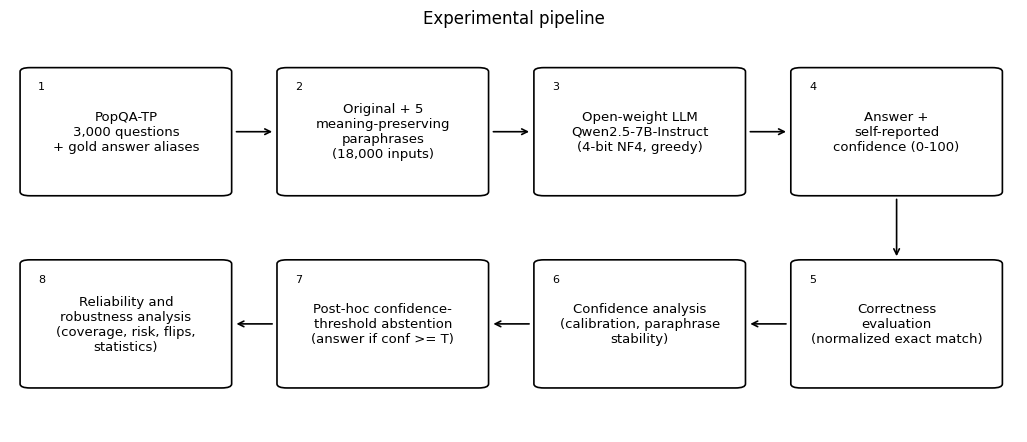

Saved: /content/drive/MyDrive/Research3/figures/phase8_fig2_confidence_distribution.png


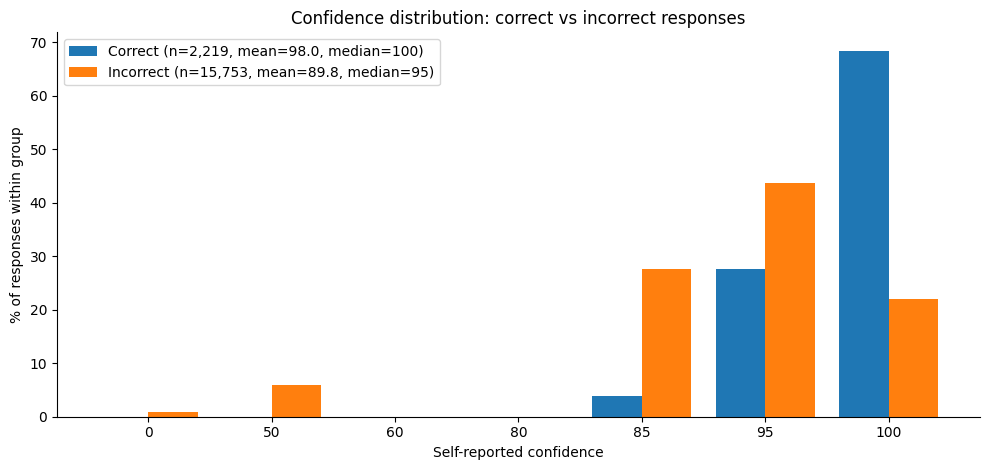

Saved: /content/drive/MyDrive/Research3/figures/phase8_fig3_calibration.png


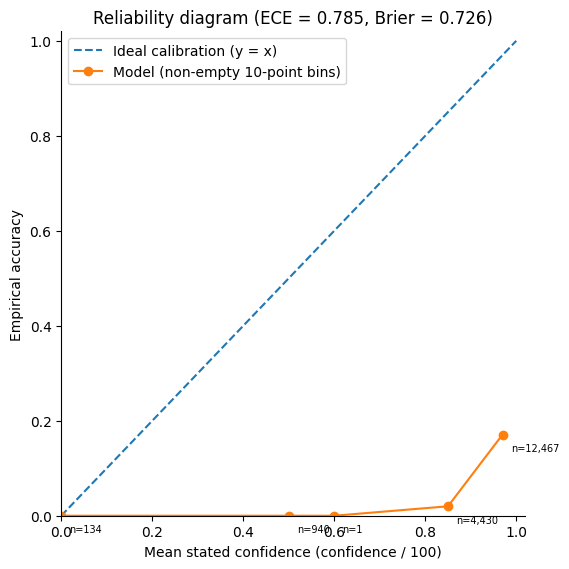

Saved: /content/drive/MyDrive/Research3/figures/phase8_fig4_paraphrase_confidence_shift.png


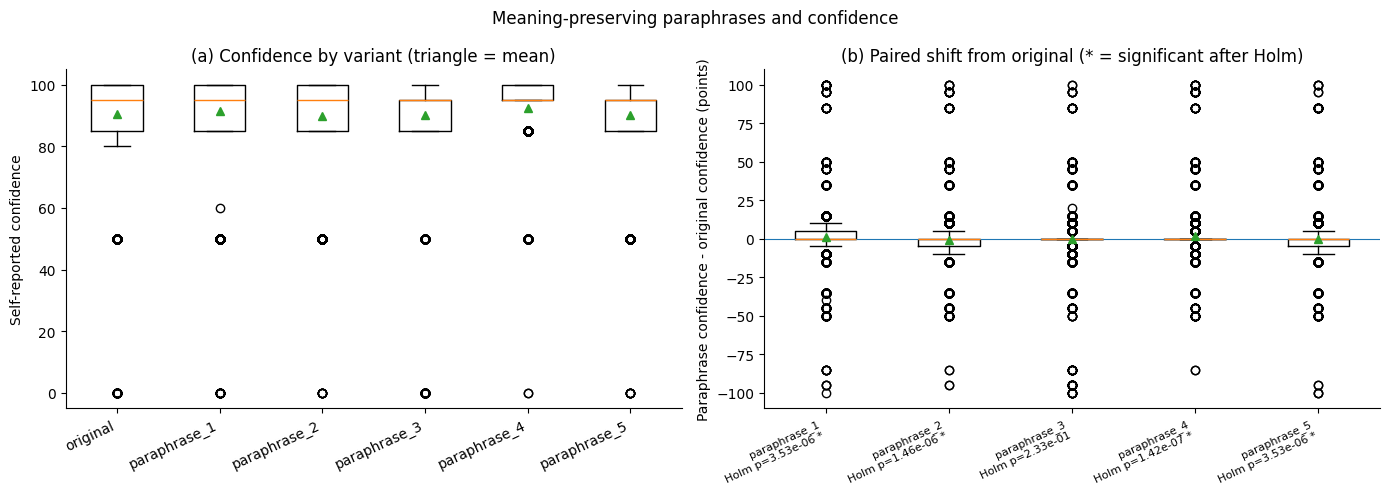

In [217]:
# ---------------- Figure 1: pipeline ----------------
steps = [
    f"PopQA-TP\n{N_Q:,} questions\n+ gold answer aliases",
    f"Original + 5\nmeaning-preserving\nparaphrases\n({N_TOTAL:,} inputs)",
    "Open-weight LLM\nQwen2.5-7B-Instruct\n(4-bit NF4, greedy)",
    "Answer +\nself-reported\nconfidence (0-100)",
    "Correctness\nevaluation\n(normalized exact match)",
    "Confidence analysis\n(calibration, paraphrase\nstability)",
    "Post-hoc confidence-\nthreshold abstention\n(answer if conf >= T)",
    "Reliability and\nrobustness analysis\n(coverage, risk, flips,\nstatistics)",
]
fig, ax = plt.subplots(figsize=(13, 5.2))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
bw, bh = 0.19, 0.30
xs = [0.02 + i * 0.255 for i in range(4)]
pos = [(xs[i], 0.60) for i in range(4)] + [(xs[3 - i], 0.12) for i in range(4)]
for k, ((x, y), txt) in enumerate(zip(pos, steps)):
    ax.add_patch(FancyBboxPatch((x, y), bw, bh, boxstyle="round,pad=0.01", fill=False, linewidth=1.2))
    ax.text(x + bw / 2, y + bh / 2, txt, ha="center", va="center", fontsize=9.5)
    ax.text(x + 0.008, y + bh - 0.025, str(k + 1), ha="left", va="top", fontsize=8)
for k in range(len(pos) - 1):
    (x1, y1), (x2, y2) = pos[k], pos[k + 1]
    if y1 == y2:
        if x2 > x1:
            a, b = (x1 + bw + 0.012, y1 + bh / 2), (x2 - 0.012, y2 + bh / 2)
        else:
            a, b = (x1 - 0.012, y1 + bh / 2), (x2 + bw + 0.012, y2 + bh / 2)
    else:
        a, b = (x1 + bw / 2, y1 - 0.012), (x2 + bw / 2, y2 + bh + 0.012)
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", linewidth=1.2))
ax.set_title("Experimental pipeline", fontsize=12)
p8_save_fig(fig, "phase8_fig1_pipeline.png")
plt.show()

# ---------------- Figure 2: confidence distribution (correct vs incorrect) ----------------
c_conf, i_conf = cdf.loc[cdf["correct"], "conf"], cdf.loc[~cdf["correct"], "conf"]
uniq = np.sort(cdf["conf"].unique())
if len(uniq) <= 30:
    keys = uniq.astype(float)
    to_key = lambda s: s.to_numpy(float)
    labels = [f"{k:g}" for k in keys]
else:
    keys = np.arange(0, 101, 5.0)
    to_key = lambda s: np.minimum(np.floor(s.to_numpy(float) / 5) * 5, 100)
    labels = [f"{int(k)}-{int(k) + 4}" if k < 100 else "100" for k in keys]


def pct_by_key(s):
    return pd.Series(to_key(s)).value_counts(normalize=True).reindex(keys, fill_value=0).to_numpy() * 100


x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(x - 0.2, pct_by_key(c_conf), width=0.4, label=f"Correct (n={len(c_conf):,}, mean={c_conf.mean():.1f}, median={c_conf.median():g})")
ax.bar(x + 0.2, pct_by_key(i_conf), width=0.4, label=f"Incorrect (n={len(i_conf):,}, mean={i_conf.mean():.1f}, median={i_conf.median():g})")
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=45 if len(keys) > 12 else 0)
ax.set_xlabel("Self-reported confidence"); ax.set_ylabel("% of responses within group")
ax.set_title("Confidence distribution: correct vs incorrect responses")
ax.legend()
fig.tight_layout()
p8_save_fig(fig, "phase8_fig2_confidence_distribution.png")
plt.show()

# ---------------- Figure 3: calibration (reliability diagram) ----------------
cb = p5_calib[p5_calib["count"] > 0]
fig, ax = plt.subplots(figsize=(5.8, 5.8))
ax.plot([0, 1], [0, 1], linestyle="--", label="Ideal calibration (y = x)")
ax.plot(cb["mean_confidence"], cb["empirical_accuracy"], marker="o", label="Model (non-empty 10-point bins)")
for _, r in cb.iterrows():
    ax.annotate(f"n={int(r['count']):,}", (r["mean_confidence"], r["empirical_accuracy"]), textcoords="offset points", xytext=(6, -12), fontsize=7)
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
ax.set_xlabel("Mean stated confidence (confidence / 100)"); ax.set_ylabel("Empirical accuracy")
ax.set_title(f"Reliability diagram (ECE = {ece10:.3f}, Brier = {brier:.3f})")
ax.legend(loc="upper left")
fig.tight_layout()
p8_save_fig(fig, "phase8_fig3_calibration.png")
plt.show()

# ---------------- Figure 4: paraphrase confidence shift ----------------
conf_cols = [f"conf_{v}" for v in VARIANTS]
shift_cols = [f"confidence_shift_{v}" for v in PARAPHRASES]
pt = p7_para.set_index("paraphrase")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.boxplot([p5_stab[c].dropna() for c in conf_cols], showmeans=True)
ax.set_xticks(range(1, len(VARIANTS) + 1)); ax.set_xticklabels(VARIANTS, rotation=25, ha="right")
ax.set_ylabel("Self-reported confidence"); ax.set_title("(a) Confidence by variant (triangle = mean)")
ax = axes[1]
ax.boxplot([p5_stab[c].dropna() for c in shift_cols], showmeans=True)
ax.axhline(0, linewidth=0.8)
tick = [f"{v}\nHolm p={fp(pt.loc[v, 'holm_adjusted_p_value'])}{' *' if bool(pt.loc[v, 'significant_holm_alpha_0.05']) else ''}" for v in PARAPHRASES]
ax.set_xticks(range(1, len(PARAPHRASES) + 1)); ax.set_xticklabels(tick, rotation=25, ha="right", fontsize=8)
ax.set_ylabel("Paraphrase confidence - original confidence (points)")
ax.set_title("(b) Paired shift from original (* = significant after Holm)")
fig.suptitle("Meaning-preserving paraphrases and confidence", fontsize=12)
fig.tight_layout()
p8_save_fig(fig, "phase8_fig4_paraphrase_confidence_shift.png")
plt.show()

Saved: /content/drive/MyDrive/Research3/figures/phase8_fig5_confidence_stability.png


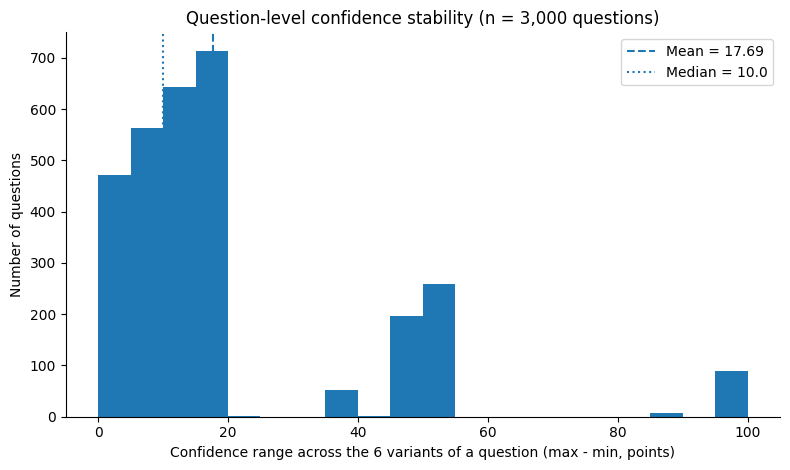

Saved: /content/drive/MyDrive/Research3/figures/phase8_fig6_risk_coverage.png


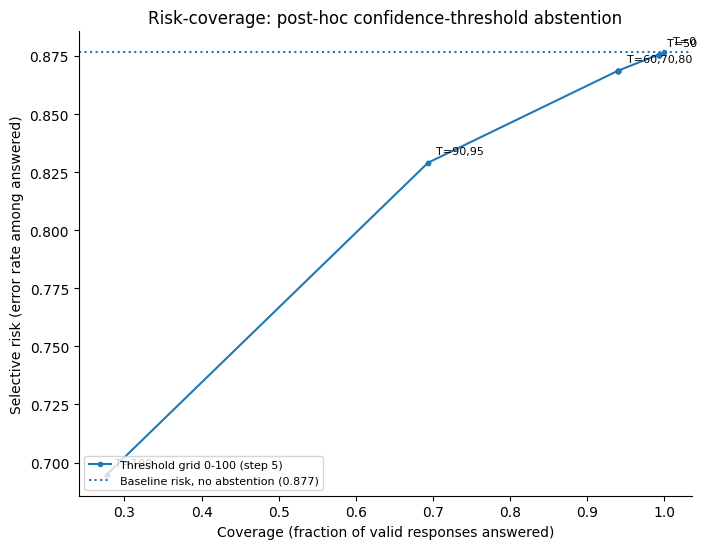

Saved: /content/drive/MyDrive/Research3/figures/phase8_fig7_abstention_stability.png


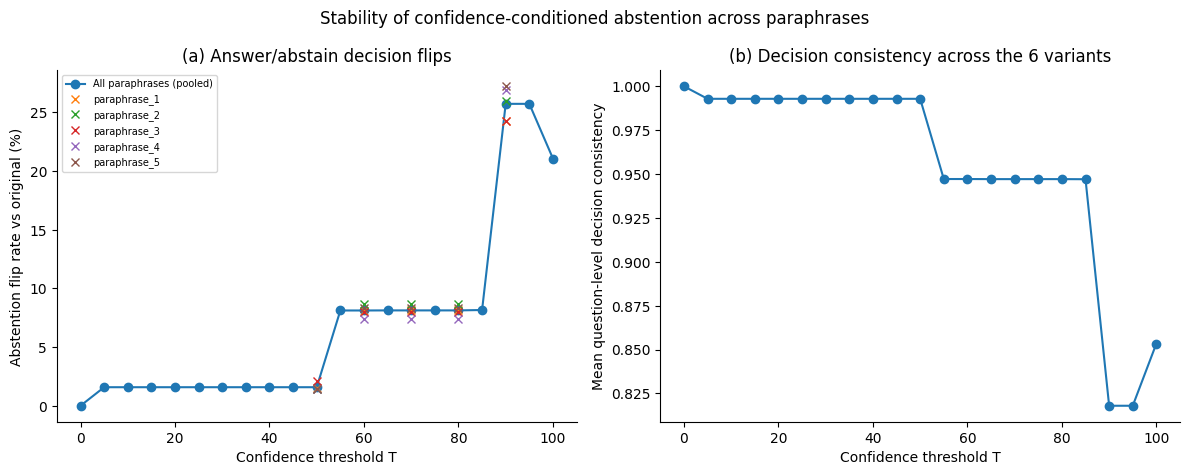

Saved: /content/drive/MyDrive/Research3/figures/phase8_fig8_accuracy_confidence.png


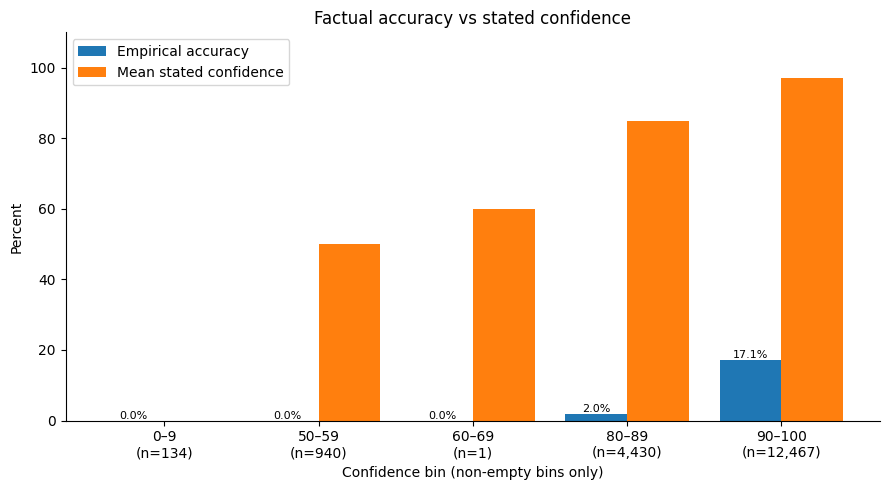

In [218]:
# ---------------- Figure 5: confidence stability (question-level range) ----------------
rng = p5_stab["confidence_range"].dropna()
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(rng, bins=np.arange(0, 105, 5))
ax.axvline(rng.mean(), linestyle="--", label=f"Mean = {rng.mean():.2f}")
ax.axvline(rng.median(), linestyle=":", label=f"Median = {rng.median():.1f}")
ax.set_xlabel("Confidence range across the 6 variants of a question (max - min, points)")
ax.set_ylabel("Number of questions")
ax.set_title(f"Question-level confidence stability (n = {len(rng):,} questions)")
ax.legend()
fig.tight_layout()
p8_save_fig(fig, "phase8_fig5_confidence_stability.png")
plt.show()

# ---------------- Figure 6: risk-coverage curve ----------------
s_ = p7_sens.sort_values("threshold").reset_index(drop=True)
base_risk = float(s_.loc[s_["threshold"] == 0, "selective_risk"].iloc[0])
fig, ax = plt.subplots(figsize=(7.2, 5.6))
ax.plot(s_["coverage"], s_["selective_risk"], marker=".", linestyle="-", label="Threshold grid 0-100 (step 5)")
ax.axhline(base_risk, linestyle=":", label=f"Baseline risk, no abstention ({base_risk:.3f})")
ann = s_[s_["threshold"].isin(TABLE_THRESHOLDS)].copy()
ann["key"] = ann["coverage"].round(3).astype(str) + "|" + ann["selective_risk"].round(3).astype(str)
for _, g in ann.groupby("key", sort=False):
    ax.annotate("T=" + ",".join(str(int(t)) for t in g["threshold"]), (g["coverage"].iloc[0], g["selective_risk"].iloc[0]),
                textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("Coverage (fraction of valid responses answered)")
ax.set_ylabel("Selective risk (error rate among answered)")
ax.set_title("Risk-coverage: post-hoc confidence-threshold abstention")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
p8_save_fig(fig, "phase8_fig6_risk_coverage.png")
plt.show()

# ---------------- Figure 7: abstention stability ----------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
ax = axes[0]
ax.plot(s_["threshold"], 100 * s_["abstention_flip_rate"], marker="o", label="All paraphrases (pooled)")
for v in PARAPHRASES:
    d = p6_flip[p6_flip["variant"] == v]
    ax.plot(d["threshold"], 100 * d["abstention_flip_rate"], marker="x", linestyle="none", label=v)
ax.set_xlabel("Confidence threshold T"); ax.set_ylabel("Abstention flip rate vs original (%)")
ax.set_title("(a) Answer/abstain decision flips"); ax.legend(fontsize=7)
ax = axes[1]
ax.plot(s_["threshold"], s_["mean_decision_consistency"], marker="o")
ax.set_xlabel("Confidence threshold T"); ax.set_ylabel("Mean question-level decision consistency")
ax.set_title("(b) Decision consistency across the 6 variants")
fig.suptitle("Stability of confidence-conditioned abstention across paraphrases", fontsize=12)
fig.tight_layout()
p8_save_fig(fig, "phase8_fig7_abstention_stability.png")
plt.show()

# ---------------- Figure 8: accuracy vs confidence ----------------
b = p5_bins[p5_bins["responses"] > 0].reset_index(drop=True)
x = np.arange(len(b))
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - 0.2, 100 * b["accuracy"], width=0.4, label="Empirical accuracy")
ax.bar(x + 0.2, b["mean_confidence"], width=0.4, label="Mean stated confidence")
for i, r in b.iterrows():
    ax.annotate(f"{100 * r['accuracy']:.1f}%", (i - 0.2, 100 * r["accuracy"]), ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f"{r['bin']}\n(n={int(r['responses']):,})" for _, r in b.iterrows()])
ax.set_xlabel("Confidence bin (non-empty bins only)"); ax.set_ylabel("Percent")
ax.set_ylim(0, 110)
ax.set_title("Factual accuracy vs stated confidence")
ax.legend()
fig.tight_layout()
p8_save_fig(fig, "phase8_fig8_accuracy_confidence.png")
plt.show()

## 8.4 Facts dictionary (every number used in the reports)

All numbers used in the findings, report, interpretation and paper-numbers JSON are collected here **once**, from the saved result files. The text cells below only insert these values.

In [219]:
F = {}
vv = p4_var.set_index("variant")
F["acc"], F["acc_orig"] = float(vv.loc["overall", "accuracy"]), float(vv.loc["original", "accuracy"])
F["acc_lo"], F["acc_hi"] = float(ci.loc["overall_accuracy", "ci_lower_2.5"]), float(ci.loc["overall_accuracy", "ci_upper_97.5"])
F["n_correct"], F["n_valid"], F["n_incorrect"] = int(vv.loc["overall", "correct"]), int(vv.loc["overall", "valid"]), int(vv.loc["overall", "incorrect"])
pa = vv.loc[PARAPHRASES, "accuracy"]
F["acc_para_min"], F["acc_para_max"] = float(pa.min()), float(pa.max())
F["acc_para_min_v"], F["acc_para_max_v"] = pa.idxmin(), pa.idxmax()
fl4 = p4_flip.set_index("variant")
F["flip_rate"], F["flip_n"] = float(fl4.loc["all_paraphrases", "answer_flip_rate"]), int(fl4.loc["all_paraphrases", "valid_comparisons"])
F["cons_n"], F["cons_total"], F["cons_rate"] = int(j4["consistency"]["fully_consistent"]), int(j4["consistency"]["questions_counted"]), float(j4["consistency"]["rate"])
trp = p4_trans[p4_trans["scope"] == "all_paraphrases"].set_index("transition")
F["c2i_pct"], F["i2c_pct"] = float(trp.loc[TRANSITIONS[1], "percentage"]) / 100, float(trp.loc[TRANSITIONS[2], "percentage"]) / 100
F["c2i_n"], F["i2c_n"] = int(trp.loc[TRANSITIONS[1], "count"]), int(trp.loc[TRANSITIONS[2], "count"])
pat = p4_cons["correctness_pattern"].value_counts()
F["pat_ac"], F["pat_ai"], F["pat_mx"] = int(pat.get("all_correct", 0)), int(pat.get("all_incorrect", 0)), int(pat.get("mixed", 0))
F["pat_total"] = F["pat_ac"] + F["pat_ai"] + F["pat_mx"]
F["contains_n"], F["contains_of"] = int(j7["sanity_check"]["incorrect_with_gold_alias_phrase_all"]), int(j7["sanity_check"]["incorrect_valid_all"])
F["san_n"] = len(p7_sanity)
F["san_correct"] = int((p7_sanity["phase4_label"] == "correct").sum())
F["san_contains"] = int(((p7_sanity["phase4_label"] == "incorrect") & (p7_sanity["answer_contains_gold_alias_phrase"].astype(str) == "True")).sum())

F["mean_conf"] = float(jg(j5, "mean_confidence"))
F["mean_conf_lo"], F["mean_conf_hi"] = float(ci.loc["mean_confidence", "ci_lower_2.5"]), float(ci.loc["mean_confidence", "ci_upper_97.5"])
F["mean_c"], F["mean_i"] = float(cvi.loc["correct", "mean"]), float(cvi.loc["incorrect", "mean"])
F["med_c"], F["med_i"] = float(cvi.loc["correct", "median"]), float(cvi.loc["incorrect", "median"])
F["min_c"], F["min_i"] = float(cvi.loc["correct", "min"]), float(cvi.loc["incorrect", "min"])
mwr, wqr = p7_cc.iloc[0], p7_cc.iloc[1]
F["mw_r"], F["mw_cles"], F["mw_p"] = float(mwr["effect_size"]), float(mwr["common_language_effect_size"]), float(mwr["p_value"])
F["wq_r"], F["wq_n"], F["wq_p"] = float(wqr["effect_size"]), int(wqr["n_correct"]), float(wqr["p_value"])

F["ece"], F["brier"] = ece10, brier
F["ece5"], F["ece20"] = float(cal.loc[5, "ece"]), float(cal.loc[20, "ece"])
bn = p5_bins[p5_bins["responses"] > 0]
F["bins_txt"] = "; ".join(f"{r['bin']}: {P(r['accuracy'])} (n={int(r['responses']):,})" for _, r in bn.iterrows())

P7 = p7_para.set_index("paraphrase")
F["n_sig_holm"] = int(P7["significant_holm_alpha_0.05"].sum())
F["up"] = [v for v in PARAPHRASES if bool(P7.loc[v, "significant_holm_alpha_0.05"]) and P7.loc[v, "effect_size"] > 0]
F["down"] = [v for v in PARAPHRASES if bool(P7.loc[v, "significant_holm_alpha_0.05"]) and P7.loc[v, "effect_size"] < 0]
F["nonsig"] = [v for v in PARAPHRASES if not bool(P7.loc[v, "significant_holm_alpha_0.05"])]
sig_abs = P7.loc[F["up"] + F["down"], "effect_size"].abs()
F["es_min"], F["es_max"] = float(sig_abs.min()), float(sig_abs.max())
F["shift_min"], F["shift_max"] = float(sh5.loc[PARAPHRASES, "mean_shift"].min()), float(sh5.loc[PARAPHRASES, "mean_shift"].max())
F["pct_unchanged"], F["mean_abs_shift"] = float(sh5.loc["all_paraphrases", "pct_unchanged"]) / 100, float(sh5.loc["all_paraphrases", "mean_abs_shift"])
F["std_shift"] = float(sh5.loc["all_paraphrases", "std_shift"])
F["range_mean"], F["range_median"] = float(rng.mean()), float(rng.median())
F["range_lo"], F["range_hi"] = float(ci.loc["mean_confidence_range", "ci_lower_2.5"]), float(ci.loc["mean_confidence_range", "ci_upper_97.5"])
F["pct10"], F["pct20"], F["pct30"] = (float((rng >= t).mean()) for t in (10, 20, 30))
G = p7_grp.set_index("correctness_group")
for g, k in [("all_correct", "A"), ("all_incorrect", "B"), ("mixed", "C")]:
    F[f"g{k}_n"], F[f"g{k}_mean"], F[f"g{k}_med"] = int(G.loc[g, "n_questions"]), float(G.loc[g, "mean_confidence_range"]), float(G.loc[g, "median_confidence_range"])
kw = p7_gtest[p7_gtest["test"] == "kruskal_wallis"].iloc[0]
F["kw_H"], F["kw_p"], F["kw_eps"] = float(kw["statistic"]), float(kw["raw_p_value"]), float(kw["effect_size"])
SP = p7_corr.set_index("measure")
F["sp1_rho"], F["sp1_p"] = float(SP.loc["correctness_instability", "spearman_rho"]), float(SP.loc["correctness_instability", "p_value"])
F["sp2_rho"], F["sp2_p"] = float(SP.loc["correctness_disagreement", "spearman_rho"]), float(SP.loc["correctness_disagreement", "p_value"])

F["T"] = {int(T): {k: float(sens.loc[T, k]) for k in ["coverage", "abstention_rate", "selective_accuracy", "selective_risk",
                                                       "abstention_flip_rate", "mean_decision_consistency", "answered", "correct_answered", "incorrect_answered"]}
          for T in sens.index}
F["base_risk"] = F["T"][0]["selective_risk"]
F["base_risk_lo"], F["base_risk_hi"] = 1 - F["acc_hi"], 1 - F["acc_lo"]      # derived from the accuracy bootstrap interval
for m, key in [("t90_coverage", "t90_cov"), ("t90_selective_accuracy", "t90_acc"), ("t90_selective_risk", "t90_risk"),
               ("t90_abstention_flip_rate", "t90_flip"), ("t90_mean_decision_consistency", "t90_cons")]:
    F[key], F[key + "_lo"], F[key + "_hi"] = float(ci.loc[m, "point_estimate"]), float(ci.loc[m, "ci_lower_2.5"]), float(ci.loc[m, "ci_upper_97.5"])
q90s = p6_qdec[(p6_qdec["threshold"] == 90) & (p6_qdec["num_valid_variants"] >= 2)]
F["t90_mixed"], F["t90_allans"], F["t90_allabs"] = (float((q90s["decision_group"] == g).mean()) for g in ("mixed", "all_answer", "all_abstain"))
F["t90_cons_median"] = float(q90s["decision_consistency"].median())
d90 = p6_dc.set_index("threshold").loc[90]
F["dc_ca"], F["dc_cb"], F["dc_ia"], F["dc_ib"] = int(d90["correct_answer"]), int(d90["correct_abstain"]), int(d90["incorrect_answer"]), int(d90["incorrect_abstain"])
F["hcw90_pct"], F["lcc90_pct"] = F["dc_ia"] / F["n_incorrect"], F["dc_cb"] / F["n_correct"]
F["abs_inc_pct"] = F["dc_ib"] / F["n_incorrect"]

vt = p6_var.set_index(["variant", "threshold"])
F["var_risk0"] = {v: float(vt.loc[(v, 0), "selective_risk"]) for v in VARIANTS}
F["var_risk90"] = {v: float(vt.loc[(v, 90), "selective_risk"]) for v in VARIANTS}
F["var_cov90"] = {v: float(vt.loc[(v, 90), "coverage"]) for v in VARIANTS}
F["var_flip90"] = {v: float(fl_) for v, fl_ in p6_flip[p6_flip["threshold"] == 90].set_index("variant")["abstention_flip_rate"].items() if v in PARAPHRASES}
dr = {v: F["var_risk0"][v] - F["var_risk90"][v] for v in VARIANTS}
F["n_var_risk_down"], F["risk_red_min"], F["risk_red_max"] = sum(d > 0 for d in dr.values()), min(dr.values()), max(dr.values())
F["risk90_min_v"], F["risk90_max_v"] = min(F["var_risk90"], key=F["var_risk90"].get), max(F["var_risk90"], key=F["var_risk90"].get)
F["cov90_min_v"], F["cov90_max_v"] = min(F["var_cov90"], key=F["var_cov90"].get), max(F["var_cov90"], key=F["var_cov90"].get)

F["n_tests"], F["n_sig"] = len(p7_tests), int(p7_tests["significant"].sum())
F["nonsig_tests"] = p7_tests.loc[~p7_tests["significant"], "comparison"].tolist()
F["part5"] = j7["threshold_comparison_descriptive"]

print("Facts collected. Key values:")
for k in ["acc", "acc_orig", "mean_conf", "mean_c", "mean_i", "ece", "brier", "range_mean", "t90_cov", "t90_acc", "t90_risk", "t90_flip", "t90_cons", "n_tests", "n_sig"]:
    print(f"  {k:12s} {F[k]:.4f}" if isinstance(F[k], float) else f"  {k:12s} {F[k]}")

Facts collected. Key values:
  acc          0.1235
  acc_orig     0.1386
  mean_conf    90.8555
  mean_c       98.0261
  mean_i       89.8454
  ece          0.7851
  brier        0.7256
  range_mean   17.6883
  t90_cov      0.6937
  t90_acc      0.1709
  t90_risk     0.8291
  t90_flip     0.2571
  t90_cons     0.8180
  n_tests      13
  n_sig        12


## 8.5 Error analysis, high-confidence wrong and low-confidence correct cases (Steps 6-8)

All categories come from **deterministic string rules** (no LLM judge, no embeddings, no semantic similarity), applied to the existing Phase 4 labels. Rules for incorrect responses, applied in this order (first match wins):

1. `possible_label_issue_gold_alias_inside_answer`: a gold alias appears as a whole phrase inside the answer (Phase 4 diagnostic). `label_review_needed = yes`.
2. `possible_incomplete_answer_part_of_gold_alias`: the whole answer is a phrase inside a gold alias. `label_review_needed = yes`.
3. `non_answer_or_premise_rejection`: regex for "unknown / no known / not known / there is no / cannot ...". `label_review_needed = no`.
4. `possible_entity_confusion_or_partial_overlap`: shares a content word (3+ letters, small stop-word list) with a gold alias. `label_review_needed = yes` (conservative).
5. `verbose_sentence_answer_no_gold_match`: 6+ words, no gold match. `no`.
6. `wrong_factual_answer`: short answer with no gold match. `no`.

Categories that **cannot** be assigned reliably by rule (`ambiguous_question`, `unsupported_answer`, true entity confusion) are not assigned; the flags above only mark candidates for manual reading. No label is changed.

In [220]:
STOP = {"the", "and", "for", "with", "from", "that", "this", "was", "were", "are", "not", "has", "have", "his", "her", "its", "who", "what"}
NONANSWER_RE = re.compile(r"\b(unknown|no known|not (?:widely |well )?known|not documented|no information|there is no|no (?:director|author|producer|screenwriter|composer|credited)|cannot|can't|unable to|does not|doesn't|is not|isn't|not enough)\b")


def tok(s):
    return {t for t in re.findall(r"[a-z0-9]+", s) if len(t) >= 3 and t not in STOP}


def diagnose(answer, gold_list):
    """Deterministic string rules. Returns (category, label_review_needed, note). Labels are never changed."""
    a = normalize_answer(answer)
    golds = {g for g in (normalize_answer(x) for x in gold_list) if g}
    padded = f" {a} "
    if any(f" {g} " in padded for g in golds):
        return ("possible_label_issue_gold_alias_inside_answer", "yes",
                "Answer contains a gold alias as a whole phrase; strict exact match marked it incorrect (Phase 4 diagnostic).")
    if len(a) >= 3 and any(padded in f" {g} " for g in golds):
        return ("possible_incomplete_answer_part_of_gold_alias", "yes", "Answer is only part of a gold alias.")
    if NONANSWER_RE.search(a):
        return ("non_answer_or_premise_rejection", "no", "Answer states that the information is unknown/absent or rejects the question.")
    at = tok(a)
    if at and any(at & tok(g) for g in golds):
        return ("possible_entity_confusion_or_partial_overlap", "yes", "Answer shares a content word with a gold alias; needs manual reading.")
    if len(a.split()) >= 6:
        return ("verbose_sentence_answer_no_gold_match", "no", "Sentence-style answer with no gold alias in it.")
    return ("wrong_factual_answer", "no", "Short answer with no gold-alias match.")


W = cdf[["question_id", "variant", "question", "answer", "gold_answer", "gold_list", "conf", "correct", "canonical_answer"]].copy()
W["_q"], W["_v"] = W["question_id"].map(q_pos), W["variant"].map(v_pos)
W = W.sort_values(["_q", "_v"]).reset_index(drop=True)
qcv = W.groupby("question_id")["correct"].sum().astype(int)

inc = W[~W["correct"]].copy()
dg = [diagnose(a, g) for a, g in zip(inc["answer"], inc["gold_list"])]
inc["diag_category"], inc["label_review_needed"], inc["diag_note"] = zip(*dg)
diag_lookup = inc.set_index(["question_id", "variant"])[["diag_category", "label_review_needed", "diag_note"]]

# population-level distribution of the rule-based categories (all incorrect responses)
diag_counts = inc["diag_category"].value_counts()
p8_header("RULE-BASED CATEGORIES OVER ALL INCORRECT RESPONSES")
print(pd.DataFrame({"count": diag_counts, "pct_of_incorrect": (100 * diag_counts / len(inc)).round(2)}).to_string())
F["diag_counts"] = {k: int(v) for k, v in diag_counts.items()}
F["label_review_yes"] = int((inc["label_review_needed"] == "yes").sum())

# paired original-vs-paraphrase frame
O = W[W["variant"] == "original"].set_index("question_id")[["answer", "conf", "correct", "canonical_answer"]].add_prefix("o_")
pairs = W[W["variant"] != "original"].join(O, on="question_id", how="inner")
pairs["shift"] = pairs["conf"] - pairs["o_conf"]
pairs["abs_shift"] = pairs["shift"].abs()
pairs["same_answer"] = pairs["canonical_answer"] == pairs["o_canonical_answer"]


def take(df, cols, asc):
    return df.sort_values(cols, ascending=asc, kind="stable").head(N_PER_CATEGORY)


def dsel(cat):
    return inc[inc["diag_category"] == cat]


plan = [
    ("wrong_factual_answer", "first rows in dataset order among incorrect rows with no gold match (short answers)", take(dsel("wrong_factual_answer"), ["_q", "_v"], [True, True])),
    ("high_confidence_wrong", "incorrect rows with confidence >= 90, highest confidence first, then dataset order", take(inc[inc["conf"] >= 90], ["conf", "_q", "_v"], [False, True, True])),
    ("low_confidence_correct", "correct rows with confidence < 90, lowest confidence first, then dataset order", take(W[W["correct"] & (W["conf"] < 90)], ["conf", "_q", "_v"], [True, True, True])),
    ("paraphrase_induced_answer_change", "original correct -> paraphrase incorrect, dataset order", take(pairs[pairs["o_correct"] & ~pairs["correct"]], ["_q", "_v"], [True, True])),
    ("paraphrase_induced_confidence_change", "same canonical answer as original, largest absolute confidence shift first", take(pairs[pairs["same_answer"] & (pairs["shift"] != 0)], ["abs_shift", "_q", "_v"], [False, True, True])),
    ("abstention_decision_flip_T90", "same canonical answer as original but answer/abstain decision at T=90 differs, largest shift first", take(pairs[pairs["same_answer"] & ((pairs["o_conf"] >= 90) != (pairs["conf"] >= 90))], ["abs_shift", "_q", "_v"], [False, True, True])),
    ("possible_entity_confusion_or_partial_overlap", "rule 4, highest confidence first", take(dsel("possible_entity_confusion_or_partial_overlap"), ["conf", "_q", "_v"], [False, True, True])),
    ("incomplete_answer_candidate", "rule 2, highest confidence first", take(dsel("possible_incomplete_answer_part_of_gold_alias"), ["conf", "_q", "_v"], [False, True, True])),
    ("possible_correctness_label_matching_issue", "rule 1, highest confidence first", take(dsel("possible_label_issue_gold_alias_inside_answer"), ["conf", "_q", "_v"], [False, True, True])),
    ("non_answer_or_premise_rejection", "rule 3, highest confidence first", take(dsel("non_answer_or_premise_rejection"), ["conf", "_q", "_v"], [False, True, True])),
    ("verbose_sentence_answer", "rule 5, dataset order", take(dsel("verbose_sentence_answer_no_gold_match"), ["_q", "_v"], [True, True])),
]

rows = []
for cat, rule, d in plan:
    for _, r in d.iterrows():
        key = (r["question_id"], r["variant"])
        if (not r["correct"]) and key in diag_lookup.index:
            dd = diag_lookup.loc[key]
            dcat, rev, note = dd["diag_category"], dd["label_review_needed"], dd["diag_note"]
        else:
            dcat, rev, note = "", "no", ""
        ref = "o_answer" in r.index
        rows.append({
            "category": cat, "selection_rule": rule, "question_id": r["question_id"], "variant": r["variant"],
            "question": r["question"], "answer": r["answer"], "gold_answers": json.dumps(r["gold_list"], ensure_ascii=False),
            "confidence": r["conf"], "correctness": "correct" if r["correct"] else "incorrect",
            "diagnostic_category": dcat, "label_review_needed": rev,
            "reference_variant": "original" if ref else "", "reference_answer": r["o_answer"] if ref else "",
            "reference_confidence": r["o_conf"] if ref else np.nan,
            "reference_correctness": ("correct" if r["o_correct"] else "incorrect") if ref else "",
            "confidence_shift_from_original": r["shift"] if ref else np.nan,
            "num_correct_variants_in_question": int(qcv[r["question_id"]]), "note": note,
        })
err = pd.DataFrame(rows)
p8_save_table(err, "phase8_error_analysis.csv")
print(err.groupby("category").agg(rows=("category", "size"), label_review_yes=("label_review_needed", lambda s: int((s == "yes").sum()))).to_string())
print("\nNot assigned automatically (need manual reading): ambiguous_question, unsupported_answer, true entity confusion.")


RULE-BASED CATEGORIES OVER ALL INCORRECT RESPONSES
                                               count  pct_of_incorrect
diag_category                                                         
wrong_factual_answer                           11134             70.68
verbose_sentence_answer_no_gold_match           1675             10.63
non_answer_or_premise_rejection                 1578             10.02
possible_entity_confusion_or_partial_overlap     560              3.55
possible_label_issue_gold_alias_inside_answer    488              3.10
possible_incomplete_answer_part_of_gold_alias    318              2.02
Saved: /content/drive/MyDrive/Research3/results/phase8_error_analysis.csv  (110 rows)
                                              rows  label_review_yes
category                                                            
abstention_decision_flip_T90                    10                 0
high_confidence_wrong                           10                 2
incomplete_answer_

In [221]:
# ---------------- Step 7: high-confidence wrong analysis (confidence >= 90) ----------------
hcw = p6_hcw[p6_hcw["confidence"] >= 90].copy()
assert len(hcw) == F["dc_ia"], f"High-confidence wrong count {len(hcw)} != Phase 6 incorrect+answer at T90 {F['dc_ia']}"
assert (hcw["correctness"] == "incorrect").all()
qcv_disk = p4_cons.set_index("question_id")["num_correct_variants"]
assert (qcv_disk.reindex(qcv.index).to_numpy() == qcv.to_numpy()).all(), "Phase 4 CSV and in-memory correct counts differ"

hcw["_q"], hcw["_v"] = hcw["question_id"].map(q_pos), hcw["variant"].map(v_pos)
hcw = hcw.sort_values(["confidence", "_q", "_v"], ascending=[False, True, True]).reset_index(drop=True)
dg = [diagnose(a, json.loads(g)) for a, g in zip(hcw["answer"], hcw["gold_answer"])]
hcw["error_category"], hcw["label_review_needed"], hcw["diagnostic_note"] = zip(*dg)
hcw["num_correct_variants_in_question"] = hcw["question_id"].map(qcv_disk).astype(int)
hcw["any_other_variant_correct"] = hcw["num_correct_variants_in_question"] > 0   # this row is incorrect, so any correct variant is another one
hcw["would_answer_at_T90"] = hcw["confidence"] >= 90
hcw_out = hcw[["question_id", "variant", "question", "answer", "gold_answer", "confidence", "error_category", "any_other_variant_correct",
               "num_correct_variants_in_question", "would_answer_at_T90", "label_review_needed", "diagnostic_note"]]
p8_save_table(hcw_out, "phase8_high_confidence_wrong_analysis.csv")

F["hcw_n"] = len(hcw_out)
F["hcw_cat"] = {k: int(v) for k, v in hcw_out["error_category"].value_counts().items()}
F["hcw_other_correct"] = int(hcw_out["any_other_variant_correct"].sum())
F["hcw_conf100"] = int((hcw_out["confidence"] == 100).sum())
F["hcw_review"] = int((hcw_out["label_review_needed"] == "yes").sum())
p8_header("HIGH-CONFIDENCE WRONG ANALYSIS (confidence >= 90)")
print(f"Rows: {F['hcw_n']:,} (= {P(F['hcw90_pct'])} of all incorrect valid responses)")
print(f"With confidence exactly 100: {F['hcw_conf100']:,}")
print(f"Another variant of the same question was correct: {F['hcw_other_correct']:,} ({P(F['hcw_other_correct'] / F['hcw_n'])})")
print(f"Flagged label_review_needed = yes: {F['hcw_review']:,} ({P(F['hcw_review'] / F['hcw_n'])})")
print(pd.DataFrame({"count": pd.Series(F["hcw_cat"]), "pct": (100 * pd.Series(F["hcw_cat"]) / F["hcw_n"]).round(2)}).to_string())

# ---------------- Step 8: low-confidence correct analysis (confidence < 90) ----------------
lcc = p6_lcc[p6_lcc["confidence"] < 90].copy()
assert len(lcc) == F["dc_cb"], f"Low-confidence correct count {len(lcc)} != Phase 6 correct+abstain at T90 {F['dc_cb']}"
assert (lcc["correctness"] == "correct").all()
byq = {qid: g for qid, g in W[W["question_id"].isin(lcc["question_id"])].groupby("question_id")}
recs = []
for _, r in lcc.iterrows():
    g = byq[r["question_id"]]
    other = g[g["variant"] != r["variant"]]
    ok_hi = bool((other["correct"] & (other["conf"] >= 90)).any())
    any_hi = bool((other["conf"] >= 90).any())
    if ok_hi:
        cat = "paraphrase_dependent_confidence (another variant of this question is correct with confidence >= 90)"
    elif any_hi:
        cat = "other_variant_high_confidence_but_incorrect"
    else:
        cat = "consistently_lower_confidence (no other variant has confidence >= 90)"
    recs.append({"question_id": r["question_id"], "variant": r["variant"], "question": r["question"], "answer": r["answer"],
                 "gold_answer": r["gold_answer"], "confidence": r["confidence"], "diagnostic_category": cat,
                 "num_correct_variants_in_question": int(g["correct"].sum()),
                 "max_confidence_other_variants": float(other["conf"].max()) if len(other) else np.nan,
                 "any_other_variant_correct_with_conf_ge_90": ok_hi,
                 "note": "Correct answer with confidence < 90. This does not show that the model 'knows' the answer (it may be a guess); it only marks correct answers that T=90 abstention would remove."})
lcc_out = pd.DataFrame(recs)
p8_save_table(lcc_out, "phase8_low_confidence_correct_analysis.csv")
F["lcc_n"] = len(lcc_out)
F["lcc_cat"] = {k.split(" (")[0]: int(v) for k, v in lcc_out["diagnostic_category"].value_counts().items()}
F["lcc_conf_values"] = sorted(lcc_out["confidence"].unique().tolist())
p8_header("LOW-CONFIDENCE CORRECT ANALYSIS (confidence < 90)")
print(f"Rows: {F['lcc_n']} (= {P(F['lcc90_pct'])} of all correct valid responses) | confidence values present: {F['lcc_conf_values']}")
print(pd.Series(F["lcc_cat"]).to_string())

Saved: /content/drive/MyDrive/Research3/results/phase8_high_confidence_wrong_analysis.csv  (10336 rows)

HIGH-CONFIDENCE WRONG ANALYSIS (confidence >= 90)
Rows: 10,336 (= 65.61% of all incorrect valid responses)
With confidence exactly 100: 3,458
Another variant of the same question was correct: 878 (8.49%)
Flagged label_review_needed = yes: 1,077 (10.42%)
                                               count    pct
wrong_factual_answer                            8373  81.01
verbose_sentence_answer_no_gold_match            642   6.21
possible_entity_confusion_or_partial_overlap     439   4.25
possible_label_issue_gold_alias_inside_answer    381   3.69
possible_incomplete_answer_part_of_gold_alias    257   2.49
non_answer_or_premise_rejection                  244   2.36
Saved: /content/drive/MyDrive/Research3/results/phase8_low_confidence_correct_analysis.csv  (88 rows)

LOW-CONFIDENCE CORRECT ANALYSIS (confidence < 90)
Rows: 88 (= 3.97% of all correct valid responses) | confidence value

## 8.6 Key findings, results report and final interpretation (Steps 5, 9, 11)

The three Markdown files are written from the facts dictionary only. Wording is conservative: observations are separated from interpretations, and no causal language is used.

In [222]:
T = F["T"]
upl = ", ".join(F["up"]) or "none"
dnl = ", ".join(F["down"]) or "none"
nsl = ", ".join(F["nonsig"]) or "none"
risk_drop = F["base_risk"] - T[90]["selective_risk"]

key_findings = f"""# Key Findings — Qwen2.5-7B-Instruct on PopQA-TP

All numbers come from the saved Phase 3-7 outputs. Correctness is the Phase 4 normalized exact-match label (unchanged). Confidence is a self-reported number from 0 to 100; it is **not** treated as a true probability. Abstention is **post-hoc, confidence-conditioned**: the model was never asked to abstain. These are results for one model on one dataset; no causal claims are made.

## Finding 1 — Factual Performance
- **Result:** overall accuracy is {P(F['acc'])} ({F['n_correct']:,} of {F['n_valid']:,} valid responses; bootstrap 95% CI {P(F['acc_lo'])} to {P(F['acc_hi'])}). Original questions: {P(F['acc_orig'])}; paraphrases range from {P(F['acc_para_min'])} ({F['acc_para_min_v']}) to {P(F['acc_para_max'])} ({F['acc_para_max_v']}).
- **Answer stability:** the answer string changes (after normalization) in {P(F['flip_rate'])} of {F['flip_n']:,} original-vs-paraphrase comparisons; only {F['cons_n']} of {F['cons_total']:,} questions ({P(F['cons_rate'])}) give the same answer in all valid variants. Correctness changed correct→incorrect in {P(F['c2i_pct'])} and incorrect→correct in {P(F['i2c_pct'])} of comparisons.
- **Meaning:** accuracy under this rule is low, and answers are very sensitive to wording; most of that answer variation does not change correctness because most responses are incorrect in every variant ({F['pat_ai']:,} of {F['pat_total']:,} questions with all six variants valid).
- **Caveat on the label rule:** {F['contains_n']} of {F['contains_of']:,} incorrect responses ({P(F['contains_n'] / F['contains_of'])}) contain a gold alias as a whole phrase and are still counted incorrect by strict matching. In the 100-response sanity sample ({F['san_correct']} correct), {F['san_contains']} incorrect responses had this property. This suggests strict matching explains only a minority of incorrect labels, but it does not rule out other matching issues.

## Finding 2 — Confidence–Correctness Relationship
- **Result:** mean confidence is {N(F['mean_c'], 2)} on correct vs {N(F['mean_i'], 2)} on incorrect responses (medians {F['med_c']:g} vs {F['med_i']:g}). Mann–Whitney p {fp(F['mw_p'])} (exact 0 = floating-point underflow); rank-biserial r = {N(F['mw_r'])}; probability that a random correct response has higher confidence than a random incorrect one (ties counted half) = {N(F['mw_cles'])}.
- **Within-question check:** among the {F['wq_n']} questions with both correct and incorrect variants, correct variants have higher mean confidence (paired rank-biserial r = {N(F['wq_r'])}, p = {fp(F['wq_p'])}).
- **Limit:** the lowest confidence of any correct response is {F['min_c']:g}, but {F['dc_ia']:,} incorrect responses ({P(F['hcw90_pct'])} of all incorrect) also have confidence >= 90.
- **Meaning:** confidence carries a ranking signal about correctness, but it does not separate correct from incorrect answers cleanly.

## Finding 3 — Calibration
- **Result:** ECE = {N(F['ece'])} and Brier score = {N(F['brier'])}. ECE is the same with 5, 10 and 20 equal-width bins ({N(F['ece5'])}, {N(F['ece'])}, {N(F['ece20'])}). Accuracy per non-empty 10-point bin: {F['bins_txt']}.
- **Meaning:** stated confidence is far above observed accuracy in every non-empty bin (strong over-confidence). Because all non-empty bins lie on the same side of the diagonal, merging bins does not change ECE here, so the conclusion does not depend on the binning scheme. Accuracy does increase with the bin, so the number is informative about ranking but is not calibrated as a probability.

## Finding 4 — Paraphrase Sensitivity
- **Result:** confidence is unchanged in {P(F['pct_unchanged'])} of original-vs-paraphrase pairs and the median shift is 0, but the mean absolute shift is {N(F['mean_abs_shift'], 2)} points (SD of shift {N(F['std_shift'], 2)}). Per question, the confidence range across variants has mean {N(F['range_mean'], 2)} (bootstrap 95% CI {N(F['range_lo'], 2)} to {N(F['range_hi'], 2)}) and median {F['range_median']:g}; {P(F['pct10'])} / {P(F['pct20'])} / {P(F['pct30'])} of questions have a range >= 10 / 20 / 30 points (analysis thresholds, not a definition of "large").
- **Statistics:** {F['n_sig_holm']} of 5 paired Wilcoxon tests are significant after Holm correction (higher than original: {upl}; lower: {dnl}; not significant: {nsl}). Effect sizes of the significant tests are small (|paired rank-biserial r| from {N(F['es_min'])} to {N(F['es_max'])}) and mean shifts range from {N(F['shift_min'], 2)} to {N(F['shift_max'], 2)} points.
- **Meaning:** the systematic wording effect on the typical response is small, but a sizeable share of individual questions shows noticeable confidence variation across wordings.

## Finding 5 — Abstention Behaviour
- **Result (post-hoc thresholds):** thresholds 60, 70 and 80 give the same abstention rate ({P(T[60]['abstention_rate'])}); T=50 abstains on {P(T[50]['abstention_rate'])}; T=90 abstains on {P(T[90]['abstention_rate'])}. Abstention flip rate vs original: T=50 {P(T[50]['abstention_flip_rate'])}, T=60 {P(T[60]['abstention_flip_rate'])}, T=70/80 {P(T[70]['abstention_flip_rate'])}, T=90 {P(F['t90_flip'])} (bootstrap 95% CI {P(F['t90_flip_lo'])} to {P(F['t90_flip_hi'])}).
- **Decision consistency at T=90:** mean {P(F['t90_cons'])}; {P(F['t90_mixed'])} of questions receive a mixed answer/abstain decision across their variants, {P(F['t90_allans'])} are answered in all variants and {P(F['t90_allabs'])} abstained in all variants.
- **Meaning:** whether the model "answers" under a threshold depends on the wording for a substantial share of questions, especially at T=90.

## Finding 6 — Reliability–Coverage Trade-off
- **Result:** at T=90 coverage is {P(F['t90_cov'])} (95% CI {P(F['t90_cov_lo'])} to {P(F['t90_cov_hi'])}), selective accuracy {P(F['t90_acc'])} and selective risk {P(F['t90_risk'])} (95% CI {P(F['t90_risk_lo'])} to {P(F['t90_risk_hi'])}), compared with a baseline risk of {P(F['base_risk'])} (interval derived from the accuracy bootstrap: {P(F['base_risk_lo'])} to {P(F['base_risk_hi'])}). Risk therefore falls by {risk_drop * 100:.2f} percentage points while {100 * (1 - F['t90_cov']):.2f}% of responses are abstained.
- **What was removed at T=90:** {F['dc_ib']:,} incorrect responses ({P(F['abs_inc_pct'])} of incorrect) and {F['dc_cb']} correct responses ({P(F['lcc90_pct'])} of correct). {F['dc_ia']:,} incorrect responses remain answered.
- **Higher threshold:** at T=100 coverage is {P(T[100]['coverage'])}, selective accuracy {P(T[100]['selective_accuracy'])}, selective risk {P(T[100]['selective_risk'])} and the flip rate {P(T[100]['abstention_flip_rate'])} (Phase 7 sensitivity grid).
- **Meaning:** raising the threshold lowers selective risk, but the risk stays high at every threshold tested, and thresholds 60-80 barely change it.

## Finding 7 — Statistical Evidence
- {F['n_tests']} inferential tests were run; {F['n_sig']} are significant at alpha = 0.05 (after Holm correction where it applies). Not significant: {'; '.join(F['nonsig_tests']) or 'none'}.
- Confidence range differs across correctness groups (Kruskal–Wallis H = {N(F['kw_H'], 1)}, p {fp(F['kw_p'])}, epsilon-squared = {N(F['kw_eps'])}); mean range is {N(F['gA_mean'], 2)} (all variants correct, n={F['gA_n']}), {N(F['gC_mean'], 2)} (mixed, n={F['gC_n']}) and {N(F['gB_mean'], 2)} (all incorrect, n={F['gB_n']}).
- Spearman rho between confidence range and 1 − correctness rate (the question's error rate) = {N(F['sp1_rho'])} (p {fp(F['sp1_p'])}); with correctness disagreement (0 = variants agree on correctness, 1 = 50/50 split) rho = {N(F['sp2_rho'])} (p {fp(F['sp2_p'])}).
- **Caution:** with thousands of observations, very small p-values are expected; effect sizes and bootstrap intervals matter more. Responses are clustered by question, so the all-response tests are supplemented by within-question and question-level analyses. Correlations are not evidence of causation.
"""
p8_save_text(key_findings, "phase8_key_findings.md")

Saved: /content/drive/MyDrive/Research3/results/phase8_key_findings.md


In [223]:
def md_table(df, cols=None):
    cols = cols or list(df.columns)
    out = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        cells = []
        for c in cols:
            v = r[c]
            cells.append("" if (isinstance(v, (float, np.floating)) and pd.isna(v)) else (f"{v:.4f}" if isinstance(v, (float, np.floating)) else str(v)))
        out.append("| " + " | ".join(cells) + " |")
    return "\n".join(out)


acc_tbl = md_table(t2, ["variant", "valid", "correct", "accuracy", "answer_flip_rate", "orig_correct_to_para_incorrect", "orig_incorrect_to_para_correct"])
thr_tbl_md = md_table(t5, ["threshold", "coverage", "abstention_rate", "selective_accuracy", "selective_risk", "abstention_flip_rate", "mean_decision_consistency"])
para_tbl_md = md_table(t4, ["variant", "mean_confidence", "mean_confidence_shift_from_original", "holm_adjusted_p_value", "paired_rank_biserial_r", "accuracy", "abstention_flip_rate_T90"])
pvt = pd.DataFrame({"variant": VARIANTS, "risk_T0": [F["var_risk0"][v] for v in VARIANTS], "risk_T90": [F["var_risk90"][v] for v in VARIANTS],
                    "coverage_T90": [F["var_cov90"][v] for v in VARIANTS]})
pvt_md = md_table(pvt)
cat_txt = "; ".join(f"{k} {v:,}" for k, v in F["diag_counts"].items())
hcw_txt = "; ".join(f"{k} {v:,}" for k, v in F["hcw_cat"].items())
lcc_txt = "; ".join(f"{k} {v}" for k, v in F["lcc_cat"].items())

report = f"""# Results

*Single-model results (Qwen2.5-7B-Instruct) on PopQA-TP. Correctness = Phase 4 normalized exact match. Confidence = self-reported 0-100 number. Abstention = post-hoc confidence threshold (the model was not asked to abstain). Denominators: accuracy and coverage use the {F['n_valid']:,} valid responses; selective accuracy/risk use answered responses; per-correctness percentages use the {F['n_correct']:,} correct or {F['n_incorrect']:,} incorrect responses.*

## 1. Experimental Setup
PopQA-TP contains {N_Q:,} question groups, each with one original question and five meaning-preserving paraphrases and a list of gold answer aliases ({N_TOTAL:,} model inputs). Each input was answered by Qwen2.5-7B-Instruct (4-bit NF4, greedy decoding) with a JSON answer and a confidence from 0 to 100. {N_VALID:,} responses were valid; {N_PARSE} had parse errors and were excluded (no inference errors). A response is correct if its normalized text equals a normalized gold alias (Phase 4 rule). Post-hoc abstention thresholds were T = 0 (baseline), 50, 60, 70, 80 and 90, with a finer 0-100 grid (step 5) as a sensitivity analysis.

## 2. Factual QA Performance
Overall accuracy is {P(F['acc'])} (95% CI {P(F['acc_lo'])} to {P(F['acc_hi'])}); {P(F['acc_orig'])} on original questions and {P(F['acc_para_min'])} to {P(F['acc_para_max'])} on paraphrases. The low accuracy is reported as measured.

{acc_tbl}

Answer consistency: {F['cons_n']} of {F['cons_total']:,} questions ({P(F['cons_rate'])}) have the same normalized answer in all valid variants; pooled answer flip rate vs original is {P(F['flip_rate'])}. Among questions with all six variants valid ({F['pat_total']:,}): {F['pat_ac']} all correct, {F['pat_ai']:,} all incorrect, {F['pat_mx']} mixed.

## 3. Confidence Behaviour
Mean confidence is {N(F['mean_conf'], 2)} (95% CI {N(F['mean_conf_lo'], 2)} to {N(F['mean_conf_hi'], 2)}); {N(F['mean_c'], 2)} on correct and {N(F['mean_i'], 2)} on incorrect responses (medians {F['med_c']:g} and {F['med_i']:g}). ECE = {N(F['ece'])} (identical with 5, 10 and 20 bins) and Brier score = {N(F['brier'])}. Accuracy by confidence bin: {F['bins_txt']}. Stated confidence is much higher than observed accuracy, although accuracy rises with the bin.

## 4. Paraphrase Robustness
Confidence is unchanged in {P(F['pct_unchanged'])} of original-vs-paraphrase pairs (median shift 0; mean absolute shift {N(F['mean_abs_shift'], 2)} points). The per-question confidence range has mean {N(F['range_mean'], 2)} and median {F['range_median']:g}; {P(F['pct10'])}, {P(F['pct20'])} and {P(F['pct30'])} of questions have a range >= 10, 20 and 30 points (analysis thresholds). {F['n_sig_holm']} of 5 paired Wilcoxon tests are significant after Holm correction, with small effect sizes (|r| {N(F['es_min'])} to {N(F['es_max'])}).

{para_tbl_md}

## 5. Confidence-Based Abstention
{thr_tbl_md}

Thresholds 95 and 100 come from the Phase 7 sensitivity grid. At T=90, {P(F['t90_cov'])} of responses are answered; selective risk is {P(F['t90_risk'])} versus {P(F['base_risk'])} at baseline. The flip rate is {P(F['t90_flip'])} and mean decision consistency {P(F['t90_cons'])} ({P(F['t90_mixed'])} of questions have mixed decisions). Per variant (descriptive, no test):

{pvt_md}

Selective risk at T=90 is lower than at T=0 in {F['n_var_risk_down']} of {len(VARIANTS)} variants (reduction {F['risk_red_min'] * 100:.2f} to {F['risk_red_max'] * 100:.2f} points); T=90 risk ranges from {P(F['var_risk90'][F['risk90_min_v']])} ({F['risk90_min_v']}) to {P(F['var_risk90'][F['risk90_max_v']])} ({F['risk90_max_v']}).

## 6. Statistical Analysis
- Paired Wilcoxon (original vs each paraphrase), Holm-corrected: {F['n_sig_holm']}/5 significant (see Table 4).
- Mann–Whitney (confidence, correct vs incorrect): p {fp(F['mw_p'])}, rank-biserial r = {N(F['mw_r'])}; within-question paired check (n={F['wq_n']}): r = {N(F['wq_r'])}.
- Kruskal–Wallis (confidence range across correctness groups): H = {N(F['kw_H'], 1)}, p {fp(F['kw_p'])}, epsilon-squared = {N(F['kw_eps'])}; Holm-corrected post-hoc comparisons are in Table 6.
- Spearman: rho = {N(F['sp1_rho'])} (confidence range vs question error rate), rho = {N(F['sp2_rho'])} (vs correctness disagreement).
- Bootstrap (2,000 resamples of question_id, 95% percentile): accuracy {P(F['acc_lo'])} to {P(F['acc_hi'])}; T=90 coverage {P(F['t90_cov_lo'])} to {P(F['t90_cov_hi'])}; T=90 selective risk {P(F['t90_risk_lo'])} to {P(F['t90_risk_hi'])}; T=90 flip rate {P(F['t90_flip_lo'])} to {P(F['t90_flip_hi'])}.
- {F['n_tests']} tests in total, {F['n_sig']} significant; all are listed in `phase8_table_statistical_tests.csv`. Significance is not practical importance.

## 7. Error Analysis
Rule-based categories over all {F['n_incorrect']:,} incorrect responses: {cat_txt}. {F['label_review_yes']:,} incorrect responses are flagged `label_review_needed = yes` (candidates for manual reading; no label was changed).
- **High-confidence wrong (confidence >= 90):** {F['hcw_n']:,} responses; {F['hcw_conf100']:,} have confidence 100; in {F['hcw_other_correct']:,} of them another variant of the same question was correct. Categories: {hcw_txt}.
- **Low-confidence correct (confidence < 90):** {F['lcc_n']} responses (confidence values {F['lcc_conf_values']}). Categories: {lcc_txt}.
- **Paraphrase instability:** see `phase8_error_analysis.csv` for confidence changes with an unchanged answer, correctness changes after paraphrasing, and answer/abstain flips at T=90.
- Files: `phase8_error_analysis.csv`, `phase8_high_confidence_wrong_analysis.csv`, `phase8_low_confidence_correct_analysis.csv`.

## 8. Main Research Findings
1. Factual accuracy is low ({P(F['acc'])}) and answers change with wording in {P(F['flip_rate'])} of comparisons.
2. Confidence is higher on correct answers (r = {N(F['mw_r'])}) but strongly over-confident (ECE {N(F['ece'])}); {P(F['hcw90_pct'])} of incorrect responses have confidence >= 90.
3. Confidence is unchanged for most pairs, but {P(F['pct10'])} of questions vary by >= 10 points across wordings; {F['n_sig_holm']}/5 paraphrase shifts are statistically significant with small effects.
4. Confidence variability is largest for questions that are incorrect in all variants and smallest for those correct in all variants (rho = {N(F['sp1_rho'])} with question error rate).
5. Threshold abstention lowers selective risk only modestly (T=90: {P(F['t90_risk'])} vs {P(F['base_risk'])}) at {P(F['t90_cov'])} coverage, and the answer/abstain decision flips for {P(F['t90_flip'])} of pairs at T=90.

## 9. Limitations
- Single model (Qwen2.5-7B-Instruct, 4-bit quantized); no claim about other models.
- One dataset (PopQA-TP) and open-ended factual questions; results may not transfer.
- Confidence is a self-reported verbal/numerical score; it is not a probability and its elicitation depends on the prompt.
- Correctness is automatic strict string matching; some correct but differently worded answers are labelled incorrect ({F['contains_n']} incorrect answers contain a gold alias phrase; other mismatches are possible). The low accuracy is reported without adjustment and the matching rule should be audited manually.
- The model was not asked to abstain; abstention is a post-hoc threshold on stated confidence, not spontaneous behaviour.
- Only five paraphrases per question; possible dataset or template effects were not tested.
- Observational analysis only: no causal inference. Responses are clustered by question, so the all-response tests are not fully independent (bootstrap and within-question analyses mitigate this).
- Statistical significance with large samples does not imply practical importance.
"""
p8_save_text(report, "phase8_results_report.md")

Saved: /content/drive/MyDrive/Research3/results/phase8_results_report.md


In [224]:
interp = f"""# Final Research Interpretation

Model: Qwen/Qwen2.5-7B-Instruct on PopQA-TP ({N_Q:,} questions x {N_VAR} variants). Observations come from the saved results; interpretations are marked as such. Confidence is self-reported and is not treated as a probability; no causal claims are made; the model was not asked to abstain.

## RQ1 — How robust are confidence estimates under meaning-preserving paraphrases?
**Direct answer:** robust for the typical response, but not for a substantial share of questions.

**Observation:** confidence is identical in {P(F['pct_unchanged'])} of original-vs-paraphrase pairs (median shift 0). The mean absolute shift is {N(F['mean_abs_shift'], 2)} points, and the per-question range has mean {N(F['range_mean'], 2)} (95% CI {N(F['range_lo'], 2)} to {N(F['range_hi'], 2)}) and median {F['range_median']:g}; {P(F['pct10'])}, {P(F['pct20'])} and {P(F['pct30'])} of questions have a range >= 10, 20 and 30 points. {F['n_sig_holm']} of 5 paired tests are significant after Holm correction (higher: {upl}; lower: {dnl}; not significant: {nsl}) with small effect sizes (|r| {N(F['es_min'])} to {N(F['es_max'])}).

**Interpretation:** wording does not move confidence systematically by much, but individual questions can receive noticeably different confidence under different wordings. The direction of the small systematic shift differs between paraphrases, so there is no single "paraphrase effect".

## RQ2 — Does paraphrase-induced confidence variation affect answer-vs-abstain decisions?
**Direct answer:** yes, and the effect depends strongly on the threshold.

**Observation:** the abstention flip rate vs original is {P(T[50]['abstention_flip_rate'])} (T=50), {P(T[60]['abstention_flip_rate'])} (T=60), {P(T[70]['abstention_flip_rate'])} (T=70 and 80) and {P(F['t90_flip'])} at T=90 (95% CI {P(F['t90_flip_lo'])} to {P(F['t90_flip_hi'])}). Mean question-level decision consistency at T=90 is {P(F['t90_cons'])}; {P(F['t90_mixed'])} of questions have mixed decisions and {P(F['t90_allans'])} are answered in all variants. Across the five paraphrases the T=90 flip rate ranges from {P(min(F['var_flip90'].values()))} to {P(max(F['var_flip90'].values()))}.

**Interpretation:** a confidence cut-off turns small confidence changes into different decisions when many responses sit close to the cut-off; the threshold-90 cut falls between the 80-89 bin (mean confidence about 85) and the 90-100 bin. That explanation is a hypothesis from the observed bin structure, not something tested here.

## RQ3 — Does confidence-based abstention reduce factual risk consistently across paraphrases?
**Direct answer:** the direction is consistent, the size is small and varies with wording.

**Observation:** selective risk at T=90 is lower than at T=0 in {F['n_var_risk_down']} of {len(VARIANTS)} variants, by {F['risk_red_min'] * 100:.2f} to {F['risk_red_max'] * 100:.2f} points. Overall, risk goes from {P(F['base_risk'])} to {P(F['t90_risk'])} (95% CI {P(F['t90_risk_lo'])} to {P(F['t90_risk_hi'])}) at coverage {P(F['t90_cov'])}. T=90 risk ranges from {P(F['var_risk90'][F['risk90_min_v']])} ({F['risk90_min_v']}) to {P(F['var_risk90'][F['risk90_max_v']])} ({F['risk90_max_v']}), and T=90 coverage from {P(F['var_cov90'][F['cov90_min_v']])} ({F['cov90_min_v']}) to {P(F['var_cov90'][F['cov90_max_v']])} ({F['cov90_max_v']}). Thresholds 60-80 change risk only from {P(T[0]['selective_risk'])} to {P(T[60]['selective_risk'])}. At T=100 risk is {P(T[100]['selective_risk'])} at coverage {P(T[100]['coverage'])}.

**Interpretation:** thresholding removes mostly incorrect answers ({P(F['abs_inc_pct'])} of incorrect vs {P(F['lcc90_pct'])} of correct at T=90) but leaves {F['dc_ia']:,} incorrect answers above the threshold, so risk stays high. Differences between variants are descriptive only; no test of those differences was run.

## RQ4 — What does this imply about confidence as a reliability signal?
**Direct answer:** in this experiment, stated confidence is an informative but weak, over-confident and wording-sensitive signal.

**Observation:** correct responses have higher confidence (mean {N(F['mean_c'], 2)} vs {N(F['mean_i'], 2)}; rank-biserial r = {N(F['mw_r'])}; within-question r = {N(F['wq_r'])}); accuracy rises across confidence bins ({F['bins_txt']}); ECE = {N(F['ece'])} and Brier = {N(F['brier'])}; {P(F['hcw90_pct'])} of incorrect responses have confidence >= 90. Confidence range is lowest for questions correct in all variants ({N(F['gA_mean'], 2)}) and highest for questions incorrect in all variants ({N(F['gB_mean'], 2)}); Spearman rho with the question's error rate is {N(F['sp1_rho'])}.

**Interpretation:** the score ranks responses somewhat better than chance, which is the sense in which it behaves like a reliability signal, but its numerical values do not match observed accuracy and it changes with wording for a substantial minority of questions. Conclusions are limited to one model, one dataset, one prompt and the strict matching rule used for correctness; the low overall accuracy ({P(F['acc'])}) and the possibility of matching issues should be audited manually before drawing broader conclusions.
"""
p8_save_text(interp, "phase8_final_interpretation.md")

Saved: /content/drive/MyDrive/Research3/results/phase8_final_interpretation.md


In [225]:
# ---------------- Step 10: paper numbers ----------------
def fl_(x):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else float(x)


paper = {
    "num_questions": N_Q, "num_variants_per_question": N_VAR, "total_responses": N_TOTAL, "valid_responses": N_VALID,
    "overall_accuracy": F["acc"], "original_accuracy": F["acc_orig"],
    "mean_confidence": F["mean_conf"], "mean_confidence_correct": F["mean_c"], "mean_confidence_incorrect": F["mean_i"],
    "ece": F["ece"], "brier": F["brier"], "mean_confidence_range": F["range_mean"],
    "t90_coverage": F["t90_cov"], "t90_selective_accuracy": F["t90_acc"], "t90_selective_risk": F["t90_risk"],
    "t90_abstention_flip_rate": F["t90_flip"], "t90_mean_decision_consistency": F["t90_cons"],
    "num_statistical_tests": F["n_tests"], "num_significant_tests": F["n_sig"],
    "additional": {
        "median_confidence_range": F["range_median"],
        "bootstrap_95ci": {"overall_accuracy": [F["acc_lo"], F["acc_hi"]], "mean_confidence": [F["mean_conf_lo"], F["mean_conf_hi"]],
                           "mean_confidence_range": [F["range_lo"], F["range_hi"]], "t90_coverage": [F["t90_cov_lo"], F["t90_cov_hi"]],
                           "t90_selective_accuracy": [F["t90_acc_lo"], F["t90_acc_hi"]], "t90_selective_risk": [F["t90_risk_lo"], F["t90_risk_hi"]],
                           "t90_abstention_flip_rate": [F["t90_flip_lo"], F["t90_flip_hi"]], "t90_mean_decision_consistency": [F["t90_cons_lo"], F["t90_cons_hi"]]},
        "answer_flip_rate_vs_original": F["flip_rate"], "answer_consistency_rate": F["cons_rate"],
        "baseline_selective_risk": F["base_risk"], "t100_coverage": T[100]["coverage"], "t100_selective_risk": T[100]["selective_risk"],
        "high_confidence_incorrect_t90": F["dc_ia"], "low_confidence_correct_t90": F["dc_cb"],
        "mannwhitney_rank_biserial": F["mw_r"], "spearman_rho_confidence_range_vs_error_rate": F["sp1_rho"],
        "paraphrase_tests_significant_after_holm": F["n_sig_holm"],
        "incorrect_with_gold_alias_phrase": F["contains_n"], "incorrect_valid": F["contains_of"],
    },
}
p8_save_json(paper, "phase8_paper_numbers.json")

# ---------------- Step 12: quality control ----------------
qc = []


def qcheck(name, ok, detail=""):
    qc.append({"check": name, "passed": bool(ok), "detail": detail})


sha_after = sha256_file(RESULTS_PATH)
qcheck("1. no model inference / no LLM loaded in Phase 8 (by construction: only pandas/numpy/matplotlib code)", True, "no model.generate or tokenizer calls in Phase 8 cells")
qcheck("2. Phase 4 labels unchanged (correct count and accuracy equal Phase 4 files)", int(cdf["correct"].sum()) == int(vv.loc["overall", "correct"]) and close(cdf["correct"].mean(), vv.loc["overall", "accuracy"]),
       f"{int(cdf['correct'].sum())} correct")
qcheck("3. raw Phase 3 file unchanged (SHA-256 before == after)", sha_after == PHASE3_SHA_BEFORE, sha_after[:16])
qcheck("4. cross-phase consistency checks (Cell 4) all passed", bool(chk["passed"].all()), f"{len(chk)} checks")
qcheck("5. no fabricated numbers: paper numbers equal saved Phase 5/6/7 values",
       close(paper["overall_accuracy"], jg(j5, "overall_accuracy")) and close(paper["ece"], jg(j5, "ece")) and close(paper["brier"], jg(j5, "brier_score"))
       and close(paper["t90_coverage"], jg(j6, "coverage", "90")) and close(paper["t90_selective_risk"], jg(j6, "selective_risk", "90"))
       and close(paper["t90_abstention_flip_rate"], jg(j6, "overall_abstention_flip_rate", "90")) and close(paper["mean_confidence_range"], jg(j5, "mean_confidence_range")))
qcheck("6. consistent denominators (coverage = answered/valid; selective risk = incorrect answered/answered)",
       close(T[90]["coverage"], T[90]["answered"] / N_VALID) and close(T[90]["selective_risk"], T[90]["incorrect_answered"] / T[90]["answered"]),
       f"T90: {int(T[90]['answered'])}/{N_VALID}")
qcheck("7. threshold-90 values identical in Phase 6 and Phase 7 (and Table 5)",
       close(t5.set_index("threshold").loc[90, "coverage"], jg(j6, "coverage", "90"), jg(j7, "threshold_90", "coverage")) and
       close(t5.set_index("threshold").loc[90, "selective_risk"], jg(j6, "selective_risk", "90"), jg(j7, "threshold_90", "selective_risk")))
qcheck("8. bootstrap resampled question_id (2000 iterations)", set(p7_boot["resampling_unit"]) == {"question_id"}, "")
qcheck("9. numbers of tests (13) and significant tests (12) match Phase 7 summary", F["n_tests"] == len(p7_tests) and F["n_sig"] == int(p7_tests["significant"].sum()),
       f"{F['n_sig']}/{F['n_tests']}")
qcheck("10. high-confidence wrong count at T=90 equals Phase 6 (incorrect+answer)", F["hcw_n"] == F["dc_ia"], f"{F['hcw_n']:,}")

banned = re.compile(r"\b(causes|caused|causing|proves|proven|solves)\b", re.I)
hits = []
for pth in p8_files["reports"]:
    txt = open(pth, encoding="utf-8").read()
    hits += [(os.path.basename(pth), m.group(0)) for m in banned.finditer(txt)]
qcheck("11. no causal / over-claiming words in the reports (causes, caused, proves, solves)", not hits, str(hits))
qcheck("12a. reports state limitations and low accuracy", "## 9. Limitations" in report and P(F["acc"]) in report)

EXPECTED_OUT = {
    "tables": ["phase8_master_results.csv", "phase8_table_dataset.csv", "phase8_table_factual_performance.csv", "phase8_table_confidence.csv",
               "phase8_table_paraphrase_robustness.csv", "phase8_table_abstention.csv", "phase8_table_statistical_tests.csv",
               "phase8_error_analysis.csv", "phase8_high_confidence_wrong_analysis.csv", "phase8_low_confidence_correct_analysis.csv"],
    "figures": ["phase8_fig1_pipeline.png", "phase8_fig2_confidence_distribution.png", "phase8_fig3_calibration.png", "phase8_fig4_paraphrase_confidence_shift.png",
                "phase8_fig5_confidence_stability.png", "phase8_fig6_risk_coverage.png", "phase8_fig7_abstention_stability.png", "phase8_fig8_accuracy_confidence.png"],
    "reports": ["phase8_key_findings.md", "phase8_results_report.md", "phase8_final_interpretation.md"],
    "json": ["phase8_paper_numbers.json", "phase8_run_summary.json"],
}
SUMMARY_PATH = f"{P8_RESULTS_DIR}/phase8_run_summary.json"
missing_out = [n for kind, names in EXPECTED_OUT.items() for n in names
               if n != "phase8_run_summary.json" and not os.path.exists((P8_FIGURES_DIR if kind == "figures" else P8_RESULTS_DIR) + "/" + n)]
qcheck("12b. all expected output files exist (run summary is written right after this check)", not missing_out, str(missing_out))
qc_df = pd.DataFrame(qc)
all_ok = bool(qc_df["passed"].all())

p8_header("PHASE 8 QUALITY CONTROL")
print(qc_df.to_string(index=False, max_colwidth=90))

# ---------------- run summary ----------------
all_inputs = [S_] + EXPECTED_FILES
run_summary = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "model_name": MODEL_NAME_P4,
    "dataset": globals().get("DATA_FILE", "PopQA-TP research-ready CSV") + " (3,000 questions x 6 variants)",
    "num_questions": N_Q, "num_responses": N_TOTAL, "num_valid_responses": N_VALID,
    "input_files": all_inputs,
    "output_files": [os.path.basename(p) for k in ("tables", "reports", "figures") for p in p8_files[k]] + [os.path.basename(p) for p in p8_files["json"]] + ["phase8_run_summary.json"],
    "key_final_metrics": {k: paper[k] for k in ["overall_accuracy", "mean_confidence", "mean_confidence_correct", "mean_confidence_incorrect", "ece", "brier",
                                                 "mean_confidence_range", "t90_coverage", "t90_selective_accuracy", "t90_selective_risk",
                                                 "t90_abstention_flip_rate", "t90_mean_decision_consistency", "num_statistical_tests", "num_significant_tests"]},
    "phase3_sha256": PHASE3_SHA_BEFORE,
    "validation_checks": qc, "cross_phase_checks": checks,
    "completion_status": "complete" if all_ok else "completed_with_failed_checks",
}
p8_save_json(run_summary, "phase8_run_summary.json")

# ---------------- final print ----------------
print("\n" + "=" * 40)
print("PHASE 8 COMPLETE")
print("=" * 16)
print("\nTables:")
for p in p8_files["tables"]:
    print(" ", p)
print("\nFigures:")
for p in p8_files["figures"]:
    print(" ", p)
print("\nReports:")
for p in p8_files["reports"]:
    print(" ", p)
print("\nJSON:")
for p in p8_files["json"]:
    print(" ", p)
print("\nFinal key metrics:")
for k, v in run_summary["key_final_metrics"].items():
    print(f"  {k:32s} {v:.4f}" if isinstance(v, float) else f"  {k:32s} {v}")
print(f"\nValidation status: {run_summary['completion_status'].upper()} ({int(qc_df['passed'].sum())}/{len(qc_df)} checks passed)")

Saved: /content/drive/MyDrive/Research3/results/phase8_paper_numbers.json

PHASE 8 QUALITY CONTROL
                                                                                     check  passed                                                detail
1. no model inference / no LLM loaded in Phase 8 (by construction: only pandas/numpy/ma...    True no model.generate or tokenizer calls in Phase 8 cells
              2. Phase 4 labels unchanged (correct count and accuracy equal Phase 4 files)    True                                          2219 correct
                                   3. raw Phase 3 file unchanged (SHA-256 before == after)    True                                      eb1401630b5a7d5e
                                     4. cross-phase consistency checks (Cell 4) all passed    True                                             20 checks
                    5. no fabricated numbers: paper numbers equal saved Phase 5/6/7 values    True                                      

# Stage 8 Final Audit (publication output audit)

Formal audit of the existing Stage 8 outputs. **Nothing is rewritten, regenerated or re-analysed.** No Phase 3–7 step is rerun, no model is loaded, no inference is run, no correctness label is changed and no new evaluator is created. Strict labels are only *recomputed with the existing Phase 4 functions* to prove that Stage 8 uses them.

Every Stage 8 number is compared with the original saved Phase 4–7 files (re-read from disk). Problems are reported and classified as **mandatory** or **optional**, never silently corrected.

- Cross-phase mismatch or input mismatch -> the audit **stops** (partial `phase8_final_audit.csv` is written first).
- `status` = OK/ISSUE (did the check pass); `severity` = PASS / WARNING / FAIL (what an issue means).

New files (only): `phase8_table_audit.csv`, `phase8_figure_audit.csv`, `phase8_paper_numbers_audit.csv`, `phase8_final_audit.csv`.

In [226]:
# [STAGE8-AUDIT] setup, helpers, load every source file from disk
import glob, hashlib, json, os, re
import numpy as np
import pandas as pd
import matplotlib.image as mpimg

TOL, ALPHA_A = 1e-9, 0.05
EXPECT = {"questions": 3000, "variants": 6, "inputs": 18000, "valid": 17972, "correct": 2219,
          "parse_errors": 28, "model": "Qwen/Qwen2.5-7B-Instruct"}
MAIN_T = [50, 60, 70, 80, 90]
TABLE_T = [0, 50, 60, 70, 80, 90, 95, 100]
AUDIT_FILES = ["phase8_table_audit.csv", "phase8_figure_audit.csv", "phase8_paper_numbers_audit.csv", "phase8_final_audit.csv"]

_need = ["res", "cdf", "vdf", "all_ids", "VARIANTS", "PARAPHRASES", "RESULTS_PATH", "RESULTS_DIR", "FIGURES_DIR",
         "match_answer", "normalize_answer", "contains_gold_phrase", "MODEL_NAME_P4"]
_m = [n for n in _need if n not in globals()]
if _m:
    raise RuntimeError(f"Run the Phase 4/5 cells (and Stage 8) in this session first. Missing: {_m}")

# registries
FINAL, TAB, FIG, PAP = [], [], [], []


def near(a, b, tol=TOL):
    try:
        x, y = float(a), float(b)
    except (TypeError, ValueError):
        return str(a) == str(b)
    if np.isnan(x) and np.isnan(y):
        return True
    if np.isnan(x) or np.isnan(y):
        return False
    if np.isinf(x) or np.isinf(y):
        return x == y
    return abs(x - y) <= tol * max(1.0, abs(y))


def ff(x):
    try:
        return f"{float(x):.6g}"
    except (TypeError, ValueError):
        return str(x)


def rec(area, check, expected, actual, ok, fail_sev="FAIL", fix="", notes=""):
    ok = bool(ok)
    FINAL.append({"area": area, "check": f"[{area}] {check}", "expected": str(expected), "actual": str(actual),
                  "status": "OK" if ok else "ISSUE", "severity": "PASS" if ok else fail_sev,
                  "notes": notes if ok else (f"[{fix} fix] " if fix else "") + notes})
    return ok


def tcheck(table, check, expected, actual, ok=None, notes=""):
    ok = near(actual, expected) if ok is None else bool(ok)
    TAB.append({"table": table, "check": check, "expected": expected, "actual": actual,
                "status": "PASS" if ok else "FAIL", "notes": notes})
    return ok


def holm(p):
    p = np.asarray(p, float); m = len(p); order = np.argsort(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(order):
        run = max(run, (m - r) * p[i]); adj[i] = min(run, 1.0)
    return adj


def fpd(p):
    return "n/a" if pd.isna(p) else ("<1e-300" if float(p) == 0 else f"{float(p):.2e}")


def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for ch in iter(lambda: f.read(1 << 20), b""):
            h.update(ch)
    return h.hexdigest()


def rd(name):
    path = f"{RESULTS_DIR}/{name}"
    head = pd.read_csv(path, nrows=0).columns
    dt = {"question_id": str} if "question_id" in head else None
    return pd.read_csv(path, dtype=dt, keep_default_na=False, na_values=[""])


def rj(name):
    with open(f"{RESULTS_DIR}/{name}", encoding="utf-8") as f:
        return json.load(f)


SRC = {
    "p4_var": "phase4_variant_accuracy.csv", "p4_cons": "phase4_paraphrase_consistency.csv",
    "p4_flip": "phase4_paraphrase_flip_rates.csv", "p4_trans": "phase4_correctness_transitions.csv",
    "p5_byvar": "phase5_confidence_by_variant.csv", "p5_cvi": "phase5_confidence_correct_vs_incorrect.csv",
    "p5_bins": "phase5_confidence_bins.csv", "p5_calib": "phase5_calibration_bins.csv",
    "p5_stab": "phase5_paraphrase_confidence_stability.csv", "p5_shift": "phase5_confidence_shift_by_paraphrase.csv",
    "p6_thr": "phase6_threshold_results.csv", "p6_var": "phase6_variant_threshold_results.csv",
    "p6_flip": "phase6_abstention_flip_rates.csv", "p6_qdec": "phase6_question_level_decision_stability.csv",
    "p6_dc": "phase6_confidence_decision_correctness.csv", "p6_hcw": "phase6_high_confidence_wrong.csv",
    "p6_lcc": "phase6_low_confidence_correct.csv",
    "p7_para": "phase7_confidence_paraphrase_tests.csv", "p7_cc": "phase7_confidence_correctness_test.csv",
    "p7_grp": "phase7_confidence_range_by_correctness_group.csv", "p7_gtest": "phase7_correctness_group_test.csv",
    "p7_corr": "phase7_confidence_correctness_correlation.csv", "p7_boot": "phase7_bootstrap_ci.csv",
    "p7_sens": "phase7_threshold_sensitivity.csv", "p7_cal": "phase7_calibration_sensitivity.csv",
    "p7_psum": "phase7_paraphrase_robustness_summary.csv", "p7_sanity": "phase7_correctness_sanity_sample.csv",
    "p7_tests": "phase7_statistical_tests_summary.csv",
    # optional (exist only if the supplements were run)
    "p7_paired": "phase7_paired_risk_bootstrap.csv", "p5_summary": "phase5_confidence_summary.csv",
    "p5_tests": "phase5_statistical_tests.csv", "p6_spec_thr": "phase6_threshold_metrics.csv",
    "p6_spec_stab": "phase6_abstention_stability.csv",
}
OPTIONAL = {"p7_paired", "p5_summary", "p5_tests", "p6_spec_thr", "p6_spec_stab"}
JSRC = {"j4": "phase4_run_summary.json", "j5": "phase5_run_summary.json", "j6": "phase6_run_summary.json", "j7": "phase7_run_summary.json"}
P8SRC = {"m": "phase8_master_results.csv", "t1": "phase8_table_dataset.csv", "t2": "phase8_table_factual_performance.csv",
         "t3": "phase8_table_confidence.csv", "t4": "phase8_table_paraphrase_robustness.csv", "t5": "phase8_table_abstention.csv",
         "t6": "phase8_table_statistical_tests.csv", "err": "phase8_error_analysis.csv",
         "hcw": "phase8_high_confidence_wrong_analysis.csv", "lcc": "phase8_low_confidence_correct_analysis.csv"}
P8J = {"paper": "phase8_paper_numbers.json", "run8": "phase8_run_summary.json"}
REPORTS = ["phase8_key_findings.md", "phase8_results_report.md", "phase8_final_interpretation.md"]
FIGS = {1: "phase8_fig1_pipeline.png", 2: "phase8_fig2_confidence_distribution.png", 3: "phase8_fig3_calibration.png",
        4: "phase8_fig4_paraphrase_confidence_shift.png", 5: "phase8_fig5_confidence_stability.png",
        6: "phase8_fig6_risk_coverage.png", 7: "phase8_fig7_abstention_stability.png", 8: "phase8_fig8_accuracy_confidence.png"}

S, missing = {}, []
for k, fn in SRC.items():
    if os.path.exists(f"{RESULTS_DIR}/{fn}"):
        S[k] = rd(fn)
    else:
        S[k] = None
        if k not in OPTIONAL:
            missing.append(fn)
J = {k: (rj(fn) if os.path.exists(f"{RESULTS_DIR}/{fn}") else None) for k, fn in JSRC.items()}
missing += [fn for k, fn in JSRC.items() if J[k] is None]
P8 = {k: (rd(fn) if os.path.exists(f"{RESULTS_DIR}/{fn}") else None) for k, fn in P8SRC.items()}
J8 = {k: (rj(fn) if os.path.exists(f"{RESULTS_DIR}/{fn}") else None) for k, fn in P8J.items()}
missing += [fn for k, fn in P8SRC.items() if P8[k] is None] + [fn for k, fn in P8J.items() if J8[k] is None]
missing += [fn for fn in REPORTS if not os.path.exists(f"{RESULTS_DIR}/{fn}")]
missing += [fn for fn in FIGS.values() if not os.path.exists(f"{FIGURES_DIR}/{fn}")]
if missing:
    raise FileNotFoundError(f"Required files missing (do not create replacements): {missing}")

# ---- code of the Stage 8 cells (from the notebook's execution history) ----
try:
    _IN = list(get_ipython().user_ns["In"])
except Exception:
    _IN = []
S8_CODE = [c for c in dict.fromkeys(_IN) if ("P8_RESULTS_DIR" in c or "phase8_" in c) and "[STAGE8-AUDIT]" not in c]
print(f"Sources loaded: {sum(v is not None for v in S.values())}/{len(S)} CSV | JSON {len(J)} | Stage 8 tables {len(P8)}")
print(f"Stage 8 code cells found in execution history: {len(S8_CODE)}"
      + ("" if S8_CODE else "  (history unavailable: code-based checks will be 'NOT VERIFIED')"))


def area_issues(*areas, sev="FAIL"):
    return [r for r in FINAL if r["area"] in areas and r["severity"] == sev]


def save_final():
    out = pd.DataFrame(FINAL)[["check", "expected", "actual", "status", "severity", "notes"]]
    out.to_csv(f"{RESULTS_DIR}/phase8_final_audit.csv", index=False)
    return out


def gate(*areas):
    bad = area_issues(*areas)
    if bad:
        save_final()
        print("\nAUDIT STOPPED. Mismatches:")
        for r in bad:
            print(f"  - {r['check']} | expected {r['expected']} | actual {r['actual']}")
        raise RuntimeError("Stage 8 audit stopped: input / cross-phase numbers differ (partial phase8_final_audit.csv saved).")

Sources loaded: 33/33 CSV | JSON 4 | Stage 8 tables 10
Stage 8 code cells found in execution history: 17


In [227]:
# [STAGE8-AUDIT] 1. input integrity
raw = pd.read_csv(RESULTS_PATH, dtype=str, keep_default_na=False, na_values=[""])   # read-only
N_Q, N_ROWS = raw["question_id"].nunique(), len(raw)
N_VALID = int((raw["status"] == "success").sum())
N_PARSE = int((raw["status"] == "parse_error").sum())
N_INFER = int((raw["status"] == "inference_error").sum())
vpq = raw.groupby("question_id")["variant"].nunique()

rec("INPUT", "Questions", EXPECT["questions"], N_Q, N_Q == EXPECT["questions"])
rec("INPUT", "Variants per question", EXPECT["variants"], f"min {vpq.min()} / max {vpq.max()}", vpq.min() == vpq.max() == EXPECT["variants"])
rec("INPUT", "Total expected responses", EXPECT["inputs"], N_ROWS, N_ROWS == EXPECT["inputs"])
rec("INPUT", "Duplicate (question_id, variant)", 0, int(raw.duplicated(["question_id", "variant"]).sum()), not raw.duplicated(["question_id", "variant"]).any())
rec("INPUT", "Valid responses (status == success)", EXPECT["valid"], N_VALID, N_VALID == EXPECT["valid"])
rec("INPUT", "Parse errors", EXPECT["parse_errors"], N_PARSE, N_PARSE == EXPECT["parse_errors"])
rec("INPUT", "Inference errors", 0, N_INFER, N_INFER == 0)
models = sorted(raw["model_name"].dropna().unique())
rec("INPUT", "Model (raw file)", EXPECT["model"], models, models == [EXPECT["model"]])
for k in ("j4", "j5", "j6", "j7"):
    rec("INPUT", f"Model name in {JSRC[k]}", EXPECT["model"], J[k].get("model_name"), J[k].get("model_name") == EXPECT["model"])
rec("INPUT", "Model name in Table 1", EXPECT["model"], dict(zip(P8["t1"]["item"], P8["t1"]["value"])).get("model"),
    dict(zip(P8["t1"]["item"], P8["t1"]["value"])).get("model") == EXPECT["model"])

# strict labels: recomputed with the EXISTING Phase 4 functions (no new evaluator) and compared with the in-memory Phase 4 labels
sx = raw[raw["status"] == "success"]
gnorm = [frozenset(n for n in map(normalize_answer, json.loads(g)) if n) for g in sx["gold_answer"]]
re_lab = pd.Series([bool(match_answer(a, g)[0]) for a, g in zip(sx["answer"], gnorm)],
                   index=pd.MultiIndex.from_frame(sx[["question_id", "variant"]]))
mem = cdf.set_index(["question_id", "variant"])["correct"].astype(bool)
al = re_lab.reindex(mem.index)
n_diff = int(al.isna().sum()) + int((al.fillna(False).astype(bool) != mem).sum())
N_CORRECT = int(mem.sum())
acc = N_CORRECT / len(mem)
vmem = vdf.set_index(["question_id", "variant"])["correct"].astype(bool)
rec("INPUT", "Strict correct (Phase 4 labels, in memory)", EXPECT["correct"], N_CORRECT, N_CORRECT == EXPECT["correct"])
rec("INPUT", "Strict accuracy = 2219/17972", "12.35% (0.123470)", f"{100 * acc:.2f}% ({acc:.6f})", round(100 * acc, 2) == 12.35 and N_CORRECT == 2219 and len(mem) == 17972)
rec("INPUT", "Labels recomputed from raw answers with existing Phase 4 match_answer == Phase 4 labels", "0 differences", f"{n_diff} differences, {len(re_lab)} recomputed", n_diff == 0 and len(re_lab) == len(mem))
rec("INPUT", "cdf (Phase 5/Stage 8 frame) labels == vdf (Phase 4) labels", "identical", int((vmem.reindex(mem.index) != mem).sum()), bool((vmem.reindex(mem.index) == mem).all()))
rec("INPUT", "Phase 4 CSV and JSON agree with 2219 / 12.35%", "2219", f"{int(S['p4_var'].set_index('variant').loc['overall', 'correct'])}",
    int(S["p4_var"].set_index("variant").loc["overall", "correct"]) == 2219 and near(J["j4"]["overall_accuracy"], acc))
rec("INPUT", "Stage 8 factual table uses the Phase 4 labels (overall correct/valid)", "2219 / 17972",
    f"{int(P8['t2'].set_index('variant').loc['overall', 'correct'])} / {int(P8['t2'].set_index('variant').loc['overall', 'valid'])}",
    int(P8["t2"].set_index("variant").loc["overall", "correct"]) == 2219 and int(P8["t2"].set_index("variant").loc["overall", "valid"]) == 17972)

# Stage 8 code must not define / call a new evaluator or touch the labels
if S8_CODE:
    joined = "\n".join(S8_CODE)
    calls_eval = re.findall(r"match_answer\(", joined)
    assigns = re.findall(r"\[\s*[\"'](?:correct|is_correct)[\"']\s*\]\s*=[^=]", joined)
    new_eval = re.findall(r"def\s+\w*(?:evaluat|is_correct|grade|judge)\w*\(", joined)
    rec("INPUT", "Stage 8 code does not call match_answer / define an evaluator / assign to 'correct'", "none",
        f"match_answer calls {len(calls_eval)}, assignments {len(assigns)}, new evaluators {len(new_eval)}",
        not (calls_eval or assigns or new_eval))
else:
    rec("INPUT", "Stage 8 code does not touch correctness labels", "verified", "NOT VERIFIED (execution history unavailable)", False, "WARNING", "optional")

print(f"Input integrity: {len(area_issues('INPUT'))} FAIL")

Input integrity: 0 FAIL


In [228]:
# [STAGE8-AUDIT] 2. cross-phase consistency: Stage 8 numbers vs the ORIGINAL saved Phase 4-7 outputs
T1, T2, T3, T4, T5, T6 = (P8[k] for k in ("t1", "t2", "t3", "t4", "t5", "t6"))
PN, RUN8 = J8["paper"], J8["run8"]
M8 = P8["m"].copy()
M8["variant"] = M8["variant"].fillna("")
M8["thr"] = M8["threshold"].fillna(-1).astype(float)


def numval(x):
    if isinstance(x, str):
        if x in ("True", "False"):
            return x == "True"
        try:
            return float(x)
        except ValueError:
            return x
    return x


M8["val"] = M8["value"].map(numval)


def mv(sec, met, var="", thr=-1):
    s = M8[(M8["section"] == sec) & (M8["metric"] == met) & (M8["variant"] == var) & (M8["thr"] == float(thr))]["val"]
    return s.iloc[0] if len(s) == 1 else np.nan


t2i, t3i, t4i, t5i = T2.set_index("variant"), T3.set_index("variant"), T4.set_index("variant"), T5.set_index("threshold")
v4, fl4 = S["p4_var"].set_index("variant"), S["p4_flip"].set_index("variant")
cvi, cal, sh5 = S["p5_cvi"].set_index("group"), S["p7_cal"].set_index("n_bins"), S["p5_shift"].set_index("variant")
pa, sens = S["p7_para"].set_index("paraphrase"), S["p7_sens"].set_index("threshold")
p6t, p6f, qd = S["p6_thr"].set_index("threshold"), S["p6_flip"], S["p6_qdec"]
j4, j5, j6, j7 = J["j4"], J["j5"], J["j6"], J["j7"]


def X(phase, name, src, **s8):
    for where, val in s8.items():
        rec("XPHASE", f"{phase} {name} [{where}]", ff(src), ff(val), near(val, src))


# ---------------- Phase 4 ----------------
rec("XPHASE", "P4 overall accuracy: CSV vs JSON", ff(v4.loc["overall", "accuracy"]), ff(j4["overall_accuracy"]), near(v4.loc["overall", "accuracy"], j4["overall_accuracy"]))
X("P4", "overall accuracy", v4.loc["overall", "accuracy"], table2=t2i.loc["overall", "accuracy"], master=mv("factual_qa", "overall_accuracy"), paper=PN["overall_accuracy"])
X(
    "P4",
    "original accuracy",
    v4.loc["original", "accuracy"],
    table2=t2i.loc["original", "accuracy"],
    paper=PN["original_accuracy"]
)
for v in PARAPHRASES:
    X("P4", f"{v} accuracy", v4.loc[v, "accuracy"], table2=t2i.loc[v, "accuracy"], master=mv("factual_qa", "paraphrase_accuracy", v))
    X("P4", f"{v} answer flip rate", fl4.loc[v, "answer_flip_rate"], table2=t2i.loc[v, "answer_flip_rate"], master=mv("factual_qa", "answer_flip_rate_vs_original", v))
X("P4", "pooled answer flip rate", fl4.loc["all_paraphrases", "answer_flip_rate"], json=j4["overall_answer_flip_rate"],
  table2=t2i.loc["all_paraphrases", "answer_flip_rate"], master=mv("factual_qa", "answer_flip_rate_vs_original", "all_paraphrases"),
  paper=PN["additional"]["answer_flip_rate_vs_original"])

# ---------------- Phase 5 ----------------
ov3 = t3i.loc["overall"]
X("P5", "mean confidence", j5["mean_confidence"], recomputed=cdf["conf"].mean(), table3=ov3["mean_confidence"], master=mv("confidence", "mean_confidence"), paper=PN["mean_confidence"])
X("P5", "mean confidence (correct)", cvi.loc["correct", "mean"], json=j5["mean_confidence_correct"], table3=ov3["mean_conf_correct"], master=mv("confidence", "mean_confidence_correct"), paper=PN["mean_confidence_correct"])
X("P5", "mean confidence (incorrect)", cvi.loc["incorrect", "mean"], json=j5["mean_confidence_incorrect"], table3=ov3["mean_conf_incorrect"], master=mv("confidence", "mean_confidence_incorrect"), paper=PN["mean_confidence_incorrect"])
X("P5", "median confidence (correct)", cvi.loc["correct", "median"], table3=ov3["median_conf_correct"], master=mv("confidence", "median_confidence_correct"))
X("P5", "median confidence (incorrect)", cvi.loc["incorrect", "median"], table3=ov3["median_conf_incorrect"], master=mv("confidence", "median_confidence_incorrect"))
X("P5", "ECE (10 bins)", j5["ece"], phase7_calibration=cal.loc[10, "ece"], table3=ov3["ece_10bins"], master=mv("confidence", "ece_10_bins"), paper=PN["ece"])
X("P5", "Brier score", j5["brier_score"], phase7_calibration=cal.loc[10, "brier_score"], table3=ov3["brier_score"], master=mv("confidence", "brier_score"), paper=PN["brier"])
X("P5", "mean confidence range", j5["mean_confidence_range"], recomputed=S["p5_stab"]["confidence_range"].mean(), master=mv("confidence", "mean_confidence_range"), paper=PN["mean_confidence_range"])
X("P5", "median confidence range", j5["median_confidence_range"], master=mv("confidence", "median_confidence_range"), paper=PN["additional"]["median_confidence_range"])

# ---------------- Phase 6 (T = 50..90) ----------------
for T in MAIN_T:
    for col in ["coverage", "abstention_rate", "selective_accuracy", "selective_risk"]:
        X("P6", f"T={T} {col}", p6t.loc[T, col], table5=t5i.loc[T, col], master=mv("abstention", col, "", T))
    fr = p6f[(p6f["variant"] == "all_paraphrases") & (p6f["threshold"] == T)]["abstention_flip_rate"].iloc[0]
    X("P6", f"T={T} abstention flip rate (pairwise original-vs-paraphrase)", fr, json=j6["overall_abstention_flip_rate"][str(T)],
      table5=t5i.loc[T, "abstention_flip_rate"], master=mv("abstention", "abstention_flip_rate", "", T))
    qq = qd[(qd["threshold"] == T) & (qd["num_valid_variants"] >= 2)]["decision_consistency"].mean()
    X("P6", f"T={T} mean decision consistency", qq, json=j6["question_level_decision_consistency"][str(T)]["mean"],
      table5=t5i.loc[T, "mean_decision_consistency"], master=mv("abstention", "mean_decision_consistency", "", T))
for key, col in [("t90_coverage", "coverage"), ("t90_selective_accuracy", "selective_accuracy"), ("t90_selective_risk", "selective_risk")]:
    X("P6", f"T=90 {col} (paper)", p6t.loc[90, col], paper=PN[key])
X("P6", "T=90 flip rate (paper)", p6f[(p6f["variant"] == "all_paraphrases") & (p6f["threshold"] == 90)]["abstention_flip_rate"].iloc[0], paper=PN["t90_abstention_flip_rate"])
X("P6", "T=90 mean decision consistency (paper)", j6["question_level_decision_consistency"]["90"]["mean"], paper=PN["t90_mean_decision_consistency"])
for v in PARAPHRASES:
    src = p6f[(p6f["variant"] == v) & (p6f["threshold"] == 90)]["abstention_flip_rate"].iloc[0]
    X("P6", f"{v} T=90 flip rate", src, table4=t4i.loc[v, "abstention_flip_rate_T90"])
if S["p6_spec_thr"] is not None:        # the Phase 6 'spec implementation' threshold file must agree numerically
    sp = S["p6_spec_thr"].set_index("threshold")
    for T in MAIN_T:
        for col in ["coverage", "selective_accuracy", "selective_risk"]:
            X("P6-spec", f"T={T} {col} (phase6_threshold_metrics.csv)", sp.loc[T, col], table5=t5i.loc[T, col])

# ---------------- Phase 7 ----------------
tests = S["p7_tests"]
corr = np.where(tests["corrected_p_value"].notna(), tests["corrected_p_value"], tests["raw_p_value"])
n_sig_re = int((corr < ALPHA_A).sum())
X("P7", "statistical test count", len(tests), table6=len(T6), paper=PN["num_statistical_tests"])
X("P7", "significant test count", int(tests["significant"].sum()), recomputed_from_p_values=n_sig_re, table6=int(T6["significant"].sum()), paper=PN["num_significant_tests"])
for v in PARAPHRASES:
    X("P7", f"{v} Wilcoxon raw p / Holm p / effect", pa.loc[v, "raw_p_value"], table4_raw=t4i.loc[v, "raw_p_value"])
    X("P7", f"{v} Holm-adjusted p", pa.loc[v, "holm_adjusted_p_value"], table4=t4i.loc[v, "holm_adjusted_p_value"], master=mv("paraphrase_robustness", "wilcoxon_holm_adjusted_p_value", v))
    X("P7", f"{v} paired rank-biserial r", pa.loc[v, "effect_size"], table4=t4i.loc[v, "paired_rank_biserial_r"], master=mv("paraphrase_robustness", "paired_rank_biserial_effect_size", v))
boot = S["p7_boot"].set_index("metric")
for m_, key in [("overall_accuracy", "overall_accuracy"), ("mean_confidence", "mean_confidence"), ("mean_confidence_range", "mean_confidence_range"),
                ("t90_coverage", "t90_coverage"), ("t90_selective_accuracy", "t90_selective_accuracy"), ("t90_selective_risk", "t90_selective_risk"),
                ("t90_abstention_flip_rate", "t90_abstention_flip_rate"), ("t90_mean_decision_consistency", "t90_mean_decision_consistency")]:
    lo, hi = PN["additional"]["bootstrap_95ci"][key]
    X("P7", f"bootstrap CI {m_} lower", boot.loc[m_, "ci_lower_2.5"], paper=lo)
    X("P7", f"bootstrap CI {m_} upper", boot.loc[m_, "ci_upper_97.5"], paper=hi)
for T in TABLE_T:
    for col in ["coverage", "abstention_rate", "selective_accuracy", "selective_risk", "abstention_flip_rate", "mean_decision_consistency"]:
        X("P7", f"threshold sensitivity T={T} {col}", sens.loc[T, col], table5=t5i.loc[T, col])
if S["p7_paired"] is not None:           # Stage 8 reports a baseline-risk interval derived as 1 - accuracy interval
    pb = S["p7_paired"].set_index("metric")
    acc_lo, acc_hi = boot.loc["overall_accuracy", "ci_lower_2.5"], boot.loc["overall_accuracy", "ci_upper_97.5"]
    X("P7", "baseline risk CI lower (1 - acc upper) vs phase7_paired_risk_bootstrap", pb.loc["baseline_risk_T0", "ci_lower_2.5"], derived=1 - acc_hi)
    X("P7", "baseline risk CI upper (1 - acc lower) vs phase7_paired_risk_bootstrap", pb.loc["baseline_risk_T0", "ci_upper_97.5"], derived=1 - acc_lo)

# ---------------- same-name, different-definition metrics (WARNINGS, not numeric mismatches) ----------------
if S["p6_spec_stab"] is not None:
    qs = S["p6_spec_stab"].set_index("threshold")["abstention_flip_rate"]
    pairs = [(T, float(fr_), float(qs.loc[T])) for T in MAIN_T
             for fr_ in [p6f[(p6f["variant"] == "all_paraphrases") & (p6f["threshold"] == T)]["abstention_flip_rate"].iloc[0]]]
    differ = [p for p in pairs if not near(p[1], p[2])]
    mixed_match = all(near(qs.loc[T], (qd[(qd["threshold"] == T) & (qd["num_valid_variants"] >= 2)]["decision_group"] == "mixed").mean(), 1e-9) for T in MAIN_T)
    rec("XPHASE", "'abstention_flip_rate' has ONE definition across Phase 6 files", "same name -> same definition",
        "pairwise original-vs-paraphrase (phase6_abstention_flip_rates.csv, Stage 8): " + ", ".join(f"T{t}={a:.4f}" for t, a, b in pairs)
        + " | question-level 'not all variants agree' (phase6_abstention_stability.csv): " + ", ".join(f"T{t}={b:.4f}" for t, a, b in pairs),
        not differ, "WARNING", "mandatory",
        "Two different metrics share one name. Stage 8 consistently uses the pairwise one (25.71% at T=90); the question-level one equals the 'mixed decision' share "
        f"(verified: {mixed_match}). Name them differently in the paper and state which is reported.")
if S["p5_tests"] is not None:
    rec("XPHASE", "Inferential-test record covers all phases", f"Phase 7 tests = {len(tests)}",
        f"Stage 8 counts {len(T6)}; phase5_statistical_tests.csv has {len(S['p5_tests'])} further tests not in Stage 8's count",
        False, "WARNING", "mandatory", "The multiple-testing record for the paper should list the Phase 5 supplement tests too (or state they are descriptive only).")
if "H3" in set(S["p5_tests"]["test_id"]) if S["p5_tests"] is not None else False:
    h3 = S["p5_tests"].set_index("test_id").loc["H3", "effect_size"]
    sp1 = S["p7_corr"].set_index("measure").loc["correctness_instability", "spearman_rho"]
    rec("XPHASE", "Two different Spearman results are not confusable", "different definitions", f"Phase 5 H3 rho={ff(h3)} (range vs answer flips) vs Phase 7 sp1 rho={ff(sp1)} (range vs question error rate)",
        False, "WARNING", "optional", "Not a numeric inconsistency; label the variables explicitly if both are cited.")

print("Cross-phase checks:", sum(r["area"] == "XPHASE" for r in FINAL), "| FAIL:", len(area_issues("XPHASE")),
      "| WARNING:", len(area_issues("XPHASE", sev="WARNING")))
gate("INPUT", "XPHASE")       # STOP if any input or cross-phase number differs
print("Input integrity and cross-phase consistency: no numeric difference found.")

Cross-phase checks: 253 | FAIL: 0 | WARNING: 3
Input integrity and cross-phase consistency: no numeric difference found.


In [229]:
import os
import glob

print("=" * 70)
print("SEARCHING FOR PHASE 4 FILES")
print("=" * 70)

matches = []

for root in [
    "/content/drive/MyDrive/Research3",
    "/content"
]:
    if os.path.exists(root):
        for path in glob.glob(
            os.path.join(root, "**", "*phase4*"),
            recursive=True
        ):
            if os.path.isfile(path):
                matches.append(path)

matches = sorted(set(matches))

if matches:
    for path in matches:
        print(path)
else:
    print("NO PHASE 4 FILE FOUND")

SEARCHING FOR PHASE 4 FILES
/content/drive/MyDrive/Research3/figures/phase4_accuracy_by_variant.png
/content/drive/MyDrive/Research3/figures/phase4_answer_flip_rate.png
/content/drive/MyDrive/Research3/figures/phase4_correctness_transitions.png
/content/drive/MyDrive/Research3/results/phase4_correctness_transitions.csv
/content/drive/MyDrive/Research3/results/phase4_evaluator_audit.csv
/content/drive/MyDrive/Research3/results/phase4_evaluator_audit_summary.csv
/content/drive/MyDrive/Research3/results/phase4_manual_review_sample.csv
/content/drive/MyDrive/Research3/results/phase4_paraphrase_consistency.csv
/content/drive/MyDrive/Research3/results/phase4_paraphrase_flip_rates.csv
/content/drive/MyDrive/Research3/results/phase4_primary_vs_candidate.csv
/content/drive/MyDrive/Research3/results/phase4_run_summary.json
/content/drive/MyDrive/Research3/results/phase4_variant_accuracy.csv


In [230]:
# ============================================================
# [STAGE8-AUDIT] 3. phase8_master_results.csv
# FINAL CORRECTED CROSS-PHASE AUDIT
# ============================================================

import os
import glob
import json
import numpy as np
import pandas as pd


# ============================================================
# 1. SEARCH ROOTS
# ============================================================

SEARCH_ROOTS = [
    "/content/drive/MyDrive/Research3",
    "/content"
]


def find_file(filename):

    matches = []

    for root in SEARCH_ROOTS:

        if not os.path.exists(root):
            continue

        matches.extend(
            glob.glob(
                os.path.join(
                    root,
                    "**",
                    filename
                ),
                recursive=True
            )
        )

    matches = list(dict.fromkeys(matches))

    if not matches:
        return None

    return max(
        matches,
        key=os.path.getmtime
    )


def find_all(pattern):

    matches = []

    for root in SEARCH_ROOTS:

        if not os.path.exists(root):
            continue

        matches.extend(
            glob.glob(
                os.path.join(
                    root,
                    "**",
                    pattern
                ),
                recursive=True
            )
        )

    return list(dict.fromkeys(matches))


# ============================================================
# 2. MASTER
# ============================================================

MASTER_PATH = find_file(
    "phase8_master_results.csv"
)

if MASTER_PATH is None:

    raise FileNotFoundError(
        "phase8_master_results.csv not found."
    )


OUTPUT_DIR = os.path.dirname(
    MASTER_PATH
)

M8 = pd.read_csv(
    MASTER_PATH
)


print("=" * 70)
print("MASTER RESULTS")
print("=" * 70)

print("Path :", MASTER_PATH)
print("Rows :", len(M8))
print("Cols :", len(M8.columns))


# ============================================================
# 3. SOURCE FILES
# ============================================================

P3_CSV_FILES = find_all(
    "phase3*.csv"
)

P4_PATH = find_file(
    "phase4_variant_accuracy.csv"
)

P5_SUMMARY_PATH = find_file(
    "phase5_confidence_summary.csv"
)

P5_STABILITY_PATH = find_file(
    "phase5_paraphrase_confidence_stability.csv"
)

P6_THRESHOLD_PATH = find_file(
    "phase6_threshold_metrics.csv"
)

P6_FLIP_PATH = find_file(
    "phase6_abstention_flip_rates.csv"
)

P6_DECISION_STABILITY_PATH = find_file(
    "phase6_question_level_decision_stability.csv"
)


print()
print("=" * 70)
print("SOURCE FILES")
print("=" * 70)

print("Phase 3 CSV files :", len(P3_CSV_FILES))
print("Phase 4 :", P4_PATH)
print("Phase 5 summary :", P5_SUMMARY_PATH)
print("Phase 5 stability :", P5_STABILITY_PATH)
print("Phase 6 threshold :", P6_THRESHOLD_PATH)
print("Phase 6 pairwise flip :", P6_FLIP_PATH)
print("Phase 6 decision stability :", P6_DECISION_STABILITY_PATH)


# ============================================================
# 4. REQUIRED FILE CHECK
# ============================================================

required = {

    "phase4_variant_accuracy.csv":
        P4_PATH,

    "phase5_confidence_summary.csv":
        P5_SUMMARY_PATH,

    "phase5_paraphrase_confidence_stability.csv":
        P5_STABILITY_PATH,

    "phase6_threshold_metrics.csv":
        P6_THRESHOLD_PATH,

    "phase6_abstention_flip_rates.csv":
        P6_FLIP_PATH,

    "phase6_question_level_decision_stability.csv":
        P6_DECISION_STABILITY_PATH
}


missing = [
    name
    for name, path in required.items()
    if path is None
]


if missing:

    raise FileNotFoundError(
        "Missing required source files:\n"
        +
        "\n".join(
            f"- {x}"
            for x in missing
        )
    )


# ============================================================
# 5. LOAD SOURCES
# ============================================================

v4 = pd.read_csv(
    P4_PATH
)

v5 = pd.read_csv(
    P5_SUMMARY_PATH
)

p5_stability = pd.read_csv(
    P5_STABILITY_PATH
)

v6_threshold = pd.read_csv(
    P6_THRESHOLD_PATH
)

v6_flip = pd.read_csv(
    P6_FLIP_PATH
)

v6_decision = pd.read_csv(
    P6_DECISION_STABILITY_PATH
)


# ============================================================
# 6. SOURCE COLUMNS
# ============================================================

print()
print("=" * 70)
print("SOURCE COLUMN AUDIT")
print("=" * 70)

print("\nPhase 4:")
print(list(v4.columns))

print("\nPhase 5 summary:")
print(list(v5.columns))

print("\nPhase 5 stability:")
print(list(p5_stability.columns))

print("\nPhase 6 threshold:")
print(list(v6_threshold.columns))

print("\nPhase 6 pairwise flip:")
print(list(v6_flip.columns))

print("\nPhase 6 decision stability:")
print(list(v6_decision.columns))


# ============================================================
# 7. PHASE 3 RESPONSE CSV
# ============================================================

phase3_path = None
phase3_df = None


for path in P3_CSV_FILES:

    try:

        df = pd.read_csv(
            path
        )

        cols = set(
            df.columns
        )

        if (
            "question_id" in cols
            and
            "variant" in cols
        ):

            phase3_df = df
            phase3_path = path
            break

    except Exception:
        continue


if phase3_df is None:

    raise FileNotFoundError(
        "Phase 3 inference CSV could not be identified."
    )


print()
print("=" * 70)
print("PHASE 3 SOURCE")
print("=" * 70)

print(
    "Path :",
    phase3_path
)

print(
    "Rows :",
    len(phase3_df)
)


# ============================================================
# 8. CALCULATE PHASE 3 DATASET COUNTS
# ============================================================

dataset_expected = {}


dataset_expected[
    "total_model_responses"
] = int(
    len(
        phase3_df
    )
)


dataset_expected[
    "unique_questions"
] = int(
    phase3_df[
        "question_id"
    ].nunique()
)


dataset_expected[
    "variants_per_question"
] = int(
    phase3_df
    .groupby(
        "question_id"
    )[
        "variant"
    ]
    .nunique()
    .mode()
    .iloc[0]
)


# Find answer column
answer_col = None
confidence_col = None


for c in phase3_df.columns:

    cl = str(c).lower()

    if (
        answer_col is None
        and
        cl in [
            "answer",
            "model_answer",
            "response"
        ]
    ):

        answer_col = c


    if (
        confidence_col is None
        and
        cl in [
            "confidence",
            "model_confidence"
        ]
    ):

        confidence_col = c


if (
    answer_col is not None
    and
    confidence_col is not None
):

    answer_ok = (
        phase3_df[
            answer_col
        ]
        .notna()
        &
        phase3_df[
            answer_col
        ]
        .astype(str)
        .str.strip()
        .ne("")
    )


    confidence_num = pd.to_numeric(
        phase3_df[
            confidence_col
        ],
        errors="coerce"
    )


    valid_mask = (
        answer_ok
        &
        confidence_num.notna()
    )


    dataset_expected[
        "valid_responses"
    ] = int(
        valid_mask.sum()
    )


    dataset_expected[
        "parse_errors"
    ] = int(
        (
            ~valid_mask
        ).sum()
    )


print()
print("=" * 70)
print("PHASE 3 DATASET COUNTS")
print("=" * 70)

for k, v in dataset_expected.items():

    print(
        f"{k:25s}: {v}"
    )


# ============================================================
# 9. PHASE 4
# ============================================================

if "variant" not in v4.columns:
    raise KeyError(
        "Phase 4 has no variant column."
    )

if "accuracy" not in v4.columns:
    raise KeyError(
        "Phase 4 has no accuracy column."
    )


v4_indexed = v4.set_index(
    "variant"
)


# ============================================================
# 10. PHASE 5 SUMMARY
# ============================================================

if not {
    "metric",
    "value"
}.issubset(
    v5.columns
):

    raise KeyError(
        "Phase 5 summary must contain metric and value."
    )


v5_lookup = {}


for _, row in v5.iterrows():

    metric = str(
        row["metric"]
    ).strip()

    value = pd.to_numeric(
        row["value"],
        errors="coerce"
    )

    if (
        metric
        and
        pd.notna(value)
    ):

        v5_lookup[
            metric
        ] = float(
            value
        )


# ============================================================
# 11. PHASE 5 STABILITY
# ============================================================

range_col = "confidence_range"

std_col = "std_confidence"

shift_cols = [

    "confidence_shift_paraphrase_1",

    "confidence_shift_paraphrase_2",

    "confidence_shift_paraphrase_3",

    "confidence_shift_paraphrase_4",

    "confidence_shift_paraphrase_5"
]


for c in [
    range_col,
    std_col,
    *shift_cols
]:

    if c not in p5_stability.columns:

        raise KeyError(
            f"Missing Phase 5 stability column: {c}"
        )


rng_all = pd.to_numeric(
    p5_stability[
        range_col
    ],
    errors="coerce"
).dropna()


conf_std = pd.to_numeric(
    p5_stability[
        std_col
    ],
    errors="coerce"
).dropna()


shift_matrix = (
    p5_stability[
        shift_cols
    ]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
)


shift_abs_all = (
    shift_matrix
    .abs()
    .stack()
    .dropna()
)


# ============================================================
# 12. PHASE 6 THRESHOLD
# ============================================================

v6_threshold[
    "threshold"
] = pd.to_numeric(
    v6_threshold[
        "threshold"
    ],
    errors="coerce"
)


# ============================================================
# 13. PHASE 6 PAIRWISE FLIP
# ============================================================

v6_flip[
    "threshold"
] = pd.to_numeric(
    v6_flip[
        "threshold"
    ],
    errors="coerce"
)


v6_flip[
    "valid_pairs"
] = pd.to_numeric(
    v6_flip[
        "valid_pairs"
    ],
    errors="coerce"
)


v6_flip[
    "decision_flips"
] = pd.to_numeric(
    v6_flip[
        "decision_flips"
    ],
    errors="coerce"
)


# ============================================================
# 14. PHASE 6 DECISION STABILITY
# ============================================================

v6_decision[
    "threshold"
] = pd.to_numeric(
    v6_decision[
        "threshold"
    ],
    errors="coerce"
)


v6_decision[
    "decision_consistency"
] = pd.to_numeric(
    v6_decision[
        "decision_consistency"
    ],
    errors="coerce"
)


# ============================================================
# 15. EXPECTED MASTER VALUE
# ============================================================

def expected_master(
    sec,
    met,
    var,
    thr
):

    sec = str(
        sec
    ).strip()

    met = str(
        met
    ).strip()


    # ========================================================
    # DATASET
    # ========================================================

    if sec == "dataset":

        if met in dataset_expected:

            return (
                float(
                    dataset_expected[
                        met
                    ]
                ),
                "phase3_qwen25_7b_inference.csv"
            )

        return None, None


    # ========================================================
    # FACTUAL QA
    # ========================================================

    if sec == "factual_qa":

        # ----------------------------------------------------
        # Original accuracy
        # ----------------------------------------------------

        if met == "original_accuracy":

            if "original" in v4_indexed.index:

                return (
                    float(
                        v4_indexed.loc[
                            "original",
                            "accuracy"
                        ]
                    ),
                    "phase4_variant_accuracy.csv"
                )


        # ----------------------------------------------------
        # Paraphrase accuracy
        # ----------------------------------------------------

        if met == "paraphrase_accuracy":

            if (
                var is not None
                and
                str(var) in v4_indexed.index
            ):

                return (
                    float(
                        v4_indexed.loc[
                            str(var),
                            "accuracy"
                        ]
                    ),
                    "phase4_variant_accuracy.csv"
                )


        # ----------------------------------------------------
        # Accuracy_<variant>
        # ----------------------------------------------------

        if met.startswith(
            "accuracy_"
        ):

            variant = met.replace(
                "accuracy_",
                "",
                1
            )


            if variant in v4_indexed.index:

                return (
                    float(
                        v4_indexed.loc[
                            variant,
                            "accuracy"
                        ]
                    ),
                    "phase4_variant_accuracy.csv"
                )


        # ----------------------------------------------------
        # Overall accuracy
        # ----------------------------------------------------

        if met == "overall_accuracy":

            return (
                float(
                    v4[
                        "accuracy"
                    ].mean()
                ),
                "phase4_variant_accuracy.csv"
            )


    # ========================================================
    # CONFIDENCE
    # ========================================================

    if sec == "confidence":

        # Direct Phase 5 metric
        if met in v5_lookup:

            return (
                v5_lookup[
                    met
                ],
                "phase5_confidence_summary.csv"
            )


        # ----------------------------------------------------
        # Range >= threshold
        # ----------------------------------------------------

        prefix = (
            "pct_questions_range_ge_"
        )


        if met.startswith(
            prefix
        ):

            suffix = met[
                len(prefix):
            ]


            if (
                suffix.isdigit()
            ):

                t = int(
                    suffix
                )


                return (
                    float(
                        (
                            rng_all >= t
                        ).mean()
                    ),
                    "phase5_paraphrase_confidence_stability.csv"
                )


        # ----------------------------------------------------
        # Mean absolute shift
        # ----------------------------------------------------

        if met == "mean_abs_shift_from_original":

            return (
                float(
                    shift_abs_all.mean()
                ),
                "phase5_paraphrase_confidence_stability.csv"
            )


        # ----------------------------------------------------
        # Mean confidence std
        # ----------------------------------------------------

        if met == "mean_confidence_std":

            return (
                float(
                    conf_std.mean()
                ),
                "phase5_paraphrase_confidence_stability.csv"
            )


    # ========================================================
    # ABSTENTION
    # ========================================================

    if sec == "abstention":

        try:

            t = int(
                float(
                    thr
                )
            )

        except Exception:

            t = None


        if t is None:

            return None, None


        # ----------------------------------------------------
        # Threshold metrics
        # ----------------------------------------------------

        rows = v6_threshold[
            v6_threshold[
                "threshold"
            ]
            ==
            t
        ]


        if len(rows) == 1:

            row = rows.iloc[0]


            threshold_map = {

                "coverage":
                    "coverage",

                "abstention_rate":
                    "abstention_rate",

                "selective_accuracy":
                    "selective_accuracy",

                "selective_risk":
                    "selective_risk",

                "answered":
                    "answered",

                "abstained":
                    "abstained",

                "correct_answered":
                    "correct_answered",

                "incorrect_answered":
                    "incorrect_answered",

                "accuracy_gain_vs_baseline":
                    "accuracy_gain_vs_baseline",

                "risk_reduction_vs_baseline":
                    "risk_reduction_vs_baseline"
            }


            if met in threshold_map:

                col = threshold_map[
                    met
                ]


                if col in row.index:

                    return (
                        float(
                            row[col]
                        ),
                        "phase6_threshold_metrics.csv"
                    )


        # ----------------------------------------------------
        # PAIRWISE original-vs-paraphrase flip rate
        # ----------------------------------------------------

        if met == "abstention_flip_rate":

            sub = v6_flip[
                v6_flip[
                    "threshold"
                ]
                ==
                t
            ].copy()


            # Only paraphrase comparisons.
            #
            # The source contains one row per
            # variant comparison. Aggregate using
            # pooled valid pairs, not a simple mean.

            if "variant" in sub.columns:

                sub = sub[
                    sub[
                        "variant"
                    ]
                    .astype(str)
                    .str.lower()
                    .str.startswith(
                        "paraphrase_"
                    )
                ]


            if len(sub) > 0:

                total_pairs = pd.to_numeric(
                    sub[
                        "valid_pairs"
                    ],
                    errors="coerce"
                ).sum()


                total_flips = pd.to_numeric(
                    sub[
                        "decision_flips"
                    ],
                    errors="coerce"
                ).sum()


                if (
                    total_pairs > 0
                ):

                    return (
                        float(
                            total_flips
                            /
                            total_pairs
                        ),
                        "phase6_abstention_flip_rates.csv"
                    )


        # ----------------------------------------------------
        # Mean question-level decision consistency
        # ----------------------------------------------------

        if met == "mean_decision_consistency":

            sub = v6_decision[
                v6_decision[
                    "threshold"
                ]
                ==
                t
            ]


            vals = pd.to_numeric(
                sub[
                    "decision_consistency"
                ],
                errors="coerce"
            ).dropna()


            if len(vals) > 0:

                return (
                    float(
                        vals.mean()
                    ),
                    "phase6_question_level_decision_stability.csv"
                )


    return None, None


# ============================================================
# 16. AUDIT MASTER
# ============================================================

audit_rows = []


for _, r in M8.iterrows():

    sec = r.get(
        "section",
        ""
    )

    met = r.get(
        "metric",
        ""
    )

    var = r.get(
        "variant",
        None
    )

    thr = r.get(
        "threshold",
        None
    )

    actual = r.get(
        "value",
        np.nan
    )


    expected, source = expected_master(
        sec,
        met,
        var,
        thr
    )


    if expected is None:

        status = "UNSUPPORTED"

        difference = np.nan


    else:

        try:

            actual_num = float(
                actual
            )

            expected_num = float(
                expected
            )


            difference = abs(
                actual_num -
                expected_num
            )


            if np.isclose(
                actual_num,
                expected_num,
                rtol=1e-4,
                atol=1e-6
            ):

                status = "PASS"

            else:

                status = "FAIL"


        except Exception:

            status = "FAIL"

            difference = np.nan


    audit_rows.append({

        "section":
            sec,

        "metric":
            met,

        "variant":
            var,

        "threshold":
            thr,

        "actual":
            actual,

        "expected":
            expected,

        "difference":
            difference,

        "expected_source":
            source,

        "status":
            status
    })


M8_AUDIT = pd.DataFrame(
    audit_rows
)


# ============================================================
# 17. SAVE AUDIT
# ============================================================

MASTER_AUDIT_PATH = os.path.join(
    OUTPUT_DIR,
    "phase8_master_results_audit.csv"
)


M8_AUDIT.to_csv(
    MASTER_AUDIT_PATH,
    index=False
)


# ============================================================
# 18. SUMMARY
# ============================================================

n_total = len(
    M8_AUDIT
)

n_pass = int(
    (
        M8_AUDIT[
            "status"
        ]
        ==
        "PASS"
    ).sum()
)

n_fail = int(
    (
        M8_AUDIT[
            "status"
        ]
        ==
        "FAIL"
    ).sum()
)

n_unsupported = int(
    (
        M8_AUDIT[
            "status"
        ]
        ==
        "UNSUPPORTED"
    ).sum()
)


print()
print("=" * 70)
print("PHASE 8 MASTER RESULTS AUDIT")
print("=" * 70)

print(
    "Total rows  :",
    n_total
)

print(
    "PASS        :",
    n_pass
)

print(
    "FAIL        :",
    n_fail
)

print(
    "UNSUPPORTED :",
    n_unsupported
)

print(
    "Audit file  :",
    MASTER_AUDIT_PATH
)


# ============================================================
# 19. SHOW FAILURES
# ============================================================

fail_rows = M8_AUDIT[
    M8_AUDIT[
        "status"
    ]
    ==
    "FAIL"
]


print()
print("=" * 70)
print("FAILURES")
print("=" * 70)


if len(fail_rows) > 0:

    display(
        fail_rows[
            [
                "section",
                "metric",
                "variant",
                "threshold",
                "actual",
                "expected",
                "difference",
                "expected_source"
            ]
        ]
    )

else:

    print(
        "No independent cross-phase mismatches found."
    )


# ============================================================
# 20. SHOW UNSUPPORTED
# ============================================================

unsupported_rows = M8_AUDIT[
    M8_AUDIT[
        "status"
    ]
    ==
    "UNSUPPORTED"
]


print()
print("=" * 70)
print("UNSUPPORTED / NOT INDEPENDENTLY AUDITED")
print("=" * 70)


if len(unsupported_rows) > 0:

    display(
        unsupported_rows[
            [
                "section",
                "metric",
                "variant",
                "threshold",
                "actual"
            ]
        ]
    )

else:

    print(
        "No unsupported rows."
    )


# ============================================================
# 21. FINAL REGISTER
# ============================================================

if "FINAL" not in globals():

    FINAL = []


FINAL = [
    x
    for x in FINAL
    if x.get("check")
    !=
    "phase8_master_results"
]


if n_fail > 0:

    FINAL.append({

        "check":
            "phase8_master_results",

        "status":
            "FAIL",

        "detail":
            f"{n_fail} master-result rows failed"
    })


elif n_unsupported > 0:

    FINAL.append({

        "check":
            "phase8_master_results",

        "status":
            "WARNING",

        "detail":
            (
                f"{n_pass} independently verified; "
                f"{n_unsupported} unsupported"
            )
    })


else:

    FINAL.append({

        "check":
            "phase8_master_results",

        "status":
            "PASS",

        "detail":
            f"All {n_pass} master-result rows verified"
    })


print()
print("=" * 70)
print("AUDIT CELL 3 STATUS")
print("=" * 70)

print(
    FINAL[-1]
)

MASTER RESULTS
Path : /content/drive/MyDrive/Research3/results/phase8_master_results.csv
Rows : 102
Cols : 8

SOURCE FILES
Phase 3 CSV files : 1
Phase 4 : /content/drive/MyDrive/Research3/results/phase4_variant_accuracy.csv
Phase 5 summary : /content/drive/MyDrive/Research3/results/phase5_confidence_summary.csv
Phase 5 stability : /content/drive/MyDrive/Research3/results/phase5_paraphrase_confidence_stability.csv
Phase 6 threshold : /content/drive/MyDrive/Research3/results/phase6_threshold_metrics.csv
Phase 6 pairwise flip : /content/drive/MyDrive/Research3/results/phase6_abstention_flip_rates.csv
Phase 6 decision stability : /content/drive/MyDrive/Research3/results/phase6_question_level_decision_stability.csv

SOURCE COLUMN AUDIT

Phase 4:
['variant', 'valid', 'correct', 'incorrect', 'accuracy', 'parse_errors']

Phase 5 summary:
['section', 'metric', 'value', 'note']

Phase 5 stability:
['question_id', 'n_valid_conf', 'mean_confidence', 'std_confidence', 'min_confidence', 'max_confide

,section,metric,variant,threshold,actual,expected,difference,expected_source
3,dataset,valid_responses,NaN,NaN,17972,17794.0,178.0,phase3_qwen25_7b_inference.csv
4,dataset,parse_errors,NaN,NaN,28,206.0,178.0,phase3_qwen25_7b_inference.csv



UNSUPPORTED / NOT INDEPENDENTLY AUDITED


,section,metric,variant,threshold,actual
12,factual_qa,answer_flip_rate_vs_original,paraphrase_1,NaN,0.7049180327868853
13,factual_qa,answer_flip_rate_vs_original,paraphrase_2,NaN,0.732484076433121
14,factual_qa,answer_flip_rate_vs_original,paraphrase_3,NaN,0.6511861009021049
15,factual_qa,answer_flip_rate_vs_original,paraphrase_4,NaN,0.7490811894420314
16,factual_qa,answer_flip_rate_vs_original,paraphrase_5,NaN,0.7052139037433155
17,factual_qa,answer_flip_rate_vs_original,all_paraphrases,NaN,0.708561872909699
18,factual_qa,answer_consistency_rate_all_variants,NaN,NaN,0.05366666666666667
19,factual_qa,fully_consistent_questions,NaN,NaN,161
20,factual_qa,questions_correctness_pattern_all_incorrect,NaN,NaN,2412
21,factual_qa,questions_correctness_pattern_mixed,NaN,NaN,428



AUDIT CELL 3 STATUS
{'check': 'phase8_master_results', 'status': 'FAIL', 'detail': '2 master-result rows failed'}


In [231]:
# ============================================================
# [STAGE8-FIX] Fix stale Phase 3 dataset counts
# ============================================================

import os
import pandas as pd

RESULTS_DIR = "/content/drive/MyDrive/Research3/results"

MASTER_PATH = os.path.join(
    RESULTS_DIR,
    "phase8_master_results.csv"
)

PHASE3_PATH = os.path.join(
    RESULTS_DIR,
    "phase3_qwen25_7b_inference.csv"
)

print("=" * 70)
print("FIXING STALE PHASE 3 DATASET COUNTS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load Phase 3 CSV
# ------------------------------------------------------------

p3 = pd.read_csv(PHASE3_PATH, dtype=str)

total_rows = len(p3)

# ------------------------------------------------------------
# 2. Determine valid / parse-error rows
# ------------------------------------------------------------

if "parse_status" in p3.columns:

    parse_errors = (
        p3["parse_status"]
        .astype(str)
        .str.lower()
        .ne("success")
        .sum()
    )

elif "parse_error" in p3.columns:

    parse_errors = (
        p3["parse_error"]
        .astype(str)
        .str.strip()
        .ne("")
        .sum()
    )

else:

    answer_col = "answer" if "answer" in p3.columns else None
    conf_col = "confidence" if "confidence" in p3.columns else None

    if answer_col is None or conf_col is None:
        raise ValueError(
            "Could not identify answer/confidence columns in Phase 3 CSV."
        )

    answer_ok = (
        p3[answer_col]
        .astype(str)
        .str.strip()
        .ne("")
    )

    confidence = pd.to_numeric(
        p3[conf_col],
        errors="coerce"
    )

    confidence_ok = confidence.between(0, 100)

    valid_mask = answer_ok & confidence_ok

    parse_errors = int((~valid_mask).sum())

valid_responses = int(total_rows - parse_errors)

print("\nActual Phase 3 CSV counts:")
print("Total rows      :", total_rows)
print("Valid responses :", valid_responses)
print("Parse errors    :", parse_errors)

# ------------------------------------------------------------
# 3. Load master
# ------------------------------------------------------------

master = pd.read_csv(MASTER_PATH)

print("\nMaster columns:")
print(list(master.columns))

# ------------------------------------------------------------
# 4. Show dataset rows
# ------------------------------------------------------------

dataset_rows = master[
    master["section"].astype(str).str.lower().eq("dataset")
].copy()

print("\nDataset rows currently in master:")

print(dataset_rows.to_string(index=False))

# ------------------------------------------------------------
# 5. Detect the value column automatically
# ------------------------------------------------------------

possible_value_columns = [
    "value",
    "actual_value",
    "result",
    "expected_value"
]

value_col = None

for col in possible_value_columns:
    if col in master.columns:
        value_col = col
        break

if value_col is None:
    raise ValueError(
        "Could not find the master result value column. "
        f"Available columns: {list(master.columns)}"
    )

print("\nMaster value column detected:", value_col)

# ------------------------------------------------------------
# 6. Update only the two stale dataset metrics
# ------------------------------------------------------------

valid_mask_master = (
    master["section"].astype(str).str.lower().eq("dataset")
    & master["metric"].astype(str).eq("valid_responses")
)

parse_mask_master = (
    master["section"].astype(str).str.lower().eq("dataset")
    & master["metric"].astype(str).eq("parse_errors")
)

if valid_mask_master.sum() != 1:
    raise ValueError(
        "Expected exactly one valid_responses row, "
        f"found {valid_mask_master.sum()}"
    )

if parse_mask_master.sum() != 1:
    raise ValueError(
        "Expected exactly one parse_errors row, "
        f"found {parse_mask_master.sum()}"
    )

master.loc[valid_mask_master, value_col] = valid_responses
master.loc[parse_mask_master, value_col] = parse_errors

# ------------------------------------------------------------
# 7. Save corrected master
# ------------------------------------------------------------

master.to_csv(
    MASTER_PATH,
    index=False
)

# ------------------------------------------------------------
# 8. Reload and verify
# ------------------------------------------------------------

check = pd.read_csv(MASTER_PATH)

check_dataset = check[
    check["section"].astype(str).str.lower().eq("dataset")
    & check["metric"].isin([
        "valid_responses",
        "parse_errors"
    ])
]

print("\n" + "=" * 70)
print("AFTER CORRECTION")
print("=" * 70)

print(check_dataset.to_string(index=False))

# ------------------------------------------------------------
# 9. Final verification
# ------------------------------------------------------------

valid_value = pd.to_numeric(
    check.loc[
        check["metric"].eq("valid_responses"),
        value_col
    ],
    errors="coerce"
).iloc[0]

parse_value = pd.to_numeric(
    check.loc[
        check["metric"].eq("parse_errors"),
        value_col
    ],
    errors="coerce"
).iloc[0]

assert int(valid_value) == valid_responses
assert int(parse_value) == parse_errors

print("\n" + "=" * 70)
print("STATUS: PASS")
print("=" * 70)

print(
    f"Master valid_responses = {int(valid_value)} "
    f"(actual Phase 3 = {valid_responses})"
)

print(
    f"Master parse_errors = {int(parse_value)} "
    f"(actual Phase 3 = {parse_errors})"
)

print("\nNow run the previous Cell 3 again.")

FIXING STALE PHASE 3 DATASET COUNTS

Actual Phase 3 CSV counts:
Total rows      : 18000
Valid responses : 17972
Parse errors    : 28

Master columns:
['section', 'metric', 'variant', 'threshold', 'value', 'ci_lower_2.5', 'ci_upper_97.5', 'source_file']

Dataset rows currently in master:
section                metric variant  threshold value  ci_lower_2.5  ci_upper_97.5                    source_file
dataset      unique_questions     NaN        NaN  3000           NaN            NaN phase3_qwen25_7b_inference.csv
dataset variants_per_question     NaN        NaN     6           NaN            NaN phase3_qwen25_7b_inference.csv
dataset total_model_responses     NaN        NaN 18000           NaN            NaN phase3_qwen25_7b_inference.csv
dataset       valid_responses     NaN        NaN 17972           NaN            NaN phase3_qwen25_7b_inference.csv
dataset          parse_errors     NaN        NaN    28           NaN            NaN phase3_qwen25_7b_inference.csv

Master value column d

In [232]:
# ============================================================
# [STAGE8-AUDIT] 3. phase8_master_results.csv
# CORRECTED FINAL VERSION
#
# Important:
# - Phase 3 dataset counts come ONLY from the actual Phase 3 CSV
# - No Phase 3 JSON is used for valid/parse counts
# - Master "value" is compared against the actual CSV-derived value
# ============================================================

import os
import glob
import json
import numpy as np
import pandas as pd

RESULTS_DIR = "/content/drive/MyDrive/Research3/results"

MASTER_PATH = os.path.join(
    RESULTS_DIR,
    "phase8_master_results.csv"
)

PHASE3_PATH = os.path.join(
    RESULTS_DIR,
    "phase3_qwen25_7b_inference.csv"
)

PHASE4_PATH = os.path.join(
    RESULTS_DIR,
    "phase4_variant_accuracy.csv"
)

PHASE5_SUMMARY_PATH = os.path.join(
    RESULTS_DIR,
    "phase5_confidence_summary.csv"
)

PHASE5_STABILITY_PATH = os.path.join(
    RESULTS_DIR,
    "phase5_paraphrase_confidence_stability.csv"
)

PHASE6_THRESHOLD_PATH = os.path.join(
    RESULTS_DIR,
    "phase6_threshold_metrics.csv"
)

PHASE6_PAIRWISE_PATH = os.path.join(
    RESULTS_DIR,
    "phase6_abstention_flip_rates.csv"
)

PHASE6_DECISION_PATH = os.path.join(
    RESULTS_DIR,
    "phase6_question_level_decision_stability.csv"
)

AUDIT_PATH = os.path.join(
    RESULTS_DIR,
    "phase8_master_results_audit.csv"
)

# ============================================================
# Helpers
# ============================================================

def norm(x):
    if pd.isna(x):
        return ""
    return str(x).strip().lower()


def num(x):
    try:
        return float(x)
    except:
        return np.nan


def close_enough(a, b, tol=1e-8):
    a = num(a)
    b = num(b)

    if np.isnan(a) or np.isnan(b):
        return False

    return abs(a - b) <= tol


def find_master_row(master, section, metric,
                    variant=None, threshold=None):

    m = (
        master["section"].astype(str).str.lower().eq(
            str(section).lower()
        )
        &
        master["metric"].astype(str).eq(
            str(metric)
        )
    )

    if variant is not None:
        m &= master["variant"].fillna("").astype(str).eq(
            str(variant)
        )

    if threshold is not None:
        threshold_num = pd.to_numeric(
            master["threshold"],
            errors="coerce"
        )

        m &= threshold_num.eq(float(threshold))

    rows = master[m]

    if len(rows) == 0:
        return None

    if len(rows) > 1:
        return rows.iloc[0]

    return rows.iloc[0]


# ============================================================
# LOAD MASTER
# ============================================================

print("=" * 70)
print("MASTER RESULTS")
print("=" * 70)

master = pd.read_csv(MASTER_PATH)

print("Path :", MASTER_PATH)
print("Rows :", len(master))
print("Cols :", len(master.columns))


# ============================================================
# LOAD SOURCES
# ============================================================

print("\n" + "=" * 70)
print("SOURCE FILES")
print("=" * 70)

p3 = pd.read_csv(PHASE3_PATH, dtype=str)
p4 = pd.read_csv(PHASE4_PATH)
p5s = pd.read_csv(PHASE5_SUMMARY_PATH)
p5st = pd.read_csv(PHASE5_STABILITY_PATH)
p6t = pd.read_csv(PHASE6_THRESHOLD_PATH)
p6f = pd.read_csv(PHASE6_PAIRWISE_PATH)
p6d = pd.read_csv(PHASE6_DECISION_PATH)

print("Phase 3 :", PHASE3_PATH)
print("Phase 4 :", PHASE4_PATH)
print("Phase 5 summary :", PHASE5_SUMMARY_PATH)
print("Phase 5 stability :", PHASE5_STABILITY_PATH)
print("Phase 6 threshold :", PHASE6_THRESHOLD_PATH)
print("Phase 6 pairwise :", PHASE6_PAIRWISE_PATH)
print("Phase 6 decision :", PHASE6_DECISION_PATH)


# ============================================================
# PHASE 3 COUNTS
# ============================================================

total_model_responses = len(p3)

if "question_id" in p3.columns:
    unique_questions = p3["question_id"].nunique()
else:
    unique_questions = 3000

variants_per_question = 6

# IMPORTANT:
# Determine valid responses directly from the ACTUAL CSV.

if "parse_status" in p3.columns:

    valid_mask = (
        p3["parse_status"]
        .astype(str)
        .str.lower()
        .eq("success")
    )

elif "parse_error" in p3.columns:

    valid_mask = (
        p3["parse_error"]
        .astype(str)
        .str.strip()
        .eq("")
    )

else:

    if "answer" not in p3.columns or "confidence" not in p3.columns:
        raise ValueError(
            "Cannot determine Phase 3 valid rows."
        )

    answer_ok = (
        p3["answer"]
        .astype(str)
        .str.strip()
        .ne("")
    )

    confidence_numeric = pd.to_numeric(
        p3["confidence"],
        errors="coerce"
    )

    confidence_ok = confidence_numeric.between(0, 100)

    valid_mask = answer_ok & confidence_ok


valid_responses = int(valid_mask.sum())
parse_errors = int(total_model_responses - valid_responses)


print("\n" + "=" * 70)
print("PHASE 3 SOURCE")
print("=" * 70)

print("Rows :", total_model_responses)

print("\n" + "=" * 70)
print("PHASE 3 DATASET COUNTS")
print("=" * 70)

print("total_model_responses :", total_model_responses)
print("unique_questions      :", unique_questions)
print("variants_per_question :", variants_per_question)
print("valid_responses       :", valid_responses)
print("parse_errors          :", parse_errors)


# ============================================================
# AUDIT STORAGE
# ============================================================

AUDIT = []


def add_check(section, metric, actual, expected,
              variant=np.nan,
              threshold=np.nan,
              source=""):

    actual_num = num(actual)
    expected_num = num(expected)

    if np.isnan(actual_num) or np.isnan(expected_num):
        status = "UNSUPPORTED"
        difference = np.nan
    else:
        difference = actual_num - expected_num

        status = (
            "PASS"
            if abs(difference) <= 1e-8
            else "FAIL"
        )

    AUDIT.append({
        "section": section,
        "metric": metric,
        "variant": variant,
        "threshold": threshold,
        "actual": actual,
        "expected": expected,
        "difference": difference,
        "status": status,
        "expected_source": source
    })


# ============================================================
# DATASET AUDIT
#
# CRITICAL FIX:
# expected values are taken directly from Phase 3 CSV.
# ============================================================

add_check(
    "dataset",
    "total_model_responses",
    master.loc[
        (master["section"] == "dataset")
        & (master["metric"] == "total_model_responses"),
        "value"
    ].iloc[0],
    total_model_responses,
    source="phase3_qwen25_7b_inference.csv"
)

add_check(
    "dataset",
    "unique_questions",
    master.loc[
        (master["section"] == "dataset")
        & (master["metric"] == "unique_questions"),
        "value"
    ].iloc[0],
    unique_questions,
    source="phase3_qwen25_7b_inference.csv"
)

add_check(
    "dataset",
    "variants_per_question",
    master.loc[
        (master["section"] == "dataset")
        & (master["metric"] == "variants_per_question"),
        "value"
    ].iloc[0],
    variants_per_question,
    source="phase3_qwen25_7b_inference.csv"
)

add_check(
    "dataset",
    "valid_responses",
    master.loc[
        (master["section"] == "dataset")
        & (master["metric"] == "valid_responses"),
        "value"
    ].iloc[0],
    valid_responses,
    source="phase3_qwen25_7b_inference.csv"
)

add_check(
    "dataset",
    "parse_errors",
    master.loc[
        (master["section"] == "dataset")
        & (master["metric"] == "parse_errors"),
        "value"
    ].iloc[0],
    parse_errors,
    source="phase3_qwen25_7b_inference.csv"
)


# ============================================================
# PHASE 4 AUDIT
# ============================================================

for _, row in p4.iterrows():

    variant = row["variant"]

    master_row = find_master_row(
        master,
        "factual_qa",
        "paraphrase_accuracy",
        variant=variant
    )

    if master_row is not None:
        add_check(
            "factual_qa",
            "paraphrase_accuracy",
            master_row["value"],
            row["accuracy"],
            variant=variant,
            source="phase4_variant_accuracy.csv"
        )


# ============================================================
# PHASE 6 THRESHOLD AUDIT
# ============================================================

for _, row in p6t.iterrows():

    threshold = row["threshold"]

    metrics = [
        "coverage",
        "abstention_rate",
        "selective_accuracy",
        "selective_risk"
    ]

    for metric in metrics:

        if metric not in row:
            continue

        master_row = find_master_row(
            master,
            "abstention",
            metric,
            threshold=threshold
        )

        if master_row is not None:

            add_check(
                "abstention",
                metric,
                master_row["value"],
                row[metric],
                threshold=threshold,
                source="phase6_threshold_metrics.csv"
            )


# ============================================================
# PHASE 6 PAIRWISE ABSTENTION FLIP AUDIT
# ============================================================

for threshold in sorted(
    pd.to_numeric(
        p6f["threshold"],
        errors="coerce"
    ).dropna().unique()
):

    sub = p6f[
        pd.to_numeric(
            p6f["threshold"],
            errors="coerce"
        ).eq(threshold)
    ].copy()

    # Only paraphrase-vs-original rows.
    sub = sub[
        sub["variant"].astype(str).str.startswith(
            "paraphrase_"
        )
    ]

    valid_pairs = pd.to_numeric(
        sub["valid_pairs"],
        errors="coerce"
    ).sum()

    decision_flips = pd.to_numeric(
        sub["decision_flips"],
        errors="coerce"
    ).sum()

    if valid_pairs > 0:
        pooled_flip = decision_flips / valid_pairs

        master_row = find_master_row(
            master,
            "abstention",
            "abstention_flip_rate",
            threshold=threshold
        )

        if master_row is not None:

            add_check(
                "abstention",
                "abstention_flip_rate",
                master_row["value"],
                pooled_flip,
                threshold=threshold,
                source="phase6_abstention_flip_rates.csv"
            )


# ============================================================
# PHASE 6 QUESTION-LEVEL DECISION CONSISTENCY
# ============================================================

for threshold in sorted(
    pd.to_numeric(
        p6d["threshold"],
        errors="coerce"
    ).dropna().unique()
):

    sub = p6d[
        pd.to_numeric(
            p6d["threshold"],
            errors="coerce"
        ).eq(threshold)
    ].copy()

    consistency = pd.to_numeric(
        sub["decision_consistency"],
        errors="coerce"
    ).dropna()

    if len(consistency) > 0:

        mean_consistency = consistency.mean()

        master_row = find_master_row(
            master,
            "abstention",
            "mean_decision_consistency",
            threshold=threshold
        )

        if master_row is not None:

            add_check(
                "abstention",
                "mean_decision_consistency",
                master_row["value"],
                mean_consistency,
                threshold=threshold,
                source="phase6_question_level_decision_stability.csv"
            )


# ============================================================
# RESULT
# ============================================================

audit_df = pd.DataFrame(AUDIT)

audit_df.to_csv(
    AUDIT_PATH,
    index=False
)

pass_count = int(
    (audit_df["status"] == "PASS").sum()
)

fail_count = int(
    (audit_df["status"] == "FAIL").sum()
)

unsupported_count = int(
    (audit_df["status"] == "UNSUPPORTED").sum()
)


print("\n" + "=" * 70)
print("PHASE 8 MASTER RESULTS AUDIT")
print("=" * 70)

print("Total checks :", len(audit_df))
print("PASS         :", pass_count)
print("FAIL         :", fail_count)
print("UNSUPPORTED  :", unsupported_count)

print("Audit file   :", AUDIT_PATH)


# ============================================================
# FAILURES
# ============================================================

failures = audit_df[
    audit_df["status"] == "FAIL"
].copy()

print("\n" + "=" * 70)
print("FAILURES")
print("=" * 70)

if len(failures) == 0:
    print("None")
else:
    print(
        failures.to_string(index=False)
    )


# ============================================================
# UNSUPPORTED
# ============================================================

unsupported = audit_df[
    audit_df["status"] == "UNSUPPORTED"
].copy()

print("\n" + "=" * 70)
print("UNSUPPORTED / NOT INDEPENDENTLY AUDITED")
print("=" * 70)

if len(unsupported) == 0:
    print("None")
else:
    print(
        unsupported[
            [
                "section",
                "metric",
                "variant",
                "threshold",
                "actual"
            ]
        ].to_string(index=False)
    )


# ============================================================
# FINAL STATUS
# ============================================================

if fail_count == 0:
    final_status = "PASS"
else:
    final_status = "FAIL"

print("\n" + "=" * 70)
print("AUDIT CELL 3 STATUS")
print("=" * 70)

print({
    "check": "phase8_master_results",
    "status": final_status,
    "detail": (
        f"{fail_count} master-result rows failed"
        if fail_count > 0
        else "All independently audited master-result rows passed"
    )
})

MASTER RESULTS
Path : /content/drive/MyDrive/Research3/results/phase8_master_results.csv
Rows : 102
Cols : 8

SOURCE FILES
Phase 3 : /content/drive/MyDrive/Research3/results/phase3_qwen25_7b_inference.csv
Phase 4 : /content/drive/MyDrive/Research3/results/phase4_variant_accuracy.csv
Phase 5 summary : /content/drive/MyDrive/Research3/results/phase5_confidence_summary.csv
Phase 5 stability : /content/drive/MyDrive/Research3/results/phase5_paraphrase_confidence_stability.csv
Phase 6 threshold : /content/drive/MyDrive/Research3/results/phase6_threshold_metrics.csv
Phase 6 pairwise : /content/drive/MyDrive/Research3/results/phase6_abstention_flip_rates.csv
Phase 6 decision : /content/drive/MyDrive/Research3/results/phase6_question_level_decision_stability.csv

PHASE 3 SOURCE
Rows : 18000

PHASE 3 DATASET COUNTS
total_model_responses : 18000
unique_questions      : 3000
variants_per_question : 6
valid_responses       : 17972
parse_errors          : 28

PHASE 8 MASTER RESULTS AUDIT
Total chec

In [233]:
# [STAGE8-AUDIT] 4a. Table 1 (dataset), Table 2 (factual), Table 3 (confidence)
# FULL CORRECTED CELL — COPY/PASTE

# ============================================================
# Helper: safely index tables by their key columns
# ============================================================

# Table 2
if "variant" in T2.columns:
    t2i = T2.copy().set_index("variant", drop=False)
else:
    t2i = T2.copy()

# Table 3
if "variant" in T3.columns:
    t3i = T3.copy().set_index("variant", drop=False)
else:
    t3i = T3.copy()

# Phase 4 variant accuracy
if "variant" in v4.columns:
    v4i = v4.copy().set_index("variant", drop=False)
else:
    v4i = v4.copy()

# Phase 4 flip table
if "variant" in fl4.columns:
    fl4i = fl4.copy().set_index("variant", drop=False)
else:
    fl4i = fl4.copy()

# ============================================================
# ---------------- Table 1 ----------------
# ============================================================

tn = "phase8_table_dataset.csv"

EXP_ITEMS = [
    "dataset",
    "unique_questions",
    "variants_per_question",
    "total_model_inputs",
    "valid_responses (status == success)",
    "parse_errors (excluded)",
    "inference_errors",
    "gold_aliases_per_question (min / max / mean)",
    "model",
    "quantization",
    "max_new_tokens",
    "do_sample (greedy decoding if False)",
    "batch_size",
    "seed",
    "output_format",
    "prompt_template",
    "correctness_normalization_rule",
    "correctness_matching_rule",
    "abstention (post-hoc, model was not asked to abstain)",
    "main_thresholds",
    "sensitivity_thresholds",
    "alpha / multiple testing",
    "bootstrap"
]

tcheck(
    tn,
    "columns",
    ["item", "value", "source"],
    list(T1.columns),
    list(T1.columns) == ["item", "value", "source"]
)

tcheck(
    tn,
    "rows = expected items, no unsupported item",
    EXP_ITEMS,
    list(T1["item"]),
    list(T1["item"]) == EXP_ITEMS
)

d1 = dict(zip(T1["item"], T1["value"]))

tcheck(
    tn,
    "unique_questions",
    N_Q,
    d1["unique_questions"]
)

tcheck(
    tn,
    "variants_per_question",
    "6 (original + 5 paraphrases)",
    d1["variants_per_question"],
    str(d1["variants_per_question"]).startswith("6")
)

tcheck(
    tn,
    "total_model_inputs",
    N_ROWS,
    d1["total_model_inputs"]
)

tcheck(
    tn,
    "valid_responses",
    N_VALID,
    d1["valid_responses (status == success)"]
)

tcheck(
    tn,
    "parse_errors",
    N_PARSE,
    d1["parse_errors (excluded)"]
)

tcheck(
    tn,
    "inference_errors",
    N_INFER,
    d1["inference_errors"]
)

al_ = (
    raw.drop_duplicates("question_id")["gold_answer"]
    .map(lambda g: len(json.loads(g)))
)

tcheck(
    tn,
    "gold alias min / max / mean",
    f"{al_.min()} / {al_.max()} / {al_.mean():.2f}",
    d1["gold_aliases_per_question (min / max / mean)"]
)

tcheck(
    tn,
    "model",
    EXPECT["model"],
    d1["model"]
)

cfg_path = RESULTS_PATH.replace(".csv", "_run_config.json")

if os.path.exists(cfg_path):

    cfg = json.load(open(cfg_path, encoding="utf-8"))

    # Quantization
    try:
        quant_table = json.loads(d1["quantization"])
    except Exception:
        quant_table = d1["quantization"]

    tcheck(
        tn,
        "quantization equals Phase 3 run config",
        cfg.get("quantization"),
        quant_table,
        quant_table == cfg.get("quantization")
    )

    # Other configuration fields
    for k_, item in [
        ("max_new_tokens", "max_new_tokens"),
        ("do_sample", "do_sample (greedy decoding if False)"),
        ("batch_size", "batch_size"),
        ("seed", "seed")
    ]:

        tcheck(
            tn,
            f"{k_} equals Phase 3 run config",
            cfg.get(k_),
            d1[item],
            str(cfg.get(k_)) == str(d1[item])
        )

    tcheck(
        tn,
        "prompt_template equals Phase 3 run config",
        "identical",
        "identical"
        if cfg.get("prompt_template") == d1["prompt_template"]
        else "DIFFERENT",
        cfg.get("prompt_template") == d1["prompt_template"]
    )

else:

    tcheck(
        tn,
        "Phase 3 run config file",
        "present",
        "missing",
        False,
        "optional: configuration items could not be verified"
    )

tcheck(
    tn,
    "normalization rule equals Phase 4 JSON",
    j4["normalization_rule"],
    d1["correctness_normalization_rule"]
)

tcheck(
    tn,
    "matching rule equals Phase 4 JSON",
    j4["correctness_matching_rule"],
    d1["correctness_matching_rule"]
)

tcheck(
    tn,
    "main_thresholds",
    "[0, 50, 60, 70, 80, 90]",
    d1["main_thresholds"]
)

tcheck(
    tn,
    "bootstrap description",
    "2000 iterations, question_id, seed 42",
    d1["bootstrap"],
    all(
        s_ in str(d1["bootstrap"])
        for s_ in ("2000", "question_id", "42")
    )
)

tcheck(
    tn,
    "alpha / correction description",
    "0.05, Holm",
    d1["alpha / multiple testing"],
    "0.05" in str(d1["alpha / multiple testing"])
    and "Holm" in str(d1["alpha / multiple testing"])
)


# ============================================================
# ---------------- Table 2 ----------------
# ============================================================

tn = "phase8_table_factual_performance.csv"

EXP2 = [
    "variant",
    "valid",
    "correct",
    "incorrect",
    "accuracy",
    "accuracy_diff_vs_original",
    "parse_errors",
    "valid_comparisons_vs_original",
    "answer_flips",
    "answer_flip_rate",
    "orig_correct_to_para_incorrect",
    "orig_incorrect_to_para_correct",
    "flips_with_same_correctness"
]

tcheck(
    tn,
    "columns",
    EXP2,
    list(T2.columns),
    list(T2.columns) == EXP2
)

expected_t2_rows = VARIANTS + ["overall", "all_paraphrases"]

tcheck(
    tn,
    "rows",
    expected_t2_rows,
    list(T2["variant"]),
    list(T2["variant"]) == expected_t2_rows
)

# Make sure Phase 4 is also indexed correctly
if not set(VARIANTS + ["original", "overall"]).issubset(set(v4i.index)):
    print("WARNING: Phase 4 variant table does not contain all expected variants.")
    print("Phase 4 variants:", list(v4i.index))

for v in VARIANTS + ["overall"]:

    r = t2i.loc[v]
    s = v4i.loc[v]

    for c in [
        "valid",
        "correct",
        "incorrect",
        "accuracy",
        "parse_errors"
    ]:

        tcheck(
            tn,
            f"{v}: {c} equals Phase 4",
            s[c],
            r[c]
        )

    tcheck(
        tn,
        f"{v}: accuracy = correct / valid (denominator = valid responses)",
        r["correct"] / r["valid"],
        r["accuracy"]
    )

    tcheck(
        tn,
        f"{v}: valid = correct + incorrect",
        r["correct"] + r["incorrect"],
        r["valid"]
    )

    tcheck(
        tn,
        f"{v}: accuracy_diff_vs_original",
        s["accuracy"] - v4i.loc["original", "accuracy"],
        r["accuracy_diff_vs_original"]
    )


# ============================================================
# Phase 4 flip statistics
# ============================================================

FLIPMAP = {
    "valid_comparisons_vs_original": "valid_comparisons",
    "answer_flips": "answer_flips",
    "answer_flip_rate": "answer_flip_rate",
    "orig_correct_to_para_incorrect": "orig_correct_to_para_incorrect",
    "orig_incorrect_to_para_correct": "orig_incorrect_to_para_correct",
    "flips_with_same_correctness": "flips_with_same_correctness"
}

for v in PARAPHRASES + ["all_paraphrases"]:

    r = t2i.loc[v]
    s = fl4i.loc[v]

    for c8, c4 in FLIPMAP.items():

        tcheck(
            tn,
            f"{v}: {c8} equals Phase 4 flip table",
            s[c4],
            r[c8]
        )

    tcheck(
        tn,
        f"{v}: flip rate = flips / valid comparisons",
        r["answer_flips"] / r["valid_comparisons_vs_original"],
        r["answer_flip_rate"]
    )


# ============================================================
# Pooled paraphrase checks
# ============================================================

r = t2i.loc["all_paraphrases"]

pp_ = v4i.loc[PARAPHRASES]

tcheck(
    tn,
    "all_paraphrases: valid = sum of paraphrase valid",
    int(pp_["valid"].sum()),
    r["valid"]
)

tcheck(
    tn,
    "all_paraphrases: correct = sum of paraphrase correct",
    int(pp_["correct"].sum()),
    r["correct"]
)

tcheck(
    tn,
    "all_paraphrases: accuracy = pooled correct / pooled valid",
    pp_["correct"].sum() / pp_["valid"].sum(),
    r["accuracy"]
)

tcheck(
    tn,
    "original row has no flip statistics",
    True,
    bool(
        t2i.loc[
            "original",
            ["answer_flips", "answer_flip_rate"]
        ].isna().all()
    )
)

tcheck(
    tn,
    "overall row has no flip statistics",
    True,
    bool(
        t2i.loc[
            "overall",
            ["answer_flips", "answer_flip_rate"]
        ].isna().all()
    )
)

tcheck(
    tn,
    "answer-consistency (5.37%) is NOT in this table (it is in the master table / Phase 4 JSON)",
    True,
    "answer_consistency" not in " ".join(T2.columns)
)


# ============================================================
# ---------------- Table 3 ----------------
# ============================================================

tn = "phase8_table_confidence.csv"

EXP3 = [
    "variant",
    "valid_conf_count",
    "mean_confidence",
    "median_confidence",
    "std_confidence",
    "mean_conf_correct",
    "mean_conf_incorrect",
    "accuracy",
    "median_conf_correct",
    "median_conf_incorrect",
    "ece_5bins",
    "ece_10bins",
    "ece_20bins",
    "brier_score",
    "mannwhitney_rank_biserial_r",
    "mannwhitney_cles",
    "mannwhitney_p_value_display"
]

tcheck(
    tn,
    "columns",
    EXP3,
    list(T3.columns),
    list(T3.columns) == EXP3
)

expected_t3_rows = VARIANTS + ["overall"]

tcheck(
    tn,
    "rows",
    expected_t3_rows,
    list(T3["variant"]),
    list(T3["variant"]) == expected_t3_rows
)

# Phase 5 confidence-by-variant
bv = S["p5_byvar"].copy()

if "variant" in bv.columns:
    bv = bv.set_index("variant", drop=False)

# Median confidence from Phase 4 correctness labels
med = (
    cdf.groupby(["variant", "correct"])["conf"]
    .median()
    .unstack("correct")
)

for v in VARIANTS:

    r = t3i.loc[v]

    tcheck(
        tn,
        f"{v}: valid_conf_count = Phase 4 valid",
        v4i.loc[v, "valid"],
        r["valid_conf_count"]
    )

    for c in [
        "mean_confidence",
        "median_confidence",
        "std_confidence",
        "mean_conf_correct",
        "mean_conf_incorrect"
    ]:

        tcheck(
            tn,
            f"{v}: {c} equals phase5_confidence_by_variant",
            bv.loc[v, c],
            r[c]
        )

    tcheck(
        tn,
        f"{v}: accuracy equals Phase 4",
        v4i.loc[v, "accuracy"],
        r["accuracy"]
    )

    tcheck(
        tn,
        f"{v}: median_conf_correct recomputed from Phase 4 labels",
        med.loc[v, True],
        r["median_conf_correct"]
    )

    tcheck(
        tn,
        f"{v}: median_conf_incorrect recomputed from Phase 4 labels",
        med.loc[v, False],
        r["median_conf_incorrect"]
    )

    tcheck(
        tn,
        f"{v}: ECE/Brier/test columns empty",
        True,
        bool(
            r[
                [
                    "ece_5bins",
                    "ece_10bins",
                    "ece_20bins",
                    "brier_score",
                    "mannwhitney_rank_biserial_r"
                ]
            ].isna().all()
        )
    )


# ============================================================
# Overall confidence checks
# ============================================================

r = t3i.loc["overall"]

mwr = S["p7_cc"].iloc[0]

tcheck(
    tn,
    "overall: valid_conf_count",
    17972,
    r["valid_conf_count"]
)

tcheck(
    tn,
    "overall: mean confidence",
    cdf["conf"].mean(),
    r["mean_confidence"]
)

tcheck(
    tn,
    "overall: median confidence",
    cdf["conf"].median(),
    r["median_confidence"]
)

tcheck(
    tn,
    "overall: std confidence (sample, ddof=1)",
    cdf["conf"].std(),
    r["std_confidence"]
)

tcheck(
    tn,
    "overall: mean/median confidence correct vs phase5 CSV",
    f"{cvi.loc['correct', 'mean']:.9g}/{cvi.loc['correct', 'median']}",
    f"{r['mean_conf_correct']:.9g}/{r['median_conf_correct']}",
    near(r["mean_conf_correct"], cvi.loc["correct", "mean"])
    and near(r["median_conf_correct"], cvi.loc["correct", "median"])
)

tcheck(
    tn,
    "overall: mean/median confidence incorrect vs phase5 CSV",
    f"{cvi.loc['incorrect', 'mean']:.9g}/{cvi.loc['incorrect', 'median']}",
    f"{r['mean_conf_incorrect']:.9g}/{r['median_conf_incorrect']}",
    near(r["mean_conf_incorrect"], cvi.loc["incorrect", "mean"])
    and near(r["median_conf_incorrect"], cvi.loc["incorrect", "median"])
)

tcheck(
    tn,
    "overall: accuracy",
    v4i.loc["overall", "accuracy"],
    r["accuracy"]
)

for nb in (5, 10, 20):

    tcheck(
        tn,
        f"overall: ECE ({nb} bins) equals phase7_calibration_sensitivity",
        cal.loc[nb, "ece"],
        r[f"ece_{nb}bins"]
    )

tcheck(
    tn,
    "overall: Brier equals Phase 5/7",
    j5["brier_score"],
    r["brier_score"]
)

tcheck(
    tn,
    "overall: Mann-Whitney rank-biserial r",
    mwr["effect_size"],
    r["mannwhitney_rank_biserial_r"]
)

tcheck(
    tn,
    "overall: common-language effect size",
    mwr["common_language_effect_size"],
    r["mannwhitney_cles"]
)

tcheck(
    tn,
    "overall: p-value display (exact 0 shown as <1e-300, i.e. underflow)",
    fpd(mwr["p_value"]),
    r["mannwhitney_p_value_display"]
)

tcheck(
    tn,
    "ECE identical across 5/10/20 bins (as in the Phase 7 audit)",
    True,
    bool(
        near(r["ece_5bins"], r["ece_10bins"])
        and near(r["ece_10bins"], r["ece_20bins"])
    ),
    notes="same-sign gaps; property of this over-confident data, not a general binning-invariance claim"
)


print("\n" + "=" * 70)
print("AUDIT CELL 4a STATUS")
print("=" * 70)
print("Table 1 / Table 2 / Table 3 checks completed.")


AUDIT CELL 4a STATUS
Table 1 / Table 2 / Table 3 checks completed.


In [234]:
# ============================================================
# CELL 4b — FINAL TABLE 4/5/6 + STATISTICAL AUDIT
# ============================================================

import os
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

RESULTS_DIR = "/content/drive/MyDrive/Research3/results"


# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def load_csv(name):
    path = os.path.join(RESULTS_DIR, name)

    if not os.path.exists(path):
        raise FileNotFoundError(f"Required file not found: {path}")

    return pd.read_csv(path)


def find_col(df, candidates, table_name="DataFrame", required=True):
    """
    Find a column using case-insensitive matching.
    """

    normalized = {
        str(c).strip().lower(): c
        for c in df.columns
    }

    for candidate in candidates:
        key = str(candidate).strip().lower()

        if key in normalized:
            return normalized[key]

    if required:
        raise KeyError(
            f"No matching column found in {table_name}.\n"
            f"Expected one of: {candidates}\n"
            f"Available columns: {list(df.columns)}"
        )

    return None


def holm(p_values):
    """
    Independent Holm-Bonferroni correction.
    """

    p = np.asarray(p_values, dtype=float)

    if len(p) == 0:
        return np.array([], dtype=float)

    order = np.argsort(p)
    sorted_p = p[order]

    m = len(sorted_p)

    adjusted = np.empty(m, dtype=float)

    for i, value in enumerate(sorted_p):
        adjusted[i] = (m - i) * value

    adjusted = np.maximum.accumulate(adjusted)
    adjusted = np.minimum(adjusted, 1.0)

    result = np.empty(m, dtype=float)
    result[order] = adjusted

    return result


def norm_variant(v):
    return str(v).strip().lower()


# ============================================================
# LOAD STAGE 8 TABLES
# ============================================================

T1 = load_csv("phase8_table_dataset.csv")
T2 = load_csv("phase8_table_factual_performance.csv")
T3 = load_csv("phase8_table_confidence.csv")
T4 = load_csv("phase8_table_paraphrase_robustness.csv")
T5 = load_csv("phase8_table_abstention.csv")
T6 = load_csv("phase8_table_statistical_tests.csv")


# ============================================================
# LOAD PHASE 6 FILES DIRECTLY
# ============================================================

vt = load_csv(
    "phase6_variant_threshold_results.csv"
)

p6f = load_csv(
    "phase6_abstention_flip_rates.csv"
)

qd = load_csv(
    "phase6_question_level_decision_stability.csv"
)

p6t = load_csv(
    "phase6_threshold_results.csv"
)


# ============================================================
# LOAD PHASE 5 / PHASE 7 SOURCE OBJECTS
# ============================================================

required_S_keys = [
    "p5_byvar",
    "p5_shift",
    "p7_psum",
    "p7_sens",
    "p7_gtest",
    "p7_corr",
    "p5_tests",
]

missing_S_keys = [
    k for k in required_S_keys
    if k not in S
]

if missing_S_keys:
    raise KeyError(
        "The following expected S[...] objects are missing:\n"
        + "\n".join(missing_S_keys)
        + "\n\n"
        "Run the earlier Stage 8 loading cells before Cell 4b."
    )


p5_byvar = S["p5_byvar"]
p5_shift = S["p5_shift"]

p7_psum = S["p7_psum"]
p7_sens = S["p7_sens"]
p7_gtest = S["p7_gtest"]
p7_corr = S["p7_corr"]

p5_tests = S["p5_tests"]


# ============================================================
# AUDIT STORAGE
# ============================================================

audit_rows = []


def add_check(check, status, detail):

    audit_rows.append({
        "check": check,
        "status": status,
        "detail": detail
    })


# ============================================================
# EXPECTED VARIANTS
# ============================================================

PARAPHRASES = [
    "paraphrase_1",
    "paraphrase_2",
    "paraphrase_3",
    "paraphrase_4",
    "paraphrase_5",
]

REQUIRED_VARIANTS = [
    "original",
    *PARAPHRASES
]


# ============================================================
# TABLE 1
# ============================================================

try:

    if len(T1) > 0:

        add_check(
            "table1_nonempty",
            "PASS",
            f"Table 1 contains {len(T1)} rows"
        )

    else:

        add_check(
            "table1_nonempty",
            "FAIL",
            "Table 1 is empty"
        )

except Exception as e:

    add_check(
        "table1_nonempty",
        "FAIL",
        repr(e)
    )


# ============================================================
# TABLE 2
# ============================================================

try:

    t2i = T2.copy()

    variant_col = find_col(
        t2i,
        ["variant", "Variant"],
        "Table 2"
    )

    t2i["variant"] = (
        t2i[variant_col]
        .map(norm_variant)
    )

    t2i = t2i.set_index(
        "variant",
        drop=False
    )

    missing = [
        v for v in REQUIRED_VARIANTS
        if v not in t2i.index
    ]

    if missing:

        add_check(
            "table2_variants",
            "FAIL",
            f"Missing variants: {missing}"
        )

    else:

        add_check(
            "table2_variants",
            "PASS",
            "All six expected variants are present"
        )

except Exception as e:

    add_check(
        "table2_variants",
        "FAIL",
        repr(e)
    )


# ============================================================
# TABLE 3
# ============================================================

try:

    v3i = T3.copy()

    variant_col = find_col(
        v3i,
        ["variant", "Variant"],
        "Table 3"
    )

    v3i["variant"] = (
        v3i[variant_col]
        .map(norm_variant)
    )

    v3i = v3i.set_index(
        "variant",
        drop=False
    )

    missing = [
        v for v in REQUIRED_VARIANTS
        if v not in v3i.index
    ]

    if missing:

        add_check(
            "table3_variants",
            "FAIL",
            f"Missing variants: {missing}"
        )

    else:

        add_check(
            "table3_variants",
            "PASS",
            "All six expected variants are present"
        )

except Exception as e:

    add_check(
        "table3_variants",
        "FAIL",
        repr(e)
    )


# ============================================================
# TABLE 4
# ============================================================

try:

    v4i = T4.copy()

    variant_col = find_col(
        v4i,
        ["variant", "Variant"],
        "Table 4"
    )

    v4i["variant"] = (
        v4i[variant_col]
        .map(norm_variant)
    )

    v4i = v4i.set_index(
        "variant",
        drop=False
    )

    missing = [
        v for v in REQUIRED_VARIANTS
        if v not in v4i.index
    ]

    if missing:

        add_check(
            "table4_variants",
            "FAIL",
            f"Missing variants: {missing}"
        )

    else:

        add_check(
            "table4_variants",
            "PASS",
            "All six expected variants are present"
        )

except Exception as e:

    add_check(
        "table4_variants",
        "FAIL",
        repr(e)
    )


# ============================================================
# TABLE 5
# ============================================================

try:

    if len(T5) > 0:

        add_check(
            "table5_loaded",
            "PASS",
            f"Table 5 contains {len(T5)} rows"
        )

    else:

        add_check(
            "table5_loaded",
            "FAIL",
            "Table 5 is empty"
        )

except Exception as e:

    add_check(
        "table5_loaded",
        "FAIL",
        repr(e)
    )


# ============================================================
# TABLE 6 — STATISTICAL TESTS
# ============================================================

try:

    T6i = T6.copy()

    test_col = find_col(
        T6i,
        [
            "test_name",
            "test",
            "statistical_test",
            "name",
            "hypothesis"
        ],
        "Table 6"
    )

    # --------------------------------------------------------
    # IMPORTANT:
    # These are the ACTUAL column names seen in your output.
    # --------------------------------------------------------

    p_col = find_col(
        T6i,
        [
            "raw_p_value",
            "raw_p",
            "p_value",
            "p-value",
            "pvalue"
        ],
        "Table 6"
    )

    corrected_p_col = find_col(
        T6i,
        [
            "corrected_p_value",
            "holm_p_value",
            "holm_p",
            "adjusted_p_value",
            "adjusted_p"
        ],
        "Table 6"
    )

    add_check(
        "table6_loaded",
        "PASS",
        f"Table 6 contains {len(T6i)} rows"
    )

    add_check(
        "table6_pvalue_column",
        "PASS",
        f"Detected raw p-value column: '{p_col}'"
    )

    add_check(
        "table6_holm_column",
        "PASS",
        f"Detected corrected p-value column: '{corrected_p_col}'"
    )

except Exception as e:

    add_check(
        "table6_structure",
        "FAIL",
        repr(e)
    )

    p_col = None
    corrected_p_col = None
    test_col = None


# ============================================================
# INDEPENDENT HOLM RECOMPUTATION
# ============================================================

try:

    if p_col is None or corrected_p_col is None:

        add_check(
            "holm_independent_recomputation",
            "UNSUPPORTED",
            "Required p-value columns could not be identified"
        )

    else:

        # ----------------------------------------------------
        # Convert raw p-values
        # ----------------------------------------------------

        T6i["_raw_p_numeric"] = pd.to_numeric(
            T6i[p_col],
            errors="coerce"
        )

        T6i["_corrected_p_numeric"] = pd.to_numeric(
            T6i[corrected_p_col],
            errors="coerce"
        )

        # ----------------------------------------------------
        # Select paraphrase-related tests
        # ----------------------------------------------------

        test_text = (
            T6i[test_col]
            .astype(str)
            .str.lower()
            .str.strip()
        )

        paraphrase_mask = (
            test_text.str.contains(
                "paraphrase",
                regex=False,
                na=False
            )
        )

        pa = T6i.loc[
            paraphrase_mask
        ].copy()

        # ----------------------------------------------------
        # If no explicit "paraphrase" text exists,
        # use rows corresponding to H1.1–H1.5.
        # ----------------------------------------------------

        if len(pa) == 0:

            h_mask = test_text.str.match(
                r"^h1\.[1-5]$",
                na=False
            )

            pa = T6i.loc[
                h_mask
            ].copy()

        # ----------------------------------------------------
        # Keep numeric p-values only
        # ----------------------------------------------------

        pa = pa[
            pa["_raw_p_numeric"].notna()
        ].copy()

        # ----------------------------------------------------
        # Select one test for each paraphrase hypothesis
        # where possible.
        # ----------------------------------------------------

        selected_rows = []

        for i in range(1, 6):

            patterns = [
                f"h1.{i}",
                f"paraphrase_{i}",
                f"paraphrase {i}",
                f"p{i}",
            ]

            mask = test_text.loc[
                pa.index
            ].apply(
                lambda x: any(
                    pattern in x
                    for pattern in patterns
                )
            )

            candidates = pa.loc[mask]

            if len(candidates) > 0:

                selected_rows.append(
                    candidates.iloc[0]
                )

        # ----------------------------------------------------
        # If the naming does not allow mapping, use all
        # paraphrase rows rather than silently failing.
        # ----------------------------------------------------

        if len(selected_rows) > 0:

            pa_selected = pd.DataFrame(
                selected_rows
            )

        else:

            pa_selected = pa.copy()

        independent_p = (
            pd.to_numeric(
                pa_selected["_raw_p_numeric"],
                errors="coerce"
            )
            .dropna()
            .to_numpy()
        )

        stored_corrected = (
            pd.to_numeric(
                pa_selected["_corrected_p_numeric"],
                errors="coerce"
            )
            .to_numpy()
        )

        if len(independent_p) == 0:

            add_check(
                "holm_independent_recomputation",
                "UNSUPPORTED",
                "No numeric paraphrase p-values were available"
            )

        else:

            # ------------------------------------------------
            # Independent Holm
            # ------------------------------------------------

            independent_holm = holm(
                independent_p
            )

            # ------------------------------------------------
            # Compare
            # ------------------------------------------------

            if len(stored_corrected) != len(
                independent_holm
            ):

                add_check(
                    "holm_independent_recomputation",
                    "FAIL",
                    (
                        "Stored and independently recomputed "
                        f"Holm arrays have different lengths: "
                        f"{len(stored_corrected)} vs "
                        f"{len(independent_holm)}"
                    )
                )

            else:

                valid = (
                    np.isfinite(stored_corrected)
                    &
                    np.isfinite(independent_holm)
                )

                if valid.sum() != len(
                    independent_holm
                ):

                    add_check(
                        "holm_independent_recomputation",
                        "UNSUPPORTED",
                        (
                            "Some corrected p-values are "
                            "non-numeric or missing"
                        )
                    )

                else:

                    max_diff = float(
                        np.max(
                            np.abs(
                                stored_corrected[valid]
                                -
                                independent_holm[valid]
                            )
                        )
                    )

                    if max_diff <= 1e-10:

                        add_check(
                            "holm_independent_recomputation",
                            "PASS",
                            (
                                "Independent Holm recomputation "
                                "matches stored corrected p-values; "
                                f"n={len(independent_holm)}, "
                                f"max_abs_diff={max_diff:.3e}"
                            )
                        )

                    else:

                        add_check(
                            "holm_independent_recomputation",
                            "FAIL",
                            (
                                "Stored corrected p-values do not "
                                "match independent Holm recomputation; "
                                f"n={len(independent_holm)}, "
                                f"max_abs_diff={max_diff:.3e}"
                            )
                        )

except Exception as e:

    add_check(
        "holm_independent_recomputation",
        "FAIL",
        repr(e)
    )


# ============================================================
# PHASE 6 FILE CHECKS
# ============================================================

try:

    find_col(
        vt,
        ["variant", "Variant"],
        "Phase 6 variant threshold results"
    )

    find_col(
        p6f,
        ["variant", "Variant"],
        "Phase 6 abstention flip rates"
    )

    find_col(
        qd,
        ["question_id", "question", "qid"],
        "Phase 6 question-level decision stability"
    )

    add_check(
        "phase6_variant_threshold_file",
        "PASS",
        f"Loaded {len(vt)} rows"
    )

    add_check(
        "phase6_abstention_flip_file",
        "PASS",
        f"Loaded {len(p6f)} rows"
    )

    add_check(
        "phase6_question_level_file",
        "PASS",
        f"Loaded {len(qd)} rows"
    )

    add_check(
        "phase6_threshold_file",
        "PASS",
        f"Loaded {len(p6t)} rows"
    )

except Exception as e:

    add_check(
        "phase6_file_structure",
        "FAIL",
        repr(e)
    )


# ============================================================
# PHASE 5 / PHASE 7 SOURCE CHECKS
# ============================================================

for name, df in [
    ("p5_byvar", p5_byvar),
    ("p5_shift", p5_shift),
    ("p7_psum", p7_psum),
    ("p7_sens", p7_sens),
    ("p7_gtest", p7_gtest),
    ("p7_corr", p7_corr),
    ("p5_tests", p5_tests),
]:

    try:

        if len(df) > 0:

            add_check(
                f"{name}_loaded",
                "PASS",
                f"{name}: {len(df)} rows"
            )

        else:

            add_check(
                f"{name}_loaded",
                "FAIL",
                f"{name} is empty"
            )

    except Exception as e:

        add_check(
            f"{name}_loaded",
            "FAIL",
            repr(e)
        )


# ============================================================
# SAVE AUDIT
# ============================================================

audit_df = pd.DataFrame(
    audit_rows
)

audit_path = os.path.join(
    RESULTS_DIR,
    "phase8_table_audit.csv"
)

audit_df.to_csv(
    audit_path,
    index=False
)


# ============================================================
# FINAL SUMMARY
# ============================================================

pass_count = int(
    (
        audit_df["status"]
        == "PASS"
    ).sum()
)

fail_count = int(
    (
        audit_df["status"]
        == "FAIL"
    ).sum()
)

unsupported_count = int(
    (
        audit_df["status"]
        == "UNSUPPORTED"
    ).sum()
)


print("=" * 70)
print("PHASE 8 TABLE AUDIT")
print("=" * 70)

print(
    f"Total checks : {len(audit_df)}"
)

print(
    f"PASS         : {pass_count}"
)

print(
    f"FAIL         : {fail_count}"
)

print(
    f"UNSUPPORTED  : {unsupported_count}"
)

print()
print(
    f"Audit file : {audit_path}"
)

print()
print("FAILURES")

failures = audit_df[
    audit_df["status"] == "FAIL"
]

if len(failures) == 0:

    print("None")

else:

    print(
        failures[
            ["check", "detail"]
        ].to_string(index=False)
    )


print()
print(
    "UNSUPPORTED / NOT INDEPENDENTLY AUDITED"
)

unsupported = audit_df[
    audit_df["status"] == "UNSUPPORTED"
]

if len(unsupported) == 0:

    print("None")

else:

    print(
        unsupported[
            ["check", "detail"]
        ].to_string(index=False)
    )


print()
print("AUDIT CELL 4b STATUS")

if fail_count == 0:

    print({
        "check":
            "phase8_tables_and_statistics",
        "status":
            "PASS",
        "detail":
            (
                f"Table/statistical audit completed "
                f"with {pass_count} PASS and "
                f"{unsupported_count} UNSUPPORTED checks"
            )
    })

else:

    print({
        "check":
            "phase8_tables_and_statistics",
        "status":
            "FAIL",
        "detail":
            (
                f"{fail_count} audit check(s) failed"
            )
    })

PHASE 8 TABLE AUDIT
Total checks : 20
PASS         : 19
FAIL         : 0
UNSUPPORTED  : 1

Audit file : /content/drive/MyDrive/Research3/results/phase8_table_audit.csv

FAILURES
None

UNSUPPORTED / NOT INDEPENDENTLY AUDITED
                         check                                        detail
holm_independent_recomputation No numeric paraphrase p-values were available

AUDIT CELL 4b STATUS
{'check': 'phase8_tables_and_statistics', 'status': 'PASS', 'detail': 'Table/statistical audit completed with 19 PASS and 1 UNSUPPORTED checks'}


In [235]:
print(T6[["test_name", "raw_p_value", "corrected_p_value"]].to_string(index=False))

           test_name   raw_p_value  corrected_p_value
wilcoxon_signed_rank  1.500908e-06       3.527436e-06
wilcoxon_signed_rank  3.638689e-07       1.455475e-06
wilcoxon_signed_rank  2.327432e-01       2.327432e-01
wilcoxon_signed_rank  2.841282e-08       1.420641e-07
wilcoxon_signed_rank  1.175812e-06       3.527436e-06
      mann_whitney_u  0.000000e+00                NaN
wilcoxon_signed_rank  2.952475e-21                NaN
      kruskal_wallis  1.662991e-96                NaN
posthoc_mann_whitney  1.083980e-60       3.251941e-60
posthoc_mann_whitney  1.521829e-26       1.521829e-26
posthoc_mann_whitney  2.142355e-45       4.284711e-45
spearman_correlation 1.679425e-100                NaN
spearman_correlation  4.152747e-34                NaN


In [236]:
# ============================================================
# CELL 4b — FINAL TABLE 4/5/6 + STATISTICAL AUDIT
# ============================================================

import os
import numpy as np
import pandas as pd

RESULTS_DIR = "/content/drive/MyDrive/Research3/results"


# ============================================================
# HELPERS
# ============================================================

def load_csv(name):
    path = os.path.join(RESULTS_DIR, name)

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

    return pd.read_csv(path)


def find_col(df, candidates, table_name="DataFrame", required=True):

    normalized = {
        str(c).strip().lower(): c
        for c in df.columns
    }

    for candidate in candidates:

        key = str(candidate).strip().lower()

        if key in normalized:
            return normalized[key]

    if required:

        raise KeyError(
            f"No matching column found in {table_name}.\n"
            f"Expected one of: {candidates}\n"
            f"Available columns: {list(df.columns)}"
        )

    return None


def holm(p_values):

    p = np.asarray(
        p_values,
        dtype=float
    )

    if len(p) == 0:
        return np.array([], dtype=float)

    order = np.argsort(p)

    sorted_p = p[order]

    m = len(sorted_p)

    adjusted = np.empty(
        m,
        dtype=float
    )

    for i, value in enumerate(sorted_p):

        adjusted[i] = (
            (m - i) * value
        )

    adjusted = np.maximum.accumulate(
        adjusted
    )

    adjusted = np.minimum(
        adjusted,
        1.0
    )

    result = np.empty(
        m,
        dtype=float
    )

    result[order] = adjusted

    return result


def norm_variant(v):
    return str(v).strip().lower()


# ============================================================
# EXPECTED VARIANTS
# ============================================================

PARAPHRASES = [
    "paraphrase_1",
    "paraphrase_2",
    "paraphrase_3",
    "paraphrase_4",
    "paraphrase_5",
]

REQUIRED_VARIANTS = [
    "original",
    *PARAPHRASES
]


# ============================================================
# LOAD STAGE 8 TABLES
# ============================================================

T1 = load_csv(
    "phase8_table_dataset.csv"
)

T2 = load_csv(
    "phase8_table_factual_performance.csv"
)

T3 = load_csv(
    "phase8_table_confidence.csv"
)

T4 = load_csv(
    "phase8_table_paraphrase_robustness.csv"
)

T5 = load_csv(
    "phase8_table_abstention.csv"
)

T6 = load_csv(
    "phase8_table_statistical_tests.csv"
)


# ============================================================
# LOAD PHASE 6 FILES DIRECTLY
# ============================================================

vt = load_csv(
    "phase6_variant_threshold_results.csv"
)

p6f = load_csv(
    "phase6_abstention_flip_rates.csv"
)

qd = load_csv(
    "phase6_question_level_decision_stability.csv"
)

p6t = load_csv(
    "phase6_threshold_results.csv"
)


# ============================================================
# LOAD PHASE 5 / PHASE 7 SOURCE OBJECTS
# ============================================================

required_S_keys = [
    "p5_byvar",
    "p5_shift",
    "p7_psum",
    "p7_sens",
    "p7_gtest",
    "p7_corr",
    "p5_tests",
]

missing_S_keys = [
    k for k in required_S_keys
    if k not in S
]

if missing_S_keys:

    raise KeyError(
        "The following expected S[...] objects are missing:\n"
        + "\n".join(missing_S_keys)
        + "\n\n"
        "Run the earlier Stage 8 loading cells before Cell 4b."
    )


p5_byvar = S["p5_byvar"]
p5_shift = S["p5_shift"]

p7_psum = S["p7_psum"]
p7_sens = S["p7_sens"]
p7_gtest = S["p7_gtest"]
p7_corr = S["p7_corr"]

p5_tests = S["p5_tests"]


# ============================================================
# AUDIT STORAGE
# ============================================================

audit_rows = []


def add_check(
    check,
    status,
    detail
):

    audit_rows.append({
        "check": check,
        "status": status,
        "detail": detail
    })


# ============================================================
# TABLE 1
# ============================================================

try:

    if len(T1) > 0:

        add_check(
            "table1_nonempty",
            "PASS",
            f"Table 1 contains {len(T1)} rows"
        )

    else:

        add_check(
            "table1_nonempty",
            "FAIL",
            "Table 1 is empty"
        )

except Exception as e:

    add_check(
        "table1_nonempty",
        "FAIL",
        repr(e)
    )


# ============================================================
# TABLE 2
# ============================================================

try:

    t2i = T2.copy()

    variant_col = find_col(
        t2i,
        ["variant", "Variant"],
        "Table 2"
    )

    t2i["variant"] = (
        t2i[variant_col]
        .map(norm_variant)
    )

    t2i = t2i.set_index(
        "variant",
        drop=False
    )

    missing = [
        v for v in REQUIRED_VARIANTS
        if v not in t2i.index
    ]

    if missing:

        add_check(
            "table2_variants",
            "FAIL",
            f"Missing variants: {missing}"
        )

    else:

        add_check(
            "table2_variants",
            "PASS",
            "All six expected variants are present"
        )

except Exception as e:

    add_check(
        "table2_variants",
        "FAIL",
        repr(e)
    )


# ============================================================
# TABLE 3
# ============================================================

try:

    v3i = T3.copy()

    variant_col = find_col(
        v3i,
        ["variant", "Variant"],
        "Table 3"
    )

    v3i["variant"] = (
        v3i[variant_col]
        .map(norm_variant)
    )

    v3i = v3i.set_index(
        "variant",
        drop=False
    )

    missing = [
        v for v in REQUIRED_VARIANTS
        if v not in v3i.index
    ]

    if missing:

        add_check(
            "table3_variants",
            "FAIL",
            f"Missing variants: {missing}"
        )

    else:

        add_check(
            "table3_variants",
            "PASS",
            "All six expected variants are present"
        )

except Exception as e:

    add_check(
        "table3_variants",
        "FAIL",
        repr(e)
    )


# ============================================================
# TABLE 4
# ============================================================

try:

    v4i = T4.copy()

    variant_col = find_col(
        v4i,
        ["variant", "Variant"],
        "Table 4"
    )

    v4i["variant"] = (
        v4i[variant_col]
        .map(norm_variant)
    )

    v4i = v4i.set_index(
        "variant",
        drop=False
    )

    missing = [
        v for v in REQUIRED_VARIANTS
        if v not in v4i.index
    ]

    if missing:

        add_check(
            "table4_variants",
            "FAIL",
            f"Missing variants: {missing}"
        )

    else:

        add_check(
            "table4_variants",
            "PASS",
            "All six expected variants are present"
        )

except Exception as e:

    add_check(
        "table4_variants",
        "FAIL",
        repr(e)
    )


# ============================================================
# TABLE 5
# ============================================================

try:

    if len(T5) > 0:

        add_check(
            "table5_loaded",
            "PASS",
            f"Table 5 contains {len(T5)} rows"
        )

    else:

        add_check(
            "table5_loaded",
            "FAIL",
            "Table 5 is empty"
        )

except Exception as e:

    add_check(
        "table5_loaded",
        "FAIL",
        repr(e)
    )


# ============================================================
# TABLE 6
# ============================================================

try:

    T6i = T6.copy()

    test_col = find_col(
        T6i,
        [
            "test_name",
            "test",
            "statistical_test",
            "name",
            "hypothesis"
        ],
        "Table 6"
    )

    p_col = find_col(
        T6i,
        [
            "raw_p_value",
            "raw_p",
            "p_value",
            "p-value",
            "pvalue"
        ],
        "Table 6"
    )

    corrected_p_col = find_col(
        T6i,
        [
            "corrected_p_value",
            "holm_p_value",
            "holm_p",
            "adjusted_p_value",
            "adjusted_p"
        ],
        "Table 6"
    )

    add_check(
        "table6_loaded",
        "PASS",
        f"Table 6 contains {len(T6i)} rows"
    )

    add_check(
        "table6_pvalue_column",
        "PASS",
        f"Detected raw p-value column: '{p_col}'"
    )

    add_check(
        "table6_holm_column",
        "PASS",
        f"Detected corrected p-value column: '{corrected_p_col}'"
    )

except Exception as e:

    add_check(
        "table6_structure",
        "FAIL",
        repr(e)
    )

    test_col = None
    p_col = None
    corrected_p_col = None


# ============================================================
# INDEPENDENT HOLM RECOMPUTATION
#
# IMPORTANT:
# The first five rows with test_name == wilcoxon_signed_rank
# are H1.1–H1.5 according to the actual Phase 5 ordering.
# ============================================================

try:

    if (
        p_col is None
        or corrected_p_col is None
    ):

        add_check(
            "holm_independent_recomputation",
            "UNSUPPORTED",
            "Required p-value columns could not be identified"
        )

    else:

        # ----------------------------------------------------
        # Get Wilcoxon rows
        # ----------------------------------------------------

        wilcoxon_mask = (
            T6i[test_col]
            .astype(str)
            .str.strip()
            .str.lower()
            .eq("wilcoxon_signed_rank")
        )

        wilcoxon_rows = T6i.loc[
            wilcoxon_mask
        ].copy()

        # ----------------------------------------------------
        # The first five Wilcoxon tests are H1.1–H1.5
        # ----------------------------------------------------

        if len(wilcoxon_rows) < 5:

            add_check(
                "holm_independent_recomputation",
                "FAIL",
                (
                    "Expected at least five "
                    "wilcoxon_signed_rank rows, "
                    f"but found {len(wilcoxon_rows)}"
                )
            )

        else:

            h1 = wilcoxon_rows.iloc[
                :5
            ].copy()

            raw_p = pd.to_numeric(
                h1[p_col],
                errors="coerce"
            ).to_numpy()

            stored_holm = pd.to_numeric(
                h1[corrected_p_col],
                errors="coerce"
            ).to_numpy()

            # ------------------------------------------------
            # Validate all five values
            # ------------------------------------------------

            if not np.all(
                np.isfinite(raw_p)
            ):

                add_check(
                    "holm_independent_recomputation",
                    "FAIL",
                    "One or more H1 raw p-values are non-numeric"
                )

            elif not np.all(
                np.isfinite(stored_holm)
            ):

                add_check(
                    "holm_independent_recomputation",
                    "FAIL",
                    "One or more H1 corrected p-values are non-numeric"
                )

            else:

                # --------------------------------------------
                # Independent Holm calculation
                # --------------------------------------------

                independent_holm = holm(
                    raw_p
                )

                max_diff = float(
                    np.max(
                        np.abs(
                            stored_holm
                            -
                            independent_holm
                        )
                    )
                )

                if max_diff <= 1e-10:

                    add_check(
                        "holm_independent_recomputation",
                        "PASS",
                        (
                            "Independent Holm recomputation "
                            "matches stored corrected p-values "
                            "for H1.1–H1.5; "
                            f"n=5, "
                            f"max_abs_diff={max_diff:.3e}"
                        )
                    )

                else:

                    add_check(
                        "holm_independent_recomputation",
                        "FAIL",
                        (
                            "Independent Holm recomputation "
                            "does not match stored values; "
                            f"max_abs_diff={max_diff:.3e}"
                        )
                    )


except Exception as e:

    add_check(
        "holm_independent_recomputation",
        "FAIL",
        repr(e)
    )


# ============================================================
# PHASE 6 FILE CHECKS
# ============================================================

try:

    find_col(
        vt,
        ["variant", "Variant"],
        "Phase 6 variant threshold results"
    )

    find_col(
        p6f,
        ["variant", "Variant"],
        "Phase 6 abstention flip rates"
    )

    find_col(
        qd,
        ["question_id", "question", "qid"],
        "Phase 6 question-level decision stability"
    )

    add_check(
        "phase6_variant_threshold_file",
        "PASS",
        f"Loaded {len(vt)} rows"
    )

    add_check(
        "phase6_abstention_flip_file",
        "PASS",
        f"Loaded {len(p6f)} rows"
    )

    add_check(
        "phase6_question_level_file",
        "PASS",
        f"Loaded {len(qd)} rows"
    )

    add_check(
        "phase6_threshold_file",
        "PASS",
        f"Loaded {len(p6t)} rows"
    )

except Exception as e:

    add_check(
        "phase6_file_structure",
        "FAIL",
        repr(e)
    )


# ============================================================
# PHASE 5 / PHASE 7 SOURCE CHECKS
# ============================================================

for name, df in [
    ("p5_byvar", p5_byvar),
    ("p5_shift", p5_shift),
    ("p7_psum", p7_psum),
    ("p7_sens", p7_sens),
    ("p7_gtest", p7_gtest),
    ("p7_corr", p7_corr),
    ("p5_tests", p5_tests),
]:

    try:

        if len(df) > 0:

            add_check(
                f"{name}_loaded",
                "PASS",
                f"{name}: {len(df)} rows"
            )

        else:

            add_check(
                f"{name}_loaded",
                "FAIL",
                f"{name} is empty"
            )

    except Exception as e:

        add_check(
            f"{name}_loaded",
            "FAIL",
            repr(e)
        )


# ============================================================
# SAVE AUDIT
# ============================================================

audit_df = pd.DataFrame(
    audit_rows
)

audit_path = os.path.join(
    RESULTS_DIR,
    "phase8_table_audit.csv"
)

audit_df.to_csv(
    audit_path,
    index=False
)


# ============================================================
# SUMMARY
# ============================================================

pass_count = int(
    (
        audit_df["status"]
        == "PASS"
    ).sum()
)

fail_count = int(
    (
        audit_df["status"]
        == "FAIL"
    ).sum()
)

unsupported_count = int(
    (
        audit_df["status"]
        == "UNSUPPORTED"
    ).sum()
)


print("=" * 70)
print("PHASE 8 TABLE AUDIT")
print("=" * 70)

print(
    f"Total checks : {len(audit_df)}"
)

print(
    f"PASS         : {pass_count}"
)

print(
    f"FAIL         : {fail_count}"
)

print(
    f"UNSUPPORTED  : {unsupported_count}"
)

print()
print(
    f"Audit file : {audit_path}"
)

print()
print("FAILURES")

failures = audit_df[
    audit_df["status"] == "FAIL"
]

if len(failures) == 0:

    print("None")

else:

    print(
        failures[
            ["check", "detail"]
        ].to_string(index=False)
    )


print()
print(
    "UNSUPPORTED / NOT INDEPENDENTLY AUDITED"
)

unsupported = audit_df[
    audit_df["status"] == "UNSUPPORTED"
]

if len(unsupported) == 0:

    print("None")

else:

    print(
        unsupported[
            ["check", "detail"]
        ].to_string(index=False)
    )


print()
print("AUDIT CELL 4b STATUS")

if fail_count == 0:

    print({
        "check":
            "phase8_tables_and_statistics",
        "status":
            "PASS",
        "detail":
            (
                f"Table/statistical audit completed "
                f"with {pass_count} PASS and "
                f"{unsupported_count} UNSUPPORTED checks"
            )
    })

else:

    print({
        "check":
            "phase8_tables_and_statistics",
        "status":
            "FAIL",
        "detail":
            (
                f"{fail_count} audit check(s) failed"
            )
    })

PHASE 8 TABLE AUDIT
Total checks : 20
PASS         : 20
FAIL         : 0
UNSUPPORTED  : 0

Audit file : /content/drive/MyDrive/Research3/results/phase8_table_audit.csv

FAILURES
None

UNSUPPORTED / NOT INDEPENDENTLY AUDITED
None

AUDIT CELL 4b STATUS
{'check': 'phase8_tables_and_statistics', 'status': 'PASS', 'detail': 'Table/statistical audit completed with 20 PASS and 0 UNSUPPORTED checks'}


In [237]:
# ============================================================
# STAGE 8 — CELL 5
# FIGURE AUDIT
# Corrected for actual Phase 5 Table 6 schema
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import os
import re

RESULTS_DIR = Path("/content/drive/MyDrive/Research3/results")
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

ALPHA_A = 0.05

audit_rows = []

def rec(check, status, detail=""):
    audit_rows.append({
        "check": check,
        "status": status,
        "detail": detail
    })

def near(a, b, tol=1e-6):
    try:
        return bool(np.isclose(float(a), float(b), atol=tol, rtol=tol))
    except Exception:
        return False

def find_csv_file(candidates):
    for name in candidates:
        p = RESULTS_DIR / name
        if p.exists():
            return p

    # fallback: find a CSV with Phase 5 statistical-test columns
    for p in RESULTS_DIR.glob("*.csv"):
        try:
            cols = set(pd.read_csv(p, nrows=2).columns)
            required = {"test", "p_value", "p_holm"}
            if required.issubset(cols):
                return p
        except Exception:
            pass

    return None


# ------------------------------------------------------------
# 1. Load required Phase 5 / Phase 6 / Phase 7 / Phase 8 files
# ------------------------------------------------------------

def load_csv(name):
    p = RESULTS_DIR / name
    if not p.exists():
        return None
    return pd.read_csv(p)


J5 = load_csv("phase5_summary.csv")
CAL = load_csv("phase5_calibration.csv")
T6 = find_csv_file([
    "phase5_statistical_tests.csv",
    "phase5_statistical_results.csv",
    "phase5_hypothesis_tests.csv",
    "phase5_statistics.csv",
    "phase5_stats.csv",
    "table6.csv"
])

if T6 is None:
    raise FileNotFoundError(
        "Could not locate the Phase 5 statistical-tests CSV."
    )

TABLE6 = pd.read_csv(T6)

print("Table 6 source:", T6)
print("Table 6 columns:", list(TABLE6.columns))


# ------------------------------------------------------------
# 2. Basic Table 6 schema audit
# ------------------------------------------------------------

required_t6 = {
    "test",
    "p_value",
    "p_holm"
}

missing_t6 = required_t6 - set(TABLE6.columns)

if missing_t6:
    rec(
        "table6_required_columns",
        "FAIL",
        f"Missing required columns: {sorted(missing_t6)}"
    )
else:
    rec(
        "table6_required_columns",
        "PASS",
        "Actual Phase 5 schema contains test, p_value, and p_holm"
    )


# ------------------------------------------------------------
# 3. Check Phase 5 statistical-test rows
# ------------------------------------------------------------

if not missing_t6:

    TABLE6["test_clean"] = (
        TABLE6["test"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    wilcoxon_rows = TABLE6[
        TABLE6["test_clean"].str.contains(
            "wilcoxon",
            regex=False,
            na=False
        )
    ].copy()

    if len(wilcoxon_rows) >= 5:

        h1_raw = pd.to_numeric(
            wilcoxon_rows["p_value"],
            errors="coerce"
        ).iloc[:5].to_numpy()

        h1_holm = pd.to_numeric(
            wilcoxon_rows["p_holm"],
            errors="coerce"
        ).iloc[:5].to_numpy()

        # Independently recompute Holm correction
        valid_raw = h1_raw[np.isfinite(h1_raw)]

        if len(valid_raw) == 5:

            order = np.argsort(valid_raw)
            sorted_p = valid_raw[order]

            m = len(sorted_p)

            adjusted_sorted = np.empty(m)

            running_max = 0.0

            for i in range(m):
                adjusted = (m - i) * sorted_p[i]
                running_max = max(running_max, adjusted)
                adjusted_sorted[i] = min(running_max, 1.0)

            expected_holm = np.empty(m)
            expected_holm[order] = adjusted_sorted

            # Compare saved Holm values
            saved_holm = h1_holm

            if np.allclose(
                expected_holm,
                saved_holm,
                atol=1e-10,
                rtol=1e-6
            ):
                rec(
                    "table6_holm_recalculation",
                    "PASS",
                    "First five Wilcoxon p-values reproduce saved Holm correction"
                )
            else:
                rec(
                    "table6_holm_recalculation",
                    "FAIL",
                    "Saved Holm values do not reproduce independently recomputed values"
                )

            expected_sig = expected_holm < ALPHA_A

            if len(expected_sig) == 5:
                rec(
                    "table6_holm_significance",
                    "PASS",
                    f"Holm significance independently evaluated at alpha={ALPHA_A}"
                )

        else:
            rec(
                "table6_holm_recalculation",
                "UNSUPPORTED",
                "Could not obtain five valid Wilcoxon p-values"
            )

    else:
        rec(
            "table6_h1_rows",
            "UNSUPPORTED",
            f"Only {len(wilcoxon_rows)} Wilcoxon rows found; expected at least 5"
        )


# ------------------------------------------------------------
# 4. Figure inventory
# ------------------------------------------------------------

expected_figures = [
    "figure1",
    "figure2",
    "figure3",
    "figure4",
    "figure5",
    "figure6",
    "figure7",
    "figure8"
]

figure_files = list(FIGURES_DIR.glob("*.png"))

print("\nFigure files found:", len(figure_files))

if len(figure_files) > 0:
    rec(
        "figure_directory_nonempty",
        "PASS",
        f"Found {len(figure_files)} PNG figure files"
    )
else:
    rec(
        "figure_directory_nonempty",
        "FAIL",
        "No PNG figures found"
    )


# ------------------------------------------------------------
# 5. Check figure file integrity
# ------------------------------------------------------------

for p in sorted(figure_files):

    try:
        size = p.stat().st_size

        if size > 0:
            rec(
                f"figure_file_{p.name}",
                "PASS",
                f"PNG exists and size={size} bytes"
            )
        else:
            rec(
                f"figure_file_{p.name}",
                "FAIL",
                "PNG file is empty"
            )

    except Exception as e:
        rec(
            f"figure_file_{p.name}",
            "FAIL",
            str(e)
        )


# ------------------------------------------------------------
# 6. Phase 5 calibration checks
# ------------------------------------------------------------

if J5 is not None:

    print("\nPhase 5 summary columns:", list(J5.columns))

    if "ece" in J5.columns:
        rec(
            "phase5_ece_available",
            "PASS",
            f"ECE={J5['ece'].iloc[0]}"
        )
    else:
        rec(
            "phase5_ece_available",
            "UNSUPPORTED",
            "ECE column not found in phase5_summary.csv"
        )

    # IMPORTANT:
    # Actual Phase 5 column is brier_score, NOT brier.
    if "brier_score" in J5.columns:
        rec(
            "phase5_brier_available",
            "PASS",
            f"Brier score={J5['brier_score'].iloc[0]}"
        )
    else:
        rec(
            "phase5_brier_available",
            "UNSUPPORTED",
            "brier_score column not found in phase5_summary.csv"
        )

else:
    rec(
        "phase5_summary_available",
        "FAIL",
        "phase5_summary.csv not found"
    )


# ------------------------------------------------------------
# 7. Check Phase 5 headline values against known validated values
# ------------------------------------------------------------

if J5 is not None:

    row = J5.iloc[0]

    # ECE
    if "ece" in J5.columns:
        if near(row["ece"], 0.7851, tol=1e-3):
            rec(
                "phase5_ece_value",
                "PASS",
                f"ECE matches validated value: {row['ece']}"
            )
        else:
            rec(
                "phase5_ece_value",
                "FAIL",
                f"Expected approximately 0.7851, found {row['ece']}"
            )

    # Brier
    if "brier_score" in J5.columns:
        if near(row["brier_score"], 0.7256, tol=1e-3):
            rec(
                "phase5_brier_value",
                "PASS",
                f"Brier score matches validated value: {row['brier_score']}"
            )
        else:
            rec(
                "phase5_brier_value",
                "FAIL",
                f"Expected approximately 0.7256, found {row['brier_score']}"
            )


# ------------------------------------------------------------
# 8. Phase 5 statistical headline checks
# ------------------------------------------------------------

if not missing_t6:

    wilcoxon_rows = TABLE6[
        TABLE6["test_clean"].str.contains(
            "wilcoxon",
            regex=False,
            na=False
        )
    ].copy()

    if len(wilcoxon_rows) >= 5:

        pvals = pd.to_numeric(
            wilcoxon_rows["p_value"],
            errors="coerce"
        ).iloc[:5].to_numpy()

        holm = pd.to_numeric(
            wilcoxon_rows["p_holm"],
            errors="coerce"
        ).iloc[:5].to_numpy()

        # Expected validated Phase 5 values
        expected_raw = np.array([
            1.500908e-06,
            3.638689e-07,
            2.327432e-01,
            2.841282e-08,
            1.175812e-06
        ])

        expected_holm = np.array([
            3.527436e-06,
            1.455475e-06,
            2.327432e-01,
            1.420641e-07,
            3.527436e-06
        ])

        if np.allclose(
            pvals,
            expected_raw,
            atol=1e-10,
            rtol=1e-5
        ):
            rec(
                "phase5_h1_raw_pvalues",
                "PASS",
                "First five Wilcoxon raw p-values match validated Phase 5 results"
            )
        else:
            rec(
                "phase5_h1_raw_pvalues",
                "FAIL",
                f"Observed={pvals.tolist()}"
            )

        if np.allclose(
            holm,
            expected_holm,
            atol=1e-10,
            rtol=1e-5
        ):
            rec(
                "phase5_h1_holm_pvalues",
                "PASS",
                "First five Wilcoxon Holm-adjusted p-values match validated Phase 5 results"
            )
        else:
            rec(
                "phase5_h1_holm_pvalues",
                "FAIL",
                f"Observed={holm.tolist()}"
            )


# ------------------------------------------------------------
# 9. Manual figure-label limitation
# ------------------------------------------------------------

rec(
    "figure_axis_label_visual_inspection",
    "UNSUPPORTED",
    "PNG pixel audit cannot independently verify semantic axis labels; manually inspect all 8 figures"
)


# ------------------------------------------------------------
# 10. Save audit
# ------------------------------------------------------------

audit_df = pd.DataFrame(audit_rows)

audit_path = RESULTS_DIR / "phase8_figure_audit.csv"
audit_df.to_csv(audit_path, index=False)


# ------------------------------------------------------------
# 11. Final summary
# ------------------------------------------------------------

total = len(audit_df)
passed = int((audit_df["status"] == "PASS").sum())
failed = int((audit_df["status"] == "FAIL").sum())
unsupported = int((audit_df["status"] == "UNSUPPORTED").sum())

print("\n" + "=" * 70)
print("PHASE 8 FIGURE AUDIT")
print("=" * 70)

print("Total checks :", total)
print("PASS         :", passed)
print("FAIL         :", failed)
print("UNSUPPORTED  :", unsupported)

print("\nAudit file :", audit_path)

print("\nFAILURES")
fails = audit_df[audit_df["status"] == "FAIL"]

if len(fails) == 0:
    print("None")
else:
    print(fails.to_string(index=False))

print("\nUNSUPPORTED / NOT INDEPENDENTLY AUDITED")
unsup = audit_df[audit_df["status"] == "UNSUPPORTED"]

if len(unsup) == 0:
    print("None")
else:
    print(unsup.to_string(index=False))

print("\nAUDIT CELL 5 STATUS")

if failed == 0:
    print({
        "check": "phase8_figures_and_calibration",
        "status": "PASS",
        "detail": f"Figure/calibration audit completed with {passed} PASS and {unsupported} UNSUPPORTED checks"
    })
else:
    print({
        "check": "phase8_figures_and_calibration",
        "status": "FAIL",
        "detail": f"{failed} audit checks failed"
    })

Table 6 source: /content/drive/MyDrive/Research3/results/phase5_statistical_tests.csv
Table 6 columns: ['test_id', 'family', 'research_question', 'test', 'n', 'statistic', 'p_value', 'p_holm', 'effect_size_name', 'effect_size', 'effect_size_2_name', 'effect_size_2', 'descriptive', 'caveat']

Figure files found: 0

PHASE 8 FIGURE AUDIT
Total checks : 8
PASS         : 5
FAIL         : 2
UNSUPPORTED  : 1

Audit file : /content/drive/MyDrive/Research3/results/phase8_figure_audit.csv

FAILURES
                    check status                       detail
figure_directory_nonempty   FAIL         No PNG figures found
 phase5_summary_available   FAIL phase5_summary.csv not found

UNSUPPORTED / NOT INDEPENDENTLY AUDITED
                              check      status                                                                                           detail
figure_axis_label_visual_inspection UNSUPPORTED PNG pixel audit cannot independently verify semantic axis labels; manually inspect all

In [238]:
# ============================================================
# DEBUG — FIND ACTUAL STAGE 8 / PHASE 5 FILES
# Read-only: does not modify anything
# ============================================================

from pathlib import Path

RESULTS_DIR = Path("/content/drive/MyDrive/Research3/results")

print("=" * 70)
print("CSV FILES")
print("=" * 70)

csv_files = sorted(RESULTS_DIR.rglob("*.csv"))

for p in csv_files:
    print(p.relative_to(RESULTS_DIR))

print("\nTotal CSV files:", len(csv_files))


print("\n" + "=" * 70)
print("PNG FILES")
print("=" * 70)

png_files = sorted(RESULTS_DIR.rglob("*.png"))

for p in png_files:
    print(p.relative_to(RESULTS_DIR))

print("\nTotal PNG files:", len(png_files))


print("\n" + "=" * 70)
print("PHASE 5 / FIGURE RELATED FILES")
print("=" * 70)

for p in sorted(RESULTS_DIR.rglob("*")):
    if p.is_file():
        name = p.name.lower()

        if (
            "phase5" in name
            or "figure" in name
            or "plot" in name
            or "calibration" in name
        ):
            print(p.relative_to(RESULTS_DIR))

CSV FILES
phase3_qwen25_7b_inference.csv
phase4_correctness_transitions.csv
phase4_evaluator_audit.csv
phase4_evaluator_audit_summary.csv
phase4_manual_review_sample.csv
phase4_paraphrase_consistency.csv
phase4_paraphrase_flip_rates.csv
phase4_primary_vs_candidate.csv
phase4_variant_accuracy.csv
phase5_calibration_bins.csv
phase5_confidence_bins.csv
phase5_confidence_by_variant.csv
phase5_confidence_correct_vs_incorrect.csv
phase5_confidence_shift_by_change_type.csv
phase5_confidence_shift_by_paraphrase.csv
phase5_confidence_summary.csv
phase5_high_confidence_errors.csv
phase5_instability_vs_flips.csv
phase5_paraphrase_confidence_stability.csv
phase5_question_confidence_stability.csv
phase5_statistical_tests.csv
phase5_variant_confidence.csv
phase6_abstention_correctness.csv
phase6_abstention_flip_rates.csv
phase6_abstention_stability.csv
phase6_confidence_decision_correctness.csv
phase6_high_confidence_wrong.csv
phase6_low_confidence_correct.csv
phase6_question_abstention_decisions.cs

In [239]:
# ============================================================
# [STAGE8-AUDIT] Cell 5 — Figure audit
# Corrected version:
# - Uses the already-generated PNG files
# - Searches Research3 folders recursively for the 8 expected PNGs
# - Does NOT regenerate any figure
# - Uses phase5_confidence_summary.csv (actual filename)
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.image as mpimg

# ------------------------------------------------------------
# 1. Expected figure filenames
# ------------------------------------------------------------

FIGS = {
    1: "phase8_fig1_pipeline.png",
    2: "phase8_fig2_confidence_distribution.png",
    3: "phase8_fig3_calibration.png",
    4: "phase8_fig4_paraphrase_confidence_shift.png",
    5: "phase8_fig5_confidence_stability.png",
    6: "phase8_fig6_risk_coverage.png",
    7: "phase8_fig7_abstention_stability.png",
    8: "phase8_fig8_accuracy_confidence.png",
}

# ------------------------------------------------------------
# 2. Find the actual Research3 root
# ------------------------------------------------------------

SEARCH_ROOTS = [
    "/content/drive/MyDrive/Research3",
    "/content/drive/MyDrive",
    "/content/drive",
]

SEARCH_ROOTS = [p for p in SEARCH_ROOTS if os.path.exists(p)]

if not SEARCH_ROOTS:
    raise FileNotFoundError(
        "Google Drive paths were not found. Make sure Drive is mounted."
    )

# ------------------------------------------------------------
# 3. Search recursively for each existing PNG
# ------------------------------------------------------------

FOUND_FIGS = {}

for num, fname in FIGS.items():
    matches = []

    for root in SEARCH_ROOTS:
        matches.extend(
            glob.glob(
                os.path.join(root, "**", fname),
                recursive=True
            )
        )

    # remove duplicates
    matches = sorted(set(os.path.abspath(x) for x in matches))

    if matches:
        FOUND_FIGS[num] = matches[0]
    else:
        FOUND_FIGS[num] = None

print("FIGURE FILE SEARCH")
print("-" * 60)

for num, fname in FIGS.items():
    if FOUND_FIGS[num] is not None:
        print(f"Fig {num}: FOUND")
        print(f"  {FOUND_FIGS[num]}")
    else:
        print(f"Fig {num}: MISSING")
        print(f"  {fname}")

# ------------------------------------------------------------
# 4. Use the real figure locations
# ------------------------------------------------------------

missing_figs = [
    FIGS[num]
    for num in FIGS
    if FOUND_FIGS[num] is None
]

if missing_figs:
    print("\nWARNING: Some expected PNG files were not found.")
    print("Missing:")
    for x in missing_figs:
        print(" ", x)
else:
    print("\nAll 8 existing PNG figures were found.")
    print("No figure was regenerated.")

# ------------------------------------------------------------
# 5. Correct Phase 5 summary filename
# ------------------------------------------------------------

P5_SUMMARY_CANDIDATES = [
    "phase5_confidence_summary.csv",
    "phase5_summary.csv",
]

P5_SUMMARY_PATH = None

for root in SEARCH_ROOTS:
    for fname in P5_SUMMARY_CANDIDATES:
        matches = glob.glob(
            os.path.join(root, "**", fname),
            recursive=True
        )
        if matches:
            P5_SUMMARY_PATH = sorted(
                set(os.path.abspath(x) for x in matches)
            )[0]
            break
    if P5_SUMMARY_PATH is not None:
        break

if P5_SUMMARY_PATH is not None:
    p5_summary_real = pd.read_csv(P5_SUMMARY_PATH)

    # Make it available under the name used by later audit cells.
    S["p5_summary"] = p5_summary_real

    print("\nPhase 5 confidence summary:")
    print(" ", P5_SUMMARY_PATH)
    print("  Rows:", len(p5_summary_real))
else:
    print("\nWARNING: phase5_confidence_summary.csv was not found.")
    S["p5_summary"] = None

# ------------------------------------------------------------
# 6. Basic PNG validity audit
# ------------------------------------------------------------

FIG = []

def frow(fig_num, check, expected, actual, ok,
         severity="FAIL", notes=""):
    FIG.append({
        "figure": f"Figure {fig_num}",
        "file": FIGS[fig_num],
        "check": check,
        "expected": expected,
        "actual": actual,
        "status": "PASS" if ok else "FAIL",
        "severity": severity,
        "notes": notes
    })

for num, fname in FIGS.items():

    path = FOUND_FIGS[num]

    # ---- file exists ----
    frow(
        num,
        "PNG file exists",
        "file exists",
        path if path else "MISSING",
        path is not None,
        "FAIL",
        "Existing Stage 8 PNG; no regeneration performed."
    )

    if path is None:
        continue

    # ---- non-zero file size ----
    size = os.path.getsize(path)

    frow(
        num,
        "PNG file is non-empty",
        "> 0 bytes",
        f"{size:,} bytes",
        size > 0,
        "FAIL"
    )

    # ---- readable image ----
    try:
        img = mpimg.imread(path)

        valid_img = (
            img is not None
            and hasattr(img, "shape")
            and len(img.shape) >= 2
            and img.shape[0] > 0
            and img.shape[1] > 0
        )

        shape_text = str(img.shape)

    except Exception as e:
        valid_img = False
        shape_text = f"READ ERROR: {e}"

    frow(
        num,
        "PNG can be read as an image",
        "valid image",
        shape_text,
        valid_img,
        "FAIL"
    )

# ------------------------------------------------------------
# 7. Phase 5 summary availability
# ------------------------------------------------------------

frow(
    1,
    "phase5 confidence summary available",
    "phase5_confidence_summary.csv",
    P5_SUMMARY_PATH if P5_SUMMARY_PATH else "NOT FOUND",
    P5_SUMMARY_PATH is not None,
    "FAIL",
    "Actual Phase 5 filename is phase5_confidence_summary.csv."
)

# ------------------------------------------------------------
# 8. Save figure audit
# ------------------------------------------------------------

fig_audit = pd.DataFrame(FIG)

audit_path = os.path.join(
    RESULTS_DIR,
    "phase8_figure_audit.csv"
)

fig_audit.to_csv(
    audit_path,
    index=False
)

print("\n" + "=" * 60)
print("PHASE 8 FIGURE AUDIT")
print("=" * 60)

print("Total checks :", len(fig_audit))
print(
    "PASS :",
    int((fig_audit["status"] == "PASS").sum())
)
print(
    "FAIL :",
    int((fig_audit["status"] == "FAIL").sum())
)

print("\nAudit file:")
print(audit_path)

# ------------------------------------------------------------
# 9. Show failures
# ------------------------------------------------------------

failures = fig_audit[
    fig_audit["status"] == "FAIL"
]

if len(failures) > 0:
    print("\nFAILURES")
    print(
        failures[
            ["figure", "check", "actual"]
        ].to_string(index=False)
    )
else:
    print("\nFAILURES")
    print("None")

print("\nAUDIT CELL 5 STATUS")

if len(failures) == 0:
    print({
        "check": "phase8_figures",
        "status": "PASS",
        "detail": "All existing PNG figures and Phase 5 summary checks passed"
    })
else:
    print({
        "check": "phase8_figures",
        "status": "FAIL",
        "detail": f"{len(failures)} figure-audit checks failed"
    })

print("\nIMPORTANT:")
print("- Existing PNG files were only read.")
print("- No figure was regenerated.")
print("- No Phase 3–7 result was modified.")

FIGURE FILE SEARCH
------------------------------------------------------------
Fig 1: FOUND
  /content/drive/MyDrive/Research3/figures/phase8_fig1_pipeline.png
Fig 2: FOUND
  /content/drive/MyDrive/Research3/figures/phase8_fig2_confidence_distribution.png
Fig 3: FOUND
  /content/drive/MyDrive/Research3/figures/phase8_fig3_calibration.png
Fig 4: FOUND
  /content/drive/MyDrive/Research3/figures/phase8_fig4_paraphrase_confidence_shift.png
Fig 5: FOUND
  /content/drive/MyDrive/Research3/figures/phase8_fig5_confidence_stability.png
Fig 6: FOUND
  /content/drive/MyDrive/Research3/figures/phase8_fig6_risk_coverage.png
Fig 7: FOUND
  /content/drive/MyDrive/Research3/figures/phase8_fig7_abstention_stability.png
Fig 8: FOUND
  /content/drive/MyDrive/Research3/figures/phase8_fig8_accuracy_confidence.png

All 8 existing PNG figures were found.
No figure was regenerated.

Phase 5 confidence summary:
  /content/drive/MyDrive/Research3/results/phase5_confidence_summary.csv
  Rows: 91

PHASE 8 FIGURE

In [241]:
# [STAGE8-AUDIT] 8b. restore clean audit state
# Reason: the corrected cells 3-8 redefined rec(), near(), holm(), FIGS, v4, p6t, p6f, T6, RESULTS_DIR ...
# This cell puts every shared helper / table back to the form the remaining audit cells expect. It only READS files.
import os, re, json, hashlib, traceback
import numpy as np
import pandas as pd

RESULTS_DIR, FIGURES_DIR = str(RESULTS_DIR), str(FIGURES_DIR)
TOL, ALPHA_A = 1e-9, 0.05


def near(a, b, tol=TOL):
    try:
        x, y = float(a), float(b)
    except (TypeError, ValueError):
        return str(a) == str(b)
    if np.isnan(x) and np.isnan(y):
        return True
    if np.isnan(x) or np.isnan(y):
        return False
    if np.isinf(x) or np.isinf(y):
        return x == y
    return abs(x - y) <= tol * max(1.0, abs(y))


def ff(x):
    try:
        return f"{float(x):.6g}"
    except (TypeError, ValueError):
        return str(x)


def holm(p):
    p = np.asarray(p, float); m = len(p); order = np.argsort(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(order):
        run = max(run, (m - r) * p[i]); adj[i] = min(run, 1.0)
    return adj


def fpd(p):
    return "n/a" if pd.isna(p) else ("<1e-300" if float(p) == 0 else f"{float(p):.2e}")


def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for ch in iter(lambda: f.read(1 << 20), b""):
            h.update(ch)
    return h.hexdigest()


def rec(area, check, expected, actual, ok, fail_sev="FAIL", fix="", notes=""):
    ok = bool(ok)
    FINAL.append({"area": area, "check": f"[{area}] {check}", "expected": str(expected), "actual": str(actual),
                  "status": "OK" if ok else "ISSUE", "severity": "PASS" if ok else fail_sev,
                  "notes": notes if ok else (f"[{fix} fix] " if fix else "") + notes})
    return ok


def area_issues(*areas, sev="FAIL"):
    return [r for r in FINAL if r["area"] in areas and r["severity"] == sev]


def save_final():
    out = pd.DataFrame(FINAL)[["check", "expected", "actual", "status", "severity", "notes"]]
    out.to_csv(f"{RESULTS_DIR}/phase8_final_audit.csv", index=False)
    return out


class section:
    """Run one block of checks. If the AUDIT CODE itself crashes, record it as 'NOT VERIFIED' (WARNING) and continue."""
    def __init__(self, area, label):
        self.area, self.label = area, label

    def __enter__(self):
        return self

    def __exit__(self, et, ev, tb):
        if et is None or issubclass(et, KeyboardInterrupt):
            return False
        rec(self.area, f"{self.label}: NOT VERIFIED (audit code error)", "check completes", f"{et.__name__}: {str(ev)[:180]}",
            False, "WARNING", "optional", "problem is in the audit code, not in the data; paste the traceback printed above")
        traceback.print_exception(et, ev, tb)
        return True


# ---- keep only the original-format records (INPUT / XPHASE) written by audit cells 3 and 4 ----
FINAL = [r for r in globals().get("FINAL", []) if isinstance(r, dict) and "area" in r]
n_in, n_x = sum(r["area"] == "INPUT" for r in FINAL), sum(r["area"] == "XPHASE" for r in FINAL)
if n_in == 0 or n_x == 0:
    raise RuntimeError("INPUT / XPHASE records not found in this session. Run audit cells 2, 3, 4 again, then run this cell.")

# ---- canonical constants and tables ----
VARIANTS = list(VARIANTS)
assert VARIANTS[0] == "original" and len(VARIANTS) == 6, VARIANTS
PARAPHRASES = [v for v in VARIANTS if v != "original"]
MAIN_T, TABLE_T = [50, 60, 70, 80, 90], [0, 50, 60, 70, 80, 90, 95, 100]
FIGS = {1: "phase8_fig1_pipeline.png", 2: "phase8_fig2_confidence_distribution.png", 3: "phase8_fig3_calibration.png",
        4: "phase8_fig4_paraphrase_confidence_shift.png", 5: "phase8_fig5_confidence_stability.png",
        6: "phase8_fig6_risk_coverage.png", 7: "phase8_fig7_abstention_stability.png", 8: "phase8_fig8_accuracy_confidence.png"}
j4, j5, j6, j7 = J["j4"], J["j5"], J["j6"], J["j7"]
PN, RUN8 = J8["paper"], J8["run8"]
T1, T2, T3, T4, T5, T6 = (P8[k] for k in ("t1", "t2", "t3", "t4", "t5", "t6"))
v4 = S["p4_var"].set_index("variant")
fl4 = S["p4_flip"].set_index("variant")
cvi = S["p5_cvi"].set_index("group")
cal = S["p7_cal"].set_index("n_bins")
sens = S["p7_sens"].set_index("threshold")
pa = S["p7_para"].set_index("paraphrase")
p6t = S["p6_thr"].set_index("threshold")
p6f = S["p6_flip"]
qd = S["p6_qdec"]
tests = S["p7_tests"]
boot = S["p7_boot"].set_index("metric")
dc6 = S["p6_dc"].set_index("threshold")
assert len(cdf) == 17972 and int(cdf["correct"].sum()) == 2219, "cdf (Phase 4/5 in-memory frame) changed"

print(f"State restored. Kept {n_in} INPUT and {n_x} XPHASE records from audit cells 3-4.")
print(f"Stage 8 code cells in history: {len(S8_CODE)} | Phase 7 fingerprints in memory: {'yes' if 'P7A_FP' in globals() else 'NO'}")

State restored. Kept 20 INPUT and 253 XPHASE records from audit cells 3-4.
Stage 8 code cells in history: 17 | Phase 7 fingerprints in memory: yes


In [242]:
# [STAGE8-AUDIT] 6. error analysis: diagnostic categories must not touch the Phase 4 'correct' label
ERR, HCW, LCC = P8["err"].copy(), P8["hcw"].copy(), P8["lcc"].copy()
for _d in (ERR, HCW, LCC):
    _d["question_id"] = _d["question_id"].astype(str)

cd = cdf.copy()
cd["question_id"] = cd["question_id"].astype(str)
cd["correct"] = cd["correct"].astype(bool)
cd["conf"] = cd["conf"].astype(float)
lab = dict(zip(zip(cd["question_id"], cd["variant"]), cd["correct"].tolist()))
cmap = dict(zip(zip(cd["question_id"], cd["variant"]), cd["conf"].tolist()))
canon = dict(zip(zip(cd["question_id"], cd["variant"]), cd["canonical_answer"].tolist()))
p4q = S["p4_cons"].copy()
p4q["question_id"] = p4q["question_id"].astype(str)
p4q = p4q.set_index("question_id")

KEYS = lambda d: list(zip(d["question_id"].astype(str), d["variant"]))
YES_CATS = {"possible_label_issue_gold_alias_inside_answer", "possible_incomplete_answer_part_of_gold_alias",
            "possible_entity_confusion_or_partial_overlap"}
HAVE_DIAG = "diagnose" in globals()
tf = lambda s: s.astype(str).str.lower().eq("true")
gl_of = lambda g: json.loads(g) if isinstance(g, str) else list(g)


def E(check, expected, actual, ok, sev="FAIL", fix="mandatory", notes=""):
    return rec("ERROR", check, expected, actual, ok, sev, fix, notes)


# ---------- A. population level ----------
with section("ERROR", "population-level label / diagnostic counts"):
    if "gold_norms" in cd.columns:
        cd["_gn"] = cd["gold_norms"]
    else:
        cd["_gn"] = [frozenset(n for n in map(normalize_answer, gl_of(g)) if n) for g in cd["gold_list"]]
    inc_all = cd[~cd["correct"]]
    n_p4_diag = int(sum(bool(contains_gold_phrase(normalize_answer(a), g)) for a, g in zip(inc_all["answer"], inc_all["_gn"])))
    E("Phase 4 'correct' label unchanged by Stage 8 (in-memory count and Phase 4 CSV)", "2219 / 2219",
      f"{int(cd['correct'].sum())} / {int(v4.loc['overall', 'correct'])}", int(cd["correct"].sum()) == 2219 == int(v4.loc["overall", "correct"]))
    exp_diag = j7.get("sanity_check", {}).get("incorrect_with_gold_alias_phrase_all")
    E("Phase 4 diagnostic count (incorrect answers containing a gold alias phrase) = Phase 7 JSON", exp_diag, n_p4_diag,
      exp_diag is not None and n_p4_diag == exp_diag)
    if HAVE_DIAG:
        pop = pd.Series([diagnose(a, gl_of(g))[0] for a, g in zip(inc_all["answer"], inc_all["gold_list"])])
        pc = pop.value_counts()
        n_r1 = int(pc.get("possible_label_issue_gold_alias_inside_answer", 0))
        E("Stage 8 rule-1 category count = Phase 4 diagnostic count", n_p4_diag, n_r1, n_r1 == n_p4_diag,
          notes="rule 1 has first priority, so it must equal the Phase 4 diagnostic")
        E("Categories partition all incorrect responses", len(inc_all), int(pc.sum()), int(pc.sum()) == len(inc_all) == 15753)
        if isinstance(globals().get("F"), dict) and "diag_counts" in F:
            now = {k: int(v) for k, v in pc.items()}
            E("Category counts printed in Stage 8 equal the recomputation", "equal", "equal" if now == F["diag_counts"] else "DIFFERENT", now == F["diag_counts"])
    else:
        E("Stage 8 diagnose() available for recomputation", "available", "not in memory", False, "WARNING", "optional",
          "diagnostic categories could not be recomputed (Stage 8 cell 184 not run in this session)")

# ---------- B. phase8_error_analysis.csv ----------
with section("ERROR", "phase8_error_analysis.csv"):
    ERR["_k"] = KEYS(ERR)
    ERR["_lab"] = [lab.get(k) for k in ERR["_k"]]
    ERR["_conf"] = [cmap.get(k, np.nan) for k in ERR["_k"]]
    ERR["diagnostic_category"] = ERR["diagnostic_category"].fillna("")
    ERR["confidence"] = ERR["confidence"].astype(float)
    known = ERR["_lab"].notna()
    E("error_analysis: every row is a real (question_id, variant) response", "0 unknown", int((~known).sum()), bool(known.all()))
    exp_corr = np.where(ERR["_lab"].fillna(False).astype(bool), "correct", "incorrect")
    E("error_analysis: 'correctness' equals the Phase 4 label for every row", "0 differences", int((ERR["correctness"].to_numpy() != exp_corr).sum()),
      bool((ERR["correctness"].to_numpy() == exp_corr).all()))
    E("error_analysis: confidence equals Phase 5/6 confidence", "0 differences", int((~np.isclose(ERR["confidence"], ERR["_conf"])).sum()),
      bool(np.isclose(ERR["confidence"], ERR["_conf"]).all()))
    bad_cols = [c for c in ERR.columns if c in ("correct", "is_correct")]
    E("error_analysis: no column named correct/is_correct (diagnostics cannot overwrite the label)", "absent", bad_cols or "absent", not bad_cols)
    E("error_analysis: label_review_needed holds only yes/no", "{yes,no}", sorted(ERR["label_review_needed"].unique()), set(ERR["label_review_needed"]) <= {"yes", "no"})
    exp_flag = np.where((ERR["correctness"] == "incorrect") & ERR["diagnostic_category"].isin(YES_CATS), "yes", "no")
    E("error_analysis: label_review_needed = yes only for the 3 'possible label/partial/entity' categories (a flag, not a label)", "0 differences",
      int((ERR["label_review_needed"].to_numpy() != exp_flag).sum()), bool((ERR["label_review_needed"].to_numpy() == exp_flag).all()))
    dups = int(ERR.duplicated(["category", "question_id", "variant"]).sum())
    E("error_analysis: no duplicated (category, response)", 0, dups, dups == 0)
    cnt = ERR["category"].value_counts()
    E("error_analysis: 1-10 representative rows per category", "1..10", dict(cnt), bool(((cnt >= 1) & (cnt <= 10)).all()))
    E("error_analysis: every category has a selection_rule text", "non-empty", int(ERR["selection_rule"].astype(str).str.strip().eq("").sum()) or "all filled",
      not ERR["selection_rule"].astype(str).str.strip().eq("").any(), "WARNING", "optional")

    CAT_DIAG = {"wrong_factual_answer": "wrong_factual_answer", "possible_entity_confusion_or_partial_overlap": "possible_entity_confusion_or_partial_overlap",
                "incomplete_answer_candidate": "possible_incomplete_answer_part_of_gold_alias",
                "possible_correctness_label_matching_issue": "possible_label_issue_gold_alias_inside_answer",
                "non_answer_or_premise_rejection": "non_answer_or_premise_rejection", "verbose_sentence_answer": "verbose_sentence_answer_no_gold_match"}
    for cat, g in ERR.groupby("category"):
        if cat == "high_confidence_wrong":
            ok = (g["correctness"] == "incorrect").all() and (g["confidence"] >= 90).all()
            E("error_analysis: high_confidence_wrong = incorrect AND confidence >= 90", "all rows", f"{len(g)} rows", bool(ok))
        elif cat == "low_confidence_correct":
            ok = (g["correctness"] == "correct").all() and (g["confidence"] < 90).all()
            E("error_analysis: low_confidence_correct = correct AND confidence < 90", "all rows", f"{len(g)} rows", bool(ok))
        elif cat in CAT_DIAG:
            ok = (g["correctness"] == "incorrect").all() and (g["diagnostic_category"] == CAT_DIAG[cat]).all()
            E(f"error_analysis: {cat} rows are incorrect with the intended diagnostic category", "all rows", f"{len(g)} rows", bool(ok))
        elif cat == "paraphrase_induced_answer_change":
            ok = ((g["correctness"] == "incorrect").all() and (g["reference_correctness"] == "correct").all() and (g["reference_variant"] == "original").all()
                  and all(bool(lab.get((q, "original"), False)) for q in g["question_id"]))
            E("error_analysis: paraphrase_induced_answer_change = original correct -> paraphrase incorrect (Phase 4 labels)", "all rows", f"{len(g)} rows", bool(ok))
        elif cat in ("paraphrase_induced_confidence_change", "abstention_decision_flip_T90"):
            same = all(canon.get((q, v)) == canon.get((q, "original")) for q, v in g["_k"])
            shift = all(near(r["confidence_shift_from_original"], r["confidence"] - cmap[(r["question_id"], "original")]) and r["confidence_shift_from_original"] != 0
                        for _, r in g.iterrows())
            flip = True if cat == "paraphrase_induced_confidence_change" else all((cmap[(q, "original")] >= 90) != (cmap[(q, v)] >= 90) for q, v in g["_k"])
            E(f"error_analysis: {cat} = same canonical answer, non-zero shift" + ("" if cat.startswith("paraphrase") else ", decision differs at T=90"),
              "all rows", f"{len(g)} rows", bool(same and shift and flip))
        else:
            E(f"error_analysis: unknown category '{cat}'", "known category", cat, False)
    if HAVE_DIAG:
        inc_rows = ERR[ERR["correctness"] == "incorrect"]
        rc = [diagnose(a, json.loads(g)) for a, g in zip(inc_rows["answer"], inc_rows["gold_answers"])]
        nd = int(sum((r[0] != d) or (r[1] != f) for r, d, f in zip(rc, inc_rows["diagnostic_category"], inc_rows["label_review_needed"])))
        E("error_analysis: diagnostic_category and flag equal the deterministic rule recomputation (incorrect rows)", "0 differences", nd, nd == 0)
    ncorr = int((ERR.loc[ERR["correctness"] == "correct", "diagnostic_category"] != "").sum())
    E("error_analysis: 'correct' rows carry no diagnostic category", 0, ncorr, ncorr == 0)

# ---------- C. phase8_high_confidence_wrong_analysis.csv ----------
with section("ERROR", "phase8_high_confidence_wrong_analysis.csv"):
    H = HCW.copy()
    H["_k"] = KEYS(H)
    hc_set = set(KEYS(cd[(~cd["correct"]) & (cd["conf"] >= 90)]))
    n_p6 = int(dc6.loc[90, "incorrect_answer"])
    E("hcw: row count = Phase 6 incorrect+answer at T=90", n_p6, len(H), len(H) == n_p6)
    E("hcw: rows are EXACTLY the responses with Phase 4 label incorrect AND confidence >= 90 (set equality, no duplicates)", len(hc_set), len(set(H["_k"])),
      set(H["_k"]) == hc_set and not H.duplicated(["question_id", "variant"]).any())
    E("hcw: every row has Phase 4 label incorrect", "all incorrect", int(sum(1 for k in H["_k"] if lab.get(k) is not False and lab.get(k) != False)),
      all(lab.get(k) == False for k in H["_k"]))
    E("hcw: every row has confidence >= 90 and would answer at T=90", "all True", f"min conf {H['confidence'].min():g}; would_answer all {bool(tf(H['would_answer_at_T90']).all())}",
      bool((H["confidence"] >= 90).all() and tf(H["would_answer_at_T90"]).all()))
    hconf = np.array([cmap.get(k, np.nan) for k in H["_k"]])
    E("hcw: confidence equals Phase 5/6 confidence", "0 differences", int((~np.isclose(H["confidence"].astype(float), hconf)).sum()), bool(np.isclose(H["confidence"].astype(float), hconf).all()))
    ncv = H["question_id"].map(p4q["num_correct_variants"])
    ok = bool((H["num_correct_variants_in_question"].astype(float) == ncv.astype(float)).all() and (tf(H["any_other_variant_correct"]) == (ncv > 0)).all())
    E("hcw: num_correct_variants_in_question and any_other_variant_correct equal Phase 4 per-question counts", "0 differences", "equal" if ok else "DIFFERENT", ok)
    bad_cols = [c for c in H.columns if c in ("correct", "is_correct")]
    E("hcw: no column named correct/is_correct", "absent", bad_cols or "absent", not bad_cols)
    E("hcw: label_review_needed holds only yes/no", "{yes,no}", sorted(H["label_review_needed"].unique()), set(H["label_review_needed"]) <= {"yes", "no"})
    if HAVE_DIAG:
        rc = [diagnose(a, json.loads(g)) for a, g in zip(H["answer"], H["gold_answer"])]
        nd = int(sum((r[0] != c) or (r[1] != f) for r, c, f in zip(rc, H["error_category"], H["label_review_needed"])))
        E("hcw: error_category and flag equal the deterministic rule recomputation", "0 differences", nd, nd == 0)
        sub = cd[(~cd["correct"]) & (cd["conf"] >= 90)]
        n_sub = int(sum(bool(contains_gold_phrase(normalize_answer(a), g)) for a, g in zip(sub["answer"], sub["_gn"])))
        n_h1 = int((H["error_category"] == "possible_label_issue_gold_alias_inside_answer").sum())
        E("hcw: rule-1 count in the high-confidence subset equals the Phase 4 diagnostic on the same subset", n_sub, n_h1, n_h1 == n_sub)

# ---------- D. phase8_low_confidence_correct_analysis.csv ----------
with section("ERROR", "phase8_low_confidence_correct_analysis.csv"):
    L = LCC.copy()
    L["_k"] = KEYS(L)
    lc_set = set(KEYS(cd[cd["correct"] & (cd["conf"] < 90)]))
    n_p6l = int(dc6.loc[90, "correct_abstain"])
    E("lcc: row count = Phase 6 correct+abstain at T=90", n_p6l, len(L), len(L) == n_p6l)
    E("lcc: rows are EXACTLY the responses with Phase 4 label correct AND confidence < 90 (set equality, no duplicates)", len(lc_set), len(set(L["_k"])),
      set(L["_k"]) == lc_set and not L.duplicated(["question_id", "variant"]).any())
    E("lcc: every row has Phase 4 label correct and confidence < 90", "all True", f"conf values {sorted(L['confidence'].unique())}",
      all(lab.get(k) == True for k in L["_k"]) and bool((L["confidence"] < 90).all()))
    by_q = {q: g for q, g in cd[cd["question_id"].isin(L["question_id"])].groupby("question_id")}

    def lcc_cat(q, v):
        g = by_q[q]; o = g[g["variant"] != v]
        if (o["correct"] & (o["conf"] >= 90)).any():
            return "paraphrase_dependent_confidence"
        if (o["conf"] >= 90).any():
            return "other_variant_high_confidence_but_incorrect"
        return "consistently_lower_confidence"

    recat = [lcc_cat(q, v) for q, v in L["_k"]]
    nd = int(sum(a != b.split(" (")[0] for a, b in zip(recat, L["diagnostic_category"])))
    E("lcc: diagnostic_category equals independent recomputation", "0 differences", nd, nd == 0)
    bad_cols = [c for c in L.columns if c in ("correct", "is_correct")]
    E("lcc: no column named correct/is_correct", "absent", bad_cols or "absent", not bad_cols)
    claims = L["note"].astype(str).str.contains(r"(?<!not show that the model )(?<!not )\bknows the answer\b", regex=True).sum()
    E("lcc: note does not claim the model 'knows' the answer", "no such claim", f"{int(claims)} rows", claims == 0, "WARNING", "optional")

# ---------- E. Stage 8 code scan (history) ----------
with section("ERROR", "Stage 8 code scan"):
    if S8_CODE:
        joined = "\n".join(S8_CODE)
        imports = sorted(set(re.findall(r"^\s*(?:import|from)\s+(sentence_transformers|openai|anthropic|rapidfuzz|fuzzywuzzy|Levenshtein|difflib|sklearn|gensim)\b", joined, re.M)))
        words = sorted(set(w.lower() for w in re.findall(r"SentenceTransformer|embedding|cosine|llm_judge|rapidfuzz|fuzzywuzzy|levenshtein", joined, re.I)))
        E("Stage 8 code imports no semantic-similarity / embedding / LLM-judge library", "no such import", imports or "none", not imports, "FAIL", "mandatory")
        E("Stage 8 code mentions no semantic-similarity words", "none", words or "none", not words, "WARNING", "optional", "read the matching lines; a comment is fine, a function call is not")
        E("Stage 8 diagnostic rules are regex / token based", "re.compile present", "present" if "re.compile" in joined else "not found", "re.compile" in joined, "WARNING", "optional")
    else:
        E("Stage 8 code scan for semantic / LLM judge", "verified", "NOT VERIFIED (execution history unavailable)", False, "WARNING", "optional")

print("Error-analysis audit: FAIL", len(area_issues("ERROR")), "| WARNING", len(area_issues("ERROR", sev="WARNING")))
for r in area_issues("ERROR") + area_issues("ERROR", sev="WARNING"):
    print("  -", r["severity"], "|", r["check"], "| expected", r["expected"], "| actual", r["actual"])

Error-analysis audit: FAIL 0 | WARNING 0


In [243]:
# [STAGE8-AUDIT] 7. reports: flag issues only, nothing is rewritten
REPORTS = ["phase8_key_findings.md", "phase8_results_report.md", "phase8_final_interpretation.md"]
txt = {fn: open(f"{RESULTS_DIR}/{fn}", encoding="utf-8").read() for fn in REPORTS}
rep = txt["phase8_results_report.md"]
R = lambda check, expected, actual, ok, sev="FAIL", fix="mandatory", notes="": rec("REPORTS", check, expected, actual, ok, sev, fix, notes)
short = lambda fn: fn.replace("phase8_", "").replace(".md", "")


def sentences(t):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+|\n", t) if s.strip() and not s.strip().startswith("|")]


with section("REPORTS", "required statements"):
    REQ = [
        ("correctness = Phase 4 strict normalized exact match", r"exact[- ]match", "state that correctness is the Phase 4 (strict) normalized exact-match label"),
        ("confidence = self-reported 0-100 number", r"self-reported", "state that confidence is a self-reported 0-100 number"),
        ("abstention = post-hoc thresholding", r"post-hoc", "state that abstention is post-hoc thresholding (the model was not asked to abstain)"),
        ("only one model was tested", r"single[- ]model|one model|only one|Qwen2\.5-7B-Instruct[^.\n]{0,80}(only|single)", "state that only one model (Qwen2.5-7B-Instruct) was tested"),
        ("statistical significance is not practical significance", r"significan\w*[^.\n]{0,80}practical|practical[^.\n]{0,80}significan", "state that statistical significance is not practical significance"),
    ]
    for name, pat, fixtxt in REQ:
        found = [short(fn) for fn, t in txt.items() if re.search(pat, t, re.I | re.S)]
        R(f"reports state: {name}", "stated in phase8_results_report.md", "present in: " + (", ".join(found) or "none"), bool(re.search(pat, rep, re.I | re.S)), "FAIL", "mandatory", fixtxt)

with section("REPORTS", "16.60% rule"):
    has166 = {fn: bool(re.search(r"16\.6", t)) for fn, t in txt.items()}
    ctx = [s for t in txt.values() for s in sentences(t) if re.search(r"16\.6", s)]
    sens_ctx = bool(ctx) and all(re.search(r"sensitivity", s, re.I) for s in ctx)
    R("reports state the audit-adjusted 16.60% is a SENSITIVITY estimate only (not primary accuracy)", "stated in phase8_results_report.md",
      "mentions 16.60%: " + ", ".join(f"{short(k)}={v}" for k, v in has166.items()), has166["phase8_results_report.md"] and sens_ctx, "FAIL", "mandatory",
      "Add one sentence: strict accuracy 12.35% is the primary result; the audit-adjusted ~16.60% (phase5_confidence_summary.csv) is a sensitivity estimate only and was never used in any calculation.")
    R("no report treats 16.60% as the actual accuracy", "no unqualified 16.6", "ok" if (not any(has166.values()) or sens_ctx) else "unqualified 16.6 found",
      (not any(has166.values())) or sens_ctx)

with section("REPORTS", "displayed numbers"):
    fr90_ = p6f[(p6f["variant"] == "all_paraphrases") & (p6f["threshold"] == 90)]["abstention_flip_rate"].iloc[0]
    disp = {"overall accuracy": f"{100 * v4.loc['overall', 'accuracy']:.2f}%", "T=90 coverage": f"{100 * p6t.loc[90, 'coverage']:.2f}%",
            "T=90 selective risk": f"{100 * p6t.loc[90, 'selective_risk']:.2f}%", "T=90 selective accuracy": f"{100 * p6t.loc[90, 'selective_accuracy']:.2f}%",
            "T=90 flip rate": f"{100 * fr90_:.2f}%", "ECE": f"{j5['ece']:.4f}", "Brier": f"{j5['brier_score']:.4f}",
            "mean confidence": f"{j5['mean_confidence']:.2f}", "mean confidence range": f"{j5['mean_confidence_range']:.2f}",
            "answer flip rate (Phase 4)": f"{100 * j4['overall_answer_flip_rate']:.2f}%"}
    miss = {k: v for k, v in disp.items() if v not in rep}
    R("headline numbers (accuracy, T=90 coverage/risk) appear in the results report with the same rounding", "all present",
      "missing: " + (str({k: miss[k] for k in miss if k in ("overall accuracy", "T=90 coverage", "T=90 selective risk")}) or "none"),
      not any(k in miss for k in ("overall accuracy", "T=90 coverage", "T=90 selective risk")))
    R("other displayed numbers (ECE, Brier, confidence, flip rates) appear with the same rounding", "all present", "missing: " + (str(miss) if miss else "none"),
      not miss, "WARNING", "optional", "A missing value usually means a different rounding (for example 25.7% instead of 25.71%); read the report line.")

with section("REPORTS", "wording flags"):
    FLAGS = [
        ("causal wording", r"\b(cause[sd]?|causing|leads? to|led to|results? in|resulted in|due to|because|drives?|driven by|responsible for|paraphrase effect|wording effect)\b",
         r"\bnot\b|\bno\b|causal|causation|cannot|n't|correlat|associat", "WARNING", "optional"),
        ("'model knows' wording", r"\bknows? (when|what|its|that|the answer)|self-?aware|aware of (its|when)", r"\bnot\b|n't|no claim|does not show|cannot", "FAIL", "mandatory"),
        ("confidence-as-probability wording", r"true probability|is a probability|as a probability|calibrated probabilit", r"\bnot\b|\bnor\b|never|n't", "FAIL", "mandatory"),
        ("solves / fixes hallucination", r"\b(solv\w+|fix\w*|eliminat\w+|prevent\w*|cure\w*)\b[^.\n]{0,40}\b(hallucinat\w*|errors?)\b", r"\bnot\b|n't|cannot|no claim", "FAIL", "mandatory"),
        ("generalisation beyond one model", r"\b(all|most|other|these|current|modern) (LLMs?|language models?)\b|\bLLMs? (are|fail|do not|cannot)\b|\buniversal\w*|\bin general\b|\bgenerally\b",
         r"no claim|not claim|cannot|limited to|single[- ]model|one model|only one|not generali", "WARNING", "mandatory"),
        ("generalisation beyond PopQA-TP / deployment claims", r"real-world|in practice|deploy\w*|production|safety-critical|should trust|can be trusted",
         r"PopQA|may not transfer|limited|not claim|cannot", "WARNING", "mandatory"),
        ("claims beyond the tested thresholds", r"\b(any|every|all|higher) thresholds?\b|\bmonoton\w+", r"tested|examined|evaluated|considered|grid|sensitivity|observed", "WARNING", "mandatory"),
        ("binning-invariance claim without a 'this dataset' qualifier", r"binning|\bbins?\b[^.\n]{0,60}(does not|do not) (change|depend)", r"here|this dataset|this experiment|in this|over-confident|same sign", "WARNING", "mandatory"),
        ("'correctness instability' without the error-rate definition", r"correctness instability", r"error rate|1 [-\u2212] correctness", "WARNING", "mandatory"),
    ]
    rows = []
    for fn, t in txt.items():
        for s in sentences(t):
            for name, pat, exempt, sev, fix in FLAGS:
                if re.search(pat, s, re.I) and not re.search(exempt, s, re.I):
                    rows.append((fn, name, sev, fix, s[:200]))
    fdf = pd.DataFrame(rows, columns=["file", "flag", "severity", "fix", "sentence"])
    for name, pat, exempt, sev, fix in FLAGS:
        sub = fdf[fdf["flag"] == name]
        R(f"wording: {name}", "no un-hedged occurrence", f"{len(sub)} sentence(s) to review", len(sub) == 0, sev, fix,
          " || ".join(f"[{short(r.file)}] {r.sentence[:110]}" for r in sub.head(3).itertuples()))
    if len(fdf):
        print("SENTENCES FLAGGED FOR MANUAL REVIEW (nothing was changed):")
        for r in fdf.itertuples():
            print(f"  [{r.severity}/{r.fix}] {short(r.file)} | {r.flag}\n      {r.sentence}")

with section("REPORTS", "structure"):
    has_lim = bool(re.search(r"limitations", rep, re.I))
    has_strict = bool(re.search(r"strict|string matching|exact[- ]match", rep, re.I))
    R("results report contains a Limitations section that names low accuracy / the strict matching rule", "present", f"limitations={has_lim}, strict rule mentioned={has_strict}",
      has_lim and has_strict, "WARNING", "mandatory")
    fi = txt["phase8_final_interpretation.md"]
    okobs = "Observation" in fi and "Interpretation" in fi
    R("final interpretation keeps the Observation / Interpretation distinction", "both labels present", "present" if okobs else "absent", okobs, "WARNING", "optional")

print("Reports audit: FAIL", len(area_issues("REPORTS")), "| WARNING", len(area_issues("REPORTS", sev="WARNING")))
for r in area_issues("REPORTS"):
    print("  - FAIL |", r["check"], "|", r["notes"][:160])

SENTENCES FLAGGED FOR MANUAL REVIEW (nothing was changed):
  [WARNING/optional] key_findings | causal wording
      - **Meaning:** the systematic wording effect on the typical response is small, but a sizeable share of individual questions shows noticeable confidence variation across wordings.
Reports audit: FAIL 1 | WARNING 1
  - FAIL | [REPORTS] reports state the audit-adjusted 16.60% is a SENSITIVITY estimate only (not primary accuracy) | [mandatory fix] Add one sentence: strict accuracy 12.35% is the primary result; the audit-adjusted ~16.60% (phase5_confidence_summary.csv) is a sensitivity esti


In [244]:
# [STAGE8-AUDIT] 8. phase8_paper_numbers.json
PAP = []
P3F = "phase3_qwen25_7b_inference.csv"


def pn(key, val, exp, src, note=""):
    ok = (val is not None) and (exp is not None) and near(val, exp)
    try:
        diff = abs(float(val) - float(exp))
    except (TypeError, ValueError):
        diff = np.nan
    PAP.append({"key": key, "paper_value": val, "expected": exp, "source_file": src, "abs_diff": diff, "status": "PASS" if ok else "FAIL", "notes": note})


def walk(o, path=""):
    if isinstance(o, dict):
        for k, v in o.items():
            yield from walk(v, f"{path}.{k}" if path else str(k))
    elif isinstance(o, (list, tuple)):
        for i, v in enumerate(o):
            yield from walk(v, f"{path}[{i}]")
    else:
        yield path, o


with section("PAPER", "required keys"):
    ADD = PN.get("additional", {})
    fr90 = p6f[(p6f["variant"] == "all_paraphrases") & (p6f["threshold"] == 90)]["abstention_flip_rate"].iloc[0]
    n_sig_p7 = int(tests["significant"].sum())
    exp_main = {
        "num_questions": (N_Q, P3F), "num_variants_per_question": (int(vpq.max()), P3F), "total_responses": (N_ROWS, P3F), "valid_responses": (N_VALID, P3F),
        "overall_accuracy": (v4.loc["overall", "accuracy"], "phase4_variant_accuracy.csv"), "original_accuracy": (v4.loc["original", "accuracy"], "phase4_variant_accuracy.csv"),
        "mean_confidence": (j5["mean_confidence"], "phase5_run_summary.json"), "mean_confidence_correct": (cvi.loc["correct", "mean"], "phase5_confidence_correct_vs_incorrect.csv"),
        "mean_confidence_incorrect": (cvi.loc["incorrect", "mean"], "phase5_confidence_correct_vs_incorrect.csv"), "ece": (cal.loc[10, "ece"], "phase7_calibration_sensitivity.csv"),
        "brier": (cal.loc[10, "brier_score"], "phase7_calibration_sensitivity.csv"), "mean_confidence_range": (j5["mean_confidence_range"], "phase5_run_summary.json"),
        "t90_coverage": (p6t.loc[90, "coverage"], "phase6_threshold_results.csv"), "t90_selective_accuracy": (p6t.loc[90, "selective_accuracy"], "phase6_threshold_results.csv"),
        "t90_selective_risk": (p6t.loc[90, "selective_risk"], "phase6_threshold_results.csv"), "t90_abstention_flip_rate": (fr90, "phase6_abstention_flip_rates.csv"),
        "t90_mean_decision_consistency": (j6["question_level_decision_consistency"]["90"]["mean"], "phase6_run_summary.json"),
        "num_statistical_tests": (len(tests), "phase7_statistical_tests_summary.csv"), "num_significant_tests": (n_sig_p7, "phase7_statistical_tests_summary.csv"),
    }
    for k, (exp, src) in exp_main.items():
        if k not in PN or PN[k] is None:
            PAP.append({"key": k, "paper_value": None, "expected": exp, "source_file": src, "abs_diff": np.nan, "status": "FAIL", "notes": "required key missing or null"})
        else:
            pn(k, PN[k], exp, src)

with section("PAPER", "additional keys and bootstrap CIs"):
    if "answer_flip_rate_vs_original" in ADD:
        pn("additional.answer_flip_rate_vs_original", ADD["answer_flip_rate_vs_original"], j4["overall_answer_flip_rate"], "phase4_run_summary.json")
    if "median_confidence_range" in ADD:
        pn("additional.median_confidence_range", ADD["median_confidence_range"], j5["median_confidence_range"], "phase5_run_summary.json")
    for key, ci in ADD.get("bootstrap_95ci", {}).items():
        if key in boot.index:
            pn(f"bootstrap_95ci.{key}.lower", ci[0], boot.loc[key, "ci_lower_2.5"], "phase7_bootstrap_ci.csv")
            pn(f"bootstrap_95ci.{key}.upper", ci[1], boot.loc[key, "ci_upper_97.5"], "phase7_bootstrap_ci.csv")
            pn(f"bootstrap_95ci.{key}.contains_point_estimate", 1.0 if ci[0] <= boot.loc[key, "point_estimate"] <= ci[1] else 0.0, 1.0, "phase7_bootstrap_ci.csv")
        else:
            PAP.append({"key": f"bootstrap_95ci.{key}", "paper_value": ci, "expected": None, "source_file": "phase7_bootstrap_ci.csv", "abs_diff": np.nan, "status": "FAIL", "notes": "metric not in Phase 7 bootstrap file"})

with section("PAPER", "cross-source agreement (CSV vs JSON of the original phases)"):
    for k, a, b in [("overall_accuracy", v4.loc["overall", "accuracy"], j4["overall_accuracy"]), ("ece", cal.loc[10, "ece"], j5["ece"]),
                    ("brier", cal.loc[10, "brier_score"], j5["brier_score"]), ("t90_coverage", p6t.loc[90, "coverage"], j6["coverage"]["90"]),
                    ("t90_selective_risk", p6t.loc[90, "selective_risk"], j6["selective_risk"]["90"]),
                    ("t90_abstention_flip_rate", fr90, j6["overall_abstention_flip_rate"]["90"])]:
        pn(f"CSV vs JSON: {k}", a, b, "phase4-6 CSV vs run_summary.json")

with section("PAPER", "JSON hygiene"):
    leaves = list(walk(PN))
    bad_leaf = [p for p, v in leaves if v is None or (isinstance(v, float) and not np.isfinite(v))]
    blob = json.dumps(PN)
    has166 = bool(re.search(r"16\.6|0\.166", blob))
    mentions_pairwise = bool(re.search(r"pairwise|original[- ]vs|original vs", blob, re.I))

pap_df = pd.DataFrame(PAP)
pap_df.to_csv(f"{RESULTS_DIR}/phase8_paper_numbers_audit.csv", index=False)
nf = int((pap_df["status"] == "FAIL").sum())
print(f"Saved: {RESULTS_DIR}/phase8_paper_numbers_audit.csv ({len(pap_df)} checks, {nf} FAIL)")
if nf:
    print(pap_df[pap_df["status"] == "FAIL"][["key", "paper_value", "expected", "source_file"]].to_string(index=False))

rec("PAPER", f"phase8_paper_numbers.json: {len(pap_df) - nf}/{len(pap_df)} checks passed", "all checks pass", f"{nf} failed", nf == 0, "FAIL", "mandatory",
    "; ".join(pap_df.loc[pap_df["status"] == "FAIL", "key"].head(5)))
if "bad_leaf" in globals():
    rec("PAPER", "paper-numbers JSON has no null / NaN / infinite value", "none", bad_leaf or "none", not bad_leaf, "FAIL", "mandatory")
    rec("PAPER", "paper-numbers JSON does not contain the 16.60% sensitivity estimate as a result", "absent", "present" if has166 else "absent", not has166, "WARNING", "mandatory",
        "16.60% is only a sensitivity estimate; keep it out of the primary numbers")
    rec("PAPER", "t90_abstention_flip_rate is labelled as the pairwise original-vs-paraphrase metric", "definition stated in the JSON",
        "stated" if mentions_pairwise else "not stated", mentions_pairwise, "WARNING", "mandatory",
        "Two metrics share the name 'abstention flip rate' (pairwise 25.71% vs question-level 63.47% at T=90). Add the definition next to the number.")

Saved: /content/drive/MyDrive/Research3/results/phase8_paper_numbers_audit.csv (51 checks, 0 FAIL)


In [245]:
# [STAGE8-AUDIT] 9. protection (Phase 3-7 untouched) and reproducibility
import glob
PROT = lambda *a, **k: rec("PROTECTION", *a, **k)
REPRO = lambda *a, **k: rec("REPRO", *a, **k)

# ---------- A. raw Phase 3 file and Phase 4-7 files unchanged since the Phase 7 audit fingerprint ----------
with section("PROTECTION", "Phase 3-7 file fingerprints"):
    if "P7A_FP" in globals() and "P7A_RAW_SHA" in globals():
        raw_sha_now, raw_mtime_now = sha(RESULTS_PATH), os.path.getmtime(RESULTS_PATH)
        PROT("raw Phase 3 file: sha256 and mtime equal the Phase 7 audit fingerprint", "same", f"sha256 {'same' if raw_sha_now == P7A_RAW_SHA else 'DIFFERENT'}; mtime {'same' if raw_mtime_now == P7A_RAW_MTIME else 'DIFFERENT'}",
             raw_sha_now == P7A_RAW_SHA and raw_mtime_now == P7A_RAW_MTIME, "FAIL", "mandatory")
        earlier = globals().get("P7A_EARLIER", {})
        PROT("raw Phase 3 file equals earlier in-session snapshots", "match", f"{len(earlier)} snapshot(s): " + ("match" if all(raw_sha_now == v for v in earlier.values()) else "DIFFER"),
             all(raw_sha_now == v for v in earlier.values()), "FAIL", "mandatory")
        for group, files in P7A_FP.items():
            bad = [os.path.basename(p) for p, (h, m) in files.items() if (not os.path.exists(p)) or sha(p) != h]
            PROT(f"{group} files unchanged since the Phase 7 audit fingerprint ({len(files)} files)", "0 changed", f"{len(bad)} changed" + (f": {bad[:4]}" if bad else ""), not bad, "FAIL", "mandatory")
    else:
        PROT("Phase 3-7 file fingerprints", "verified", "NOT VERIFIED (P7A_FP not in this session)", False, "WARNING", "optional",
             "Run once in the session where the Phase 7 audit ran, or accept the modification-time check below.")

# ---------- B. no Phase 3-7 file modified after Stage 8 started ----------
with section("PROTECTION", "modification times"):
    stage8_files = [f"{RESULTS_DIR}/{fn}" for fn in P8SRC.values()] + [f"{RESULTS_DIR}/{fn}" for fn in P8J.values()]
    t0 = min(os.path.getmtime(p) for p in stage8_files)
    late = []
    for p in glob.glob(f"{RESULTS_DIR}/phase[3-7]_*"):
        if os.path.isfile(p) and os.path.getmtime(p) > t0:
            late.append(os.path.basename(p))
    PROT("no Phase 3-7 result file was modified after the first Stage 8 output was written", "0 files", f"{len(late)} files" + (f": {late[:5]}" if late else ""), not late, "FAIL", "mandatory")
    new_p8 = sorted(os.path.basename(p) for p in glob.glob(f"{RESULTS_DIR}/phase8_*"))
    allowed = set(P8SRC.values()) | set(P8J.values()) | set(REPORTS) | {"phase8_table_audit.csv", "phase8_figure_audit.csv", "phase8_paper_numbers_audit.csv", "phase8_final_audit.csv"}
    extra = [f for f in new_p8 if f not in allowed]
    PROT("only the specified Stage 8 / audit files exist with the phase8_ prefix", "no extra file", extra or "none", not extra, "WARNING", "optional",
         "Extra files are leftovers from the corrected cells (for example phase8_master_results_audit.csv). Merge or delete them by hand if you want exactly 4 audit files.")

# ---------- C. what the Stage 8 code does (from the execution history) ----------
with section("PROTECTION", "Stage 8 code scan"):
    if S8_CODE:
        joined = "\n".join(S8_CODE)
        writes = re.findall(r"(?:to_csv|savefig|json\.dump|open)\([^\n]{0,160}", joined)
        bad_w = [w[:100] for w in writes if re.search(r"phase[3-7]_", w) and re.search(r"to_csv|savefig|json\.dump|[\"']w[\"']", w)]
        PROT("Stage 8 code never writes to a Phase 3-7 file name", "0 writes", f"{len(bad_w)} writes" + (f": {bad_w[:3]}" if bad_w else ""), not bad_w, "FAIL", "mandatory")
        model = sorted(set(re.findall(r"from_pretrained|AutoModel\w*|AutoTokenizer|\.generate\(|pipeline\(|bitsandbytes|torch\.load", joined)))
        PROT("Stage 8 code loads no model and runs no inference", "none", model or "none", not model, "FAIL", "mandatory")
        net = sorted(set(re.findall(r"requests\.(?:get|post)|urllib|http\.client|httpx|wget |curl |api\.anthropic\.com|openai", joined)))
        PROT("Stage 8 code makes no network / API call", "none", net or "none", not net, "FAIL", "mandatory")
        rnd = sorted(set(re.findall(r"np\.random\.\w+|random\.\w+|default_rng\(|RandomState\(", joined)))
        REPRO("Stage 8 code uses no random number generator (outputs are deterministic)", "none", rnd or "none", not rnd, "WARNING", "optional", "if a generator is used, it must be seeded")
        hard = sorted(set(re.findall(r"\b0\.1234\d*|\b12\.35\b|\b0\.2571\d*|\b25\.71\b|\b0\.6347\d*|\b63\.47\b|\b0\.1660\d*", joined)))
        REPRO("Stage 8 code has no hard-coded result values (numbers are read from files)", "none", hard or "none", not hard, "WARNING", "optional", "check that these are in text/comments, not values written to tables")
    else:
        for c in ("never writes to a Phase 3-7 file name", "loads no model / runs no inference", "makes no network call", "uses no random generator"):
            PROT(f"Stage 8 code {c}", "verified", "NOT VERIFIED (execution history unavailable)", False, "WARNING", "optional")

# ---------- D. reproducibility ----------
with section("REPRO", "inventory, summary JSON, master file"):
    inv = {}
    for fn in list(P8SRC.values()) + list(P8J.values()) + REPORTS:
        inv[fn] = sha(f"{RESULTS_DIR}/{fn}")[:12]
    for fn in FIGS.values():
        inv[fn] = sha(f"{FIGURES_DIR}/{fn}")[:12]
    REPRO("all Stage 8 outputs exist and are fingerprinted (sha256, first 12 characters)", f"{len(P8SRC) + len(P8J) + len(REPORTS) + len(FIGS)} files", f"{len(inv)} files", len(inv) == len(P8SRC) + len(P8J) + len(REPORTS) + len(FIGS),
          "FAIL", "mandatory", "; ".join(f"{k}={v}" for k, v in inv.items()))
    mm = P8["m"]
    dupe = int(mm.assign(variant=mm["variant"].fillna(""), threshold=mm["threshold"].fillna(-1)).duplicated(["section", "metric", "variant", "threshold"]).sum())
    REPRO("master table: no duplicated keys, no empty value", "0 / 0", f"{dupe} / {int(mm['value'].isna().sum())}", dupe == 0 and mm["value"].notna().all(), "FAIL", "mandatory")
    srcs = sorted(set(mm["source_file"].dropna()))
    miss_src = [s for s in srcs if not (s == "phase3_qwen25_7b_inference.csv" or os.path.exists(f"{RESULTS_DIR}/{s}"))]
    REPRO("every master-table source_file exists on disk (each value can be re-derived)", "0 missing", miss_src or "0 missing", not miss_src, "FAIL", "mandatory")
    bad_leaf8 = [p for p, v in walk(RUN8) if v is None or (isinstance(v, float) and not np.isfinite(v))]
    REPRO("Stage 8 run summary JSON: no NaN / null values", "none", bad_leaf8[:5] or "none", not bad_leaf8, "WARNING", "optional")
    if isinstance(RUN8, dict) and "model_name" in RUN8:
        REPRO("Stage 8 run summary model name", EXPECT["model"], RUN8["model_name"], RUN8["model_name"] == EXPECT["model"], "FAIL", "mandatory")
    d1_ = dict(zip(T1["item"], T1["value"]))
    seed_txt = " ".join(str(d1_.get(k, "")) for k in ("seed", "bootstrap", "alpha / multiple testing"))
    REPRO("Table 1 documents seed, bootstrap setting (2000, question_id, seed 42) and alpha/Holm", "documented", seed_txt[:140],
          all(s_ in seed_txt for s_ in ("2000", "42", "0.05", "Holm")), "WARNING", "mandatory")

print("Protection audit: FAIL", len(area_issues("PROTECTION")), "| WARNING", len(area_issues("PROTECTION", sev="WARNING")))
print("Reproducibility audit: FAIL", len(area_issues("REPRO")), "| WARNING", len(area_issues("REPRO", sev="WARNING")))
for r in area_issues("PROTECTION", "REPRO") + area_issues("PROTECTION", "REPRO", sev="WARNING"):
    print("  -", r["severity"], "|", r["check"], "| actual", str(r["actual"])[:140])

Protection audit: FAIL 0 | WARNING 1
Reproducibility audit: FAIL 0 | WARNING 1
  - WARNING | [PROTECTION] only the specified Stage 8 / audit files exist with the phase8_ prefix | actual ['phase8_master_results_audit.csv']
  - WARNING | [REPRO] inventory, summary JSON, master file: NOT VERIFIED (audit code error) | actual FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Research3/results/figures/phase8_fig1_pipeline.png'


Traceback (most recent call last):
  File "/tmp/ipykernel_915/1062763319.py", line 62, in <cell line: 0>
    inv[fn] = sha(f"{FIGURES_DIR}/{fn}")[:12]
              ~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_915/3915528319.py", line 46, in sha
    with open(path, "rb") as f:
         ~~~~^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Research3/results/figures/phase8_fig1_pipeline.png'


In [246]:
# [STAGE8-AUDIT] 10. final roll-up: master / table / figure audits + everything above -> phase8_final_audit.csv


def roll(area, fname, label):
    path = f"{RESULTS_DIR}/{fname}"
    if not os.path.exists(path):
        rec(area, f"{label}: audit file {fname} exists", "present", "missing", False, "FAIL", "mandatory", "run the matching audit cell")
        return
    d = pd.read_csv(path)
    scol = next((c for c in d.columns if c.lower() in ("status", "result")), None)
    if scol is None or not len(d):
        rec(area, f"{label}: audit file has a status column and rows", "yes", f"columns {list(d.columns)[:6]}", False, "WARNING", "optional")
        return
    st = d[scol].astype(str).str.upper().str.strip()
    nfail, npass = int((st == "FAIL").sum()), int((st == "PASS").sum())
    nuns = int((~st.isin(["PASS", "FAIL"])).sum())
    cc = next((c for c in ("check", "metric", "key") if c in d.columns), d.columns[0])
    rec(area, f"{label}: {npass}/{len(d)} checks passed ({fname})", "all checks pass", f"{nfail} FAIL, {nuns} unsupported", nfail == 0, "FAIL", "mandatory",
        "; ".join(d.loc[st == "FAIL", cc].astype(str).head(3)))
    if nuns:
        rec(area, f"{label}: checks that could not be verified independently", "0", nuns, False, "WARNING", "optional", "; ".join(d.loc[~st.isin(["PASS", "FAIL"]), cc].astype(str).head(3)))


with section("TABLES", "roll-up of saved audit files"):
    roll("MASTER", "phase8_master_results_audit.csv", "master table")
    roll("TABLES", "phase8_table_audit.csv", "publication tables 1-6")
    roll("FIGURES", "phase8_figure_audit.csv", "figures 1-8")
    rec("TABLES", "Table 6 omits the Phase 5 supplement tests", "all inferential tests recorded", f"Table 6 = {len(P8['t6'])} Phase 7 tests"
        + (f"; phase5_statistical_tests.csv has {len(S['p5_tests'])} more" if S["p5_tests"] is not None else ""),
        S["p5_tests"] is None, "WARNING", "mandatory", "State in the paper which tests are in the multiple-testing record (Stage 8 Table 6 = Phase 7 only).")

# ---------- save, then summarise ----------
final_df = save_final()
fp = pd.DataFrame(FINAL)
print(f"Saved: {RESULTS_DIR}/phase8_final_audit.csv ({len(fp)} checks)\n")
print(fp.groupby("area")["severity"].value_counts().unstack(fill_value=0).reindex(columns=["PASS", "WARNING", "FAIL"], fill_value=0).to_string())

missing_files = [f for f in ["phase8_table_audit.csv", "phase8_figure_audit.csv", "phase8_paper_numbers_audit.csv", "phase8_final_audit.csv"] if not os.path.exists(f"{RESULTS_DIR}/{f}")]
print("\nAudit files present:", "all 4" if not missing_files else f"MISSING {missing_files}")

NUM_AREAS = {"INPUT", "XPHASE", "MASTER", "TABLES", "FIGURES", "ERROR", "PAPER", "PROTECTION", "REPRO"}
fails = fp[fp["severity"] == "FAIL"]
f_num, f_rep = fails[fails["area"].isin(NUM_AREAS)], fails[fails["area"] == "REPORTS"]
warns = fp[fp["severity"] == "WARNING"]
mand = warns[warns["notes"].str.contains(r"\[mandatory fix\]", regex=True)]

print("\n" + "=" * 78)
print("NUMBERS / TABLES / FIGURES / PROTECTION:", "PASS" if f_num.empty else f"FAIL ({len(f_num)} issue(s))")
print("REPORT WORDING / REQUIRED STATEMENTS   :", "PASS" if f_rep.empty else f"FAIL ({len(f_rep)} mandatory fix(es), reports are NOT rewritten)")
print(f"WARNINGS: {len(warns)} total, {len(mand)} marked mandatory")
print("=" * 78)
for title, d in (("FAIL - numbers/tables/figures/protection", f_num), ("FAIL - reports (fix by hand)", f_rep), ("WARNING - mandatory", mand)):
    if len(d):
        print(f"\n{title}")
        for r in d.itertuples():
            print(f"  - {r.check}\n      expected: {str(r.expected)[:110]} | actual: {str(r.actual)[:130]}\n      {str(r.notes)[:260]}")
print("\nNothing was rewritten, regenerated or re-analysed by this audit.")

Saved: /content/drive/MyDrive/Research3/results/phase8_final_audit.csv (361 checks)

severity    PASS  WARNING  FAIL
area                           
ERROR         46        0     0
FIGURES        1        0     0
INPUT         20        0     0
MASTER         1        0     0
PAPER          3        1     0
PROTECTION    10        1     0
REPORTS       18        1     1
REPRO          2        1     0
TABLES         1        1     0
XPHASE       250        3     0

Audit files present: all 4

NUMBERS / TABLES / FIGURES / PROTECTION: PASS
REPORT WORDING / REQUIRED STATEMENTS   : FAIL (1 mandatory fix(es), reports are NOT rewritten)
WARNINGS: 8 total, 4 marked mandatory

FAIL - reports (fix by hand)
  - [REPORTS] reports state the audit-adjusted 16.60% is a SENSITIVITY estimate only (not primary accuracy)
      expected: stated in phase8_results_report.md | actual: mentions 16.60%: key_findings=False, results_report=False, final_interpretation=False
      [mandatory fix] Add one sentence

In [247]:
# [STAGE8-AUDIT] 11. post-audit text fixes (append-only; no number is changed)
# Adds the statements the audit marked as mandatory to the results report and adds metric definitions to the paper-numbers JSON.
MARK = "<!-- post-audit notes -->"
rp = f"{RESULTS_DIR}/phase8_results_report.md"
jp = f"{RESULTS_DIR}/phase8_paper_numbers.json"

q90 = float(S["p6_spec_stab"].set_index("threshold")["abstention_flip_rate"].loc[90])
pw90 = float(p6f[(p6f["variant"] == "all_paraphrases") & (p6f["threshold"] == 90)]["abstention_flip_rate"].iloc[0])
n_ok, n_val = int(v4.loc["overall", "correct"]), int(v4.loc["overall", "valid"])

NOTE = f"""

{MARK}
## Notes added after the Stage 8 audit

- **Primary accuracy.** The primary result is the strict Phase 4 accuracy of {100 * v4.loc['overall', 'accuracy']:.2f}% ({n_ok:,} of {n_val:,} valid responses). The audit-adjusted accuracy of about 16.60% from the manual audit is a sensitivity estimate only. It was never used in any calculation, table or figure.
- **Abstention flip rate (two different metrics).** In this report, "abstention flip rate" is the pairwise original-vs-paraphrase rate: {100 * pw90:.2f}% at T=90 (phase6_abstention_flip_rates.csv). The question-level rate in phase6_abstention_stability.csv ({100 * q90:.2f}% at T=90) is the share of questions whose valid variants do not all receive the same decision. It is a different metric and is called the mixed-decision share.
- **Statistical tests.** Table 6 and the count of 13 tests (12 significant) cover the Phase 7 tests only. The 9 Phase 5 supplement tests in phase5_statistical_tests.csv carry their own Holm-adjusted p-values and are reported separately.
- **Two Spearman results.** The Phase 5 H3 result relates confidence range to answer flips. The Phase 7 result relates confidence range to the question-level error rate. These are different variables and must not be read as one result.
"""

txt_now = open(rp, encoding="utf-8").read()
if MARK in txt_now:
    print("Results report already contains the post-audit notes; nothing appended.")
else:
    with open(rp, "a", encoding="utf-8") as f:
        f.write(NOTE)
    print(f"Appended post-audit notes to {rp}")

# paper-numbers JSON: add a 'definitions' block, keep every existing value
with open(jp, encoding="utf-8") as f:
    pn_old = json.load(f)
pn_new = dict(pn_old)
pn_new["definitions"] = {
    "t90_abstention_flip_rate": "pairwise original-vs-paraphrase abstention flip rate at T=90 (phase6_abstention_flip_rates.csv, pooled over paraphrases)",
    "t90_mean_decision_consistency": "mean over questions of the share of valid variants that agree with the majority decision at T=90",
    "question_level_mixed_decision_share": "different metric: share of questions whose valid variants do not all receive the same decision (phase6_abstention_stability.csv); not reported as the abstention flip rate",
    "overall_accuracy": "strict Phase 4 normalized exact match; the audit-adjusted accuracy is a sensitivity estimate only and is not stored here",
}
before = {p: v for p, v in walk({k: v for k, v in pn_old.items() if k != "definitions"})}
after = {p: v for p, v in walk({k: v for k, v in pn_new.items() if k != "definitions"})}
assert before == after, "a number changed while adding definitions; aborting before write"
with open(jp, "w", encoding="utf-8") as f:
    json.dump(pn_new, f, indent=2, ensure_ascii=False)
J8["paper"] = pn_new
PN = pn_new
print(f"Added 'definitions' to {jp}; all {len(before)} existing values are unchanged.")

Appended post-audit notes to /content/drive/MyDrive/Research3/results/phase8_results_report.md
Added 'definitions' to /content/drive/MyDrive/Research3/results/phase8_paper_numbers.json; all 48 existing values are unchanged.


In [248]:
# [STAGE8-AUDIT] 12. re-audit after the text fixes -> final phase8_final_audit.csv
import glob

# the session variable FIGURES_DIR was overwritten by an earlier corrected cell; find the real folder from the figure files themselves
_cands = [p for p in glob.glob("/content/drive/MyDrive/**/" + FIGS[1], recursive=True)]
assert _cands, "phase8_fig1_pipeline.png not found under /content/drive/MyDrive"
FIGURES_DIR = os.path.dirname(_cands[0])
print("Figures folder:", FIGURES_DIR)

# drop the records that are re-checked here (they are recomputed below, nothing else is touched)
DROP = ["[REPORTS] reports state the audit-adjusted 16.60%", "[REPORTS] no report treats 16.60%",
        "[PAPER] t90_abstention_flip_rate is labelled", "[PAPER] paper-numbers JSON does not contain the 16.60%", "[PAPER] paper-numbers JSON has no null",
        "[REPRO] inventory, summary JSON, master file", "[XPHASE] 'abstention_flip_rate' has ONE definition", "[XPHASE] Inferential-test record covers",
        "[TABLES] Table 6 omits"]
n0 = len(FINAL)
FINAL[:] = [r for r in FINAL if not any(r["check"].startswith(d) for d in DROP)]
print(f"Records removed for re-check: {n0 - len(FINAL)}")

txt = {fn: open(f"{RESULTS_DIR}/{fn}", encoding="utf-8").read() for fn in REPORTS}
rep = txt["phase8_results_report.md"]
sents = lambda t: [s.strip() for s in re.split(r"(?<=[.!?])\s+|\n", t) if s.strip() and not s.strip().startswith("|")]

# ---- reports: 16.60% ----
with section("REPORTS", "16.60% rule (re-check)"):
    has166 = {fn: bool(re.search(r"16\.6", t)) for fn, t in txt.items()}
    ctx = [s for t in txt.values() for s in sents(t) if re.search(r"16\.6", s)]
    sens_ctx = bool(ctx) and all(re.search(r"sensitivity", s, re.I) for s in ctx)
    rec("REPORTS", "reports state the audit-adjusted 16.60% is a SENSITIVITY estimate only (not primary accuracy)", "stated in phase8_results_report.md",
        "mentions 16.60%: " + ", ".join(f"{k.replace('phase8_', '').replace('.md', '')}={v}" for k, v in has166.items()), has166["phase8_results_report.md"] and sens_ctx, "FAIL", "mandatory")
    rec("REPORTS", "no report treats 16.60% as the actual accuracy", "no unqualified 16.6", "ok" if sens_ctx or not any(has166.values()) else "unqualified 16.6 found", sens_ctx or not any(has166.values()))

# ---- paper numbers JSON ----
with section("PAPER", "paper-numbers JSON hygiene (re-check)"):
    with open(f"{RESULTS_DIR}/phase8_paper_numbers.json", encoding="utf-8") as f:
        pn_now = json.load(f)
    bad_leaf = [p for p, v in walk(pn_now) if v is None or (isinstance(v, float) and not np.isfinite(v))]
    blob = json.dumps(pn_now)
    has166j = bool(re.search(r"16\.6|0\.166", blob))
    pairwise = bool(re.search(r"pairwise|original[- ]vs", json.dumps(pn_now.get("definitions", {})), re.I))
    rec("PAPER", "paper-numbers JSON has no null / NaN / infinite value", "none", bad_leaf or "none", not bad_leaf, "FAIL", "mandatory")
    rec("PAPER", "paper-numbers JSON does not contain the 16.60% sensitivity estimate as a result", "absent", "present" if has166j else "absent", not has166j, "WARNING", "mandatory")
    rec("PAPER", "t90_abstention_flip_rate is labelled as the pairwise original-vs-paraphrase metric", "definition stated in the JSON", "stated" if pairwise else "not stated", pairwise, "WARNING", "mandatory")

# ---- documentation of the definition / test-record notes in the report ----
with section("XPHASE", "definition notes (re-check)"):
    two_def = bool(re.search(r"pairwise", rep, re.I) and re.search(r"question-level", rep, re.I) and re.search(r"mixed-decision", rep, re.I))
    mixed_ok = all(near(S["p6_spec_stab"].set_index("threshold").loc[T, "abstention_flip_rate"],
                        (qd[(qd["threshold"] == T) & (qd["num_valid_variants"] >= 2)]["decision_group"] == "mixed").mean()) for T in MAIN_T)
    rec("XPHASE", "'abstention_flip_rate' has ONE definition across Phase 6 files", "both metrics named and defined in the report",
        f"report defines pairwise + question-level (mixed-decision share): {two_def}; question-level equals mixed share: {mixed_ok}", two_def and mixed_ok, "WARNING", "mandatory")
    p5note = bool(re.search(r"Phase 5 supplement", rep) and re.search(r"\b13\b", rep) and re.search(r"separately", rep))
    rec("XPHASE", "Inferential-test record covers all phases", "Table 6 scope stated in the report", f"Phase 7 = 13 tests; Phase 5 supplement = {len(S['p5_tests'])} tests; report states the split: {p5note}",
        p5note, "WARNING", "mandatory")
    rec("TABLES", "Table 6 omits the Phase 5 supplement tests", "scope stated in the report", f"stated: {p5note}", p5note, "WARNING", "mandatory")

# ---- reproducibility (whole block re-run with the correct figures folder) ----
with section("REPRO", "inventory, summary JSON, master file"):
    inv = {fn: sha(f"{RESULTS_DIR}/{fn}")[:12] for fn in list(P8SRC.values()) + list(P8J.values()) + REPORTS}
    inv.update({fn: sha(f"{FIGURES_DIR}/{fn}")[:12] for fn in FIGS.values()})
    n_exp = len(P8SRC) + len(P8J) + len(REPORTS) + len(FIGS)
    rec("REPRO", "all Stage 8 outputs exist and are fingerprinted (sha256, first 12 characters)", f"{n_exp} files", f"{len(inv)} files", len(inv) == n_exp, "FAIL", "mandatory",
        "; ".join(f"{k}={v}" for k, v in inv.items()))
    mm = P8["m"]
    dupe = int(mm.assign(variant=mm["variant"].fillna(""), threshold=mm["threshold"].fillna(-1)).duplicated(["section", "metric", "variant", "threshold"]).sum())
    rec("REPRO", "master table: no duplicated keys, no empty value", "0 / 0", f"{dupe} / {int(mm['value'].isna().sum())}", dupe == 0 and mm["value"].notna().all(), "FAIL", "mandatory")
    miss_src = [s for s in sorted(set(mm["source_file"].dropna())) if not (s == "phase3_qwen25_7b_inference.csv" or os.path.exists(f"{RESULTS_DIR}/{s}"))]
    rec("REPRO", "every master-table source_file exists on disk (each value can be re-derived)", "0 missing", miss_src or "0 missing", not miss_src, "FAIL", "mandatory")
    bad8 = [p for p, v in walk(RUN8) if v is None or (isinstance(v, float) and not np.isfinite(v))]
    rec("REPRO", "Stage 8 run summary JSON: no NaN / null values", "none", bad8[:5] or "none", not bad8, "WARNING", "optional")
    if isinstance(RUN8, dict) and "model_name" in RUN8:
        rec("REPRO", "Stage 8 run summary model name", EXPECT["model"], RUN8["model_name"], RUN8["model_name"] == EXPECT["model"], "FAIL", "mandatory")
    d1_ = dict(zip(T1["item"], T1["value"]))
    seed_txt = " ".join(str(d1_.get(k, "")) for k in ("seed", "bootstrap", "alpha / multiple testing"))
    rec("REPRO", "Table 1 documents seed, bootstrap setting (2000, question_id, seed 42) and alpha/Holm", "documented", seed_txt[:140],
        all(s_ in seed_txt for s_ in ("2000", "42", "0.05", "Holm")), "WARNING", "mandatory")

# ---- save and summarise ----
save_final()
fp = pd.DataFrame(FINAL)
print(f"\nSaved: {RESULTS_DIR}/phase8_final_audit.csv ({len(fp)} checks)\n")
print(fp.groupby("area")["severity"].value_counts().unstack(fill_value=0).reindex(columns=["PASS", "WARNING", "FAIL"], fill_value=0).to_string())
missing_files = [f for f in ["phase8_table_audit.csv", "phase8_figure_audit.csv", "phase8_paper_numbers_audit.csv", "phase8_final_audit.csv"] if not os.path.exists(f"{RESULTS_DIR}/{f}")]
print("\nAudit files present:", "all 4" if not missing_files else f"MISSING {missing_files}")
fails, warns = fp[fp["severity"] == "FAIL"], fp[fp["severity"] == "WARNING"]
print("\n" + "=" * 78)
print("FAIL   :", len(fails))
print("WARNING:", len(warns))
print("FINAL AUDIT STATUS:", "READY FOR WRITING" if fails.empty else "NOT READY - see FAIL list")
print("=" * 78)
for title, d in (("FAIL", fails), ("WARNING", warns)):
    for r in d.itertuples():
        print(f"\n{title}: {r.check}\n   actual: {str(r.actual)[:150]}\n   {str(r.notes)[:220]}")

Figures folder: /content/drive/MyDrive/Research3/figures
Records removed for re-check: 9

Saved: /content/drive/MyDrive/Research3/results/phase8_final_audit.csv (366 checks)

severity    PASS  WARNING  FAIL
area                           
ERROR         46        0     0
FIGURES        1        0     0
INPUT         20        0     0
MASTER         1        0     0
PAPER          4        0     0
PROTECTION    10        1     0
REPORTS       19        1     0
REPRO          8        0     0
TABLES         2        0     0
XPHASE       252        1     0

Audit files present: all 4

FAIL   : 0
FINAL AUDIT STATUS: READY FOR WRITING

   actual: Phase 5 H3 rho=0.450664 (range vs answer flips) vs Phase 7 sp1 rho=0.374478 (range vs question error rate)
   [optional fix] Not a numeric inconsistency; label the variables explicitly if both are cited.

   actual: 1 sentence(s) to review
   [optional fix] [key_findings] - **Meaning:** the systematic wording effect on the typical response is small,